# Gráficos de la presentación: «Envejecimiento demográfico y sostenibilidad de las pensiones»
Un solo cuaderno que reproduce todos los gráficos con datos de la presentación final (diapositivas 3, 7-10, 18-26).
Todo el código está copiado de lo que ya existía en el proyecto (`Scripts/`, `Dashboards/`); las diapositivas de texto, tarjetas y diagramas son nativas de PowerPoint y no llevan código.

**Orden:** 0 preparación · 1 limpieza de datos · 2 paleta, motores y gráficos · 3 estilo de diapositiva · 4 gráficos por diapositiva · 5 verificación.

## 0. Preparación: librerías, rutas y un interruptor para la limpieza

In [1]:
import base64, io, json, math, os, re, sys, textwrap, unicodedata
from dataclasses import dataclass
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import yaml
from PIL import Image, ImageDraw, ImageFont
from plotly.subplots import make_subplots

# Raíz del proyecto: sube desde la carpeta actual hasta encontrar «Data processed».
ROOT = Path.cwd()
while not (ROOT / "Data processed").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
SCRIPTS, DP = ROOT / "Scripts", ROOT / "Data processed"
OUT = ROOT / "Outputs" / "figuras_notebook"          # aquí se guardan los PNG de este cuaderno
OUT.mkdir(parents=True, exist_ok=True)

# False: se usan los CSV ya limpios de «Data processed» (en git). True: se vuelve a ejecutar la limpieza desde «Data raw»
# (los archivos crudos que falten, p. ej. el Censo de 2,3 GB, se saltan con un aviso y se conservan los CSV existentes).
EJECUTAR_LIMPIEZA = False

## 1. Limpieza de datos (scripts 01-35, solo los que alimentan los gráficos)
Cada script está copiado entero dentro de una función `paso_NN()`. Con `EJECUTAR_LIMPIEZA = False` solo se definen; no se ejecutan.

**Paso 01.** Censo 2024 → población por comuna, región y edad (DuckDB) (`Scripts/01_procesar_censo.py`)

In [2]:
def paso_01():
    import duckdb
    from pathlib import Path

    RAW = ROOT / "Data raw"
    OUT = ROOT / "Data processed"
    OUT.mkdir(parents=True, exist_ok=True)

    CENSO_CSV = str(RAW / "personas_censo2024.csv")
    LOOKUP_CSV = str(OUT / "region_comuna_lookup.csv")

    con = duckdb.connect()
    con.execute("SET threads TO 8")
    con.execute("SET memory_limit='16GB'")

    census = f"read_csv_auto('{CENSO_CSV}', delim=';')"
    lookup = f"read_csv_auto('{LOOKUP_CSV}')"

    # ---------------------------------------------------------------------------
    # 1) Poblacion por comuna x edad_quinquenal x sexo x area (346/346 comunas)
    # ---------------------------------------------------------------------------
    print("1) Agregando por comuna x edad_quinquenal x sexo x area ...")
    q1 = f"""
    COPY (
        SELECT
            c.region,
            l.region_nombre_corto AS region_nombre,
            c.comuna,
            l.comuna_nombre,
            c.area,               -- 1 urbano, 2 rural
            c.sexo,                -- 1 hombre, 2 mujer
            c.edad_quinquenal,
            COUNT(*) AS poblacion
        FROM {census} c
        LEFT JOIN {lookup} l ON l.comuna_id = c.comuna
        GROUP BY 1,2,3,4,5,6,7
        ORDER BY 1,3,6,7
    ) TO '{OUT / "censo_comuna_edad_sexo.csv"}' (HEADER, DELIMITER ',')
    """
    con.execute(q1)

    # ---------------------------------------------------------------------------
    # 2) Poblacion por region x edad_quinquenal x sexo x area
    # ---------------------------------------------------------------------------
    print("2) Agregando por region x edad_quinquenal x sexo x area ...")
    q2 = f"""
    COPY (
        SELECT
            c.region,
            l.region_nombre_corto AS region_nombre,
            c.area,
            c.sexo,
            c.edad_quinquenal,
            COUNT(*) AS poblacion
        FROM {census} c
        LEFT JOIN (SELECT DISTINCT region_id, region_nombre_corto FROM {lookup}) l
            ON l.region_id = c.region
        GROUP BY 1,2,3,4,5
        ORDER BY 1,4,5
    ) TO '{OUT / "censo_region_edad_sexo.csv"}' (HEADER, DELIMITER ',')
    """
    con.execute(q2)

    # ---------------------------------------------------------------------------
    # 3) Piramide nacional por edad simple (0-85+) x sexo
    #    (excluye ~151k personas de 51 comunas bajo umbral con edad enmascarada;
    #     0.82% del total nacional -> ver docstring)
    # ---------------------------------------------------------------------------
    print("3) Agregando piramide nacional por edad simple ...")
    q3 = f"""
    COPY (
        SELECT edad, sexo, COUNT(*) AS poblacion
        FROM {census}
        WHERE edad >= 0
        GROUP BY 1,2
        ORDER BY 1,2
    ) TO '{OUT / "censo_pais_edad_simple.csv"}' (HEADER, DELIMITER ',')
    """
    con.execute(q3)

    # ---------------------------------------------------------------------------
    # Bloque de grupos de edad reutilizado (a partir de edad_quinquenal, 100% cobertura)
    #   0-14   : quinquenal in (0,5,10)
    #   15-64  : quinquenal in (15..60)
    #   65+    : quinquenal in (65,70,75,80,85)
    #   80+    : quinquenal in (80,85)
    #   mediana aproximada: interpolacion lineal sobre la distribucion acumulada
    #   de quinquenios (punto medio de cada tramo, 85 tratado como 87.5)
    # ---------------------------------------------------------------------------
    EDAD_CASE = """
            SUM(CASE WHEN edad_quinquenal IN (0,5,10) THEN 1 ELSE 0 END) AS pob_0_14,
            SUM(CASE WHEN edad_quinquenal BETWEEN 15 AND 60 THEN 1 ELSE 0 END) AS pob_15_64,
            SUM(CASE WHEN edad_quinquenal >= 65 THEN 1 ELSE 0 END) AS pob_65_mas,
            SUM(CASE WHEN edad_quinquenal >= 80 THEN 1 ELSE 0 END) AS pob_80_mas,
    """

    # ---------------------------------------------------------------------------
    # 4) Indicadores de envejecimiento por comuna (346/346)
    # ---------------------------------------------------------------------------
    print("4) Calculando indicadores de envejecimiento por comuna (346/346) ...")
    q4 = f"""
    COPY (
        WITH agg AS (
            SELECT
                comuna,
                ANY_VALUE(region) AS region,
                COUNT(*) AS pob_total,
                {EDAD_CASE}
                SUM(CASE WHEN area = 1 THEN 1 ELSE 0 END) AS pob_urbana,
                MEDIAN(CASE WHEN edad >= 0 THEN edad END) AS edad_mediana_exacta,
                -- mediana aproximada desde quinquenios (fallback, siempre disponible)
                MEDIAN(CASE edad_quinquenal
                    WHEN 0 THEN 2 WHEN 5 THEN 7 WHEN 10 THEN 12 WHEN 15 THEN 17
                    WHEN 20 THEN 22 WHEN 25 THEN 27 WHEN 30 THEN 32 WHEN 35 THEN 37
                    WHEN 40 THEN 42 WHEN 45 THEN 47 WHEN 50 THEN 52 WHEN 55 THEN 57
                    WHEN 60 THEN 62 WHEN 65 THEN 67 WHEN 70 THEN 72 WHEN 75 THEN 77
                    WHEN 80 THEN 82 ELSE 87.5 END) AS edad_mediana_aprox,
                MAX(CASE WHEN edad < 0 THEN 1 ELSE 0 END) AS tiene_edad_enmascarada
            FROM {census} c
            GROUP BY comuna
        )
        SELECT
            a.region,
            l.region_nombre_corto AS region_nombre,
            a.comuna,
            l.comuna_nombre,
            a.pob_total,
            a.pob_0_14,
            a.pob_15_64,
            a.pob_65_mas,
            a.pob_80_mas,
            COALESCE(a.edad_mediana_exacta, a.edad_mediana_aprox) AS edad_mediana,
            (a.tiene_edad_enmascarada = 1) AS edad_mediana_es_aproximada,
            ROUND(100.0 * a.pob_65_mas / a.pob_total, 2) AS pct_65_mas,
            ROUND(100.0 * a.pob_0_14 / a.pob_total, 2) AS pct_0_14,
            ROUND(100.0 * a.pob_80_mas / a.pob_total, 2) AS pct_80_mas,
            ROUND(100.0 * a.pob_65_mas / NULLIF(a.pob_0_14,0), 2) AS indice_envejecimiento,
            ROUND(100.0 * (a.pob_0_14 + a.pob_65_mas) / NULLIF(a.pob_15_64,0), 2) AS indice_dependencia_total,
            ROUND(100.0 * a.pob_65_mas / NULLIF(a.pob_15_64,0), 2) AS indice_dependencia_vejez,
            ROUND(100.0 * a.pob_urbana / a.pob_total, 2) AS pct_urbano
        FROM agg a
        LEFT JOIN {lookup} l ON l.comuna_id = a.comuna
        ORDER BY pct_65_mas DESC
    ) TO '{OUT / "indicadores_comuna.csv"}' (HEADER, DELIMITER ',')
    """
    con.execute(q4)

    # ---------------------------------------------------------------------------
    # 5) Indicadores de envejecimiento por region (16/16, edad exacta disponible
    #    en las 16 regiones ya que ninguna region completa esta bajo el umbral)
    # ---------------------------------------------------------------------------
    print("5) Calculando indicadores de envejecimiento por region ...")
    q5 = f"""
    COPY (
        WITH agg AS (
            SELECT
                region,
                COUNT(*) AS pob_total,
                {EDAD_CASE}
                SUM(CASE WHEN area = 1 THEN 1 ELSE 0 END) AS pob_urbana,
                MEDIAN(CASE WHEN edad >= 0 THEN edad END) AS edad_mediana
            FROM {census} c
            GROUP BY region
        )
        SELECT
            a.region,
            l.region_nombre_corto AS region_nombre,
            a.pob_total,
            a.pob_0_14,
            a.pob_15_64,
            a.pob_65_mas,
            a.pob_80_mas,
            a.edad_mediana,
            ROUND(100.0 * a.pob_65_mas / a.pob_total, 2) AS pct_65_mas,
            ROUND(100.0 * a.pob_0_14 / a.pob_total, 2) AS pct_0_14,
            ROUND(100.0 * a.pob_80_mas / a.pob_total, 2) AS pct_80_mas,
            ROUND(100.0 * a.pob_65_mas / NULLIF(a.pob_0_14,0), 2) AS indice_envejecimiento,
            ROUND(100.0 * (a.pob_0_14 + a.pob_65_mas) / NULLIF(a.pob_15_64,0), 2) AS indice_dependencia_total,
            ROUND(100.0 * a.pob_65_mas / NULLIF(a.pob_15_64,0), 2) AS indice_dependencia_vejez,
            ROUND(100.0 * a.pob_urbana / a.pob_total, 2) AS pct_urbano
        FROM agg a
        LEFT JOIN (SELECT DISTINCT region_id, region_nombre_corto FROM {lookup}) l
            ON l.region_id = a.region
        ORDER BY pct_65_mas DESC
    ) TO '{OUT / "indicadores_region.csv"}' (HEADER, DELIMITER ',')
    """
    con.execute(q5)

    print("Listo. Archivos escritos en:", OUT)

**Paso 02.** Proyecciones INE 1992-2070 → % 65+ y población 15-64 (`Scripts/02_procesar_proyecciones.py`)

In [3]:
def paso_02():
    import pandas as pd
    from pathlib import Path

    RAW = ROOT / "Data raw"
    OUT = ROOT / "Data processed"
    OUT.mkdir(parents=True, exist_ok=True)

    SRC = RAW / "estimaciones-y-proyecciones-de-población-1992-2070_base-2024_base-de-datos.xlsx"

    df = pd.read_excel(SRC)
    df.columns = [c.strip() for c in df.columns]
    df["FECHA"] = pd.to_datetime(df["FECHA"], format="%d/%m/%Y")
    df["ANIO"] = df["FECHA"].dt.year
    df["SEXO"] = df["SEXO"].str.strip()

    # Nos quedamos con el corte de mitad de anio (30-jun), que es el estandar de
    # stock de poblacion que usa el INE para sus indicadores anuales; evita
    # duplicar cada anio con dos filas (1-ene y 30-jun).
    df_mid = df[df["FECHA"].dt.month == 6].copy()

    # ---------------------------------------------------------------------------
    # 1) Piramide por anio x edad x sexo (formato largo, listo para graficar)
    # ---------------------------------------------------------------------------
    piramide = df_mid[["ANIO", "EDAD", "SEXO", "POBLACION"]].rename(
        columns={"ANIO": "anio", "EDAD": "edad", "SEXO": "sexo", "POBLACION": "poblacion"}
    )
    piramide.to_csv(OUT / "proyeccion_pais_edad_sexo.csv", index=False)

    # ---------------------------------------------------------------------------
    # 2) Indicadores de envejecimiento nacionales por anio (serie 1992-2070)
    #    EDAD tope 100 = "100 y mas" (sin top-coding relevante aqui).
    # ---------------------------------------------------------------------------
    def bucket(edad):
        if edad <= 14:
            return "0_14"
        if edad <= 64:
            return "15_64"
        return "65_mas"


    df_mid["grupo"] = df_mid["EDAD"].apply(bucket)
    df_mid["es_80_mas"] = df_mid["EDAD"] >= 80

    rows = []
    for anio, g in df_mid.groupby("ANIO"):
        pob_total = g["POBLACION"].sum()
        pob_0_14 = g.loc[g["grupo"] == "0_14", "POBLACION"].sum()
        pob_15_64 = g.loc[g["grupo"] == "15_64", "POBLACION"].sum()
        pob_65_mas = g.loc[g["grupo"] == "65_mas", "POBLACION"].sum()
        pob_80_mas = g.loc[g["es_80_mas"], "POBLACION"].sum()
        rows.append({
            "anio": anio,
            "pob_total": pob_total,
            "pob_0_14": pob_0_14,
            "pob_15_64": pob_15_64,
            "pob_65_mas": pob_65_mas,
            "pob_80_mas": pob_80_mas,
            "pct_65_mas": round(100 * pob_65_mas / pob_total, 2),
            "pct_0_14": round(100 * pob_0_14 / pob_total, 2),
            "pct_80_mas": round(100 * pob_80_mas / pob_total, 2),
            "indice_envejecimiento": round(100 * pob_65_mas / pob_0_14, 2),
            "indice_dependencia_total": round(100 * (pob_0_14 + pob_65_mas) / pob_15_64, 2),
            "indice_dependencia_vejez": round(100 * pob_65_mas / pob_15_64, 2),
        })

    serie = pd.DataFrame(rows).sort_values("anio")
    serie.to_csv(OUT / "proyeccion_envejecimiento_pais.csv", index=False)

    print("Anios cubiertos:", serie["anio"].min(), "-", serie["anio"].max())
    print(serie[serie["anio"].isin([1992, 2002, 2017, 2024, 2030, 2035, 2040, 2050, 2060, 2070])].to_string(index=False))
    print("\nEscrito en:", OUT)

**Paso 03.** Superintendencia de Pensiones → cotizantes y afiliados por región y edad (`Scripts/03_procesar_cotizantes_afiliados.py`)

In [4]:
def paso_03():
    import re
    import pandas as pd
    from pathlib import Path

    RAW = ROOT / "Data raw"
    DEV = RAW / "development sources"  # cotizantes_edad.xls y afiliados_region_edad.xls: solo los usan las páginas dev
    OUT = ROOT / "Data processed"
    OUT.mkdir(parents=True, exist_ok=True)

    REGION_ALIAS = {
        "I": 1, "II": 2, "III": 3, "IV": 4, "V": 5, "VI": 6, "VII": 7, "VIII": 8,
        "IX": 9, "X": 10, "XI": 11, "XII": 12,
        "RM": 13, "R. METROPOLITANA": 13, "R. METROP.": 13, "METROPOLITANA": 13,
        "XIII": 13,  # usado por afiliados_region_edad.xls en meses recientes (== RM)
        "XIV": 14, "XV": 15, "XVI": 16,
    }
    REGION_NAME = {
        1: "Tarapacá", 2: "Antofagasta", 3: "Atacama", 4: "Coquimbo", 5: "Valparaíso",
        6: "O'Higgins", 7: "Maule", 8: "Biobío", 9: "La Araucanía", 10: "Los Lagos",
        11: "Aysén", 12: "Magallanes", 13: "Metropolitana", 14: "Los Ríos",
        15: "Arica y Parinacota", 16: "Ñuble",
    }


    def region_id_from_label(label):
        """Match full label ('RM') or, for newer rows like 'I Tarapacá', just the
        leading roman-numeral token before the region name."""
        key = str(label).strip().upper()
        if key in REGION_ALIAS:
            return REGION_ALIAS[key]
        first_token = key.split(" ")[0] if key else key
        return REGION_ALIAS.get(first_token)


    def to_int_or_none(v):
        """Handle blanks/placeholder '-' used for regions that didn't exist yet."""
        if pd.isna(v):
            return None
        if isinstance(v, str):
            v = v.strip()
            if v in ("", "-", "S/I", "n.d."):
                return None
            v = v.replace(".", "").replace(",", "")
        try:
            return int(float(v))
        except (ValueError, TypeError):
            return None


    # ---------------------------------------------------------------------------
    # 1) cotizantes_edad.xls -> anual, por tramo de edad
    # ---------------------------------------------------------------------------
    print("1) cotizantes_edad.xls ...")
    df = pd.read_excel(DEV / "cotizantes_edad.xls", header=None)
    years = df.iloc[5, 1:42].astype(int).tolist()
    rows = []
    for r in range(7, 20):  # Hasta 20 ... Total (13 categorias)
        label = str(df.iloc[r, 0]).strip()
        vals = df.iloc[r, 1:42].tolist()
        for y, v in zip(years, vals):
            v = to_int_or_none(v)
            if v is None:
                continue
            rows.append({"anio": y, "tramo_edad": label, "cotizantes": v})
    cot_edad = pd.DataFrame(rows)
    cot_edad.to_csv(OUT / "cotizantes_por_edad.csv", index=False)
    print("  filas:", len(cot_edad), "| anios:", cot_edad['anio'].min(), '-', cot_edad['anio'].max())

    # ---------------------------------------------------------------------------
    # 2) cotizantes_region.xls -> anual, por region
    # ---------------------------------------------------------------------------
    print("2) cotizantes_region.xls ...")
    df = pd.read_excel(RAW / "cotizantes_region.xls", header=None)
    years = df.iloc[5, 1:42].astype(int).tolist()
    rows = []
    for r in range(8, 27):  # I..XVI, Sin Informacion, (gap), Total
        label_raw = df.iloc[r, 0]
        if pd.isna(label_raw):
            continue
        label = str(label_raw).strip()
        region_id = region_id_from_label(label)
        vals = df.iloc[r, 1:42].tolist()
        for y, v in zip(years, vals):
            v = to_int_or_none(v)
            if v is None:
                continue
            rows.append({
                "anio": y,
                "region_label": label,
                "region_id": region_id,
                "region_nombre": REGION_NAME.get(region_id),
                "cotizantes": v,
            })
    cot_region = pd.DataFrame(rows)
    cot_region.to_csv(OUT / "cotizantes_por_region.csv", index=False)
    print("  filas:", len(cot_region), "| regiones:", cot_region['region_label'].nunique())

    # ---------------------------------------------------------------------------
    # 3) afiliados_region_edad.xls -> mensual, por region x tramo edad
    # ---------------------------------------------------------------------------
    print("3) afiliados_region_edad.xls ...")
    df = pd.read_excel(DEV / "afiliados_region_edad.xls", header=None)
    tramo_cols = {
        3: "Hasta 20", 4: "20-25", 5: "25-30", 6: "30-35", 7: "35-40", 8: "40-45",
        9: "45-50", 10: "50-55", 11: "55-60", 12: "60-65", 13: "65 y más", 14: "S/I",
    }
    rows = []
    for r in range(2, len(df)):
        fecha = df.iloc[r, 0]
        region_label = df.iloc[r, 1]
        total = to_int_or_none(df.iloc[r, 2])
        if pd.isna(fecha) or pd.isna(region_label) or total is None:
            continue
        try:
            fecha = pd.to_datetime(fecha)
        except Exception:
            continue
        region_id = region_id_from_label(region_label)
        for col, tramo in tramo_cols.items():
            v = to_int_or_none(df.iloc[r, col])
            if v is None:
                continue
            rows.append({
                "fecha": fecha.date().isoformat(),
                "anio": fecha.year,
                "region_label": str(region_label).strip(),
                "region_id": region_id,
                "region_nombre": REGION_NAME.get(region_id),
                "tramo_edad": tramo,
                "afiliados": v,
            })
    afiliados = pd.DataFrame(rows)
    afiliados.to_csv(OUT / "afiliados_por_region_edad.csv", index=False)
    print("  filas:", len(afiliados), "| meses:", afiliados['fecha'].nunique(),
          "| rango:", afiliados['fecha'].min(), '-', afiliados['fecha'].max())

    print("\nListo. Archivos escritos en:", OUT)

**Paso 06.** GeoJSON de regiones y comunas (`Scripts/06_construir_mapas.py`)

In [5]:
def paso_06():
    import geopandas as gpd
    import pandas as pd
    from pathlib import Path

    DP = ROOT / "Data processed"
    GEO = DP / "geo"
    SIMPLIFY_TOL = 0.001  # ~100m, suficiente para un mapa nacional/regional

    print("1) Leyendo y uniendo las 16 regiones ...")
    gdfs = [gpd.read_file(GEO / f"r{i:02d}.geojson") for i in range(1, 17)]
    comunas = pd.concat(gdfs, ignore_index=True)
    comunas = gpd.GeoDataFrame(comunas, crs=gdfs[0].crs)
    comunas["comuna_id"] = comunas["codigo_comuna"].astype(int)

    size_before = sum(len(g.to_json()) for g in [comunas]) / 1e6
    comunas["geometry"] = comunas["geometry"].simplify(SIMPLIFY_TOL, preserve_topology=True)
    size_after = len(comunas.to_json()) / 1e6
    print(f"   {len(comunas)} comunas | tamaño geojson: {size_before:.1f}MB -> {size_after:.1f}MB (simplificado)")

    print("2) Cruzando con indicadores_comuna.csv ...")
    ind_comuna = pd.read_csv(DP / "indicadores_comuna.csv").rename(columns={"comuna": "comuna_id"})
    comunas_out = comunas[["comuna_id", "geometry"]].merge(ind_comuna, on="comuna_id", how="left")
    missing = comunas_out["pct_65_mas"].isna().sum()
    print(f"   comunas sin match de indicadores: {missing} (de {len(comunas_out)})")
    if missing:
        print("   ids sin match:", comunas_out.loc[comunas_out['pct_65_mas'].isna(), 'comuna_id'].tolist())
    faltantes = set(ind_comuna['comuna_id']) - set(comunas['comuna_id'])
    if faltantes:
        nombres = ind_comuna.set_index('comuna_id').loc[list(faltantes), 'comuna_nombre'].to_dict()
        print(f"   comunas en indicadores sin geometria (quedan fuera del mapa, no del resto del analisis): {nombres}")
    comunas_out.to_file(GEO / "comunas_chile.geojson", driver="GeoJSON")

    print("3) Disolviendo a nivel región y cruzando con indicadores_region.csv ...")
    regiones = comunas[["codigo_region", "geometry"]].copy()
    regiones["region_id"] = regiones["codigo_region"].astype(int)
    regiones = regiones.dissolve(by="region_id", as_index=False)
    ind_region = pd.read_csv(DP / "indicadores_region.csv").rename(columns={"region": "region_id"})
    regiones_out = regiones[["region_id", "geometry"]].merge(ind_region, on="region_id", how="left")
    regiones_out.to_file(GEO / "regiones_chile.geojson", driver="GeoJSON")

    print("\nListo:")
    for f in ["comunas_chile.geojson", "regiones_chile.geojson"]:
        p = GEO / f
        print(f"  {f}: {p.stat().st_size/1e6:.2f} MB")

**Paso 07.** Cobertura previsional y presión por región (KPI base) (`Scripts/07_kpis_pension_salud.py`)

In [6]:
def paso_07():
    import pandas as pd
    import numpy as np
    from pathlib import Path

    DP = ROOT / "Data processed"

    # =============================================================================
    # 1) Presión previsional por región: cobertura y razón de soporte
    # =============================================================================
    print("1) kpi_presion_previsional_region.csv ...")
    ind_region = pd.read_csv(DP / "indicadores_region.csv")
    cot_region = pd.read_csv(DP / "cotizantes_por_region.csv")
    # Años: el Censo 2024 (abril de 2024) es el ancla de población, así que los cotizantes de referencia son los de diciembre
    # de 2024 (8 meses de diferencia; diciembre de 2025 estaría a 20 meses). Los de 2025 se conservan solo como dato más reciente.
    def cotizantes_dic(anio):
        return cot_region[(cot_region.anio == anio) & cot_region.region_id.notna()][["region_id", "cotizantes"]].rename(
            columns={"cotizantes": f"cotizantes_{anio}"})


    reg = (ind_region.rename(columns={"region": "region_id"})
           .merge(cotizantes_dic(2024), on="region_id", how="left")
           .merge(cotizantes_dic(2025), on="region_id", how="left"))
    reg["cobertura_previsional_pct"] = round(100 * reg["cotizantes_2024"] / reg["pob_15_64"], 2)
    reg["razon_soporte_previsional"] = round(reg["cotizantes_2024"] / reg["pob_65_mas"], 2)
    reg["adultos_mayores_por_cotizante"] = round(reg["pob_65_mas"] / reg["cotizantes_2024"], 3)

    out1 = reg[[
        "region_id", "region_nombre", "pob_total", "pob_15_64", "pob_65_mas", "cotizantes_2024", "cotizantes_2025",
        "pct_65_mas", "cobertura_previsional_pct", "razon_soporte_previsional",
        "adultos_mayores_por_cotizante",
    ]].sort_values("razon_soporte_previsional")
    out1.to_csv(DP / "kpi_presion_previsional_region.csv", index=False)
    print(out1.to_string(index=False))
    print(f"   Nacional: {reg['cotizantes_2024'].sum()/reg['pob_65_mas'].sum():.2f} cotizantes (dic-2024) por c/adulto mayor (Censo 2024)")

    # =============================================================================
    # 2) Sistema antiguo (pensionados IPS) vs sistema AFP (cotizantes), por edad
    #    -- contexto historico, no es la razon de sostenibilidad del sistema AFP.
    # =============================================================================
    print("\n2) kpi_presion_previsional_edad.csv ...")
    pens_edad = pd.read_csv(DP / "pensiones_pagadas_por_tramo_edad.csv")
    pens_65mas = pens_edad[
        pens_edad.tramo_edad.isin(["+65 - 70", "+70 - 75", "+75 - 80", "+80 - 85",
                                    "+85 - 90", "+90 - 95", "+95 - 100", "+100"])
    ]["numero_pensionados"].sum()

    cot_edad = pd.read_csv(DP / "cotizantes_por_edad.csv")
    cot_65mas_2025 = cot_edad[(cot_edad.anio == 2025) & (cot_edad.tramo_edad == "más de 65")]["cotizantes"].sum()
    cot_total_2025 = cot_edad[(cot_edad.anio == 2025) & (cot_edad.tramo_edad == "Total")]["cotizantes"].sum()

    out2 = pd.DataFrame([{
        "tramo": "65 y más",
        "pensionados_sistema_antiguo_jul2026": int(pens_65mas),
        "cotizantes_afp_2025": int(cot_65mas_2025),
        "pensionados_por_100_cotizantes": round(100 * pens_65mas / cot_65mas_2025, 1),
    }, {
        "tramo": "Total país (todas las edades)",
        "pensionados_sistema_antiguo_jul2026": int(pens_edad[pens_edad.tramo_edad == "Total"]["numero_pensionados"].sum()),
        "cotizantes_afp_2025": int(cot_total_2025),
        "pensionados_por_100_cotizantes": round(100 * pens_edad[pens_edad.tramo_edad == "Total"]["numero_pensionados"].sum() / cot_total_2025, 1),
    }])
    out2.to_csv(DP / "kpi_presion_previsional_edad.csv", index=False)
    print(out2.to_string(index=False))

    # =============================================================================
    # 3) Proyeccion regional por reparto de tasas nacionales (shift-share) +
    #    indice de presion de salud
    # =============================================================================
    print("\n3) kpi_proyeccion_regional.csv ...")
    proy_pais = pd.read_csv(DP / "proyeccion_envejecimiento_pais.csv").set_index("anio")

    def tasa_crecimiento(grupo_col, anio_base, anio_destino):
        return proy_pais.loc[anio_destino, grupo_col] / proy_pais.loc[anio_base, grupo_col]

    filas = []
    for anio_destino in (2035, 2050):
        r15 = tasa_crecimiento("pob_0_14", 2024, anio_destino)
        r1564 = tasa_crecimiento("pob_15_64", 2024, anio_destino)
        r65 = tasa_crecimiento("pob_65_mas", 2024, anio_destino)
        r80 = tasa_crecimiento("pob_80_mas", 2024, anio_destino)
        for _, row in ind_region.iterrows():
            p0_14 = row["pob_0_14"] * r15
            p15_64 = row["pob_15_64"] * r1564
            p65 = row["pob_65_mas"] * r65
            p80 = row["pob_80_mas"] * r80
            ptot = p0_14 + p15_64 + p65
            filas.append({
                "anio": anio_destino,
                "region_id": row["region"],
                "region_nombre": row["region_nombre"],
                "pob_total_proy": round(ptot),
                "pob_65_mas_proy": round(p65),
                "pob_80_mas_proy": round(p80),
                "pct_65_mas_proy": round(100 * p65 / ptot, 2),
                "pct_80_mas_proy": round(100 * p80 / ptot, 2),
                "indice_envejecimiento_proy": round(100 * p65 / p0_14, 2),
                "indice_dependencia_vejez_proy": round(100 * p65 / p15_64, 2),
            })
    proy_regional = pd.DataFrame(filas)

    # indice de presion de salud (2035): z(pct_65_mas 2024) + z(pct_80_mas 2024) + z(delta pct_65_mas 2024->2035)
    base = ind_region.rename(columns={"region": "region_id"})[["region_id", "region_nombre", "pct_65_mas", "pct_80_mas"]]
    p2035 = proy_regional[proy_regional.anio == 2035][["region_id", "pct_65_mas_proy"]]
    comb = base.merge(p2035, on="region_id")
    comb["delta_pct_65_mas_2024_2035"] = comb["pct_65_mas_proy"] - comb["pct_65_mas"]

    def zscore(s):
        return (s - s.mean()) / s.std(ddof=0)

    comb["indice_demanda_salud"] = round(
        zscore(comb["pct_65_mas"]) + zscore(comb["pct_80_mas"]) + zscore(comb["delta_pct_65_mas_2024_2035"]), 3
    )
    comb = comb.sort_values("indice_demanda_salud", ascending=False)
    comb.to_csv(DP / "kpi_indice_demanda_salud_region.csv", index=False)
    proy_regional.to_csv(DP / "kpi_proyeccion_regional.csv", index=False)

    print(proy_regional[proy_regional.anio == 2035].sort_values("pct_65_mas_proy", ascending=False).to_string(index=False))
    print("\nÍndice de presión de salud (top 5):")
    print(comb.head(5)[["region_nombre", "pct_65_mas", "pct_80_mas", "delta_pct_65_mas_2024_2035", "indice_demanda_salud"]].to_string(index=False))

    # =============================================================================
    # 4) Urbanizacion vs envejecimiento (comuna)
    # =============================================================================
    print("\n4) kpi_urbanizacion_envejecimiento.csv ...")
    ind_comuna = pd.read_csv(DP / "indicadores_comuna.csv")
    sub = ind_comuna[ind_comuna.pob_total >= 500].copy()  # evita ruido de comunas minusculas
    pearson = sub["pct_urbano"].corr(sub["pct_65_mas"], method="pearson")
    spearman = sub["pct_urbano"].corr(sub["pct_65_mas"], method="spearman")
    sub[["region_nombre", "comuna_nombre", "pob_total", "pct_urbano", "pct_65_mas"]].to_csv(
        DP / "kpi_urbanizacion_envejecimiento.csv", index=False
    )
    print(f"   Pearson r = {pearson:.3f} | Spearman rho = {spearman:.3f} (n={len(sub)} comunas, pob>=500)")

    print("\nListo. KPIs escritos en:", DP)

**Paso 10.** Alemania: población por edad simple 2024 (`Scripts/10_procesar_piramide_alemania.py`)

In [7]:
def paso_10():
    import pandas as pd
    from pathlib import Path

    RAW = ROOT / "Data raw" / "_external"
    OUT = ROOT / "Data processed"
    OUT.mkdir(parents=True, exist_ok=True)

    SRC = RAW / "16_bevoelkerungsvorausberechnung_daten.csv"

    df = pd.read_csv(SRC, sep=";", decimal=",")
    basisjahr = df[(df["Variante"] == 0) & (df["Simulationsjahr"] == 2024)].copy()

    edad_cols = [c for c in basisjahr.columns if c.startswith("Bev_")]
    # "Bev_X_Y" -> edad = X (edad exacta cumplida; Bev_99_100 queda como edad 99 = "99 y mas")
    edad_de_col = {c: int(c.split("_")[1]) for c in edad_cols}

    largo = basisjahr.melt(id_vars=["mw"], value_vars=edad_cols, var_name="col", value_name="poblacion_miles")
    largo["edad"] = largo["col"].map(edad_de_col)
    largo["sexo"] = largo["mw"].map({"m": "H", "w": "M"})
    largo["anio"] = 2024
    largo["poblacion"] = (largo["poblacion_miles"] * 1000).round().astype(int)

    piramide = largo[["anio", "edad", "sexo", "poblacion"]].sort_values(["sexo", "edad"])
    piramide.to_csv(OUT / "alemania_piramide_edad_simple_2024.csv", index=False)

    print("Total Alemania 2024 (Basisjahr, Destatis):", f"{piramide['poblacion'].sum():,}".replace(",", "."))
    print(piramide.groupby("sexo")["poblacion"].sum())
    print("Escrito en:", OUT / "alemania_piramide_edad_simple_2024.csv")

**Paso 12.** Pilar Solidario: PGU, PBS y APS por año y región (`Scripts/12_procesar_pilar_solidario.py`)

In [8]:
def paso_12():
    import re
    import warnings
    from datetime import datetime
    from pathlib import Path

    import pandas as pd

    warnings.filterwarnings("ignore")  # openpyxl: avisos de estilos de los xlsx fuente
    RAW = ROOT / "Data raw" / "_external" / "pilar_solidario"  # informes de cierre (OND) 2023, 2024 y 2025
    OUT = ROOT / "Data processed"
    OUT.mkdir(parents=True, exist_ok=True)

    TIPOS = [  # (prefijo normalizado, nombre de salida); el orden importa ('pgu no contrib' antes que 'pgu')
        ("pgu no contrib", "PGU no contributiva"),
        ("pgu contrib", "PGU contributiva"),
        ("pgu", "PGU"),
        ("aps vejez", "APS vejez"),
        ("pbs vejez", "PBS vejez"),
        ("pbs invalidez", "PBS invalidez"),
        ("aps invalidez", "APS invalidez"),
        ("total", "Total"),
    ]
    SEXOS = ["Mujeres", "Hombres", "Total"]

    REGION_KEYS = [  # (fragmento en el nombre, id oficial, nombre corto)
        ("arica", 15, "Arica y Parinacota"), ("tarapac", 1, "Tarapacá"), ("antofagasta", 2, "Antofagasta"),
        ("atacama", 3, "Atacama"), ("coquimbo", 4, "Coquimbo"), ("valpara", 5, "Valparaíso"),
        ("metropolitana", 13, "Metropolitana"), ("o'higgins", 6, "O'Higgins"), ("libertador", 6, "O'Higgins"),
        ("maule", 7, "Maule"), ("ñuble", 16, "Ñuble"), ("biob", 8, "Biobío"), ("bíob", 8, "Biobío"), ("bío-", 8, "Biobío"), ("araucan", 9, "La Araucanía"),
        ("los ríos", 14, "Los Ríos"), ("los lagos", 10, "Los Lagos"), ("ays", 11, "Aysén"),
        ("magallanes", 12, "Magallanes"),
    ]


    def tipo_beneficio(label):
        if not isinstance(label, str):
            return None
        s = re.sub(r"\d+", "", label).strip().lower()  # quita marcas de nota al pie ('PGU no contributiva1')
        s = re.sub(r"\s+", " ", s)
        for key, nombre in TIPOS:
            if s.startswith(key):
                return nombre
        return None


    def region_de(label):
        s = str(label).lower()
        for key, rid, nombre in REGION_KEYS:
            if key in s:
                return rid, nombre
        return None, None


    def factor_a_mm(texto):
        """'(MM$)' -> 1; '(M$)' -> 1/1000 (miles de pesos a millones)."""
        t = str(texto)
        if "MM$" in t:
            return 1.0
        if "M$" in t:
            return 1 / 1000
        raise ValueError(f"no se reconoce la unidad en {t!r}")


    def anio_informe(path):
        """Año del informe según el nombre del archivo (OND-2023, OND-2024, OND-2025): el más reciente gana al deduplicar."""
        return int(re.findall(r"20\d{2}", path.name)[-1])


    def parse_serie_mensual(path):
        """Bloque 'Serie resumen ...' de la hoja 1.1: filas = mes, 5 columnas por tipo [N, %, real, %, nominal]."""
        df = pd.read_excel(path, sheet_name="1.1", header=None)
        ini = next(i for i in range(len(df)) if str(df.iloc[i, 1]).lower().startswith("serie resumen"))
        fila_tipos = next(i for i in range(ini, ini + 8) if tipo_beneficio(df.iloc[i, 2]) is not None)
        fila_medidas = fila_tipos + 1
        # columna de cada medida dentro de cada bloque de tipo. Informes 2023-2024: 5 columnas por tipo
        # [N, %, real, %, nominal]; informes 2025: 3 columnas [N, real, nominal]. Se lee de la fila de encabezados.
        tipo_cols = [(j, tipo_beneficio(df.iloc[fila_tipos, j])) for j in range(2, df.shape[1])]
        tipo_cols = [(j, t) for j, t in tipo_cols if t is not None]
        cols = {}
        for k, (j, t) in enumerate(tipo_cols):
            j_fin = tipo_cols[k + 1][0] if k + 1 < len(tipo_cols) else df.shape[1]
            medidas = {}
            for c in range(j, j_fin):
                etiqueta = str(df.iloc[fila_medidas, c]).lower()
                if "nominal" in etiqueta:
                    medidas["nom"] = c
                elif "real" in etiqueta:
                    medidas["real"] = c
                elif etiqueta.startswith("n°") and "n" not in medidas:
                    medidas["n"] = c
            if len(medidas) == 3:
                cols[t] = medidas
        f = factor_a_mm(df.iloc[fila_medidas, next(iter(cols.values()))["real"]])
        filas = []
        for i in range(fila_tipos + 3, len(df)):
            c1 = df.iloc[i, 1]
            if isinstance(c1, str) and c1.strip().lower().startswith("fuente"):
                break
            if not isinstance(c1, (datetime, pd.Timestamp)):
                continue  # filas 'Promedio AAAA'
            for t, m in cols.items():
                n, real, nom = df.iloc[i, m["n"]], df.iloc[i, m["real"]], df.iloc[i, m["nom"]]
                if pd.isna(n) and pd.isna(nom):
                    continue
                filas.append(dict(periodo=c1.strftime("%Y-%m-01"), tipo_beneficio=t, n_beneficios=n,
                                  monto_real_mm=real * f if pd.notna(real) else None,
                                  monto_nominal_mm=nom * f if pd.notna(nom) else None))
        return filas


    def parse_resumen_anual(path):
        df = pd.read_excel(path, sheet_name="1.1", header=None)
        out, anio, f = [], None, 1.0
        for i in range(len(df)):
            c1 = df.iloc[i, 1]
            if isinstance(c1, str) and c1.strip().lower().startswith("periodo") and pd.notna(df.iloc[i, 4]):
                try:
                    f = factor_a_mm(df.iloc[i, 4])
                except ValueError:
                    pass
            if isinstance(c1, str) and re.match(r"^Año\s+\d{4}", c1.strip()):
                anio = int(re.findall(r"\d{4}", c1)[0])
            elif isinstance(c1, str) and c1.strip().lower().startswith("fuente"):
                anio = None
            t = tipo_beneficio(df.iloc[i, 2])
            if anio is None or t is None:
                continue
            out.append(dict(anio=anio, tipo_beneficio=t, n_promedio_beneficios=df.iloc[i, 9],
                            monto_nominal_mm=df.iloc[i, 10] * f, monto_real_mm=df.iloc[i, 11] * f, fuente=path.name))
        return out


    def parse_region(path):
        """Hoja 1.2 con desglose por región. Devuelve [] si la hoja es de otro tipo (informes de trimestres intermedios)."""
        df = pd.read_excel(path, sheet_name="1.2", header=None)
        hdr = next((i for i in range(15) if str(df.iloc[i, 1]).strip().lower().startswith("regi")), None)
        if hdr is None:
            return []
        cabecera = [str(df.iloc[hdr, j]).lower() for j in range(df.shape[1])]
        if len(df) > hdr + 1 and str(df.iloc[hdr + 1, 3]).lower().startswith("mujeres"):
            col0, trimestre_row = None, hdr + 1  # no se espera: variante con sexos en la segunda fila
        # Variante (a), 2024: bloques mensuales + 'Total <trimestre>' (3 sexos x [N, monto, promedio])
        # Variante (b), 2023: 3 sexos directamente en las columnas 3, 6, 9 (N promedio, monto en M$, promedio)
        col_total = next((j for j, c in enumerate(cabecera) if c.startswith("total ") and j > 3), None)
        if col_total is None and cabecera[3].startswith("mujeres"):
            col_total, inicio_datos = 3, hdr + 2
        elif col_total is not None:
            inicio_datos = hdr + 3
        else:
            return []
        trimestre = str(df.iloc[hdr - 2, 1]).strip("() ") if col_total == 3 else str(df.iloc[hdr, col_total]).replace("Total", "").strip()
        if trimestre.lower() in ("", "trimestre", "nan") and " a " in str(df.iloc[hdr - 2, 1]):
            trimestre = str(df.iloc[hdr - 2, 1]).strip("() ")  # informe OND-2025: 'octubre 2025 a diciembre 2025'
        unidad_txt = df.iloc[inicio_datos - 1, col_total + 1]
        f = factor_a_mm(unidad_txt)
        out, region_actual = [], None
        for i in range(inicio_datos, len(df)):
            c1, c2 = df.iloc[i, 1], df.iloc[i, 2]
            if isinstance(c1, str) and c1.strip().lower().startswith(("fuente", "nota")):
                break
            if isinstance(c1, str) and c1.strip():
                region_actual = c1.strip()
            t = tipo_beneficio(c2)
            rid, rnom = region_de(region_actual)
            if t is None or rid is None:
                continue
            for k, sexo in enumerate(SEXOS):
                n, monto = df.iloc[i, col_total + 3 * k], df.iloc[i, col_total + 3 * k + 1]
                if pd.isna(n):
                    continue
                out.append(dict(trimestre=trimestre, region_id=rid, region_nombre=rnom, tipo_beneficio=t, sexo=sexo,
                                n_beneficiarios=n, monto_total_mm=monto * f, fuente=path.name))
        return out


    def main():
        archivos = sorted(RAW.glob("Informe-Estadistico*.xlsx"), key=anio_informe)
        print(f"{len(archivos)} informes en {RAW}")
        ultimo = archivos[-1]
        print("Serie mensual desde:", ultimo.name)
        mensual = pd.DataFrame(parse_serie_mensual(ultimo))
        mensual = mensual.drop_duplicates(["periodo", "tipo_beneficio"], keep="last").sort_values(["periodo", "tipo_beneficio"])

        anual_inf, region, fallos = [], [], []
        for p in archivos:
            for nombre, fn, destino in [("resumen anual", parse_resumen_anual, anual_inf), ("región", parse_region, region)]:
                try:
                    filas = fn(p)
                except Exception as e:  # noqa: BLE001 -- un informe con formato distinto no debe tumbar el resto
                    fallos.append((p.name[-34:], nombre, repr(e)[:90]))
                    continue
                destino += filas
                print(f"  {p.name[-34:]:34} {nombre:14} {len(filas):4} filas")

        # anual = suma de los meses (flujo) y promedio de beneficiarios, solo años con los 12 meses
        m = mensual.assign(anio=mensual.periodo.str[:4].astype(int))
        g = m.groupby(["anio", "tipo_beneficio"])
        anual = g.agg(n_promedio_beneficios=("n_beneficios", "mean"), monto_nominal_mm=("monto_nominal_mm", "sum"),
                      monto_real_mm=("monto_real_mm", "sum"), meses=("periodo", "nunique")).reset_index()
        anual = anual[anual.meses == 12]

        region = pd.DataFrame(region).drop_duplicates(["trimestre", "region_id", "tipo_beneficio", "sexo"], keep="last")
        mensual.to_csv(OUT / "pgu_pbs_aps_nacional_mensual.csv", index=False)
        anual.to_csv(OUT / "pgu_pbs_aps_nacional_anual.csv", index=False)
        region.drop(columns="fuente").to_csv(OUT / "pgu_pbs_aps_region_trimestral.csv", index=False)
        print(f"-> nacional_mensual {len(mensual)} filas | nacional_anual {len(anual)} | region_trimestral {len(region)}")
        for f_ in fallos:
            print("   (omitido)", f_)

        # validación: suma de la serie mensual vs 'Resumen anual' publicado
        pub = pd.DataFrame(anual_inf)
        if len(pub):
            chk = pub[pub.tipo_beneficio == "Total"].merge(anual[anual.tipo_beneficio == "Total"], on="anio", suffixes=("_pub", "_serie"))
            chk["dif_pct"] = 100 * (chk.monto_nominal_mm_serie / chk.monto_nominal_mm_pub - 1)
            print("Validación Total nominal MM$ (serie mensual vs resumen anual publicado):")
            print(chk[["anio", "monto_nominal_mm_pub", "monto_nominal_mm_serie", "dif_pct"]].round(2).to_string(index=False))
        print("\nGasto anual nominal (MM$), tipos principales:")
        print(anual[anual.anio >= 2019].pivot(index="anio", columns="tipo_beneficio", values="monto_nominal_mm").round(0))


    if True:
        main()

**Paso 13.** PIB y gasto en protección social (`Scripts/13_procesar_macro_gasto.py`)

In [9]:
def paso_13():
    from pathlib import Path

    import pandas as pd
    EXT = ROOT / "Data raw" / "_external"
    OUT = ROOT / "Data processed"
    OUT.mkdir(parents=True, exist_ok=True)


    def pib():
        d = pd.read_excel(EXT / "macro" / "CCNN2018_P0_V2.xlsx", sheet_name="Cuadro", header=None)
        hdr = next(i for i in range(len(d)) if str(d.iloc[i, 0]).strip() == "Reg")
        fechas = pd.to_datetime(d.iloc[hdr, 2:], errors="coerce")
        corr = d.loc[d[1].astype(str).str.contains("corrientes", case=False), :].iloc[0, 2:].astype(float)
        real = d.loc[(d[1].astype(str).str.contains("encadenado")) & ~d[1].astype(str).str.contains("desestac"), :].iloc[0, 2:].astype(float)
        out = pd.DataFrame({"anio": fechas.dt.year.values,
                            "pib_corriente_mm": corr.values * 1000,  # miles de millones -> millones
                            "pib_real_mm_2018": real.values * 1000})
        out["pib_real_var_pct"] = 100 * out["pib_real_mm_2018"].pct_change()
        return out.dropna(subset=["anio"]).astype({"anio": int})


    def lee_funcional(hoja):
        d = pd.read_excel(EXT / "dipres" / "articles-416514_doc_xls.xlsx", sheet_name=hoja, header=None)
        hdr = next(i for i in range(15) if str(d.iloc[i, 2]).replace(".0", "") == "2016")
        anios = [int(float(a)) for a in d.iloc[hdr, 2:12]]
        quiero = {"Gasto total": "gasto total", "Protección social": "protección social", "Edad avanzada": "edad avanzada",
                  "Enfermedad e incapacidad": "enfermedad e incapacidad"}
        out = {}
        for i in range(hdr + 1, len(d)):
            etiqueta = " ".join(str(x) for x in d.iloc[i, :2].tolist() if pd.notna(x)).lower()
            for nombre, clave in quiero.items():
                if clave in etiqueta and nombre not in out:
                    out[nombre] = d.iloc[i, 2:12].astype(float).tolist()
        return anios, out


    def gasto():
        filas = []
        base = {}
        for hoja, col in [("CFEGCT", "gasto_corriente_mm"), ("CFEGCT$25", "gasto_mm_2025"), ("CFEGCT%PIB", "pct_pib")]:
            anios, valores = lee_funcional(hoja)
            for cat, vals in valores.items():
                for a, v in zip(anios, vals):
                    base.setdefault((a, cat), {})[col] = v
        for (a, cat), v in sorted(base.items()):
            filas.append(dict(anio=a, categoria=cat, **v))
        return pd.DataFrame(filas)


    if True:
        p = pib()
        g = gasto()
        p.to_csv(OUT / "macro_pib_anual.csv", index=False)
        g.to_csv(OUT / "gasto_proteccion_social.csv", index=False)
        print(f"macro_pib_anual.csv: {len(p)} filas ({p.anio.min()}-{p.anio.max()})")
        print(p.round(1).to_string(index=False))
        print(f"\ngasto_proteccion_social.csv: {len(g)} filas")
        print(g[g.categoria == "Edad avanzada"].round(2).to_string(index=False))
        # chequeos
        assert set(g.categoria) == {"Gasto total", "Protección social", "Edad avanzada", "Enfermedad e incapacidad"}, g.categoria.unique()
        assert g.groupby("categoria").anio.nunique().eq(10).all()
        ea = g[g.categoria == "Edad avanzada"].set_index("anio")
        m = p.set_index("anio")
        chk = (100 * ea.gasto_corriente_mm / m.pib_corriente_mm.reindex(ea.index)).round(2)
        print("\nChequeo % PIB (propio vs publicado DIPRES):")
        print(pd.DataFrame({"propio": chk, "dipres": ea.pct_pib.round(2)}).T.to_string())

**Paso 17.** Cotizantes por tipo de trabajador y sexo (`Scripts/17_procesar_series_superintendencia_extra.py`)

In [10]:
def paso_17():
    import re
    from pathlib import Path

    import pandas as pd
    DEV = ROOT / "Data raw" / "development sources"
    OUT = ROOT / "Data processed"
    OUT.mkdir(parents=True, exist_ok=True)

    REGION_ALIAS = {
        "I": 1, "II": 2, "III": 3, "IV": 4, "V": 5, "VI": 6, "VII": 7, "VIII": 8,
        "IX": 9, "X": 10, "XI": 11, "XII": 12, "XIII": 13, "XIV": 14, "XV": 15, "XVI": 16,
    }
    REGION_NAME = {
        1: "Tarapacá", 2: "Antofagasta", 3: "Atacama", 4: "Coquimbo", 5: "Valparaíso",
        6: "O'Higgins", 7: "Maule", 8: "Biobío", 9: "La Araucanía", 10: "Los Lagos",
        11: "Aysén", 12: "Magallanes", 13: "Metropolitana", 14: "Los Ríos",
        15: "Arica y Parinacota", 16: "Ñuble",
    }


    def a_numero(v):
        """Número o None: el archivo usa '-' para 'no existía' y '' para vacío."""
        if pd.isna(v):
            return None
        if isinstance(v, str):
            v = v.strip()
            if v in ("", "-"):
                return None
        try:
            return float(v)
        except (ValueError, TypeError):
            return None


    # ---------------------------------------------------------------------------
    # 1) cotizantes_tipo_sexo.xls
    # ---------------------------------------------------------------------------
    print("1) cotizantes_tipo_sexo.xls ...")
    df = pd.read_excel(DEV / "cotizantes_tipo_sexo.xls", header=None)
    anios = df.iloc[5, 1:42].astype(int).tolist()
    TIPOS = {"DEPENDIENTES": "Dependientes", "INDEPENDIENTES": "Independientes",
             "AFILIADOS VOLUNTARIOS": "Afiliados voluntarios", "TOTAL": "Total"}
    SEXOS = {"masculino": "Masculino", "femenino": "Femenino", "sin información": "Sin información"}
    filas, tipo = [], None
    for r in range(7, 23):
        etiqueta = df.iloc[r, 0]
        if pd.isna(etiqueta):
            continue
        clave = str(etiqueta).strip()
        if clave.upper() in TIPOS:
            tipo, sexo = TIPOS[clave.upper()], "Total"
        elif clave.lower() in SEXOS:
            sexo = SEXOS[clave.lower()]
        else:
            raise ValueError(f"fila inesperada en cotizantes_tipo_sexo.xls: {clave!r}")
        for anio, v in zip(anios, df.iloc[r, 1:42]):
            v = a_numero(v)
            if v is not None:
                filas.append({"anio": anio, "tipo": tipo, "sexo": sexo, "cotizantes": int(v)})
    tipo_sexo = pd.DataFrame(filas)
    tipo_sexo.to_csv(OUT / "cotizantes_por_tipo_sexo.csv", index=False)

    # Validación: Total = Dependientes + Independientes + Voluntarios (donde hay desglose) y Total = Masculino + Femenino + S/I
    t = tipo_sexo[tipo_sexo.sexo == "Total"].pivot(index="anio", columns="tipo", values="cotizantes")
    desg = t.dropna(subset=["Dependientes"])
    dif_tipo = (desg["Total"] - desg[["Dependientes", "Independientes", "Afiliados voluntarios"]].fillna(0).sum(axis=1)).abs().max()
    s = tipo_sexo[(tipo_sexo.tipo == "Total") & (tipo_sexo.sexo != "Total")].groupby("anio").cotizantes.sum()
    dif_sexo = (t["Total"] - s).abs().max()
    print(f"  filas: {len(tipo_sexo)} | anios: {tipo_sexo.anio.min()}-{tipo_sexo.anio.max()} | "
          f"dif. máx. Total vs suma de tipos: {dif_tipo:.0f} | vs suma de sexos: {dif_sexo:.0f}")

    # ---------------------------------------------------------------------------
    # 2) cotizantes_region_afp.xls
    # ---------------------------------------------------------------------------
    print("2) cotizantes_region_afp.xls ...")
    df = pd.read_excel(DEV / "cotizantes_region_afp.xls", header=None)
    cabecera = df.iloc[1].tolist()  # PERIODO, AFP, 'I\n Tarapacá', ..., 'Sin información', 'TOTAL'
    regiones = {}  # columna -> (region_label, region_id)
    for col in range(2, len(cabecera)):
        texto = str(cabecera[col]).strip()
        token = re.split(r"\s+", texto)[0].upper()
        rid = REGION_ALIAS.get(token)
        if rid:
            regiones[col] = (token, rid)
        else:
            regiones[col] = ("TOTAL" if token == "TOTAL" else "Sin información", None)
    filas = []
    for r in range(2, len(df)):
        fecha, afp = df.iloc[r, 0], df.iloc[r, 1]
        if pd.isna(afp) or pd.isna(pd.to_datetime(fecha, errors="coerce")):
            continue  # notas al pie
        fecha = pd.to_datetime(fecha)
        for col, (label, rid) in regiones.items():
            v = a_numero(df.iloc[r, col])
            if v is None:
                continue
            filas.append({"fecha": fecha.date().isoformat(), "anio": fecha.year, "afp": str(afp).strip(),
                          "region_label": label, "region_id": rid, "region_nombre": REGION_NAME.get(rid),
                          "cotizantes": int(v)})
    reg_afp = pd.DataFrame(filas)
    reg_afp["region_id"] = reg_afp["region_id"].astype("Int64")
    reg_afp.to_csv(OUT / "cotizantes_por_region_afp.csv", index=False)

    # Validación: regiones + sin información = TOTAL de cada fila afp x fecha
    piv = reg_afp.assign(es_total=reg_afp.region_label.eq("TOTAL")).groupby(["fecha", "afp", "es_total"]).cotizantes.sum().unstack("es_total")
    dif = (piv[True] - piv[False]).abs()
    print(f"  filas: {len(reg_afp)} | meses: {reg_afp.fecha.nunique()} | rango: {reg_afp.fecha.min()} a {reg_afp.fecha.max()} | "
          f"AFP: {reg_afp.afp.nunique()} | filas afp x mes con regiones != TOTAL: {(dif > 0).sum()} (dif. máx. {dif.max():.0f})")

    # ---------------------------------------------------------------------------
    # 3) cotizaciones_totales.xls
    # ---------------------------------------------------------------------------
    print("3) cotizaciones_totales.xls ...")
    df = pd.read_excel(DEV / "cotizaciones_totales.xls", header=None)
    cabecera = [str(c).strip().title() for c in df.iloc[1].tolist()]
    cuerpo = df.iloc[2:].copy()
    cuerpo[0] = pd.to_datetime(cuerpo[0], errors="coerce")
    cuerpo = cuerpo[cuerpo[0].notna()]
    filas = []
    for col in range(1, len(cabecera)):
        nombre = "Sistema" if cabecera[col] == "Sistema" else cabecera[col]
        for fecha, v in zip(cuerpo[0], cuerpo[col]):
            v = a_numero(v)
            if v is None:
                continue
            filas.append({"fecha": fecha.date().isoformat(), "anio": fecha.year, "afp": nombre, "cotizaciones": int(v)})
    cot = pd.DataFrame(filas)
    # una misma AFP repetida en columnas de períodos sucesivos: no deben solaparse
    dup = cot.duplicated(["fecha", "afp"], keep=False)
    assert not dup.any(), cot[dup].head()
    cot.to_csv(OUT / "cotizaciones_por_afp.csv", index=False)

    piv = cot.assign(es_sistema=cot.afp.eq("Sistema")).groupby(["fecha", "es_sistema"]).cotizaciones.sum().unstack("es_sistema")
    print(f"  filas: {len(cot)} | meses: {cot.fecha.nunique()} | rango: {cot.fecha.min()} a {cot.fecha.max()} | "
          f"AFP: {cot[cot.afp != 'Sistema'].afp.nunique()} | dif. máx. Sistema vs suma de AFP: {(piv[True] - piv[False]).abs().max():.0f}")

    print("\nListo. Archivos escritos en:", OUT)

**Paso 18.** Insumos del punto crítico: ingreso imponible, IPC, razón de soporte (`Scripts/18_kpi_punto_critico.py`)

In [11]:
def paso_18():
    import re
    import zipfile
    from html import unescape
    from pathlib import Path
    from xml.etree import ElementTree as ET

    import numpy as np
    import pandas as pd
    IMP = ROOT / "Data raw" / "import_KPI1.2"
    OUT = ROOT / "Data processed"
    OUT.mkdir(parents=True, exist_ok=True)

    BASE_REAL = 2025
    MESES = {m: i + 1 for i, m in enumerate(
        ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"])}
    ROMANOS = {"I": 1, "II": 2, "III": 3, "IV": 4, "V": 5, "VI": 6, "VII": 7, "VIII": 8, "IX": 9, "X": 10, "XI": 11, "XII": 12,
               "R. METROP.": 13, "XIV": 14, "XV": 15, "XVI": 16}
    PGU_FEB_2025, PGU_NUEVA = 224_004, 250_000  # Ley 21.735: monto de la PGU y monto al que sube


    # ───────────────────────── lectura de las tablas HTML (.xls) ─────────────────────────
    def leer_html(path):
        """Devuelve (texto del título, filas) de una tabla HTML con extensión .xls (latin-1)."""
        t = Path(path).read_text(encoding="latin-1", errors="replace")
        filas = []
        for tr in re.findall(r"<tr[^>]*>(.*?)</tr>", t, re.S | re.I):
            celdas = [re.sub(r"\s+", " ", unescape(re.sub(r"<[^>]+>", "", c))).replace("\xa0", " ").strip()
                      for c in re.findall(r"<t[dh][^>]*>(.*?)</t[dh]>", tr, re.S | re.I)]
            filas.append(celdas)
        titulo = re.sub(r"\s+", " ", unescape(re.sub(r"<[^>]+>", " ", t))).replace("\xa0", " ")
        return titulo, filas


    def fecha_titulo(titulo):
        m = re.search(r"Al\s+\d+\s+de\s+(\w+)\s+de\s+(\d{4})", titulo)
        return (int(m.group(2)), MESES[m.group(1).lower()]) if m else (None, None)


    def num(s):
        s = str(s).replace(".", "").replace(",", ".").strip()
        return float(s) if re.fullmatch(r"-?\d+(\.\d+)?", s) else np.nan


    def archivos_sp():
        return sorted(list(IMP.glob("*.xls")) + list((IMP / "04A_descargas").glob("*.xls")))


    # ───────────────────────── SP: 04A nacional mensual ─────────────────────────
    def parse_04a(filas):
        out, tipo = [], None
        for f in filas:
            if len(f) < 3:
                continue
            et = f[0].upper().replace("Ú", "U")
            if et in ("DEPENDIENTES", "INDEPENDIENTES", "VOLUNTARIOS", "TOTAL"):
                tipo, sexo = et.capitalize(), "Ambos"
            elif et in ("MASCULINO", "FEMENINO", "S/I") and tipo:
                sexo = {"MASCULINO": "Hombres", "FEMENINO": "Mujeres", "S/I": "S/I"}[et]
            else:
                continue
            out.append(dict(tipo=tipo, sexo=sexo, cotizantes=num(f[1]), ingreso_promedio_nom=num(f[2])))
        return out


    def sp_nacional():
        filas, vistos = [], set()
        for p in archivos_sp():
            titulo, rows = leer_html(p)
            if "COTIZANTES E INGRESO IMPONIBLE PROMEDIO POR TIPO Y SEXO" not in titulo.upper().replace("Ú", "U"):
                continue
            a, m = fecha_titulo(titulo)
            if (a, m) in vistos:
                continue
            vistos.add((a, m))
            for r in parse_04a(rows):
                filas.append(dict(periodo=f"{a}-{m:02d}", anio=a, mes=m, **r))
        d = pd.DataFrame(filas).sort_values(["periodo", "tipo", "sexo"]).reset_index(drop=True)
        tot = d[(d.tipo == "Total") & (d.sexo == "Ambos")]
        assert tot.periodo.nunique() == len(vistos), "faltan filas Total en algún 04A"
        meses = pd.period_range(tot.periodo.min(), tot.periodo.max(), freq="M").strftime("%Y-%m")
        faltan = sorted(set(meses) - set(tot.periodo))
        assert not faltan, f"meses sin 04A: {faltan} (corre Scripts/19_descargar_sp_ingreso_imponible.py)"
        d.to_csv(OUT / "sp_ingreso_imponible_nacional.csv", index=False)
        return d


    # ───────────────────────── SP: ingreso imponible promedio por región (diciembre) ─────────────────────────
    def sp_region():
        filas = {}
        for p in archivos_sp():
            titulo, rows = leer_html(p)
            if "INGRESO IMPONIBLE PROMEDIO POR REGI" not in titulo.upper().replace("Ó", "O").replace("REGIÓN", "REGION") \
                    and "INGRESO IMPONIBLE PROMEDIO POR REGI" not in titulo.upper():
                continue
            a, m = fecha_titulo(titulo)
            cab = next(f for f in rows if f and f[0].strip().upper() == "I" and "II" in [c.strip().upper() for c in f])
            cab = [c.strip().upper() for c in cab]
            total = next(f for f in rows if f and f[0].strip().upper() == "TOTAL")
            vals = [num(x) for x in total[1:]]
            assert len(vals) == len(cab) + 1, f"{p.name}: {len(vals)} valores vs {len(cab)} regiones"
            for nombre, v in zip(cab, vals[1:]):
                rid = ROMANOS.get(nombre)
                if rid and not np.isnan(v) and v > 0:
                    filas[(a, rid)] = v
        d = pd.DataFrame([dict(anio=a, region_id=r, ingreso_promedio_nom=v) for (a, r), v in sorted(filas.items())])
        assert d.anio.min() <= 2010 and d.anio.max() >= 2025, "faltan años en el ingreso imponible por región"
        d.to_csv(OUT / "sp_ingreso_imponible_region.csv", index=False)
        return d


    # ───────────────────────── SP: cotizantes por tramo de ingreso y mediana ─────────────────────────
    def sp_tramos():
        filas = {}
        for p in archivos_sp():
            titulo, rows = leer_html(p)
            if "COTIZANTES POR INGRESO IMPONIBLE Y A.F.P" not in titulo.upper():
                continue
            a, m = fecha_titulo(titulo)
            for f in rows:
                g = re.match(r"^\+\s*(\d+)\s*(?:-\s*(\d+)|y\s*m[aá]s)?", f[0]) if f else None
                if not g or len(f) < 3:
                    continue
                filas[(a, int(g.group(1)))] = (int(g.group(2)) if g.group(2) else np.nan, num(f[-1]))
        d = pd.DataFrame([dict(anio=a, tramo_desde_miles=lo, tramo_hasta_miles=hi, cotizantes=n)
                          for (a, lo), (hi, n) in sorted(filas.items())])
        d.to_csv(OUT / "sp_cotizantes_por_tramo.csv", index=False)
        return d


    def mediana_tramos(g):
        """Mediana del ingreso imponible (en pesos) por interpolación lineal dentro del tramo."""
        g = g.sort_values("tramo_desde_miles")
        n = g.cotizantes.values
        acum = np.cumsum(n)
        k = int(np.searchsorted(acum, acum[-1] / 2))
        lo, hi = g.tramo_desde_miles.values[k], g.tramo_hasta_miles.values[k]
        if np.isnan(hi):
            return lo * 1000.0
        previo = acum[k - 1] if k else 0
        return (lo + (hi - lo) * (acum[-1] / 2 - previo) / n[k]) * 1000.0


    # ───────────────────────── INE: ingresos de los ocupados (ESI) y ocupados (ENE) ─────────────────────────
    def ine():
        def leer(patron):
            return pd.read_csv(next(IMP.glob(patron)), sep=";", dtype={"AREA_REF": str}, low_memory=False)

        med = leer("CL01,DF_YMEDIANOOCU_SEXO*A....csv")
        mea = leer("CL01,DF_YMEDIOOCU_SEXO*A....csv")
        ocu = leer("CL01,DF_OCU_SEXO*.csv")
        rid = lambda s: s.map(lambda x: 0 if x == "_T" else int(x))  # noqa: E731
        sx = {"AS": "Ambos", "F": "Mujeres", "M": "Hombres"}
        a = med[["AREA_REF", "SEXO", "TIME_PERIOD", "OBS_VALUE"]].rename(columns={"OBS_VALUE": "mediana_nom"})
        b = mea[["AREA_REF", "SEXO", "TIME_PERIOD", "OBS_VALUE"]].rename(columns={"OBS_VALUE": "media_nom"})
        d = a.merge(b, on=["AREA_REF", "SEXO", "TIME_PERIOD"], how="outer")
        d["anio"], d["region_id"], d["sexo"] = d.TIME_PERIOD.astype(int), rid(d.AREA_REF), d.SEXO.map(sx)
        o = ocu[ocu.TIME_PERIOD.str.contains(r"-10-01/P3M")].copy()  # trimestre octubre-diciembre
        o["anio"], o["region_id"], o["sexo"] = o.TIME_PERIOD.str[:4].astype(int), rid(o.AREA_REF), o.SEXO.map(sx)
        o = o[["anio", "region_id", "sexo", "OBS_VALUE"]].rename(columns={"OBS_VALUE": "ocupados"})
        d = d.drop(columns=["AREA_REF", "SEXO", "TIME_PERIOD"]).merge(o, on=["anio", "region_id", "sexo"], how="left")
        d = d.sort_values(["anio", "region_id", "sexo"]).reset_index(drop=True)
        d.to_csv(OUT / "ine_ingresos_ocupados.csv", index=False)
        return d


    # ───────────────────────── IPC (variación mensual -> índice -> deflactor) ─────────────────────────
    def ipc():
        ns = {"x": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}
        with zipfile.ZipFile(IMP / "F074IPCVARZZCM.xlsx") as z:
            raiz = ET.fromstring(z.read("xl/worksheets/sheet1.xml"))  # el libro apunta a otra hoja: los datos están en sheet1.xml
        filas = [[(c.find("x:v", ns).text if c.find("x:v", ns) is not None else "") for c in r.findall("x:c", ns)]
                 for r in raiz.iter("{%s}row" % ns["x"])]
        fechas = next(f for f in filas if f and f[0].startswith("Descripción series"))[1:]
        valores = next(f for f in filas if f and f[0].startswith("IPC General"))[1:]
        s = pd.Series([float(v) if v not in ("", None) else np.nan for v in valores],
                      index=pd.to_datetime([f[:10] for f in fechas])).dropna()
        s = s[s.index >= "2008-12-01"]  # solo sirve la relación entre años recientes
        idx = 100 * (1 + s / 100).cumprod()
        anual = idx.groupby(idx.index.year).agg(["mean", "count"])
        anual = anual[anual["count"] == 12]
        d = pd.DataFrame({"anio": anual.index, "ipc_prom": anual["mean"].values})
        d["deflactor_2025"] = d.loc[d.anio == BASE_REAL, "ipc_prom"].iloc[0] / d.ipc_prom
        d.to_csv(OUT / "ipc_anual.csv", index=False)
        return d


    # ───────────────────────── costo del Pilar Solidario de vejez ─────────────────────────
    def costo_vejez(defl):
        n = pd.read_csv(OUT / "pgu_pbs_aps_nacional_anual.csv")
        tot = n[n.tipo_beneficio == "Total"].set_index("anio").monto_nominal_mm
        inv = n[n.tipo_beneficio.isin(["APS invalidez", "PBS invalidez"])].groupby("anio").monto_nominal_mm.sum().reindex(tot.index).fillna(0)
        # vejez = total - invalidez: robusto al 2022, cuando el informe no separa la fila PGU (PBS vejez pasó a PGU en febrero de 2022)
        d = pd.DataFrame({"costo_vejez_mm_nom": tot - inv, "costo_total_mm_nom": tot}).reset_index()
        d = d.merge(defl[["anio", "deflactor_2025"]], on="anio", how="left")
        d["costo_vejez_mm_real25"] = d.costo_vejez_mm_nom * d.deflactor_2025
        return d.drop(columns="deflactor_2025")


    def cuota_regional():
        """Cuota de cada región en el gasto trimestral de vejez (PGU + APS vejez); 2024 = trimestre octubre-diciembre 2024."""
        r = pd.read_csv(OUT / "pgu_pbs_aps_region_trimestral.csv")
        r = r[(r.sexo == "Total") & r.tipo_beneficio.isin(["PGU no contributiva", "PGU contributiva", "APS vejez"])]
        anio = {"octubre 2023 a diciembre 2023": 2023, "cuarto trimestre 2024": 2024, "octubre 2025 a diciembre 2025": 2025}
        r = r.assign(anio=r.trimestre.map(anio)).dropna(subset=["anio"])
        g = r.groupby(["anio", "region_id"]).monto_total_mm.sum().reset_index()
        g["cuota_gasto_vejez"] = g.monto_total_mm / g.groupby("anio").monto_total_mm.transform("sum")
        assert g.groupby("anio").region_id.nunique().eq(16).all(), "faltan regiones en el gasto regional de vejez"
        g["anio"] = g.anio.astype(int)
        return g[["anio", "region_id", "cuota_gasto_vejez"]]


    # ───────────────────────── parámetros de la reforma (PGU $250.000) ─────────────────────────
    def parametros_reforma(costo):
        """Factor de costo de la PGU de $250.000 con el calendario por edad de la Ley 21.735.

        sep-2025: 82+ · sep-2026: 75+ · sep-2027: 65+ (todos con $250.000). Se pondera por la fracción del año vigente y por la
        parte de los 65+ que cae en cada tramo de edad (proyección INE). El factor es relativo a 2025 (el costo base ya incluye
        la parte de 2025) y solo afecta a la parte PGU del gasto (cuota_pgu del costo de vejez 2025).
        """
        e = pd.read_csv(OUT / "proyeccion_pais_edad_sexo.csv")
        ecol = next(c for c in e.columns if c.lower().startswith("edad"))
        pcol = next(c for c in e.columns if c.lower().startswith("pob"))
        e = e[e[ecol] >= 65].groupby(["anio", ecol])[pcol].sum().reset_index()
        t = e.groupby("anio")[pcol].sum()
        s82 = e[e[ecol] >= 82].groupby("anio")[pcol].sum() / t
        s75 = e[e[ecol] >= 75].groupby("anio")[pcol].sum() / t
        d = pd.DataFrame({"anio": t.index, "share_82_mas": s82.values, "share_75_mas": s75.values})
        f = lambda a, b: a * 8 / 12 + b * 4 / 12  # noqa: E731  (enero-agosto con `a`, septiembre-diciembre con `b`)
        up = []
        for _, r in d.iterrows():
            y = r.anio
            up.append(0.0 if y < 2025 else f(0, r.share_82_mas) if y == 2025 else f(r.share_82_mas, r.share_75_mas) if y == 2026
                      else f(r.share_75_mas, 1.0) if y == 2027 else 1.0)
        d["fraccion_con_pgu_nueva"] = up
        u = PGU_NUEVA / PGU_FEB_2025 - 1
        c25 = costo[costo.anio == BASE_REAL].iloc[0]
        n = pd.read_csv(OUT / "pgu_pbs_aps_nacional_anual.csv")
        pgu25 = n[(n.anio == BASE_REAL) & (n.tipo_beneficio == "PGU")].monto_nominal_mm.iloc[0]
        cuota_pgu = pgu25 / c25.costo_vejez_mm_nom
        base = 1 + cuota_pgu * u * d.loc[d.anio == BASE_REAL, "fraccion_con_pgu_nueva"].iloc[0]
        d["factor_costo_pgu"] = (1 + cuota_pgu * u * d.fraccion_con_pgu_nueva) / base
        d.loc[d.anio < BASE_REAL, "factor_costo_pgu"] = 1.0
        d["pgu_monto_nuevo"], d["pgu_monto_feb2025"], d["cuota_pgu_en_costo_vejez"] = PGU_NUEVA, PGU_FEB_2025, cuota_pgu
        d = d[d.anio >= 2025].reset_index(drop=True)
        d.to_csv(OUT / "kpi_pc_parametros_reforma.csv", index=False)
        return d


    # ───────────────────────── tablas finales ─────────────────────────
    def main():
        nac = sp_nacional()
        reg = sp_region()
        tramos = sp_tramos()
        ing = ine()
        defl = ipc()
        costo = costo_vejez(defl)

        # --- nacional ---
        dic = nac[(nac.mes == 12) & (nac.tipo == "Total") & (nac.sexo == "Ambos")][["anio", "cotizantes", "ingreso_promedio_nom"]]
        dic = dic.rename(columns={"cotizantes": "cotizantes_dic", "ingreso_promedio_nom": "ingreso_imponible_prom_nom"})
        med = tramos.groupby("anio").apply(mediana_tramos, include_groups=False).rename("ingreso_imponible_mediano_nom").reset_index()
        ine_n = ing[(ing.region_id == 0) & (ing.sexo == "Ambos")][["anio", "mediana_nom", "media_nom", "ocupados"]].rename(
            columns={"mediana_nom": "ing_ocupados_mediano_nom", "media_nom": "ing_ocupados_medio_nom", "ocupados": "ocupados_ond"})
        pais = pd.read_csv(OUT / "proyeccion_envejecimiento_pais.csv")[["anio", "pob_15_64", "pob_65_mas"]]
        d = dic.merge(med, on="anio", how="left").merge(ine_n, on="anio", how="left").merge(defl, on="anio", how="left")
        d = d.merge(costo, on="anio", how="left").merge(pais.rename(columns={"pob_15_64": "pob_15_64_ine", "pob_65_mas": "pob_65_mas_ine"}),
                                                        on="anio", how="left")
        d = d[(d.anio >= 2010) & (d.anio <= 2025)].copy()
        for c in ["ingreso_imponible_prom", "ingreso_imponible_mediano", "ing_ocupados_mediano", "ing_ocupados_medio"]:
            d[c + "_real25"] = d[c + "_nom"] * d.deflactor_2025
        d["costo_vejez_por_65_real25"] = d.costo_vejez_mm_real25 * 1e6 / d.pob_65_mas_ine
        # Factores para llevar la población INE al nivel del Censo 2024 (el Censo manda; ver docs/DISCUSION_FUENTES.md):
        # factor = población del Censo 2024 / población que el INE estima para 2024. El INE corrige el subconteo del censo,
        # así que su nivel es mayor (65+: 2,78 M contra 2,59 M). Se aplica el mismo factor a todos los años: conserva la
        # dinámica del INE y fija el nivel en el Censo.
        ind = pd.read_csv(OUT / "indicadores_region.csv")
        ine24 = pais[pais.anio == 2024].iloc[0]
        d["factor_censo_65"] = ind.pob_65_mas.sum() / ine24.pob_65_mas
        d["factor_censo_15_64"] = ind.pob_15_64.sum() / ine24.pob_15_64
        # masa imponible anual (12 meses) y cotizantes de diciembre con región
        tot = nac[(nac.tipo == "Total") & (nac.sexo == "Ambos")]
        anual = tot.assign(masa=tot.cotizantes * tot.ingreso_promedio_nom).groupby("anio").agg(
            meses=("mes", "nunique"), cotizantes_prom_anual=("cotizantes", "mean"), masa_imponible_anual_nom=("masa", "sum")).reset_index()
        d = d.merge(anual[anual.meses == 12].drop(columns="meses"), on="anio", how="left")
        cpr = pd.read_csv(OUT / "cotizantes_por_region.csv")
        con_region = cpr[cpr.region_id.notna()].groupby("anio").cotizantes.sum().rename("cotizantes_dic_con_region")
        d = d.merge(con_region, on="anio", how="left")
        masa_dic = d.ingreso_imponible_prom_nom * 12
        d["masa_imponible_anual_real25"] = d.masa_imponible_anual_nom * d.deflactor_2025
        d["factor_masa_anual"] = d.masa_imponible_anual_nom / (d.cotizantes_dic_con_region * masa_dic)
        d["factor_estacional"] = d.masa_imponible_anual_nom / (d.cotizantes_dic * masa_dic)
        assert d.loc[d.anio >= 2011, ["masa_imponible_anual_nom", "cotizantes_dic_con_region"]].notna().all().all(), \
            "faltan meses del 04A o cotizantes por región en algún año"
        d.to_csv(OUT / "kpi_pc_nacional.csv", index=False)

        # --- regional ---
        cot = pd.read_csv(OUT / "cotizantes_por_region.csv")
        cot = cot[cot.region_id.notna()].assign(region_id=lambda x: x.region_id.astype(int))[["anio", "region_id", "cotizantes"]]
        cot = cot.rename(columns={"cotizantes": "cotizantes_dic"})
        r = reg.rename(columns={"ingreso_promedio_nom": "ingreso_imponible_prom_nom"}).merge(cot, on=["anio", "region_id"], how="outer")
        i = ing[(ing.region_id > 0) & (ing.sexo == "Ambos")][["anio", "region_id", "mediana_nom", "media_nom", "ocupados"]].rename(
            columns={"mediana_nom": "ing_ocupados_mediano_nom", "media_nom": "ing_ocupados_medio_nom", "ocupados": "ocupados_ond"})
        r = r.merge(i, on=["anio", "region_id"], how="outer").merge(defl[["anio", "deflactor_2025"]], on="anio", how="left")
        r = r.merge(cuota_regional(), on=["anio", "region_id"], how="left")
        r = r[(r.anio >= 2010) & (r.anio <= 2025)]
        # Ñuble se separó de Biobío en 2018: antes de eso el ingreso imponible regional de Ñuble se aproxima con el de Biobío
        biob = r[r.region_id == 8].set_index("anio").ingreso_imponible_prom_nom
        falta = (r.region_id == 16) & r.ingreso_imponible_prom_nom.isna()
        r.loc[falta, "ingreso_imponible_prom_nom"] = r.loc[falta, "anio"].map(biob)
        r["ingreso_imponible_aprox_biobio"] = falta
        for c in ["ingreso_imponible_prom", "ing_ocupados_mediano", "ing_ocupados_medio"]:
            r[c + "_real25"] = r[c + "_nom"] * r.deflactor_2025
        r = r.sort_values(["anio", "region_id"]).reset_index(drop=True)
        r.to_csv(OUT / "kpi_pc_region.csv", index=False)

        params = parametros_reforma(costo)

        # --- resumen en pantalla ---
        p = lambda x: f"{x:,.0f}".replace(",", ".")  # noqa: E731
        print("nacional 2025:", {k: (p(v) if isinstance(v, (int, float, np.floating)) else v)
                                 for k, v in d[d.anio == 2025].iloc[0].items() if k in
                                 ["cotizantes_dic", "ingreso_imponible_prom_nom", "ingreso_imponible_mediano_nom", "ing_ocupados_mediano_nom",
                                  "ocupados_ond", "costo_vejez_mm_real25", "pob_65_mas_ine", "costo_vejez_por_65_real25"]})
        print("mediana de los cotizantes (nom) 2010/2020/2025:", [p(d.loc[d.anio == y, "ingreso_imponible_mediano_nom"].iloc[0]) for y in (2010, 2020, 2025)])
        print("factor PGU 250k:", params[["anio", "factor_costo_pgu"]].iloc[[0, 1, 2, 3, 5]].round(3).values.tolist())
        print("filas:", len(nac), len(reg), len(tramos), len(ing), len(defl), len(d), len(r))


    if True:
        main()

**Paso 24.** Cobertura 2002-2024 por región y regiones prioritarias (`Scripts/24_cobertura_tendencia_causas.py`)

In [12]:
def paso_24():
    import sys
    import urllib.request
    from pathlib import Path

    import duckdb
    import numpy as np
    import pandas as pd
    from scipy.stats import pearsonr, spearmanr
    DP = ROOT / "Data processed"
    INE17 = ROOT / "Data raw" / "_external" / "ine_proyecciones_base2017" / "estimaciones-y-proyecciones-2002-2035-comunas.xlsx"
    URL_INE17 = ("https://www.ine.gob.cl/docs/default-source/proyecciones-de-poblacion/cuadros-estadisticos/base-2017/"
                 "estimaciones-y-proyecciones-2002-2035-comunas.xlsx")
    CENSO = ROOT / "Data raw" / "personas_censo2024.csv"

    ANIOS = range(2002, 2026)
    ID_BIOBIO_NUBLE = 816
    FUSIONES = {  # id de la serie fusionada -> (nombre, regiones, primer año en que se publican por separado)
        801: ("Tarapacá y Arica y Parinacota", (1, 15), 2007),
        810: ("Los Lagos y Los Ríos", (10, 14), 2007),
        ID_BIOBIO_NUBLE: ("Biobío y Ñuble", (8, 16), 2018),
    }
    PARTICION = [2, 3, 4, 5, 6, 7, 9, 11, 12, 13, *FUSIONES]  # territorios sin solapamiento que suman el país en todos los años
    SEPARADAS_DESDE = {1: 2007, 10: 2007, 8: 2018}  # región «grande» que hasta ese año incluye a la nueva en su numerador
    N_PRIORIDAD = 5
    # Ventana de la tendencia de la lista recomendada: 2007 es el primer año después del salto sin explicar de 2006 a 2007 (supuestos 2.2) y deja
    # 15 territorios (Biobío y Ñuble siguen juntos hasta 2018). Los otros inicios (2002-2022) se prueban en kpi_cobertura_prioridad_robustez.csv.
    ANIO_TENDENCIA = 2007
    # Año de referencia de todas las comparaciones del KPI 1.1 (barras, listas de regiones prioritarias, tabla y descomposición). 2024 es el año
    # del Censo (la única población medida, no proyectada) y el último con ocupados por región; 2025 tiene cotizantes pero su población es una
    # proyección y no hay empleo regional. Si se consiguen la ENE de 2025 y la proyección regional base 2024, basta cambiar esta constante.
    ANIO_REF = 2024

    RAMAS = {  # CAENES (CIIU rev. 4): letra -> nombre
        "A": "Agricultura, ganadería, silvicultura y pesca", "B": "Minería", "C": "Industria manufacturera", "F": "Construcción",
        "G": "Comercio", "H": "Transporte y almacenamiento", "I": "Alojamiento y comidas", "O": "Administración pública",
        "P": "Enseñanza", "Q": "Salud y asistencia social", "S": "Otros servicios", "T": "Hogares como empleadores",
    }
    RAMAS_INFORMALES = ["A", "F", "G", "I", "S", "T"]  # sectores donde la informalidad es más alta (proxy; la tasa oficial es de la ENE)

    # factor -> (nombre legible, hipótesis del profesor, fuente, ámbito)
    FACTORES = {
        "ingreso_per_capita_prom": ("Ingreso per cápita", "Otros", "CASEN 2022", "regiones"),
        "pct_pobreza_65": ("Pobreza en personas de 65+", "Otros", "CASEN 2022", "regiones"),
        "pct_urbano": ("Población urbana", "Otros", "Censo 2024", "país y regiones"),
        "pct_65_mas": ("Personas de 65+ (% de la población)", "Otros", "Censo 2024", "país y regiones"),
        "desocupacion": ("Desocupación (% de la fuerza de trabajo)", "Desempleo", "Censo 2024", "país y regiones"),
        "participacion": ("Participación laboral (% de las personas de 15+)", "Otros", "Censo 2024", "país y regiones"),
        "independientes": ("Ocupados independientes (%)", "Informalidad (aproximación)", "Censo 2024", "país y regiones"),
        "sectores_informales": ("Ocupados en sectores de alta informalidad (%)", "Informalidad (aproximación)", "Censo 2024", "país y regiones"),
        "escolaridad_25mas": ("Años de escolaridad (25+)", "Educación", "Censo 2024", "país y regiones"),
        "migracion_interna_neta": ("Migración interna neta en 5 años (por 1.000 habitantes)", "Migración", "Censo 2024", "regiones"),
        "llegada_reciente_ext": ("Llegados del extranjero en 5 años (%)", "Migración", "Censo 2024", "país y regiones"),
        "inmigrantes": ("Nacidos en el extranjero (%)", "Migración", "Censo 2024", "país y regiones"),
    }
    FACTORES |= {f"rama_{L}": (f"Ocupados en {n.lower()} (%)", "Industria", "Censo 2024", "país y regiones") for L, n in RAMAS.items()}


    def asegurar_ine17():
        if INE17.exists():
            return
        INE17.parent.mkdir(parents=True, exist_ok=True)
        print("descargando", URL_INE17)
        req = urllib.request.Request(URL_INE17, headers={"User-Agent": "Mozilla/5.0"})
        INE17.write_bytes(urllib.request.urlopen(req, timeout=180).read())


    def poblacion_15_64_ine17() -> pd.DataFrame:
        """Población de 15 a 64 años por región (filas) y año (columnas), INE base 2017, 2002-2035."""
        d = pd.read_excel(INE17)
        d.columns = [c.split("\n")[0] for c in d.columns]
        anios = [c for c in d.columns if c.startswith("Poblacion")]
        d = d[(d.Edad >= 15) & (d.Edad <= 64)].groupby("Region")[anios].sum()
        d.columns = [int(c.split()[-1]) for c in d.columns]
        return d


    def tendencia(nombres: pd.Series, ind: pd.DataFrame) -> pd.DataFrame:
        p_raw = poblacion_15_64_ine17()
        censo = ind.pob_15_64
        p = p_raw.mul(censo / p_raw[2024], axis=0)  # el Censo 2024 manda: se corrige el nivel de cada región
        c = pd.read_csv(DP / "cotizantes_por_region.csv")
        c = c[c.region_id.notna()].assign(region_id=lambda x: x.region_id.astype(int)).pivot(index="region_id", columns="anio", values="cotizantes")
        filas = []
        for r in p.index:
            for a in ANIOS:
                if a < SEPARADAS_DESDE.get(r, 0):
                    continue  # hasta ese año los cotizantes de la región incluyen a la nueva: solo sirve la serie fusionada
                if r in c.index and a in c.columns and not np.isnan(c.loc[r, a]):
                    filas.append((a, r, nombres[r], c.loc[r, a], p.loc[r, a], p_raw.loc[r, a]))
        for tid, (nombre, regs, desde) in FUSIONES.items():
            for a in ANIOS:
                cot = sum(c.loc[r, a] for r in regs if not np.isnan(c.loc[r, a]))  # antes de «desde», la región nueva ya viene dentro de la grande
                filas.append((a, tid, nombre, cot, sum(p.loc[r, a] for r in regs), sum(p_raw.loc[r, a] for r in regs)))
        t = pd.DataFrame(filas, columns=["anio", "territorio_id", "territorio", "cotizantes", "pob_15_64", "pob_15_64_proy"])
        # país: una sola base en toda la serie. Población 15-64 de la proyección INE base 2024 (disponible desde 1992) al nivel del Censo,
        # la misma de la tarjeta del KPI 1.2 (desde 2010 coincide con kpi_pc_nacional.csv); cotizantes con región = suma de las regiones.
        # No se suman las regiones de la base 2017 para el país: esa base sobreestima la población nacional y empalmarla dejaba hasta 0,2 puntos de salto.
        n = pd.read_csv(DP / "kpi_pc_nacional.csv").set_index("anio")
        e = pd.read_csv(DP / "proyeccion_pais_edad_sexo.csv")
        pob24 = e[e.edad.between(15, 64)].groupby("anio").poblacion.sum()
        suma = t[t.territorio_id.isin(PARTICION)].groupby("anio")[["cotizantes", "pob_15_64", "pob_15_64_proy"]].sum()
        pais = pd.DataFrame({"anio": list(ANIOS), "territorio_id": 0, "territorio": "Chile"})
        pais["cotizantes"] = [suma.loc[a, "cotizantes"] for a in ANIOS]
        pais["pob_15_64"] = [pob24[a] * n.factor_censo_15_64.iloc[0] for a in ANIOS]
        pais["pob_15_64_proy"] = [pob24[a] for a in ANIOS]
        t = pd.concat([pais, t], ignore_index=True)
        t["cobertura_pct"] = 100 * t.cotizantes / t.pob_15_64
        t["cobertura_sin_ajuste_pct"] = 100 * t.cotizantes / t.pob_15_64_proy
        return t.sort_values(["territorio_id", "anio"]).reset_index(drop=True)


    def factores_censo() -> pd.DataFrame:
        """Factores por región del Censo 2024 (todas las personas de la región, sin ponderar; el Censo es un conteo)."""
        con = duckdb.connect()
        src = f"read_csv_auto('{CENSO.as_posix()}', delim=';', sample_size=300000)"
        b = con.execute(f"""
            SELECT region, count(*) pob,
              sum((sit_fuerza_trabajo=1)::int) ocup, sum((sit_fuerza_trabajo=2)::int) desoc, sum((sit_fuerza_trabajo=3)::int) fuera,
              sum((p40_cise_rec=1)::int) indep, sum((p40_cise_rec IN (1,2,3))::int) con_cise,
              sum((p25_lug_nacimiento_rec=2)::int) nac_ext,
              sum((p24_lug_resid5=4)::int) llega_ext, sum((p24_lug_resid5 IN (2,3,4))::int) pob5,
              sum((p24_lug_resid5=3 AND floor(p24_lug_resid5_esp/1000)<>region)::int) entra,
              avg(CASE WHEN edad>=25 AND escolaridad>=0 THEN escolaridad END) escol25
            FROM {src} GROUP BY 1 ORDER BY 1""").df().set_index("region")
        sale = con.execute(f"""
            SELECT floor(p24_lug_resid5_esp/1000)::int region, count(*) sale FROM {src}
            WHERE p24_lug_resid5=3 AND floor(p24_lug_resid5_esp/1000)<>region GROUP BY 1""").df().set_index("region")
        ramas = con.execute(f"""SELECT region, cod_caenes, count(*) n FROM {src} WHERE cod_caenes IS NOT NULL GROUP BY 1,2""").df()
        cnt = ramas.pivot(index="region", columns="cod_caenes", values="n").fillna(0)
        b = b.join(sale).fillna({"sale": 0})
        escol_pais = np.average(b.escol25, weights=b["pob"])  # promedio ponderado por población
        b.loc[0] = b.sum()  # fila 0 = Chile (suma de las regiones; la migración interna entre regiones suma cero por construcción)
        b.loc[0, "escol25"] = escol_pais
        cnt.loc[0] = cnt.sum()
        sh = 100 * cnt.div(cnt.sum(axis=1), axis=0)
        f = pd.DataFrame(index=b.index)
        f["desocupacion"] = 100 * b.desoc / (b.ocup + b.desoc)
        f["participacion"] = 100 * (b.ocup + b.desoc) / (b.ocup + b.desoc + b.fuera)
        f["independientes"] = 100 * b.indep / b.con_cise
        f["sectores_informales"] = sh[RAMAS_INFORMALES].sum(axis=1)
        f["escolaridad_25mas"] = b.escol25
        f["migracion_interna_neta"] = 1000 * (b.entra - b.sale) / b.pob5
        f["llegada_reciente_ext"] = 100 * b.llega_ext / b.pob5
        f["inmigrantes"] = 100 * b.nac_ext / b["pob"]
        for L in RAMAS:
            f[f"rama_{L}"] = sh[L]
        # industria dominante (mayor peso) y especializada (mayor cociente de localización frente al país, entre ramas con >= 3 % nacional)
        nac = sh.loc[0]
        f["rama_dominante"] = sh.idxmax(axis=1).map(lambda L: RAMAS.get(L, L))
        cl = sh.div(nac, axis=1)[[L for L in sh.columns if nac[L] >= 3]]
        f["rama_especializada"] = cl.idxmax(axis=1).map(lambda L: RAMAS.get(L, L))
        f["rama_especializada_indice"] = cl.max(axis=1)
        f.loc[0, ["rama_especializada", "rama_especializada_indice"]] = [None, np.nan]  # el país no se especializa frente a sí mismo
        return f


    def serie_de(region_id: int, inicio: int) -> int:
        """Id del territorio cuya serie se compara entre `inicio` y el año de referencia: la región misma o, si todavía no se publicaba por separado, la fusionada."""
        for fid, (_, regs, desde) in FUSIONES.items():
            if region_id in regs and inicio < desde:
                return fid
        return region_id


    def rangos_prioridad(r: pd.DataFrame, cob: pd.DataFrame, nac_ref: float, inicio: int) -> pd.DataFrame:
        """Los tres factores de la lista recomendada, cada uno como un rango de 1 (peor) a 16 entre las 16 regiones:
          - nivel: puntos de cobertura bajo la de Chile en el año de referencia;
          - tendencia: puntos ganados desde `inicio` menos los que ganó Chile (negativo = la región perdió terreno frente al país);
          - brecha: cotizantes que faltan para alcanzar a Chile, en personas y con signo (sobre el promedio es negativa).
        Los empates reciben el rango promedio. Para Biobío y Ñuble antes de 2018 (y Arica y Los Ríos antes de 2007) se usa la serie fusionada."""
        cambio = pd.Series({i: cob.loc[serie_de(i, inicio), ANIO_REF] - cob.loc[serie_de(i, inicio), inicio] for i in r.index})
        d = pd.DataFrame({"cambio_inicio_ref": cambio, "vs_chile_inicio": cambio - (cob.loc[0, ANIO_REF] - cob.loc[0, inicio])})
        d["brecha_con_signo"] = (nac_ref - r.cobertura_ref) / 100 * r.pob_15_64
        d["rango_nivel"] = (nac_ref - r.cobertura_ref).rank(ascending=False)
        d["rango_tendencia"] = d.vs_chile_inicio.rank()
        d["rango_brecha"] = d.brecha_con_signo.rank(ascending=False)
        d["rango_suma"] = d[["rango_nivel", "rango_tendencia", "rango_brecha"]].sum(axis=1)
        # entra: bajo el promedio de Chile y entre los N_PRIORIDAD peores de al menos uno de los tres factores
        d["elegida"] = (r.cobertura_ref < nac_ref) & (d[["rango_nivel", "rango_tendencia", "rango_brecha"]].min(axis=1) <= N_PRIORIDAD)
        return d


    def robustez_prioridad(r: pd.DataFrame, cob: pd.DataFrame, nac_ref: float, elegidas: set) -> pd.DataFrame:
        """La misma regla con cada año de inicio 2002-2022: cuántas regiones elige y en qué difiere de la lista principal; y cuántas de la lista
        principal caen entre las 7 de menor suma de rangos (lo que se vería si se fijara un cupo de 7 en lugar de la regla)."""
        filas = []
        for ini in range(2002, 2023):
            d = rangos_prioridad(r, cob, nac_ref, ini)
            sel = set(d.index[d.elegida])
            top7 = set(d.rango_suma.sort_values(kind="stable").index[:7])
            nom = lambda ids: ", ".join(sorted(r.region_nombre[list(ids)]))  # noqa: E731
            filas.append(dict(inicio=ini, n_regiones=len(sel), coincide_con_la_lista=sel == elegidas, faltan=nom(elegidas - sel), sobran=nom(sel - elegidas),
                              de_las_7_de_menor_suma_en_la_lista=len(top7 & elegidas)))
        return pd.DataFrame(filas)


    def main():
        asegurar_ine17()
        ind = pd.read_csv(DP / "indicadores_region.csv").set_index("region")
        nombres = ind.region_nombre
        t = tendencia(nombres, ind)
        t.round(4).to_csv(DP / "kpi_cobertura_tendencia.csv", index=False)

        cob = t.pivot(index="territorio_id", columns="anio", values="cobertura_pct")
        r = pd.DataFrame(index=ind.index)
        r["region_nombre"] = nombres
        r["pob_15_64"] = ind.pob_15_64
        for a in (2010, 2019, 2022, 2024, 2025):
            r[f"cobertura_{a}"] = cob[a].reindex(r.index)
        r["cobertura_2010"] = r.cobertura_2010.where(~r.index.isin([8, 16]))  # Biobío y Ñuble separados solo desde 2018
        cotz = t.pivot(index="territorio_id", columns="anio", values="cotizantes")
        r["anio_ref"] = ANIO_REF
        r["cobertura_ref"] = cob[ANIO_REF].reindex(r.index)
        r["cambio_2019_ref"] = r.cobertura_ref - r.cobertura_2019
        r["cambio_2022_ref"] = r.cobertura_ref - r.cobertura_2022
        r["peso_cotizantes_pct"] = 100 * cotz[ANIO_REF].reindex(r.index) / cotz.loc[0, ANIO_REF]  # parte de los cotizantes del país (con región)
        r["cambio_2010_2025"] = r.cobertura_2025 - r.cobertura_2010
        r["cambio_2019_2025"] = r.cobertura_2025 - r.cobertura_2019
        r["cambio_2022_2025"] = r.cobertura_2025 - r.cobertura_2022
        nac25 = cob.loc[0, 2025]
        nac_ref = cob.loc[0, ANIO_REF]
        # brecha de cotizantes: cuántos cotizantes más habría si la región alcanzara la cobertura del país (pesa tanto el nivel como el tamaño)
        r["brecha_cotizantes"] = (nac_ref - r.cobertura_ref).clip(lower=0) / 100 * r.pob_15_64
        r["cotizantes_ref"] = cotz[ANIO_REF].reindex(r.index)
        r["dif_cotizantes_22_ref"] = (cotz[ANIO_REF] - cotz[2022]).reindex(r.index)  # personas que pagan: cambio absoluto entre 2022 y el año de referencia
        top = lambda rank: rank.where(rank <= N_PRIORIDAD)  # noqa: E731
        # cuatro listas de regiones «más importantes» (el dashboard deja elegir; ver docs/SHORTLIST_REGIONES.md)
        r["prioridad_brecha"] = top(r.brecha_cotizantes.rank(ascending=False, method="first"))  # nivel × tamaño
        r["prioridad_caida"] = top(r.cambio_2022_ref.rank(method="first"))  # caída de la cobertura desde 2022 (puntos), la más fuerte primero
        r["prioridad_peso"] = top(r.peso_cotizantes_pct.rank(ascending=False, method="first"))  # parte de los cotizantes del país
        # la recomendada: cobertura bajo la de Chile Y (entre las 5 de mayor brecha O con menos cotizantes que en 2022); orden por brecha. Une
        # el nivel (cuánta gente falta) con el flujo (cuánta gente dejó de cotizar), así que el número de regiones lo da la regla, no un corte fijo
        bajo, pierde, grande = r.cobertura_ref < nac_ref, r.dif_cotizantes_22_ref < 0, r.prioridad_brecha.notna()
        elegida = bajo & (grande | pierde)
        r["prioridad_brecha_perdida"] = r.brecha_cotizantes.where(elegida).rank(ascending=False, method="first")
        r["motivo_prioridad"] = np.select([elegida & grande & pierde, elegida & grande, elegida & pierde], ["Brecha y pérdida", "Solo brecha", "Solo pérdida"], "")
        # la recomendada: tres factores (nivel, tendencia desde 2007 frente a Chile, brecha en personas), cada uno como rango de 1 a 16; entran las regiones
        # bajo el promedio que están entre las 5 peores de al menos un factor, ordenadas por la suma de los tres rangos (ver docs/SHORTLIST_REGIONES.md)
        rg = rangos_prioridad(r, cob, nac_ref, ANIO_TENDENCIA)
        r["cambio_2007_ref"], r["vs_chile_2007"], r["brecha_con_signo"] = rg.cambio_inicio_ref, rg.vs_chile_inicio, rg.brecha_con_signo
        for k in ("rango_nivel", "rango_tendencia", "rango_brecha", "rango_suma"):
            r[k] = rg[k]
        orden = rg[rg.elegida].sort_values(["rango_suma", "brecha_con_signo"], ascending=[True, False]).index
        r["prioridad_rangos"] = pd.Series(range(1, len(orden) + 1), index=orden).reindex(r.index)
        razones = {"rango_nivel": "nivel", "rango_tendencia": "tendencia", "rango_brecha": "brecha"}
        r["motivo_rangos"] = [" + ".join(v for k, v in razones.items() if rg.loc[i, k] <= N_PRIORIDAD).capitalize() if rg.loc[i, "elegida"] else "" for i in r.index]
        r["prioridad"] = r.prioridad_rangos  # la que muestra el dashboard por defecto
        robustez_prioridad(r, cob, nac_ref, set(orden)).to_csv(DP / "kpi_cobertura_prioridad_robustez.csv", index=False)
        f = factores_censo()
        cor = pd.read_csv(DP / "kpi_cobertura_correlaciones_region.csv").set_index("region_id")
        for c in ("ingreso_per_capita_prom", "pct_pobreza_65", "pct_urbano", "pct_65_mas"):
            f[c] = cor[c]
            f.loc[0, c] = np.average(cor[c], weights=ind.pob_total.reindex(cor.index))  # Chile: promedio ponderado por población
        f_regiones = f.drop(index=0)
        f_pais = f.loc[[0]].assign(region_nombre="Chile", pob_15_64=ind.pob_15_64.sum(), cobertura_2025=nac25, cobertura_ref=nac_ref, anio_ref=ANIO_REF)
        r = r.join(f_regiones)
        r = pd.concat([f_pais, r])
        r.index.name = "region_id"
        r.round(4).reset_index().to_csv(DP / "kpi_cobertura_regiones.csv", index=False)
        f = f_regiones

        filas = []
        y = cor.cobertura_previsional_pct.reindex(f.index)
        for k, (nombre, hip, fuente, ambito) in FACTORES.items():
            x = f[k]
            rp, p = pearsonr(x, y)
            rs, _ = spearmanr(x, y)
            filas.append(dict(factor=k, nombre=nombre, hipotesis=hip, fuente=fuente, ambito=ambito, n=len(x), pearson_r=rp, pearson_p=p, spearman_rho=rs))
        fac = pd.DataFrame(filas)
        fac["abs_r"] = fac.pearson_r.abs()
        fac = fac.sort_values("abs_r", ascending=False).reset_index(drop=True)
        fac["ranking"] = fac.index + 1
        # los 5 factores que se muestran: la mejor medida de cada hipótesis del profesor (desempleo, informalidad, industria, migración)
        # más la mejor de las otras; solo con p < 0,05 (con 16 regiones y 30 factores probados, algunos saldrán por azar: ver docs)
        mejor = fac[fac.pearson_p < 0.05].groupby("hipotesis").head(1)
        fac["elegido"] = fac.factor.isin(mejor.factor) & fac.hipotesis.isin(["Desempleo", "Informalidad (aproximación)", "Industria", "Migración", "Otros"])
        fac.drop(columns="abs_r").round(4).to_csv(DP / "kpi_cobertura_factores.csv", index=False)

        p = lambda v: f"{v:.1f}".replace(".", ",")  # noqa: E731
        print(f"cobertura del país 2010 / 2019 / 2022 / 2025: {p(cob.loc[0, 2010])} / {p(cob.loc[0, 2019])} / {p(cob.loc[0, 2022])} / {p(cob.loc[0, 2025])}")
        print(f"prioridad (bajo el promedio de Chile y entre las {N_PRIORIDAD} peores de nivel, tendencia desde {ANIO_TENDENCIA} o brecha; por suma de rangos):")
        print(r[r.prioridad.notna()].sort_values("prioridad")[["region_nombre", "cobertura_ref", "vs_chile_2007", "brecha_cotizantes", "rango_nivel", "rango_tendencia", "rango_brecha",
                                                               "rango_suma", "motivo_rangos"]].round(1).to_string())
        print("factores con mayor correlación con la cobertura 2024:")
        print(fac[["nombre", "hipotesis", "pearson_r", "pearson_p", "elegido"]].head(12).round(2).to_string(index=False))
        print("factores elegidos:", list(fac[fac.elegido].nombre))


    if True:
        main()

**Paso 25.** Causas de la cobertura (ENE), descomposición y escenarios fijos (`Scripts/25_explorar_causas.py`)

In [13]:
def paso_25():
    import importlib.util
    import sys
    import xml.etree.ElementTree as ET
    from pathlib import Path

    import duckdb
    import numpy as np
    import pandas as pd
    from scipy.stats import pearsonr, spearmanr
    DP = ROOT / "Data processed"
    EXT = ROOT / "Data raw" / "_external"
    ENE_DIR = EXT / "ine_ene_regional"
    PIB_XLSX = EXT / "bcentral_pib_regional" / "CCNN2018_PIB_REGIONAL_T.xlsx"
    CENSO = ROOT / "Data raw" / "personas_censo2024.csv"
    NS = {"s": "urn:schemas-microsoft-com:office:spreadsheet"}

    ANIO_ENE = 2024  # diciembre de referencia de los factores de la ENE: el mismo mes de los cotizantes (diciembre 2024); sale del anexo del estudio de la AAFP
    ANIO_ENE_DET = 2023  # las tasas por sector informal, sin agricultura y tiempo parcial no están en el anexo: solo llegan a diciembre 2023 y no se muestran
    ANIOS = range(2010, 2025)  # diciembre de cada año (nov-ene): ENE hasta 2023 y, para 2024, el anexo del estudio de la Asociación de AFP
    ID_BIOBIO_NUBLE = 816
    FACTORES_DESC = ["participacion", "empleo", "cotizacion"]
    NOMBRE_FACTOR = {
        "participacion": "Participación laboral (de 15 a 64 años)", "empleo": "Empleo (1 − desocupación)", "cotizacion": "Ocupados que cotizan",
    }

    # AAFP, Informe Previsional Económico N° 135 (mayo 2025), anexo p. 14 y gráficos p. 4-8: diciembre 2019 y diciembre 2024.
    # Transcrito del PDF (Data raw/_external/aafp_cobertura_regiones/); orden de las regiones: 15, 1, 2, 3, 4, 5, 13, 6, 7, 16, 8, 9, 14, 10, 11, 12.
    AAFP_ORDEN = [15, 1, 2, 3, 4, 5, 13, 6, 7, 16, 8, 9, 14, 10, 11, 12]
    AAFP = pd.DataFrame({
        "region_id": AAFP_ORDEN,
        "ocupados_2019": [112880, 164390, 317037, 143918, 375059, 873469, 3974401, 464109, 535323, 233379, 702575, 450027, 198424, 417411, 59890, 93350],
        "ocupados_2024": [115220, 188980, 347573, 152052, 382046, 907774, 4139320, 467349, 535765, 224828, 725671, 440402, 191634, 417133, 59240, 99125],
        "desocupados_2024": [10131, 16612, 27629, 15475, 32416, 79965, 393492, 37209, 34674, 21834, 68902, 42586, 13978, 17888, 2579, 4062],
        "informales_2024": [34141, 55732, 65500, 44161, 117139, 274377, 938650, 133466, 163351, 77156, 187182, 162237, 62880, 112010, 19315, 20063],
        "desocupados_2019": [8159, 14176, 25902, 11939, 32544, 76622, 346836, 38986, 35460, 17724, 59158, 32093, 11616, 16168, 2168, 3493],
        "informales_2019": [40434, 48541, 74864, 39002, 130828, 252876, 1089269, 133041, 189283, 80911, 185423, 163069, 70070, 122635, 18433, 18169],
        "cobertura_ocupados_2019": [56.3, 59.6, 64.2, 63.5, 53.8, 59.1, 64.2, 62.7, 58.1, 52.6, 64.1, 52.0, 49.5, 60.1, 49.9, 64.1],
        "cobertura_ocupados_2024": [57.7, 58.2, 67.0, 65.6, 59.2, 58.7, 63.4, 70.2, 61.5, 57.2, 65.3, 55.7, 53.4, 63.7, 55.7, 62.7],
    })


    # Total país del anexo (diciembre 2024): ocupados, desocupados, informales
    AAFP_PAIS_2024 = dict(ocupados=9394112, desocupados=819433, informales=2467359)


    def cargar_modulo(nombre_archivo: str):
        spec = importlib.util.spec_from_file_location("s24", SCRIPTS / nombre_archivo)
        m = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(m)
        return m


    # ───────────────────────────── ENE (explorador de datos del INE: XML de Excel 2003) ─────────────────────────────

    def leer_filas(path: Path) -> list:
        """Filas de la primera hoja de una exportación SpreadsheetML; cada fila es una lista de textos (None si la celda no existe)."""
        hoja = ET.parse(path).getroot().find("s:Worksheet", NS)
        filas = []
        for row in hoja.findall(".//s:Row", NS):
            fila = []
            for c in row.findall("s:Cell", NS):
                idx = c.get("{%s}Index" % NS["s"])
                if idx:
                    fila += [None] * (int(idx) - 1 - len(fila))
                d = c.find("s:Data", NS)
                fila.append(None if d is None else "".join(d.itertext()))
            filas.append(fila)
        return filas


    def id_region(nombre: str) -> int:
        n = nombre.lower()
        for clave, i in [("total país", 0), ("nationwide", 0), ("arica", 15), ("tarapac", 1), ("antofagasta", 2), ("atacama", 3), ("coquimbo", 4),
                         ("valpara", 5), ("metropolitana", 13), ("o'higgins", 6), ("ohiggins", 6), ("libertador", 6), ("maule", 7), ("ñuble", 16), ("biob", 8), ("araucan", 9),
                         ("los ríos", 14), ("de los r", 14), ("los lagos", 10), ("ays", 11), ("magallanes", 12)]:
            if clave in n:
                return i
        raise ValueError(nombre)


    def serie_regional(path: Path):
        """(clave, DataFrame trimestre × id de región) si el archivo es una serie por región de ambos sexos; si no, None."""
        filas = leer_filas(path)
        k = next(i for i, r in enumerate(filas) if r and r[0] and r[0][:2] == "20")
        cab = {r[0]: [x for x in r[1:] if x] for r in filas[:k] if r and r[0]}
        region = cab.get("Región") or cab.get("Region") or []
        sexo = cab.get("Sexo") or cab.get("Sex") or []
        if len(region) != 17 or sexo not in (["Ambos sexos"], ["Total"]):
            return None  # cortes por edad o nivel educacional, solo país: no sirven para comparar regiones
        titulo = filas[1][0].lower()
        indicador = " ".join(cab.get("Indicador") or cab.get("Indicator") or []).lower()
        clave = None
        if "ocupados informales" in titulo:
            clave = "informales"
        elif "excluyendo al sector agropecuario" in titulo:
            clave = "tasa_informal_sin_agro"
        elif "sector informal" in titulo:
            clave = "tasa_sector_informal"
        elif titulo.startswith("dataset: tasa de ocupación informal"):
            clave = "tasa_informal"
        elif "tiempo parcial involuntario" in titulo:
            clave = "tasa_parcial_involuntario"
        elif titulo.startswith("dataset: ocupados") and "ocupados (proyecciones" in indicador:
            clave = "ocupados"
        elif titulo.startswith("dataset: desocupados"):
            clave = "desocupados"
        if clave is None:
            return None
        datos = {r[0]: [float(r[3 + 2 * i]) if 3 + 2 * i < len(r) and r[3 + 2 * i] not in (None, "") else np.nan for i in range(17)]
                 for r in filas[k:] if r and r[0] and r[0][:2] == "20"}
        return clave, pd.DataFrame(datos, index=[id_region(n) for n in region]).T


    def ene_anual() -> pd.DataFrame:
        """Diciembre de cada año (trimestre nov-ene) por región: ocupados, desocupados, informales (personas) y tasas (%)."""
        series = {}
        for f in sorted(ENE_DIR.glob("*.xls")):
            r = serie_regional(f)
            if r and r[0] not in series:  # hay una copia en inglés de la tasa informal: vale la primera
                series[r[0]] = r[1]
        faltan = {"ocupados", "desocupados", "informales", "tasa_informal", "tasa_sector_informal", "tasa_informal_sin_agro",
                  "tasa_parcial_involuntario"} - set(series)
        if faltan:
            raise SystemExit(f"faltan series de la ENE en {ENE_DIR}: {sorted(faltan)} (ver docs/EXPLORACION_COBERTURA.md)")
        filas = []
        for clave, d in series.items():
            d = d[[i.endswith(" nov-ene") for i in d.index]].copy()
            d.index = [int(i[:4]) for i in d.index]
            d = d.stack().rename(clave).reset_index()
            d.columns = ["anio", "territorio_id", clave]
            filas.append(d.set_index(["anio", "territorio_id"]))
        e = pd.concat(filas, axis=1).reset_index()
        for c in ("ocupados", "desocupados", "informales"):
            e[c] = e[c] * 1000  # el INE publica en miles de personas
        e = e.assign(fuente="ENE, INE (explorador de datos)")
        e = pd.concat([e, ene_2024_aafp()], ignore_index=True)
        return e[e.anio.isin(ANIOS) | e.anio.isin([2017, 2018])].sort_values(["territorio_id", "anio"]).reset_index(drop=True)


    def ene_2024_aafp() -> pd.DataFrame:
        """Diciembre de 2024 (el último con ocupados y desocupados por región): el anexo del estudio de la Asociación de AFP, que trae la ENE
        del INE. El mismo anexo reproduce al decimal los datos de 2019 de las exportaciones del INE (contraste en kpi_cobertura_contraste_aafp.csv),
        así que es la misma serie. Solo ocupados, desocupados e informales; las demás columnas quedan vacías."""
        r = AAFP.set_index("region_id")
        filas = [dict(anio=2024, territorio_id=i, ocupados=float(r.loc[i, "ocupados_2024"]), desocupados=float(r.loc[i, "desocupados_2024"]),
                      informales=float(r.loc[i, "informales_2024"])) for i in r.index]
        filas.append(dict(anio=2024, territorio_id=0, **{k: float(x) for k, x in AAFP_PAIS_2024.items()}))
        d = pd.DataFrame(filas)
        d["tasa_informal"] = 100 * d.informales / d.ocupados
        return d.assign(fuente="Anexo del estudio de la Asociación de AFP (ENE, INE)")



    def pib_anual() -> pd.DataFrame:
        """PIB anual por región (miles de millones de pesos encadenados, referencia 2018): suma de los 4 trimestres de los años completos."""
        x = pd.read_excel(PIB_XLSX, sheet_name="Cuadro", header=None)
        fechas = pd.to_datetime(x.iloc[2, 2:])
        filas = []
        for _, r in x.iloc[3:].iterrows():
            tid = id_region(str(r[1]))
            s = pd.Series(r[2:].astype(float).values, index=fechas)
            for a, g in s.groupby(s.index.year):
                if len(g) == 4:
                    filas.append((tid, a, g.sum()))
        return pd.DataFrame(filas, columns=["territorio_id", "anio", "pib_mmm"])


    # ───────────────────────────── población y descomposición ─────────────────────────────

    def poblaciones(s24, ind: pd.DataFrame) -> dict:
        """Población INE base 2017 (15-64, 15+ y total) por región y año, y el factor del Censo 2024 (constante por región)."""
        d = pd.read_excel(s24.INE17)
        d.columns = [c.split("\n")[0] for c in d.columns]
        anios = [c for c in d.columns if c.startswith("Poblacion")]
        out = {}
        for nombre, cond in {"p1564": (d.Edad >= 15) & (d.Edad <= 64), "p15": d.Edad >= 15, "ptot": d.Edad >= 0}.items():
            g = d[cond].groupby("Region")[anios].sum()
            g.columns = [int(c.split()[-1]) for c in g.columns]
            out[nombre] = g
        out["escala"] = ind.pob_15_64 / out["p1564"][2024]  # Censo 2024 / proyección 2017 en 2024
        return out


    def territorios(valores: dict, anio: int) -> pd.DataFrame:
        """Reúne las regiones en los territorios de la descomposición: 16 regiones, Biobío y Ñuble juntas y Chile (suma de las 16)."""
        filas = {}
        for r in range(1, 17):
            filas[r] = {k: v[r] for k, v in valores.items()}
        filas[ID_BIOBIO_NUBLE] = {k: v[8] + v[16] for k, v in valores.items()}
        filas[0] = {k: sum(v[r] for r in range(1, 17)) for k, v in valores.items()}
        return pd.DataFrame(filas).T.assign(anio=anio)


    def factores_anuales(s24, ind, ene, pob) -> pd.DataFrame:
        nombres = {**ind.region_nombre.to_dict(), 0: "Chile", ID_BIOBIO_NUBLE: "Biobío y Ñuble"}
        c = pd.read_csv(DP / "cotizantes_por_region.csv")
        c = c[c.region_id.notna()].assign(region_id=lambda x: x.region_id.astype(int)).pivot(index="region_id", columns="anio", values="cotizantes")
        e = ene.set_index(["anio", "territorio_id"])
        esc = pob["escala"]
        filas = []
        for a in ANIOS:
            v = {  # todo al nivel del Censo 2024: cada región con su factor (cotizantes: registro administrativo, sin ajuste)
                "ocupados": {r: e.loc[(a, r), "ocupados"] * esc[r] for r in range(1, 17)},
                "desocupados": {r: e.loc[(a, r), "desocupados"] * esc[r] for r in range(1, 17)},
                "cotizantes": {r: (c.loc[r, a] if r in c.index and not np.isnan(c.loc[r, a]) else np.nan) for r in range(1, 17)},
                "p1564": {r: pob["p1564"].loc[r, a] * esc[r] for r in range(1, 17)},
                "p15": {r: pob["p15"].loc[r, a] * esc[r] for r in range(1, 17)},
            }
            if a < 2018:
                v["cotizantes"][8] = c.loc[8, a]  # hasta 2017 Biobío ya incluye a Ñuble
                v["cotizantes"][16] = 0.0
            filas.append(territorios(v, a))
        f = pd.concat(filas).reset_index(names="territorio_id")
        f["territorio"] = f.territorio_id.map(nombres)
        f["fuerza_trabajo"] = f.ocupados + f.desocupados
        f["cobertura_pct"] = 100 * f.cotizantes / f.p1564
        f["participacion"] = f.fuerza_trabajo / f.p1564
        f["empleo"] = f.ocupados / f.fuerza_trabajo
        f["cotizacion"] = f.cotizantes / f.ocupados
        f = f[~((f.anio < 2018) & f.territorio_id.isin([8, 16]))]  # hasta 2017 Biobío incluye a Ñuble: solo vale la serie conjunta
        ident = np.prod([f[k] for k in FACTORES_DESC], axis=0) * 100
        assert np.allclose(ident, f.cobertura_pct), "la descomposición no reproduce la cobertura"
        return f.reset_index(drop=True)


    def media_log(a: float, b: float) -> float:
        return a if np.isclose(a, b) else (a - b) / (np.log(a) - np.log(b))


    def descomposicion(f: pd.DataFrame, nivel_anio: int = 2024, cambios=((2019, 2024), (2023, 2024), (2010, 2019))) -> pd.DataFrame:
        """Aporte de cada factor a (a) la diferencia con Chile en un año y (b) el cambio entre años, en puntos (LMDI: suma exacta)."""
        g = f.set_index(["territorio_id", "anio"])
        filas = []
        for tid in f.territorio_id.unique():
            nombre = g.loc[(tid, nivel_anio if (tid, nivel_anio) in g.index else g.loc[tid].index[0]), "territorio"]
            comparaciones = []
            if tid != 0:
                comparaciones.append((f"Nivel frente a Chile en {nivel_anio}", g.loc[(tid, nivel_anio)], g.loc[(0, nivel_anio)]))
            for a0, a1 in cambios:
                if (tid, a0) in g.index and (tid, a1) in g.index:
                    comparaciones.append((f"Cambio {a0}-{a1}", g.loc[(tid, a1)], g.loc[(tid, a0)]))
            for etiqueta, x, y in comparaciones:
                L = media_log(x.cobertura_pct, y.cobertura_pct)
                for k in FACTORES_DESC:
                    filas.append((tid, nombre, etiqueta, k, NOMBRE_FACTOR[k], L * (np.log(x[k]) - np.log(y[k]))))
        return pd.DataFrame(filas, columns=["territorio_id", "territorio", "comparacion", "factor", "factor_nombre", "aporte_pp"])


    # ───────────────────────────── contraste con la AAFP y prueba de asignación regional ─────────────────────────────

    def contraste_aafp(f: pd.DataFrame, ene: pd.DataFrame, cot: pd.DataFrame) -> pd.DataFrame:
        e = ene.set_index(["anio", "territorio_id"])
        filas = []
        for r in AAFP.itertuples():
            o19 = e.loc[(2019, r.region_id), "ocupados"]
            c19 = cot.loc[r.region_id, 2019] if r.region_id not in (8, 16) else np.nan
            filas.append(dict(
                region_id=r.region_id, ocupados_ine_2019=o19, ocupados_aafp_2019=r.ocupados_2019, dif_ocupados_pct=100 * (o19 / r.ocupados_2019 - 1),
                desocupacion_ine_2019=100 * e.loc[(2019, r.region_id), "desocupados"] / (o19 + e.loc[(2019, r.region_id), "desocupados"]),
                desocupacion_aafp_2019=100 * r.desocupados_2019 / (r.ocupados_2019 + r.desocupados_2019),
                informalidad_ine_2019=e.loc[(2019, r.region_id), "tasa_informal"], informalidad_aafp_2019=100 * r.informales_2019 / r.ocupados_2019,
                cot_sobre_ocupados_2019=100 * cot.loc[r.region_id, 2019] / o19, cobertura_ocupados_aafp_2019=r.cobertura_ocupados_2019,
                cot_sobre_ocupados_2024_con_aafp=100 * cot.loc[r.region_id, 2024] / r.ocupados_2024, cobertura_ocupados_aafp_2024=r.cobertura_ocupados_2024,
            ))
        return pd.DataFrame(filas)


    def test_asignacion(f: pd.DataFrame, ene: pd.DataFrame, ind: pd.DataFrame) -> pd.DataFrame:
        """Paso 0: ¿la Metropolitana pesa en los cotizantes más que en los ocupados? (sin concluir más: ver docs/supuestos_y_limitaciones.md)."""
        g = f.set_index(["territorio_id", "anio"])
        c = pd.read_csv(DP / "cotizantes_por_region.csv")
        c = c[c.region_id.notna()].assign(region_id=lambda x: x.region_id.astype(int)).pivot(index="region_id", columns="anio", values="cotizantes")
        filas = []
        for a in (2010, 2015, 2019, 2023):
            tot_c = c.loc[1:16, a].sum()
            e = ene[(ene.anio == a) & (ene.territorio_id.between(1, 16))]
            filas.append(dict(
                fuente=f"diciembre {a}", cotizantes_pct=100 * c.loc[13, a] / tot_c,
                ocupados_ene_pct=100 * e[e.territorio_id == 13].ocupados.iloc[0] / e.ocupados.sum(),
                pob_15_64_pct=100 * g.loc[(13, a), "p1564"] / g.loc[(0, a), "p1564"]))
        con = duckdb.connect()
        cen = con.execute(f"""SELECT sum((region=13 AND sit_fuerza_trabajo=1)::int)*100.0/sum((sit_fuerza_trabajo=1)::int) o,
                                     sum((region=13 AND edad BETWEEN 15 AND 64)::int)*100.0/sum((edad BETWEEN 15 AND 64)::int) p
                              FROM read_csv_auto('{CENSO.as_posix()}', delim=';', sample_size=300000)""").df().iloc[0]
        filas.append(dict(fuente="Censo 2024 (abril)", cotizantes_pct=100 * c.loc[13, 2024] / c.loc[1:16, 2024].sum(),
                          ocupados_ene_pct=cen.o, pob_15_64_pct=cen.p))
        return pd.DataFrame(filas)


    # ───────────────────────────── factores de la ENE y del PIB para la correlación con la cobertura ─────────────────────────────

    def factores_ene_pib(ene, pib, pob, ind, f, censo_part_mujeres, extra) -> pd.DataFrame:
        """Un valor por territorio (0 = Chile, 1-16 = regiones) de cada factor oficial. Desocupación, informalidad y participación se miden en
        diciembre de 2024 (ANIO_ENE, el mismo mes de los cotizantes; anexo del estudio de la AAFP) y sus cambios son 2019-2024. Las otras tasas de la
        ENE y el PIB, que no tienen 2024, siguen en 2023 y no se muestran. El PIB no tiene Chile ni Magallanes: quedan vacíos."""
        e = ene.set_index(["anio", "territorio_id"])
        ids = list(range(0, 17))
        p15 = lambda a: {**{r: pob["p15"][a][r] for r in range(1, 17)}, 0: pob["p15"][a].loc[1:16].sum()}  # noqa: E731
        desoc = lambda a, r: 100 * e.loc[(a, r), "desocupados"] / (e.loc[(a, r), "ocupados"] + e.loc[(a, r), "desocupados"])  # noqa: E731
        partic = lambda a, r: 100 * (e.loc[(a, r), "ocupados"] + e.loc[(a, r), "desocupados"]) / p15(a)[r]  # noqa: E731
        out = pd.DataFrame(index=ids)
        out["desocupacion_ene"] = [desoc(ANIO_ENE, r) for r in ids]
        out["informalidad_ene"] = [e.loc[(ANIO_ENE, r), "tasa_informal"] for r in ids]
        out["informalidad_sin_agro_ene"] = [e.loc[(ANIO_ENE_DET, r), "tasa_informal_sin_agro"] for r in ids]
        out["sector_informal_ene"] = [e.loc[(ANIO_ENE_DET, r), "tasa_sector_informal"] for r in ids]
        out["tiempo_parcial_ene"] = [e.loc[(ANIO_ENE_DET, r), "tasa_parcial_involuntario"] for r in ids]
        out["participacion_ene"] = [partic(ANIO_ENE, r) for r in ids]
        out["participacion_mujeres_censo"] = [censo_part_mujeres[r] for r in ids]
        for c in extra.columns:
            out[c] = [extra.loc[r, c] for r in ids]
        pt = pob["ptot"].mul(pob["escala"], axis=0)  # población total al nivel del Censo (el mismo ajuste de la cobertura)
        pb = pib.pivot(index="territorio_id", columns="anio", values="pib_mmm")
        tiene = lambda r: r in pb.index and r != 0  # noqa: E731
        out["pib_per_capita"] = [1e3 * pb.loc[r, 2023] / pt.loc[r, 2023] if tiene(r) else np.nan for r in ids]  # millones de pesos por habitante
        out["pib_por_ocupado"] = [1e3 * pb.loc[r, 2023] / (e.loc[(2023, r), "ocupados"] * pob["escala"][r]) if tiene(r) else np.nan for r in ids]
        out["crecimiento_pib"] = [100 * ((pb.loc[r, 2023] / pb.loc[r, 2013]) ** (1 / 10) - 1) if tiene(r) else np.nan for r in ids]
        out["cambio_desocupacion"] = [desoc(ANIO_ENE, r) - desoc(2019, r) for r in ids]
        out["cambio_informalidad"] = [e.loc[(ANIO_ENE, r), "tasa_informal"] - e.loc[(2019, r), "tasa_informal"] for r in ids]
        out["cambio_participacion"] = [partic(ANIO_ENE, r) - partic(2019, r) for r in ids]
        g = f.set_index(["territorio_id", "anio"]).cobertura_pct
        out["_cambio_cobertura"] = [g[(r, ANIO_ENE)] - g[(r, 2019)] for r in ids]
        return out


    FACTORES_NUEVOS = {  # factor -> (nombre legible, hipótesis, fuente, ámbito, objetivo)
        "desocupacion_ene": ("Desocupación oficial (% de la fuerza de trabajo)", "Desempleo", "ENE (INE), dic. 2024", "regiones", "nivel"),
        "informalidad_ene": ("Ocupados informales (tasa oficial, %)", "Informalidad", "ENE (INE), dic. 2024", "regiones", "nivel"),
        "informalidad_sin_agro_ene": ("Ocupados informales sin agricultura (%)", "Informalidad", "ENE (INE), dic. 2023", "regiones", "nivel"),
        "sector_informal_ene": ("Ocupados en el sector informal (%)", "Informalidad", "ENE (INE), dic. 2023", "regiones", "nivel"),
        "tiempo_parcial_ene": ("Tiempo parcial involuntario (%)", "Otros", "ENE (INE), dic. 2023", "regiones", "nivel"),
        "participacion_ene": ("Participación laboral oficial (% de las personas de 15+)", "Otros", "ENE (INE), dic. 2024", "regiones", "nivel"),
        "participacion_mujeres_censo": ("Participación laboral de las mujeres (% de las de 15+)", "Otros", "Censo 2024", "regiones", "nivel"),
        "participacion_15_64_censo": ("Participación laboral de 15 a 64 años (sin el efecto de los mayores)", "Otros", "Censo 2024", "regiones", "nivel"),
        "indigena_pct": ("Población que se declara de un pueblo originario (%)", "Otros", "Censo 2024", "regiones", "nivel"),
        "rural_pct": ("Población rural (%)", "Otros", "Censo 2024", "regiones", "nivel"),
        "neto_pendular_pct": ("Saldo de pendulares entre regiones (% de los ocupados que viven allí)", "Medición", "Censo 2024", "regiones", "nivel"),
        "salida_pendular_pct": ("Ocupados que trabajan en otra región (%)", "Medición", "Censo 2024", "regiones", "nivel"),
        "pib_per_capita": ("PIB por habitante", "Otros", "Banco Central, 2023", "15 regiones (sin Magallanes)", "nivel"),
        "pib_por_ocupado": ("PIB por ocupado", "Otros", "Banco Central e INE, 2023", "15 regiones (sin Magallanes)", "nivel"),
        "crecimiento_pib": ("Crecimiento anual del PIB 2013-2023 (%)", "Otros", "Banco Central, 2013-2023", "15 regiones (sin Magallanes)", "nivel"),
        "cambio_desocupacion": ("Cambio de la desocupación 2019-2024 (puntos)", "Desempleo", "ENE (INE)", "regiones", "cambio"),
        "cambio_informalidad": ("Cambio de la informalidad 2019-2024 (puntos)", "Informalidad", "ENE (INE)", "regiones", "cambio"),
        "cambio_participacion": ("Cambio de la participación 2019-2024 (puntos)", "Otros", "ENE (INE)", "regiones", "cambio"),
    }
    REPRESENTANTES = ["desocupacion_ene", "informalidad_ene", "migracion_interna_neta"]  # desempleo, informalidad, migración


    def participacion_mujeres() -> dict:
        con = duckdb.connect()
        d = con.execute(f"""SELECT coalesce(region, 0) region, sum((sit_fuerza_trabajo IN (1,2))::int)*100.0/sum((sit_fuerza_trabajo IN (1,2,3))::int) p
                            FROM read_csv_auto('{CENSO.as_posix()}', delim=';', sample_size=300000) WHERE sexo=2 AND edad>=15
                            GROUP BY GROUPING SETS ((region), ())""").df()
        return d.set_index("region").p.to_dict()


    def pendularidad(ref: int = 2024) -> pd.DataFrame:
        """Ocupados que viven en una región y trabajan en otra (Censo 2024: p44_lug_trab = 3 «en otra comuna», con la comuna de destino en
        p44_lug_trab_esp; los códigos de lugar de trabajo se infieren, no hay diccionario en el proyecto). Una fila por región (1-16) con los que salen,
        los que entran y el saldo, y una sensibilidad a la regla de asignación que NO conocemos: si la Superintendencia contara a cada cotizante en la
        región del empleo y no en la de residencia, la cobertura de una región sería cotizantes ÷ (población 15-64 + saldo de pendulares)."""
        con = duckdb.connect()
        src = f"read_csv_auto('{CENSO.as_posix()}', delim=';', sample_size=300000)"
        res = con.execute(f"SELECT region, count(*) ocupados_residentes FROM {src} WHERE sit_fuerza_trabajo=1 GROUP BY 1").df().set_index("region")
        sal = con.execute(f"""SELECT region, floor(p44_lug_trab_esp/1000)::int destino, count(*) n FROM {src}
                              WHERE sit_fuerza_trabajo=1 AND p44_lug_trab=3 AND p44_lug_trab_esp>0 GROUP BY ALL""").df()
        sal = sal[sal.region != sal.destino]
        d = res.assign(salen=sal.groupby("region").n.sum(), entran=sal.groupby("destino").n.sum()).fillna(0)
        d["neto"] = d.entran - d.salen
        d["neto_pct"] = 100 * d.neto / d.ocupados_residentes
        d["salen_pct"] = 100 * d.salen / d.ocupados_residentes
        t = pd.read_csv(DP / "kpi_cobertura_tendencia.csv")
        t = t[(t.anio == ref) & t.territorio_id.between(1, 16)].set_index("territorio_id")
        d["cobertura_ref"] = t.cobertura_pct
        d["cobertura_si_lugar_de_trabajo"] = 100 * t.cotizantes / (t.pob_15_64 + d.neto)
        d["diferencia_puntos"] = d.cobertura_si_lugar_de_trabajo - d.cobertura_ref
        d.insert(0, "region_nombre", t.territorio)
        return d.reset_index(names="region_id")


    def censo_extra(pend: pd.DataFrame) -> pd.DataFrame:
        """Factores del Censo 2024 que no estaban (0 = Chile, 1-16 = regiones): participación de 15 a 64 años, población que se declara de un
        pueblo originario, población rural y los pendulares entre regiones (neto y salida, en % de los ocupados que viven en la región)."""
        con = duckdb.connect()
        src = f"read_csv_auto('{CENSO.as_posix()}', delim=';', sample_size=300000)"
        a = con.execute(f"""SELECT coalesce(region, 0) region,
              sum((edad BETWEEN 15 AND 64 AND sit_fuerza_trabajo IN (1,2))::int)*100.0/sum((edad BETWEEN 15 AND 64)::int) participacion_15_64_censo,
              sum((p28_autoid_pueblo=1)::int)*100.0/sum((p28_autoid_pueblo IN (1,2))::int) indigena_pct,
              sum((area=2)::int)*100.0/count(*) rural_pct FROM {src} GROUP BY GROUPING SETS ((region), ())""").df().set_index("region")
        p = pend.set_index("region_id")
        a["neto_pendular_pct"] = p.neto_pct
        a["salida_pendular_pct"] = p.salen_pct
        a.loc[0, ["neto_pendular_pct", "salida_pendular_pct"]] = [0.0, 100 * p.salen.sum() / p.ocupados_residentes.sum()]
        return a.sort_index()


    def actualizar_factores(nuevos: pd.DataFrame, cobertura_2024: pd.Series):
        """Agrega las columnas a kpi_cobertura_regiones.csv y las filas a kpi_cobertura_factores.csv (idempotente) y recalcula los mostrados."""
        cols = [k for k in FACTORES_NUEVOS]
        reg = pd.read_csv(DP / "kpi_cobertura_regiones.csv").drop(columns=[c for c in cols if c in pd.read_csv(DP / "kpi_cobertura_regiones.csv", nrows=1)], errors="ignore")
        reg = reg.merge(nuevos[cols].rename_axis("region_id").reset_index(), on="region_id", how="left")  # fila 0 = Chile
        reg.round(4).to_csv(DP / "kpi_cobertura_regiones.csv", index=False)

        fac = pd.read_csv(DP / "kpi_cobertura_factores.csv")
        fac = fac[~fac.factor.isin(cols)].copy()
        if "objetivo" not in fac:
            fac["objetivo"] = "nivel"
        filas = []
        for k, (nombre, hip, fuente, ambito, objetivo) in FACTORES_NUEVOS.items():
            y = cobertura_2024 if objetivo == "nivel" else nuevos["_cambio_cobertura"].loc[1:16]
            x = nuevos[k].loc[1:16]
            ok = x.notna() & y.notna()
            rp, p = pearsonr(x[ok], y[ok])
            rs, _ = spearmanr(x[ok], y[ok])
            filas.append(dict(factor=k, nombre=nombre, hipotesis=hip, fuente=fuente, ambito=ambito, n=int(ok.sum()), pearson_r=rp, pearson_p=p,
                              spearman_rho=rs, objetivo=objetivo))
        fac = pd.concat([fac.drop(columns=["ranking", "elegido"], errors="ignore"), pd.DataFrame(filas)], ignore_index=True)
        fac["hipotesis"] = fac.hipotesis.replace({"Informalidad (aproximación)": "Informalidad"})
        # Los que se muestran: la medida OFICIAL de cada hipótesis del profesor (desempleo e informalidad de la ENE, migración del Censo),
        # sea o no significativa (no se elige la que mejor calza); para la industria, la rama con mayor asociación entre las 12 probadas;
        # y para «1 o 2 más», las dos mejores de las demás con p < 0,05.
        nivel = fac[fac.objetivo == "nivel"].assign(abs_r=lambda d: d.pearson_r.abs()).sort_values("abs_r", ascending=False)
        elegidos = [*REPRESENTANTES, nivel[nivel.hipotesis == "Industria"].factor.iloc[0]]
        # solo con año de referencia 2024 (o el Censo/CASEN): las medidas de dic. 2023 y el PIB 2023 no se mezclan con cotizantes de diciembre 2024
        otros = nivel[nivel.hipotesis.isin(["Otros", "Educación"]) & (nivel.pearson_p < 0.05) & ~nivel.fuente.str.contains("2023")].factor.head(2)
        fac["elegido"] = fac.factor.isin([*elegidos, *otros]) & (fac.objetivo == "nivel")
        fac = fac.assign(abs_r=fac.pearson_r.abs()).sort_values(["objetivo", "abs_r"], ascending=[False, False]).drop(columns="abs_r").reset_index(drop=True)
        fac["ranking"] = fac.groupby("objetivo").cumcount() + 1
        fac.round(4).to_csv(DP / "kpi_cobertura_factores.csv", index=False)
        return fac


    def escenarios_fijos_kpi12(ene: pd.DataFrame) -> pd.DataFrame:
        """Parámetros de los 6 escenarios fijos del KPI 1.2 (país). Todo lo demás, como en config/escenarios.yaml.
          - Tope de carga 10, 11 y 12 %: la cobertura queda como hoy.
          - Cobertura que sigue cayendo: la pendiente de la cobertura de Chile 2022-2025 (ajuste lineal, 4 años) se prolonga hasta 2050 y después
            queda constante (así es el motor: tramo lineal hasta `cobertura_2050`).
          - Sin informalidad: los ocupados informales de hoy (ENE, diciembre 2024, del anexo de la AAFP, llevados al nivel del Censo con el factor de la población)
            pasan a cotizar desde 2026: cotizantes × (1 + informales ÷ cotizantes). Supone el mismo ingreso imponible promedio y que los informales no
            están hoy entre los cotizantes; es el techo teórico, no una proyección.
          - Mitad del camino: la mitad de ese aumento."""
        n = pd.read_csv(DP / "kpi_pc_nacional.csv").set_index("anio")
        cob = 100 * n.cotizantes_dic_con_region / (n.pob_15_64_ine * n.factor_censo_15_64)
        pend = float(np.polyfit(np.arange(2022, 2026), cob.loc[2022:2025].to_numpy(), 1)[0])  # puntos de cobertura por año
        cob_2050 = 1 + pend * (2050 - 2025) / float(cob[2025])
        inf = float(ene[(ene.territorio_id == 0) & (ene.anio == ANIO_ENE)].informales.iloc[0]) * float(n.loc[ANIO_ENE, "factor_censo_15_64"])
        salto = 1 + inf / float(n.loc[ANIO_ENE, "cotizantes_dic_con_region"])
        filas = [
            ("tope_10", "Tope de carga 10 % (base)", "Tope de carga", 0.10, 1.0, 1.0, "La cotización obligatoria para pensión; la cobertura queda como hoy"),
            ("tope_11", "Tope de carga 11 %", "Tope de carga", 0.11, 1.0, 1.0, "El sistema tolera 11 % del sueldo; la cobertura queda como hoy"),
            ("tope_12", "Tope de carga 12 %", "Tope de carga", 0.12, 1.0, 1.0, "El sistema tolera 12 % del sueldo; la cobertura queda como hoy"),
            ("cobertura_cae", "Cobertura sigue cayendo", "Cobertura", 0.10, cob_2050, 1.0,
             f"La cobertura baja {abs(pend):.2f} puntos por año (tendencia 2022-2025, ajuste lineal) hasta 2050, de {cob[2025]:.1f} % a {cob[2025] + pend * 25:.1f} %"),
            ("sin_informalidad", "Sin informalidad", "Cobertura", 0.10, 1.0, salto,
             f"Todos los informales de hoy cotizan desde 2026: {inf / 1e6:.2f} millones más sobre {n.loc[ANIO_ENE, 'cotizantes_dic_con_region'] / 1e6:.2f} millones de cotizantes (+{100 * (salto - 1):.0f} %)"),
            ("mitad_informalidad", "Mitad del camino", "Cobertura", 0.10, 1.0, 1 + (salto - 1) / 2,
             f"La mitad de los informales de hoy cotiza desde 2026 (+{50 * (salto - 1):.0f} % de cotizantes)"),
        ]
        return pd.DataFrame(filas, columns=["clave", "nombre", "grupo", "carga_max", "cobertura_2050", "cobertura_salto", "descripcion"]).assign(
            orden=lambda d: range(1, len(d) + 1), pendiente_pp_anio=pend, informales_censo=inf)


    def _piezas(g: dict) -> dict:
        ft = g["O"] + g["D"]
        return dict(participacion=ft / g["P"], empleo=g["O"] / ft, cotizacion=g["C"] / g["O"], cobertura=100 * g["C"] / g["P"])


    def _aporte(a: dict, b: dict) -> dict:
        """Aporte en puntos de cada pieza a la diferencia de cobertura a - b (media logarítmica: suman exacto)."""
        L = media_log(a["cobertura"], b["cobertura"])
        return {k: L * (np.log(a[k]) - np.log(b[k])) for k in FACTORES_DESC}


    def resumen_grupo(f: pd.DataFrame, ene: pd.DataFrame, ind: pd.DataFrame) -> pd.DataFrame:
        """Las regiones prioritarias recomendadas (columna `prioridad` de kpi_cobertura_regiones.csv) juntas, frente a Chile y frente a las demás.
        Siempre agregados, no promedios simples: cada indicador se pondera con lo que corresponde (cotizantes ÷ población de las regiones sumadas;
        tasas de empleo con los ocupados o la fuerza de trabajo; el resto con la población). «Chile» es la suma de las 16 regiones, igual que en la
        descomposición. Devuelve una fila por indicador con las columnas siete, chile, otras, diferencia."""
        reg = pd.read_csv(DP / "kpi_cobertura_regiones.csv")
        reg = reg[reg.region_id > 0].set_index("region_id")
        sel = list(reg[reg.prioridad.notna()].index)
        otros = [i for i in reg.index if i not in sel]
        grupos = {"siete": sel, "chile": list(reg.index), "otras": otros}
        filas = []

        def fila(seccion, indicador, unidad, valores, pond):
            filas.append(dict(seccion=seccion, indicador=indicador, unidad=unidad, **valores, ponderacion=pond))

        # 1. nivel y cambio de la cobertura (suma de cotizantes ÷ suma de población, por año)
        t = pd.read_csv(DP / "kpi_cobertura_tendencia.csv")
        t = t[t.territorio_id.between(1, 16)]

        def cob(ids, a):
            g = t[(t.anio == a) & t.territorio_id.isin(ids)]
            return 100 * g.cotizantes.sum() / g.pob_15_64.sum(), g.cotizantes.sum(), g.pob_15_64.sum()

        ref = int(reg.anio_ref.iloc[0])
        fila("Cobertura", f"Cobertura {ref}", "% de 15-64", {k: cob(v, ref)[0] for k, v in grupos.items()}, "cotizantes ÷ población 15-64 de las regiones sumadas")
        for a0 in (2019, 2022):
            fila("Cobertura", f"Cambio desde {a0}", "puntos", {k: cob(v, ref)[0] - cob(v, a0)[0] for k, v in grupos.items()}, "cobertura del grupo en {} menos en {}".format(ref, a0))
        fila("Cobertura", "Cotizantes desde 2022", "personas", {k: cob(v, ref)[1] - cob(v, 2022)[1] for k, v in grupos.items()}, "suma de las regiones")
        fila("Cobertura", "Cotizantes desde 2022", "%", {k: 100 * (cob(v, ref)[1] / cob(v, 2022)[1] - 1) for k, v in grupos.items()}, "suma de las regiones")
        fila("Peso", "Parte de la población de 15 a 64 años", "%", {k: 100 * cob(v, ref)[2] / cob(grupos["chile"], ref)[2] for k, v in grupos.items()}, "Censo 2024")
        fila("Peso", "Parte de los cotizantes", "%", {k: 100 * cob(v, ref)[1] / cob(grupos["chile"], ref)[1] for k, v in grupos.items()}, "suma de las regiones")
        brecha = {k: float(reg.loc[v, "brecha_cotizantes"].sum()) for k, v in grupos.items()}
        fila("Peso", "Brecha de cotizantes frente a Chile", "personas", {**brecha, "chile": np.nan}, "suma de las brechas regionales (solo regiones bajo el promedio)")

        # 2. descomposición: de dónde viene la diferencia con Chile, el grupo entero como un solo territorio
        g = f.set_index(["territorio_id", "anio"])

        def agregado(ids, a):
            x = g.loc[[(i, a) for i in ids]]
            return _piezas(dict(C=x.cotizantes.sum(), O=x.ocupados.sum(), D=x.desocupados.sum(), P=x.p1564.sum()))

        ch = agregado(grupos["chile"], ref)
        for k, nom in (("participacion", "Participación laboral (de 15 a 64 años)"), ("empleo", "Empleo (1 − desocupación)"), ("cotizacion", "Ocupados que cotizan")):
            fila("Diferencia con Chile", nom, "puntos", {"siete": _aporte(agregado(sel, ref), ch)[k], "chile": 0.0, "otras": _aporte(agregado(otros, ref), ch)[k]}, "descomposición exacta del grupo como un solo territorio")
        ap = {k: sum(_aporte(agregado(v, ref), ch).values()) for k, v in (("siete", sel), ("otras", otros))}
        fila("Diferencia con Chile", "Diferencia total", "puntos", {"siete": ap["siete"], "chile": 0.0, "otras": ap["otras"]}, "suma de las tres piezas")
        for a0 in (2019,):
            for k, nom in (("participacion", "Participación laboral"), ("empleo", "Empleo"), ("cotizacion", "Ocupados que cotizan")):
                vals = {c: _aporte(agregado(v, ref), agregado(v, a0))[k] for c, v in grupos.items()}
                fila(f"Cambio {a0}-{ref}", nom, "puntos", vals, "descomposición del cambio de cada grupo")

        # 3. el resto de los indicadores: tasas ponderadas
        e24 = ene[(ene.anio == ANIO_ENE)].set_index("territorio_id")
        pesos = {"ocupados 2024": e24.ocupados, "fuerza de trabajo 2024": e24.ocupados + e24.desocupados,
                 "población total": ind.pob_total, "población 15-64": ind.pob_15_64, "personas de 65+": ind.pob_65_mas}
        pen = pd.read_csv(DP / "kpi_cobertura_pendularidad.csv").set_index("region_id")
        pesos["ocupados que viven en la región"] = pen.ocupados_residentes
        tabla = [("Informalidad (tasa oficial, ENE dic. 2024)", "informalidad_ene", "%", "ocupados 2024"),
                 ("Desocupación (ENE dic. 2024)", "desocupacion_ene", "%", "fuerza de trabajo 2024"),
                 ("Participación laboral de 15 a 64 años (Censo 2024)", "participacion_15_64_censo", "%", "población 15-64"),
                 ("Participación laboral de las mujeres de 15+ (Censo 2024)", "participacion_mujeres_censo", "%", "población 15-64"),
                 ("Ocupados independientes (Censo 2024)", "independientes", "%", "ocupados 2024"),
                 ("Ingreso per cápita (CASEN 2022)", "ingreso_per_capita_prom", "$ al mes", "población total"),
                 ("Pobreza en personas de 65+ (CASEN 2022)", "pct_pobreza_65", "%", "personas de 65+"),
                 ("Personas de 65+ (Censo 2024)", "pct_65_mas", "% de la población", "población total"),
                 ("Población urbana (Censo 2024)", "pct_urbano", "%", "población total"),
                 ("Migración interna neta en 5 años (Censo 2024)", "migracion_interna_neta", "por 1.000 habitantes", "población total"),
                 ("Ocupados que trabajan en otra región (Censo 2024)", "salida_pendular_pct", "%", "ocupados que viven en la región")]
        for nombre, col, unidad, pond in tabla:
            w = pesos[pond]
            fila("Otros indicadores", nombre, unidad, {k: float(np.average(reg.loc[v, col], weights=w.reindex(v))) for k, v in grupos.items()}, f"promedio ponderado por {pond}")
        r = pd.DataFrame(filas)
        r["dif_siete_chile"] = r.siete - r.chile
        r.attrs["regiones"] = [(int(i), reg.loc[i, "region_nombre"]) for i in sel]
        return r


    def escribir_doc_siete(r: pd.DataFrame, ruta: Path):
        """docs/SIETE_VS_CHILE.md: las tablas de resumen_grupo con una lectura que se arma con los mismos números."""
        nombres = ", ".join(n for _, n in r.attrs["regiones"])
        n = len(r.attrs["regiones"])
        num = lambda v, d=1: "—" if pd.isna(v) else f"{v:,.{d}f}".replace(",", "§").replace(".", ",").replace("§", ".").replace("-", "−")  # noqa: E731
        sg = lambda v, d=1: "—" if pd.isna(v) else ("+" if v >= 0 else "−") + num(abs(v), d)  # noqa: E731
        cab = f"| Indicador | Las {n} juntas | Chile | Las otras {16 - n} | Las {n} menos Chile | Cómo se calcula |\n|---|---|---|---|---|---|\n"
        def tabla(seccion, signo=False, dec=1):
            x = r[r.seccion == seccion]
            filas = []
            for q in x.itertuples():
                d = 0 if q.unidad == "personas" or q.unidad == "$ al mes" else dec
                f_ = sg if signo or q.unidad in ("puntos",) else num
                dif = "—" if (q.seccion == "Peso" or q.unidad == "personas") else sg(q.dif_siete_chile, d)  # restar sumas o partes no significa nada
                filas.append(f"| {q.indicador} ({q.unidad}) | {f_(q.siete, d)} | {f_(q.chile, d)} | {f_(q.otras, d)} | {dif} | {q.ponderacion} |")
            return cab + "\n".join(filas)
        v = lambda ind, col="siete": float(r[r.indicador == ind][col].iloc[0])  # noqa: E731
        sec = lambda s_, i_: float(r[(r.seccion == s_) & (r.indicador == i_)].siete.iloc[0])  # noqa: E731
        ref = [q for q in r.indicador if q.startswith("Cobertura 20")][0]
        texto = f"""# Las {n} regiones prioritarias frente al promedio de Chile

    Documento generado por `Scripts/25_explorar_causas.py` (`Data processed/kpi_cobertura_siete_vs_chile.csv`); se rehace solo cada vez que se corre el script. Regiones: **{nombres}**.

    **Cómo leer los promedios.** Son **agregados**, no promedios simples de tasas: la cobertura de «las {n} juntas» es la suma de sus cotizantes dividida por la suma de su población de 15 a 64 años; las tasas de empleo se ponderan con los ocupados o la fuerza de trabajo, y el resto con la población. «Chile» es la suma de las 16 regiones (igual que en la descomposición del dashboard) y «las otras {16 - n}» son las regiones no seleccionadas. Así el promedio de las {n} se compara de igual a igual con el del país.

    ## 1. Nivel y cambio de la cobertura

    {tabla("Cobertura")}

    Las {n} regiones juntas tienen una cobertura de **{num(v(ref))} %**, frente a {num(v(ref, 'chile'))} % de Chile y {num(v(ref, 'otras'))} % de las otras {16 - n}: **{num(abs(v(ref) - v(ref, 'chile')))} puntos bajo el país**. Desde 2019 subieron {num(v("Cambio desde 2019"))} puntos (Chile: {num(v("Cambio desde 2019", "chile"))}); desde 2022 {sg(v("Cambio desde 2022"))} (Chile: {sg(v("Cambio desde 2022", "chile"))}), y su cantidad de cotizantes cambió {sg(r[(r.indicador == "Cotizantes desde 2022") & (r.unidad == "%")].siete.iloc[0])} % frente a {sg(r[(r.indicador == "Cotizantes desde 2022") & (r.unidad == "%")].chile.iloc[0])} % del país.

    **Dos lecturas honestas.** (1) La brecha de las {n} con el país es sobre todo de **nivel**, no de caída reciente: desde 2022 su cobertura cae casi igual que la del resto ({sg(v("Cambio desde 2022"))} puntos frente a {sg(v("Cambio desde 2022", "otras"))}); lo que sí es peor es la pérdida de cotizantes en personas ({sg(r[(r.indicador == "Cotizantes desde 2022") & (r.unidad == "%")].siete.iloc[0])} % frente a {sg(r[(r.indicador == "Cotizantes desde 2022") & (r.unidad == "%")].otras.iloc[0])} % en las otras {16 - n}). (2) Desde 2019 el grupo mejoró más que el país ({sg(v("Cambio desde 2019"))} frente a {sg(v("Cambio desde 2019", "chile"))} puntos): la distancia con Chile se achicó {num(v("Cambio desde 2019") - v("Cambio desde 2019", "chile"))} puntos, aunque sigue en {num(abs(v(ref) - v(ref, "chile")))}.

    ## 2. Cuánto pesan

    {tabla("Peso")}

    ## 3. De dónde viene la diferencia con Chile (las {n} juntas como un solo territorio)

    {tabla("Diferencia con Chile", signo=True)}

    La diferencia total de las {n} con el país es de **{sg(v("Diferencia total"))} puntos**; de ellos, {sg(v("Ocupados que cotizan"))} vienen de que menos ocupados cotizan, {sg(v("Participación laboral (de 15 a 64 años)"))} de la participación laboral y {sg(v("Empleo (1 − desocupación)"))} del desempleo. Las otras {16 - n} regiones, en cambio, están {sg(v("Diferencia total", "otras"))} puntos respecto del país (sobre el promedio).

    ## 4. Cómo cambió la cobertura desde 2019, por pieza

    {tabla("Cambio 2019-" + ref.split()[-1])}

    ## 5. El resto de los indicadores

    {tabla("Otros indicadores")}

    ## Límites

    - Los promedios ocultan diferencias entre las regiones del grupo (La Araucanía y Los Ríos tienen la cotización mucho más baja que Biobío, por ejemplo); el detalle por región está en `docs/ANALISIS_SIETE_REGIONES.md` y en el dashboard.
    - La descomposición del grupo trata a las {n} regiones como un solo territorio: es exacta, pero sus piezas no son el promedio de las piezas de cada región.
    - Las tasas de la ENE (desocupación, informalidad) son de diciembre de 2024 y salen del anexo del estudio de la Asociación de AFP, que reproduce al decimal las exportaciones del INE de 2019; las exportaciones propias llegan solo a mar-may 2024.
    - Todo es asociación y aritmética, no causa; con 16 regiones no hay regresión.
    """
        ruta.write_text(texto)


    def main():
        s24 = cargar_modulo("24_cobertura_tendencia_causas.py")
        s24.asegurar_ine17()
        ind = pd.read_csv(DP / "indicadores_region.csv").set_index("region")
        ene = ene_anual()
        ene.round(4).to_csv(DP / "ene_region_anual.csv", index=False)
        pib = pib_anual()
        pob = poblaciones(s24, ind)
        f = factores_anuales(s24, ind, ene, pob)
        f.round(6).to_csv(DP / "kpi_cobertura_factores_anual.csv", index=False)
        d = descomposicion(f)
        d.round(4).to_csv(DP / "kpi_cobertura_descomposicion.csv", index=False)

        cot = pd.read_csv(DP / "cotizantes_por_region.csv")
        cot = cot[cot.region_id.notna()].assign(region_id=lambda x: x.region_id.astype(int)).pivot(index="region_id", columns="anio", values="cotizantes")
        # el estudio de la AAFP separa Biobío y Ñuble en 2019: el cotizante de Biobío incluye a Ñuble hasta 2017, pero en 2019 ya están separados
        contr = contraste_aafp(f, ene.assign(ocupados=ene.ocupados), cot)
        contr.round(2).to_csv(DP / "kpi_cobertura_contraste_aafp.csv", index=False)
        ta = test_asignacion(f, ene, ind)
        ta.round(2).to_csv(DP / "kpi_cobertura_test_asignacion.csv", index=False)
        esc = escenarios_fijos_kpi12(ene)
        esc.round(6).to_csv(DP / "kpi_pc_escenarios_fijos.csv", index=False)

        pend = pendularidad()
        pend.round(3).to_csv(DP / "kpi_cobertura_pendularidad.csv", index=False)
        nuevos = factores_ene_pib(ene, pib, pob, ind, f, participacion_mujeres(), censo_extra(pend))
        reg24 = pd.read_csv(DP / "kpi_cobertura_correlaciones_region.csv").set_index("region_id")
        fac = actualizar_factores(nuevos, reg24.cobertura_previsional_pct.reindex(range(1, 17)))
        sv = resumen_grupo(f, ene, ind)
        sv.round(4).to_csv(DP / "kpi_cobertura_siete_vs_chile.csv", index=False)
        escribir_doc_siete(sv, ROOT / "docs" / "SIETE_VS_CHILE.md")
        pib.round(3).to_csv(DP / "pib_regional_anual.csv", index=False)

        print("escenarios fijos del KPI 1.2:"); print(esc[["clave", "carga_max", "cobertura_2050", "cobertura_salto"]].round(3).to_string(index=False))
        print("test de asignación regional (participación de la Metropolitana, %):")
        print(ta.round(1).to_string(index=False))
        print("contraste con la AAFP (ocupados INE vs AAFP dic. 2019, diferencia %):", contr.dif_ocupados_pct.abs().max().round(2), "máx.")
        print("cotizantes / ocupados 2019, nuestra vs AAFP (diferencia en puntos, máx.):",
              (contr.cot_sobre_ocupados_2019 - contr.cobertura_ocupados_aafp_2019).abs().max().round(1))
        print("factores nuevos (nivel):")
        print(fac[fac.factor.isin(FACTORES_NUEVOS)][["nombre", "objetivo", "n", "pearson_r", "pearson_p", "elegido"]].round(2).to_string(index=False))
        print("mostrados:", list(fac[fac.elegido].nombre))
        print("descomposición, 5 prioritarias vs Chile (nivel 2024):")
        print(d[(d.comparacion.str.startswith("Nivel")) & d.territorio_id.isin([9, 5, 8, 4, 16, 816])]
              .pivot(index="territorio", columns="factor_nombre", values="aporte_pp").round(1).to_string())


    if True:
        main()

**Paso 26.** Dos palancas: participación y ocupados que cotizan (`Scripts/26_cobertura_dos_palancas.py`)

In [14]:
def paso_26():
    from pathlib import Path

    import numpy as np
    import pandas as pd
    import statsmodels.api as sm
    from scipy import stats
    DP = ROOT / "Data processed"
    FECHA_AFILIADOS, ANIO = "2024-12-01", 2024
    PALANCAS = ["informalidad_ene", "participacion_ene"]
    UMBRAL_PP = 1.0  # puntos frente a Chile para marcar una palanca como desfavorable
    OTROS = {  # factor candidato -> nombre corto (correlación parcial con la cobertura, controlando la informalidad)
        "independientes": "Ocupados independientes",
        "rama_A": "Ocupados en agricultura y pesca",
        "participacion_mujeres_censo": "Participación laboral de las mujeres",
        "cotizantes_sobre_afiliados": "Cotizantes ÷ afiliados",
        "ingreso_imponible": "Ingreso imponible promedio",
    }


    def tabla_regional() -> tuple[pd.DataFrame, pd.Series]:
        reg = pd.read_csv(DP / "kpi_cobertura_regiones.csv")
        nac = reg[reg.region_id == 0].iloc[0]
        r = reg[reg.region_id > 0][["region_id", "region_nombre", "cobertura_2024", *PALANCAS, "independientes", "rama_A",
                                    "participacion_mujeres_censo"]].copy()
        af = pd.read_csv(DP / "afiliados_por_region_edad.csv")
        af = af[(af.fecha == FECHA_AFILIADOS) & af.region_id.notna() & ~af.tramo_edad.isin(["65 y más", "S/I"])]
        cot = pd.read_csv(DP / "cotizantes_por_region.csv")
        cot = cot[(cot.anio == ANIO) & cot.region_id.notna()].set_index("region_id").cotizantes
        ing = pd.read_csv(DP / "sp_ingreso_imponible_region.csv")
        ing = ing[ing.anio == ANIO].set_index("region_id").ingreso_promedio_nom
        r["afiliados_menores_65"] = r.region_id.map(af.groupby("region_id").afiliados.sum())
        r["cotizantes"] = r.region_id.map(cot)
        r["afiliados_sin_cotizar"] = r.afiliados_menores_65 - r.cotizantes
        r["cotizantes_sobre_afiliados"] = 100 * r.cotizantes / r.afiliados_menores_65
        r["ingreso_imponible"] = r.region_id.map(ing)
        assert len(r) == 16 and not r.isna().any().any(), r[r.isna().any(axis=1)]
        return r, nac


    def _residuo(y, x):
        X = sm.add_constant(x)
        return y - X @ np.linalg.lstsq(X, y, rcond=None)[0]


    def main():
        r, nac = tabla_regional()
        filas = []
        m1 = sm.OLS(r.cobertura_2024, sm.add_constant(r[["informalidad_ene"]])).fit()
        m2 = sm.OLS(r.cobertura_2024, sm.add_constant(r[PALANCAS])).fit()
        filas += [{"indicador": "r2_solo_informalidad", "valor": m1.rsquared},
                  {"indicador": "r2_dos_palancas", "valor": m2.rsquared},
                  {"indicador": "r2_ajustado_dos_palancas", "valor": m2.rsquared_adj},
                  {"indicador": "corr_entre_palancas", "valor": r[PALANCAS].corr().iloc[0, 1]},
                  {"indicador": "n", "valor": len(r)}]
        for k in ["const", *PALANCAS]:
            filas += [{"indicador": f"coef_{k}", "valor": m2.params[k]}, {"indicador": f"p_{k}", "valor": m2.pvalues[k]}]
        e_cob = _residuo(r.cobertura_2024.values, r[["informalidad_ene"]].values)
        for k in OTROS:
            filas.append({"indicador": f"r_{k}", "valor": stats.pearsonr(r[k], r.cobertura_2024)[0]})
            filas.append({"indicador": f"r_parcial_{k}", "valor": np.corrcoef(e_cob, _residuo(r[k].values, r[["informalidad_ene"]].values))[0, 1]})
        modelo = pd.DataFrame(filas).round(4)

        r["cobertura_esperada"] = m2.fittedvalues.round(2)
        r["residuo"] = (r.cobertura_2024 - r.cobertura_esperada).round(2)
        # palanca desfavorable = al menos UMBRAL_PP puntos peor que Chile (diferencias menores están dentro del ruido de la encuesta)
        informal = r.informalidad_ene >= nac.informalidad_ene + UMBRAL_PP
        poca_part = r.participacion_ene <= nac.participacion_ene - UMBRAL_PP
        r["palanca"] = np.select([informal & poca_part, informal, poca_part], ["Ambas", "Informalidad", "Participación"], "Ninguna")
        r = r.drop(columns="ingreso_imponible").round(2)
        r.to_csv(DP / "kpi_cobertura_dos_palancas.csv", index=False)
        modelo.to_csv(DP / "kpi_cobertura_dos_palancas_modelo.csv", index=False)
        print(modelo.to_string(index=False))
        print(r.sort_values("residuo").to_string(index=False))


    if True:
        main()

**Paso 29.** Composición de las personas de 15-64: quién cotiza (`Scripts/29_composicion_cotizantes.py`)

In [15]:
def paso_29():
    from pathlib import Path

    import duckdb
    import pandas as pd
    DP = ROOT / "Data processed"
    CENSO = ROOT / "Data raw" / "personas_censo2024.csv"
    ANIO = 2024


    def composicion(territorio_id: int = 0) -> pd.DataFrame:
        f = pd.read_csv(DP / "kpi_cobertura_factores_anual.csv")
        f = f[(f.territorio_id == territorio_id) & (f.anio == ANIO)].iloc[0]
        ene = pd.read_csv(DP / "ene_region_anual.csv")
        ene = ene[(ene.territorio_id == territorio_id) & (ene.anio == ANIO)].iloc[0]
        tipo = pd.read_csv(DP / "cotizantes_por_tipo_sexo.csv")
        tipo = tipo[(tipo.anio == ANIO) & (tipo.sexo == "Total")].set_index("tipo").cotizantes
        assert tipo["Dependientes"] + tipo["Independientes"] + tipo["Afiliados voluntarios"] == tipo["Total"]

        cot = float(f.cotizantes)  # cotizantes con región, los de la cobertura del KPI
        dep = cot * tipo["Dependientes"] / tipo["Total"]  # los 56 mil sin región se reparten en la misma proporción
        ind = cot - dep
        informales = float(ene.informales) * float(f.ocupados) / float(ene.ocupados)  # al nivel del Censo
        sin_cotizar = float(f.ocupados) - cot
        if informales >= sin_cotizar:  # solo ocurre en O'Higgins (la encuesta y el Censo no cuadran en una región); en las demás y en Chile los informales caben
            assert territorio_id != 0
            print(f"Aviso: en la región {territorio_id} los informales ({informales:,.0f}) superan a los ocupados que no cotizan ({sin_cotizar:,.0f}); se limitan a estos")
            informales = sin_cotizar
        assert 0 < informales <= sin_cotizar
        filas = [
            (3, "Cotizan: dependientes", dep),
            (3, "Cotizan: independientes y voluntarios", ind),
            (3, "No cotizan: ocupados informales", informales),
            (3, "No cotizan: ocupados formales fuera de la estadística", sin_cotizar - informales),
            (2, "Buscan trabajo (desocupados)", float(f.desocupados)),
            (1, "Ni trabajan ni buscan", float(f.p1564) - float(f.ocupados) - float(f.desocupados)),
        ]
        d = pd.DataFrame(filas, columns=["pieza", "grupo", "personas"])
        d["pct_15_64"] = 100 * d.personas / float(f.p1564)
        assert abs(d.personas.sum() - float(f.p1564)) < 1 and abs(d.pct_15_64.sum() - 100) < 1e-6
        assert abs(d[d.grupo.str.startswith("Cotizan")].pct_15_64.sum() - float(f.cobertura_pct)) < 1e-6  # la misma cobertura del KPI
        return d


    def categoria() -> pd.DataFrame:
        n = duckdb.connect().execute(f"""
            SELECT p40_cise_rec c, count(*) n FROM read_csv_auto('{CENSO.as_posix()}', delim=';', sample_size=300000)
            WHERE sit_fuerza_trabajo = 1 AND p40_cise_rec IN (1, 2, 3) GROUP BY 1""").df().set_index("c").n
        tipo = pd.read_csv(DP / "cotizantes_por_tipo_sexo.csv")
        tipo = tipo[(tipo.anio == ANIO) & (tipo.sexo == "Total")].set_index("tipo").cotizantes
        ind_cot = float(tipo["Independientes"] + tipo["Afiliados voluntarios"])
        filas = [
            ("Ocupados (Censo 2024)", "Independientes", float(n[1])),
            ("Ocupados (Censo 2024)", "Dependientes y otros", float(n[2] + n[3])),
            ("Cotizantes (Superintendencia, dic-2024)", "Independientes", ind_cot),
            ("Cotizantes (Superintendencia, dic-2024)", "Dependientes y otros", float(tipo["Dependientes"])),
        ]
        d = pd.DataFrame(filas, columns=["universo", "tipo", "personas"])
        d["pct"] = 100 * d.personas / d.groupby("universo").personas.transform("sum")
        return d


    def composicion_regiones() -> pd.DataFrame:
        nombres = pd.read_csv(DP / "kpi_cobertura_regiones.csv").set_index("region_id").region_nombre
        filas = [composicion(rid).assign(region_id=rid, region_nombre=nombres[rid]) for rid in range(0, 17)]
        return pd.concat(filas, ignore_index=True)[["region_id", "region_nombre", "pieza", "grupo", "personas", "pct_15_64"]]


    def main():
        d, c = composicion(), categoria()
        d.round(4).to_csv(DP / "kpi_cobertura_composicion.csv", index=False)
        composicion_regiones().round(4).to_csv(DP / "kpi_cobertura_composicion_region.csv", index=False)
        c.round(4).to_csv(DP / "kpi_cobertura_composicion_categoria.csv", index=False)
        print(d.round(1).to_string(index=False))
        print(c.round(1).to_string(index=False))


    if True:
        main()

**Paso 31.** Palancas de cotizantes (`Scripts/31_palancas_cotizantes.py`)

In [16]:
def paso_31():
    from pathlib import Path

    import pandas as pd
    DP = ROOT / "Data processed"
    NT = "Nota Técnica Ley 21.735 (Subsecretaría de Previsión Social, agosto de 2025)"


    def palancas() -> pd.DataFrame:
        g = pd.read_csv(DP / "kpi_cobertura_composicion.csv").set_index("grupo").personas
        c = pd.read_csv(DP / "kpi_cobertura_composicion_categoria.csv")
        ind_ocupados = float(c[(c.tipo == "Independientes") & c.universo.str.startswith("Ocupados")].personas.iloc[0])
        ind_cotizan = float(c[(c.tipo == "Independientes") & c.universo.str.startswith("Cotizantes")].personas.iloc[0])
        cotizan = float(g["Cotizan: dependientes"] + g["Cotizan: independientes y voluntarios"])
        fuera = float(g["Buscan trabajo (desocupados)"] + g["Ni trabajan ni buscan"])
        filas = [
            ("Suma personas", "Más empleo y más participación laboral",
             "Que más personas trabajen o busquen trabajo: crecimiento, empleo, cuidado infantil, educación", "Estado y mercado laboral", "Ninguno",
             "Buscan trabajo + ni trabajan ni buscan", fuera, "Participación laboral y empleo", "Alto", "Juicio del equipo",
             "Descomposición de la cobertura del KPI 1.1 (piezas 1 y 2)"),
            ("Suma personas", "Cotización de los independientes",
             "Honorarios: la cotización será obligatoria al Seguro Social tras la gradualidad de la Ley 21.133 (año tributario 2028), con una ley pendiente. "
             "Sin boletas: cotización voluntaria simplificada desde agosto de 2025. La administradora puede facilitar el pago y comunicar; el gremio propone hacerla obligatoria",
             "Estado (ley); la administradora, de forma indirecta", "Indirecto",
             "Independientes que no figuran entre los cotizantes", ind_ocupados - ind_cotizan, "Ocupados que cotizan", "Alto", "Ley",
             f"{NT}, sección 6; Asociación de AFP, Mesa de Formalidad Laboral (2024)"),
            ("Suma personas", "Formalizar el empleo",
             "Menos informalidad: facilitar la contratación formal, compatibilizar la Pensión Garantizada Universal y los subsidios con la formalidad, más fiscalización "
             "(15 medidas de la Mesa de Formalidad Laboral de la Asociación de AFP, la CPC y la ASECH)",
             "Estado y empleadores; la administradora, con propuestas y capacitación", "Indirecto",
             "Ocupados informales (se superponen con los independientes)", float(g["No cotizan: ocupados informales"]), "Ocupados que cotizan", "Alto",
             "Propuesta del gremio", "Asociación de AFP, Propuestas Mesa de Formalidad Laboral 2024"),
            ("Suma personas", "Cobrar las cotizaciones declaradas y no pagadas",
             "Desde el 1 de junio de 2026 rige un Sistema Único de Cobranza de Cotizaciones que financian las administradoras; las cotizaciones cobradas vuelven a contar como pagadas",
             "Las administradoras", "Directo",
             "Ocupados formales fuera de la estadística (mezcla honorarios, Capredena, Dipreca y cotizaciones impagas)",
             float(g["No cotizan: ocupados formales fuera de la estadística"]), "Ocupados que cotizan", "Bajo", "Ley", f"{NT}, sección 3.1.4"),
            ("Protege lo que ya hay", "Avisar y cubrir las lagunas",
             "Avisar a los afiliados cuando se interrumpen las cotizaciones (cambio de trabajo, cesantía) y usar el Seguro de Lagunas Previsionales, ampliado desde el 1 de mayo de 2025 "
             "a todos los beneficiarios del Seguro de Cesantía. Cuida la densidad de quienes ya cotizan, no agrega personas",
             "Las administradoras", "Directo", "Cotizantes de hoy", cotizan, "Ocupados que cotizan", "Medio", "Juicio del equipo",
             f"{NT}, sección 5 (el seguro); los avisos son una posible acción, no una práctica comprobada"),
            ("Protege lo que ya hay", "Más cotización y edad de jubilación",
             "Hoja de Ruta 555 de la Asociación de AFP (agosto de 2023): resolver las lagunas, subir la tasa de cotización e incentivar postergar la jubilación. "
             "Sube el monto de la pensión, no la cantidad de cotizantes",
             "Estado (ley); la administradora, con propuestas", "Indirecto", "Cotizantes de hoy", cotizan, "Monto de la pensión", "Bajo",
             "Propuesta del gremio", "Asociación de AFP, Hoja de Ruta 555 (2023)"),
        ]
        d = pd.DataFrame(filas, columns=["efecto", "palanca", "que_es", "actor", "alcance_afp", "grupo", "personas", "pieza", "impacto", "respaldo", "fuente"])
        d.insert(0, "orden", range(1, len(d) + 1))
        assert d.personas.gt(0).all() and d.alcance_afp.isin(["Directo", "Indirecto", "Ninguno"]).all()
        return d


    def main():
        d = palancas()
        d.round(1).to_csv(DP / "kpi_cobertura_palancas.csv", index=False)
        print(d[["orden", "efecto", "palanca", "alcance_afp", "personas", "impacto", "respaldo"]].to_string(index=False))


    if True:
        main()

**Paso 35.** Selección de regiones críticas con dos preguntas (`Scripts/35_seleccion_dos_preguntas.py`)

In [17]:
def paso_35():

    from pathlib import Path

    import numpy as np
    import pandas as pd
    DP = ROOT / "Data processed"

    ANIO_PARTIDA = 2007
    ANIO_FINAL = 2024
    CORTE = 0.80
    ID_CHILE = 0
    ID_BIOBIO, ID_NUBLE, ID_BIOBIO_NUBLE = 8, 16, 816
    IDS_AGREGADOS = {801, 810}            # «Tarapacá y Arica y Parinacota» y «Los Lagos y Los Ríos»: agregados de apoyo, no son territorios del ranking
    PRIMER_ANIO_16_REGIONES = 2018        # desde 2018 Biobío y Ñuble son dos regiones separadas
    FACTORES = ["cotizacion", "participacion", "empleo"]


    def territorios_del_ranking(tend: pd.DataFrame, anio: int) -> pd.DataFrame:
        """Territorios que entran al ranking de un año: 15 hasta 2017 (Biobío y Ñuble unidos), 16 desde 2018. Sin Chile ni agregados de apoyo."""
        d = tend[(tend.anio == anio) & (tend.territorio_id != ID_CHILE) & (~tend.territorio_id.isin(IDS_AGREGADOS))]
        if anio >= PRIMER_ANIO_16_REGIONES:
            d = d[d.territorio_id != ID_BIOBIO_NUBLE]
        else:
            d = d[~d.territorio_id.isin([ID_BIOBIO, ID_NUBLE])]
        return d


    def ranking(tend: pd.DataFrame, partida: int, final: int = ANIO_FINAL) -> pd.DataFrame:
        """Puestos en `partida` y en `final` (1 = mayor cobertura) dentro del mismo universo de territorios que el año de partida."""
        a = territorios_del_ranking(tend, partida)
        ids = set(a.territorio_id)
        b = tend[(tend.anio == final) & (tend.territorio_id.isin(ids))]
        r = a[["territorio_id", "territorio", "cobertura_pct"]].rename(columns={"cobertura_pct": "cov_partida"}).merge(
            b[["territorio_id", "cobertura_pct"]].rename(columns={"cobertura_pct": "cov_final"}), on="territorio_id")
        r["puesto_partida"] = r.cov_partida.rank(ascending=False, method="min").astype(int)
        r["puesto_final"] = r.cov_final.rank(ascending=False, method="min").astype(int)
        r["puestos_perdidos"] = r.puesto_final - r.puesto_partida
        chile_f = float(tend[(tend.anio == final) & (tend.territorio_id == ID_CHILE)].cobertura_pct.iloc[0])
        r["bajo_chile"] = r.cov_final < chile_f
        r["entra_tendencia"] = (r.puestos_perdidos > 0) & r.bajo_chile
        r["cambio_pp"] = r.cov_final - r.cov_partida
        r["cambio_pct"] = r.cov_final / r.cov_partida * 100 - 100
        return r.sort_values("puesto_final").reset_index(drop=True)


    def brecha(reg: pd.DataFrame, chile_cov: float) -> pd.DataFrame:
        """Brecha de cotizantes de las regiones bajo Chile (16 regiones; la fila 0 es Chile) con participación y acumulada."""
        d = reg[reg.region_id != ID_CHILE][["region_id", "region_nombre", "pob_15_64", "cobertura_ref"]].copy()
        d["brecha"] = np.where(d.cobertura_ref < chile_cov, (chile_cov - d.cobertura_ref) / 100 * d.pob_15_64, 0.0)
        g = d[d.brecha > 0].sort_values("brecha", ascending=False).reset_index(drop=True)
        g["participacion"] = g.brecha / g.brecha.sum()
        g["acumulada"] = g.participacion.cumsum()
        return g


    def entran_por_brecha(g: pd.DataFrame, corte: float) -> set:
        """Regiones hasta que la acumulada llega al corte, incluida la que lo cruza (con tolerancia para el borde exacto)."""
        previa = g.acumulada.shift(1, fill_value=0.0)
        return set(g.loc[previa < corte - 1e-9, "region_id"])


    def regiones_por_tendencia(r: pd.DataFrame) -> set:
        """Pasa de territorios a regiones: «Biobío y Ñuble» (816) vale por las dos regiones."""
        out = set()
        for tid in r.loc[r.entra_tendencia, "territorio_id"]:
            out |= {ID_BIOBIO, ID_NUBLE} if tid == ID_BIOBIO_NUBLE else {int(tid)}
        return out


    def seleccion(tend: pd.DataFrame, reg: pd.DataFrame, partida: int = ANIO_PARTIDA, corte: float = CORTE):
        chile_cov = float(reg.loc[reg.region_id == ID_CHILE, "cobertura_ref"].iloc[0])
        r = ranking(tend, partida)
        g = brecha(reg, chile_cov)
        por_t, por_b = regiones_por_tendencia(r), entran_por_brecha(g, corte)
        return r, g, por_t, por_b, chile_cov


    def motivo(rid: int, por_t: set, por_b: set) -> str:
        return "ambas" if rid in por_t and rid in por_b else "brecha" if rid in por_b else "tendencia" if rid in por_t else "ninguna"


    def descomposicion(reg: pd.DataFrame, ids: list) -> pd.DataFrame:
        """Aporte de cada etapa (participación, empleo, cotización) a la diferencia con Chile en 2024, en puntos (media logarítmica,
        Scripts/25_explorar_causas.py) y en personas (puntos / 100 × población de 15 a 64 años). Los tres suman exacto la diferencia."""
        f = pd.read_csv(DP / "kpi_cobertura_factores_anual.csv")
        f = f[f.anio == ANIO_FINAL].set_index("territorio_id")
        ch = f.loc[ID_CHILE]
        filas = []
        for rid in ids:
            x = f.loc[rid]
            L = (x.cobertura_pct - ch.cobertura_pct) / np.log(x.cobertura_pct / ch.cobertura_pct)  # media logarítmica de las dos coberturas
            aporte = {k: L * np.log(x[k] / ch[k]) for k in ("participacion", "empleo", "cotizacion")}
            pob = float(reg.loc[reg.region_id == rid, "pob_15_64"].iloc[0])
            fila = dict(section="decomposition", id=rid, name=x.territorio, pop_15_64=pob, total_pp=x.cobertura_pct - ch.cobertura_pct)
            for k, v in aporte.items():
                fila[f"{k}_pp"] = v
                fila[f"{k}_people"] = v / 100 * pob
                fila[f"{k}_level"] = x[k] * 100
                fila[f"{k}_level_chile"] = ch[k] * 100
            fila["cov_region"], fila["cov_chile"] = x.cobertura_pct, ch.cobertura_pct
            filas.append(fila)
        return pd.DataFrame(filas)


    def main():
        tend = pd.read_csv(DP / "kpi_cobertura_tendencia.csv")
        reg = pd.read_csv(DP / "kpi_cobertura_regiones.csv")
        r, g, por_t, por_b, chile_cov = seleccion(tend, reg)
        union = por_t | por_b
        pob_16 = float(reg.loc[reg.region_id != ID_CHILE, "pob_15_64"].sum())
        brecha_total = float(g.brecha.sum())

        # ---- Chile
        c07 = float(tend[(tend.anio == ANIO_PARTIDA) & (tend.territorio_id == ID_CHILE)].cobertura_pct.iloc[0])
        filas = [dict(section="chile", name="Chile", cov_start=c07, cov_end=chile_cov, change_pp=chile_cov - c07, change_pct=chile_cov / c07 * 100 - 100,
                      year_start=ANIO_PARTIDA, year_end=ANIO_FINAL)]
        # ---- ranking (15 territorios)
        for _, x in r.iterrows():
            filas.append(dict(section="ranking", id=int(x.territorio_id), name=x.territorio, rank_start=x.puesto_partida, rank_end=x.puesto_final,
                              places_lost=x.puestos_perdidos, cov_start=x.cov_partida, cov_end=x.cov_final, change_pp=x.cambio_pp, change_pct=x.cambio_pct,
                              below_chile=bool(x.bajo_chile), by_trend=bool(x.entra_tendencia), year_start=ANIO_PARTIDA, year_end=ANIO_FINAL))
        # ---- brecha (regiones bajo Chile)
        for i, x in g.iterrows():
            filas.append(dict(section="gap", id=int(x.region_id), name=x.region_nombre, pop_15_64=x.pob_15_64, cov_end=x.cobertura_ref, gap_people=x.brecha,
                              gap_share=x.participacion, gap_cum_share=x.acumulada, gap_order=i + 1, by_gap=int(x.region_id) in por_b))
        # ---- selección (16 regiones)
        brecha_reg = g.set_index("region_id").brecha
        for _, x in reg[reg.region_id != ID_CHILE].sort_values("region_id").iterrows():
            rid = int(x.region_id)
            filas.append(dict(section="selection", id=rid, name=x.region_nombre, pop_15_64=x.pob_15_64, gap_people=float(brecha_reg.get(rid, 0.0)),
                              by_trend=rid in por_t, by_gap=rid in por_b, selected=rid in union, motivo=motivo(rid, por_t, por_b)))
        # ---- descomposición de las elegidas (orden: mayor diferencia total primero)
        d = descomposicion(reg, sorted(union))
        d = d.assign(order=d.total_pp.abs().rank(ascending=False, method="first").astype(int)).sort_values("order")
        filas += d.to_dict("records")
        out = pd.DataFrame(filas)
        cols = ["section", "id", "name", "year_start", "year_end", "rank_start", "rank_end", "places_lost", "cov_start", "cov_end", "change_pp", "change_pct",
                "below_chile", "by_trend", "by_gap", "selected", "motivo", "pop_15_64", "gap_people", "gap_share", "gap_cum_share", "gap_order", "order",
                "total_pp", "participacion_pp", "empleo_pp", "cotizacion_pp", "participacion_people", "empleo_people", "cotizacion_people",
                "participacion_level", "empleo_level", "cotizacion_level", "participacion_level_chile", "empleo_level_chile", "cotizacion_level_chile",
                "cov_region", "cov_chile"]
        out[cols].to_csv(DP / "kpi_seleccion_dos_preguntas.csv", index=False, float_format="%.6f")

        # ---- sensibilidad: año de partida × corte
        sens = []
        for anio in range(2007, 2019):
            for corte in (0.70, 0.80, 0.90):
                r_, g_, t_, b_, _ = seleccion(tend, reg, anio, corte)
                u = t_ | b_
                nombres = reg.set_index("region_id").region_nombre
                sens.append(dict(start_year=anio, cutoff=corte, n_territories=len(r_), regions="; ".join(nombres[sorted(u)]), n_regions=len(u),
                                 by_trend="; ".join(nombres[sorted(t_)]), by_gap="; ".join(nombres[sorted(b_)]),
                                 gap_share=float(g_.loc[g_.region_id.isin(u), "brecha"].sum() / g_.brecha.sum()),
                                 pop_share=float(reg.loc[reg.region_id.isin(u), "pob_15_64"].sum() / pob_16)))
        pd.DataFrame(sens).to_csv(DP / "kpi_seleccion_sensibilidad.csv", index=False, float_format="%.6f")

        # ---- resumen en consola
        nombres = reg.set_index("region_id").region_nombre
        print(f"Chile {c07:.1f} → {chile_cov:.1f}: {chile_cov - c07:+.1f} puntos, {chile_cov / c07 * 100 - 100:+.1f} %")
        print(r[["territorio", "puesto_partida", "puesto_final", "puestos_perdidos", "cov_partida", "cov_final", "cambio_pp", "cambio_pct", "entra_tendencia"]]
              .round(2).to_string(index=False))
        print(g[["region_nombre", "brecha", "acumulada"]].round(3).to_string(index=False))
        print("Por tendencia:", sorted(nombres[sorted(por_t)]), "| por brecha:", sorted(nombres[sorted(por_b)]))
        print(f"Unión ({len(union)}): {sorted(nombres[sorted(union)])}")
        print(f"Brecha de la unión: {g.loc[g.region_id.isin(union), 'brecha'].sum():,.0f} de {brecha_total:,.0f} = "
              f"{g.loc[g.region_id.isin(union), 'brecha'].sum() / brecha_total * 100:.2f} %; población 15-64: "
              f"{reg.loc[reg.region_id.isin(union), 'pob_15_64'].sum() / pob_16 * 100:.2f} % de {pob_16:,.0f}")
        tot = {k: d[f"{k}_people"].sum() for k in ("cotizacion", "participacion", "empleo")}
        print({k: (round(v), round(v / sum(tot.values()) * 100, 2)) for k, v in tot.items()}, round(sum(tot.values())))


    if True:
        main()

**Ejecutar la limpieza** (solo si `EJECUTAR_LIMPIEZA = True`; si falta un archivo crudo, el paso se salta y se usan los CSV de «Data processed»).

In [18]:
PASOS_LIMPIEZA = [paso_01, paso_02, paso_03, paso_06, paso_07, paso_10, paso_12, paso_13, paso_17, paso_18, paso_24, paso_25, paso_26, paso_29, paso_31, paso_35]


def correr_limpieza():
    for paso in PASOS_LIMPIEZA:
        print("→", paso.__name__)
        try:
            paso()
        except Exception as e:   # p. ej. falta un archivo crudo pesado (Censo, CASEN): se conservan los CSV de «Data processed»
            print(f"   saltado ({type(e).__name__}): {str(e)[:160]}")


if EJECUTAR_LIMPIEZA:
    correr_limpieza()

## 2. Paleta, cargadores y motores de cálculo

**Paleta y cargadores de datos** (de `Dashboards/utils.py`).

In [19]:
DATA_PROCESSED = ROOT / "Data processed"


GEO = DATA_PROCESSED / "geo"


BLUE = "#2a78d6"


ORANGE = "#eb6834"


AQUA = "#1baf7a"


YELLOW = "#eda100"


MAGENTA = "#e87ba4"


GREEN = "#008300"


VIOLET = "#5c1a5c"  # ciruela oscuro: el violeta anterior (#4a3aa7) se confundía con BLUE en deuteranopía (ΔE 15)


RED = "#e34948"


CATEGORICAL = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]


SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#184f95", "#0d366b"]


INK_PRIMARY = "#0B2A40"  # navy oscuro: texto de todos los gráficos (legible sobre el fondo claro también en tema oscuro)


INK_SECONDARY = "#52514e"


INK_MUTED = "#898781"


GRIDLINE = "#e1e0d9"


SURFACE = "#fcfcfb"


PLOTLY_LAYOUT = dict(
    separators=",.",                    # es-CL: coma decimal y punto de miles en ejes, hover y formatos d3
    modebar=dict(orientation="v"),      # barra de herramientas vertical, a la derecha: no tapa el título
    font=dict(family="system-ui, -apple-system, Segoe UI, sans-serif", color=INK_PRIMARY, size=13),
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    margin=dict(l=10, r=10, t=50, b=10),
    xaxis=dict(gridcolor=GRIDLINE, zeroline=False),
    yaxis=dict(gridcolor=GRIDLINE, zeroline=False),
    legend=dict(bgcolor="rgba(0,0,0,0)"),
)


def cargar_escenarios() -> dict:
    """Supuestos de los escenarios compartidos por los KPI 1.2, 1.3 y 2.2 (config/escenarios.yaml)."""
    import yaml
    with open(ROOT / "config" / "escenarios.yaml", encoding="utf-8") as f:
        return yaml.safe_load(f)


def load_csv(name: str) -> pd.DataFrame:
    return pd.read_csv(DATA_PROCESSED / name)


def load_geojson(name: str):
    import json
    with open(GEO / name, encoding="utf-8") as f:
        return json.load(f)


def lighten(hex_color: str, ratio: float = 0.55) -> str:
    """Mezcla un color hex con blanco (ratio=0 -> igual, ratio=1 -> blanco).
    Util para distinguir subgrupos (p.ej. tramos de edad) dentro de la misma serie."""
    hex_color = hex_color.lstrip("#")
    r, g, b = int(hex_color[0:2], 16), int(hex_color[2:4], 16), int(hex_color[4:6], 16)
    r2 = round(r + (255 - r) * ratio)
    g2 = round(g + (255 - g) * ratio)
    b2 = round(b + (255 - b) * ratio)
    return f"#{r2:02x}{g2:02x}{b2:02x}"


_KPI_ID = re.compile(r"\bKPIs? \d\.\d(?: y \d\.\d)?")


_NUMERO = re.compile(r"(?<![\d.,])([1-9]\d{0,2}(?:,\d{3})+(?:\.\d{1,2})?|\d+\.\d{1,2})(?![\d])")


def es_cl(texto):
    """Números con formato chileno en un texto ya formateado con Python: '1,234.5' -> '1.234,5' y '55.5' -> '55,5'.
    Solo toca decimales de 1-2 cifras y miles con coma (así no cambia '21.735' de una ley ni los años); respeta 'KPI 1.2'."""
    if not isinstance(texto, str):
        return texto
    ids = _KPI_ID.findall(texto)
    marcado = _KPI_ID.sub("\x00", texto)
    marcado = _NUMERO.sub(lambda m: m.group(0).translate(str.maketrans(",.", ".,")), marcado)
    for i in ids:
        marcado = marcado.replace("\x00", i, 1)
    return marcado

**Pie de fuente** de las figuras (de `Scripts/pie_fuente.py`).

In [20]:
FONT_FILE = "/System/Library/Fonts/HelveticaNeue.ttc"


INK_SECONDARY = "#52514e"


SURFACE = "#fcfcfb"


REF_CSS_W = 1600          # ancho del lienzo de referencia, px CSS


REF_IN_W = 12.3           # ancho de ese lienzo en la diapositiva, pulgadas


NOTE = 18                 # tamaño de la letra del pie, px CSS (sobre REF_CSS_W)


NOTE_BAND = 66            # alto de la franja del pie, px CSS: 8 px de aire + 2 líneas de 1,32 × 18 px + margen


PAD = 24                  # margen lateral, px CSS


LINE_H = 1.32             # interlineado, × tamaño de letra


MAX_LINEAS = 2


NUMERO_EN_IMAGEN = False  # «Fig. X.Y.Z» a la derecha del pie (ver arriba)


def fuente_pil(tam: int, negrita: bool = False):
    try:
        return ImageFont.truetype(FONT_FILE, tam, index=1 if negrita else 0)
    except OSError:
        return ImageFont.load_default(size=tam)


def partir_nota(texto: str, fuente, ancho_px: float) -> list:
    lineas, actual = [], ""
    for p in texto.split():
        prueba = (actual + " " + p).strip()
        if fuente.getlength(prueba) <= ancho_px:
            actual = prueba
        else:
            lineas.append(actual)
            actual = p
    if actual:
        lineas.append(actual)
    return lineas


def css_ancho(placed_width_in: float) -> float:
    """Ancho de lienzo CSS equivalente a una imagen que se inserta con ese ancho (pulgadas): mantiene la letra del pie en ≈ 10 pt."""
    return REF_CSS_W * placed_width_in / REF_IN_W


def banda_px(img_width: int, css_width: float = REF_CSS_W) -> int:
    """Alto en px reales de la franja que hay que reservar abajo de una imagen de ese ancho."""
    return round(NOTE_BAND * img_width / css_width)


def add_source_footer(img: Image.Image, source: str, *, css_width: float = REF_CSS_W, y_top: int | None = None, fig_num: str | None = None,
                      mostrar_numero: bool | None = None, max_lineas: int = MAX_LINEAS) -> int:
    """Imprime el pie de fuente en `img` (modo RGB, se modifica en el lugar) y devuelve cuántas líneas ocupó.

    css_width: ancho de lienzo CSS que representa la imagen (1600 para las figuras de la presentación). Escala la letra y los márgenes:
               px reales por px CSS = img.width / css_width.
    y_top:     fila (px reales) donde empieza la franja del pie (por omisión, la franja ocupa el fondo de la imagen).
    fig_num:   número de la figura; solo se imprime si mostrar_numero (por omisión NUMERO_EN_IMAGEN) es verdadero.
    El texto que pase de `max_lineas` no se corta en silencio: se devuelve el número real de líneas para que el llamador lo marque.
    """
    escala = img.width / css_width
    if y_top is None:
        y_top = img.height - round(NOTE_BAND * escala)
    fnt = fuente_pil(round(NOTE * escala))
    pad = round(PAD * escala)
    num = f"Fig. {fig_num}" if (fig_num and (NUMERO_EN_IMAGEN if mostrar_numero is None else mostrar_numero)) else ""
    ancho_num = fnt.getlength(num) + round(24 * escala) if num else 0
    lineas = partir_nota(source, fnt, img.width - 2 * pad - ancho_num)
    d = ImageDraw.Draw(img)
    y0 = y_top + round(8 * escala)
    paso = int(NOTE * LINE_H * escala)
    for k, linea in enumerate(lineas[:max(max_lineas, 3)]):
        d.text((pad, y0 + k * paso), linea, fill=INK_SECONDARY, font=fnt)
    if num:  # misma línea base que la última línea del pie, alineado a la derecha
        d.text((img.width - pad, y0 + (min(len(lineas), max(max_lineas, 3)) - 1) * paso), num, fill=INK_SECONDARY, font=fnt, anchor="ra")
    return len(lineas)


pie_fuente = SimpleNamespace(**{n: globals()[n] for n in ['FONT_FILE', 'INK_SECONDARY', 'LINE_H', 'MAX_LINEAS', 'NOTE', 'NOTE_BAND', 'NUMERO_EN_IMAGEN', 'PAD', 'REF_CSS_W', 'REF_IN_W', 'SURFACE', 'add_source_footer', 'banda_px', 'css_ancho', 'fuente_pil', 'partir_nota']})

**Punto crítico**: cuándo el costo del Pilar Solidario supera lo que pueden pagar los cotizantes (de `components/critical_point.py`).

In [21]:
ANIO_BASE_PAIS = 2025      # último año con todos los datos (cotizantes, ingreso, costo)


ANIO_BASE_REGION = 2024    # año del Censo 2024: la población regional y todos los datos regionales coinciden en 2024


ANIOS_REGION = (2024, 2035, 2050)  # años con población regional (Censo 2024 y escenarios 2035 / 2050)


ANIO_FIN_PAIS = 2070


ANIO_FIN_REGION = 2050


MESES = 12


@dataclass(frozen=True)
class Escenario:
    base: str = "A"                 # "A" cotizantes (SP) | "B" ocupados (INE)
    estadistico: str = "promedio"   # "promedio" | "mediana"
    crec_salarial: float = 0.01     # crecimiento real anual del ingreso por trabajador
    crec_costo: float = 0.0         # crecimiento real anual del costo por persona de 65+
    carga_max: float = 0.10         # carga máxima tolerable: fracción del sueldo (10 % = la cotización obligatoria para pensión)
    cobertura_2050: float = 1.0     # trabajadores / población 15-64 en 2050 relativo a hoy (solo base A); 1 = constante
    cobertura_salto: float = 1.0    # multiplica la cobertura desde el primer año proyectado (solo base A): p. ej. 1,41 = todos los informales cotizan
    cobertura_ruta: tuple = ()      # ((año, factor), ...): factor de cotizantes año a año frente al año base (solo base A); fuera del rango rige el primer o el último; vacío = sin efecto
    pgu_250: bool = True            # incluir el aumento de la PGU a $250.000 (Ley 21.735)
    poblacion: str = "censo"        # "censo": población INE llevada al nivel del Censo 2024 (el Censo manda) | "ine": nivel INE


COLS_INGRESO = {  # (base, estadístico) -> columna de kpi_pc_nacional.csv / kpi_pc_region.csv (pesos de 2025, mensual)
    ("A", "promedio"): "ingreso_imponible_prom_real25",
    ("A", "mediana"): "ingreso_imponible_mediano_real25",
    ("B", "promedio"): "ing_ocupados_medio_real25",
    ("B", "mediana"): "ing_ocupados_mediano_real25",
}


COL_TRABAJADORES = {"A": "cotizantes_dic_con_region", "B": "ocupados_ond"}


NOMBRE_TRABAJADORES = {"A": "cotizantes", "B": "ocupados"}


def _factor_cobertura(anio, esc: Escenario, anio0):
    """Cobertura relativa a la del año base: lineal hasta `cobertura_2050` en 2050 y constante después. Solo base A."""
    if esc.base != "A":
        return 1.0
    rampa = 1 + (esc.cobertura_2050 - 1) * np.clip((anio - anio0) / (2050 - anio0), 0, 1)
    ruta = np.interp(anio, *zip(*esc.cobertura_ruta)) if esc.cobertura_ruta else 1.0  # p. ej. el efecto de la cotización del empleador en el empleo
    return rampa * np.where(np.asarray(anio) > anio0, esc.cobertura_salto, 1.0) * ruta


def _factor_pgu(anio, esc: Escenario, params: pd.DataFrame):
    if not esc.pgu_250:
        return 1.0
    p = params.set_index("anio").factor_costo_pgu
    return pd.Series(anio).map(p).fillna(1.0).values


def _derivados(d: pd.DataFrame, esc: Escenario) -> pd.DataFrame:
    """Columnas comunes: masas de dinero, carga requerida, razón de soporte y razón de equilibrio."""
    d["ingreso_anual_trab"] = d.ingreso_trab * MESES
    # factor_masa: lleva cotizantes de diciembre × ingreso × 12 a la masa anual de los 12 meses (base A; 1 en base B)
    d["masa_ingreso"] = d.trabajadores * d.ingreso_anual_trab * d.factor_masa  # CLP de 2025 al año
    d["capacidad"] = esc.carga_max * d.masa_ingreso
    d["costo_total"] = d.costo_65 * d.pob_65
    d["carga_requerida"] = d.costo_total / d.masa_ingreso                      # fracción del sueldo
    d["razon_soporte"] = d.trabajadores / d.pob_65
    d["razon_equilibrio"] = d.costo_65 / (d.ingreso_anual_trab * d.factor_masa * esc.carga_max)
    d["diferencia"] = d.capacidad - d.costo_total
    return d


def serie_pais(nac: pd.DataFrame, proy: pd.DataFrame, params: pd.DataFrame, esc: Escenario) -> pd.DataFrame:
    """País, 2010-2070. nac = kpi_pc_nacional.csv; proy = proyeccion_envejecimiento_pais.csv; params = kpi_pc_parametros_reforma.csv.
    Hasta 2025 son datos observados; desde 2026 es el escenario (columna `proyectado`)."""
    n = nac.set_index("anio")
    ing_col, trab_col = COLS_INGRESO[(esc.base, esc.estadistico)], COL_TRABAJADORES[esc.base]
    pr = proy.set_index("anio")
    anios = np.arange(int(n.index.min()), ANIO_FIN_PAIS + 1)
    d = pd.DataFrame({"anio": anios}).set_index("anio")
    f65, f1564 = (n.loc[ANIO_BASE_PAIS, "factor_censo_65"], n.loc[ANIO_BASE_PAIS, "factor_censo_15_64"]) if esc.poblacion == "censo" else (1.0, 1.0)
    d["pob_65"], d["pob_15_64"] = pr.pob_65_mas.reindex(anios) * f65, pr.pob_15_64.reindex(anios) * f1564
    t0 = ANIO_BASE_PAIS
    dt = (anios - t0).astype(float)  # float: con crec = 0 entero, 1 ** (exponente negativo) falla
    hist = anios <= t0
    d["trabajadores"] = np.where(hist, n[trab_col].reindex(anios),
                                 n.loc[t0, trab_col] * d.pob_15_64 / d.loc[t0, "pob_15_64"] * _factor_cobertura(anios, esc, t0))
    d["ingreso_trab"] = np.where(hist, n[ing_col].reindex(anios), n.loc[t0, ing_col] * (1 + esc.crec_salarial) ** dt)
    if esc.base == "A":  # en el escenario se mantiene el factor del año base
        d["factor_masa"] = np.where(hist, n.factor_masa_anual.reindex(anios), n.loc[t0, "factor_masa_anual"])
    else:
        d["factor_masa"] = 1.0
    costo_hist = n["costo_vejez_por_65_real25"] / f65  # el gasto es el mismo; con menos población 65+ cada persona cuesta más
    base_costo = costo_hist.loc[t0]
    d["costo_65"] = np.where(hist, costo_hist.reindex(anios),
                             base_costo * (1 + esc.crec_costo) ** dt * _factor_pgu(anios, esc, params))
    d["proyectado"] = ~hist
    d["ancla"] = d.index.isin(ANIOS_REGION)  # mismos años destacados que en la vista regional
    return _derivados(d.reset_index(), esc)


def _interpolar(anios, puntos: dict):
    xs = sorted(puntos)
    return np.interp(anios, xs, [puntos[x] for x in xs])


def datos_territorio(region_id: int, reg: pd.DataFrame, nac: pd.DataFrame, ind_region: pd.DataFrame, proy_reg: pd.DataFrame):
    """Valores de partida de una región en 2024 (Censo 2024 + diciembre 2024 + ESI 2024 + gasto de vejez 2024) y sus
    poblaciones 2035 / 2050 (escenario regional ya existente en kpi_proyeccion_regional.csv)."""
    r24 = reg[(reg.anio == ANIO_BASE_REGION) & (reg.region_id == region_id)].iloc[0]
    n24 = nac[nac.anio == ANIO_BASE_REGION].iloc[0]
    i = ind_region[ind_region.region == region_id].iloc[0]
    pr = proy_reg[proy_reg.region_id == region_id].set_index("anio")
    pob65 = {ANIO_BASE_REGION: float(i.pob_65_mas)}
    pob1564 = {ANIO_BASE_REGION: float(i.pob_15_64)}
    for a in (2035, 2050):  # índice de dependencia de vejez = 100 x 65+ / 15-64
        pob65[a] = float(pr.loc[a, "pob_65_mas_proy"])
        pob1564[a] = pob65[a] / (float(pr.loc[a, "indice_dependencia_vejez_proy"]) / 100)
    # ingreso mensual de los cotizantes: promedio SP regional; la mediana regional no existe (la SP publica tramos solo por AFP),
    # se estima como mediana nacional x (promedio regional / promedio nacional)
    escala = r24.ingreso_imponible_prom_real25 / n24.ingreso_imponible_prom_real25
    costo = r24.cuota_gasto_vejez * n24.costo_vejez_mm_real25 * 1e6 / pob65[ANIO_BASE_REGION]
    return dict(
        region_id=region_id, pob_65=pob65, pob_15_64=pob1564, costo_65=float(costo),
        cotizantes=float(r24.cotizantes_dic), ocupados=float(r24.ocupados_ond),
        ing_A_promedio=float(r24.ingreso_imponible_prom_real25), ing_A_mediana=float(n24.ingreso_imponible_mediano_real25 * escala),
        ing_B_promedio=float(r24.ing_ocupados_medio_real25), ing_B_mediana=float(r24.ing_ocupados_mediano_real25),
        factor_masa_A=float(n24.factor_estacional),  # los cotizantes regionales ya son con región: solo la estacionalidad nacional
    )


def comuna_desde_region(dr: dict, pob_65_comuna: float, pob_15_64_comuna: float) -> dict:
    """Aproximación comunal: la comuna hereda de su región la cobertura (trabajadores / pob. 15-64), el ingreso, el costo por
    persona de 65+ y el ritmo de cambio de la población; solo su estructura de edad de 2024 (Censo) es propia."""
    k65 = pob_65_comuna / dr["pob_65"][ANIO_BASE_REGION]
    k1564 = pob_15_64_comuna / dr["pob_15_64"][ANIO_BASE_REGION]
    out = dict(dr)
    out["pob_65"] = {a: v * k65 for a, v in dr["pob_65"].items()}
    out["pob_15_64"] = {a: v * k1564 for a, v in dr["pob_15_64"].items()}
    out["cotizantes"] = dr["cotizantes"] * k1564
    out["ocupados"] = dr["ocupados"] * k1564
    return out


def serie_territorio(dt: dict, params: pd.DataFrame, esc: Escenario) -> pd.DataFrame:
    """Región (o comuna), 2024-2050. 2024 es dato observado; 2035 y 2050 son los años con población regional del escenario
    (columna `ancla`); los años intermedios se interpolan linealmente."""
    anios = np.arange(ANIO_BASE_REGION, ANIO_FIN_REGION + 1)
    d = pd.DataFrame({"anio": anios})
    d["pob_65"] = _interpolar(anios, dt["pob_65"])
    d["pob_15_64"] = _interpolar(anios, dt["pob_15_64"])
    t0 = ANIO_BASE_REGION
    w0 = dt["cotizantes"] if esc.base == "A" else dt["ocupados"]
    d["trabajadores"] = w0 * d.pob_15_64 / dt["pob_15_64"][t0] * _factor_cobertura(anios, esc, t0)
    ing0 = dt[f"ing_{esc.base}_{esc.estadistico}"]
    d["ingreso_trab"] = ing0 * (1 + esc.crec_salarial) ** (anios - t0).astype(float)
    d["factor_masa"] = dt["factor_masa_A"] if esc.base == "A" else 1.0
    d["costo_65"] = dt["costo_65"] * (1 + esc.crec_costo) ** (anios - t0).astype(float) * _factor_pgu(anios, esc, params)
    d["proyectado"] = anios > t0
    d["ancla"] = np.isin(anios, ANIOS_REGION)
    return _derivados(d, esc)


def punto_critico(d: pd.DataFrame) -> dict:
    """Año en que el costo alcanza a la capacidad. Devuelve estado y año:
      'cruza'        el último paso de capacidad > costo a capacidad <= costo (anio_exacto interpolado dentro del año);
      'ya_superado'  el costo ya supera a la capacidad desde el primer año de la serie;
      'no_cruza'     la capacidad cubre el costo en toda la serie."""
    dif = d.diferencia.values
    if (dif > 0).all():
        return dict(estado="no_cruza", anio=None, anio_exacto=None)
    if (dif <= 0).all():
        return dict(estado="ya_superado", anio=int(d.anio.iloc[0]), anio_exacto=float(d.anio.iloc[0]))
    k = int(np.flatnonzero(dif > 0).max())  # último año con holgura
    if k == len(dif) - 1:
        return dict(estado="no_cruza", anio=None, anio_exacto=None)
    f = dif[k] / (dif[k] - dif[k + 1])
    return dict(estado="cruza", anio=int(d.anio.iloc[k + 1]), anio_exacto=float(d.anio.iloc[k] + f))


def colchon(d: pd.DataFrame, r_real: float) -> tuple:
    """Colchón acumulado: las holguras (capacidad - costo) desde el último año observado se ahorran a una rentabilidad real
    `r_real` y los déficits se pagan con ese ahorro: colchón_t = colchón_(t-1) x (1 + r) + diferencia_t. No es un dato ni una
    regla del sistema (el tope no se ahorra de verdad): muestra cuánto tiempo compraría el exceso de capacidad previo al cruce.
    Devuelve (serie del colchón, dict con estado y año):
      'se_agota'    primer año con colchón negativo (anio_exacto interpolado dentro del año);
      'sin_colchon' no hay holgura en el año de partida (el costo ya supera a la capacidad);
      'no_se_agota' el colchón se mantiene positivo hasta el final de la serie.
    El punto crítico (flujo anual) no depende de r: descontar costo y capacidad por el mismo factor no cambia dónde se cruzan."""
    desde = int(d.anio[~d.proyectado].max())
    fondo = pd.Series(np.nan, index=d.index)
    acum = 0.0
    for i in d.index[d.anio >= desde]:
        acum = acum * (1 + r_real) + d.loc[i, "diferencia"]
        fondo.loc[i] = acum
    f = fondo.dropna()
    if f.iloc[0] <= 0:
        return fondo, dict(estado="sin_colchon", anio=desde, anio_exacto=float(desde))
    neg = f[(f <= 0) & (f.index > f.index[0])]
    if neg.empty:
        return fondo, dict(estado="no_se_agota", anio=None, anio_exacto=None)
    j = neg.index[0]
    prev = f.index[list(f.index).index(j) - 1]
    frac = f.loc[prev] / (f.loc[prev] - f.loc[j])
    return fondo, dict(estado="se_agota", anio=int(d.loc[j, "anio"]), anio_exacto=float(d.loc[prev, "anio"] + frac))


FACTORES_CARGA = (  # (columna, nombre, signo): carga = costo_65 x pob_65 / (trabajadores x ingreso anual x factor_masa)
    ("pob_65", "Población de 65+", +1),
    ("costo_65", "Costo por persona de 65+", +1),
    ("trabajadores", "Cantidad de trabajadores", -1),
    ("ingreso_masa", "Ingreso por trabajador", -1),
)


def descomponer_carga(d: pd.DataFrame, a0: int, a1: int) -> dict:
    """De qué se compone el cambio de la carga requerida entre dos años de la serie: población de 65+, costo por persona,
    trabajadores e ingreso. Descomposición logarítmica exacta: la contribución de cada factor es (carga1 - carga0) x ln(razón del
    factor) / ln(carga1 / carga0), así que las contribuciones suman exactamente el cambio. Devuelve carga0, carga1 y una lista
    de (nombre, contribución como fracción del sueldo, razón del factor entre los dos años); un factor que no cambia aporta 0."""
    f0, f1 = fila_anio(d, a0), fila_anio(d, a1)
    ingreso_masa = lambda f: f.ingreso_anual_trab * f.factor_masa  # noqa: E731
    valor = lambda f, col: ingreso_masa(f) if col == "ingreso_masa" else f[col]  # noqa: E731
    razones = [(nombre, valor(f1, col) / valor(f0, col), sg) for col, nombre, sg in FACTORES_CARGA]
    logs = [sg * np.log(r) for _, r, sg in razones]
    total = sum(logs)
    delta = float(f1.carga_requerida - f0.carga_requerida)
    partes = [(nombre, delta * lg / total if abs(total) > 1e-12 else 0.0, float(r)) for (nombre, r, _), lg in zip(razones, logs)]
    return dict(carga0=float(f0.carga_requerida), carga1=float(f1.carga_requerida), partes=partes)


def fila_anio(d: pd.DataFrame, anio: int) -> pd.Series:
    return d[d.anio == anio].iloc[0]


cp = SimpleNamespace(**{n: globals()[n] for n in ['ANIOS_REGION', 'ANIO_BASE_PAIS', 'ANIO_BASE_REGION', 'ANIO_FIN_PAIS', 'ANIO_FIN_REGION', 'COLS_INGRESO', 'COL_TRABAJADORES', 'Escenario', 'FACTORES_CARGA', 'MESES', 'NOMBRE_TRABAJADORES', '_derivados', '_factor_cobertura', '_factor_pgu', '_interpolar', 'colchon', 'comuna_desde_region', 'datos_territorio', 'descomponer_carga', 'fila_anio', 'punto_critico', 'serie_pais', 'serie_territorio']})

**Costo del Pilar Solidario** y su descomposición (de `components/cost_analysis.py`).

In [22]:
CARGA_MAX = 0.10   # cotización obligatoria para pensión: 10 % del sueldo


MESES = 12


ANIO_PGU = 2022    # la PGU parte en febrero de 2022


ANIO_BASE_COSTO_PILAR = 2025


ANIO_FIN = 2050


_INVALIDEZ_Y_VEJEZ = ["APS invalidez", "APS vejez", "PBS invalidez", "PBS vejez"]


def _pilar_por_tipo(pilar: pd.DataFrame, col: str) -> pd.DataFrame:
    t = pilar.pivot(index="anio", columns="tipo_beneficio", values=col)
    resid = t["Total"] - t[_INVALIDEZ_Y_VEJEZ].sum(axis=1)
    t["PGU"] = t["PGU"].fillna(resid).where(t.index >= ANIO_PGU, 0.0)
    return t


def serie_historica(gasto: pd.DataFrame, pib: pd.DataFrame, pop: pd.DataFrame, nac: pd.DataFrame, pilar: pd.DataFrame,
                    base: str = "mediana") -> pd.DataFrame:
    """Una fila por año (pesos de 2025). gasto = gasto_proteccion_social.csv; pib = macro_pib_anual.csv;
    pop = proyeccion_envejecimiento_pais.csv; nac = kpi_pc_nacional.csv; pilar = pgu_pbs_aps_nacional_anual.csv.
    base = 'mediana' | 'promedio': ingreso de los ocupados usado en la comparación."""
    ea = gasto[gasto.categoria == "Edad avanzada"].set_index("anio")
    pib, pop, nac = pib.set_index("anio"), pop.set_index("anio"), nac.set_index("anio")
    nom, nb = _pilar_por_tipo(pilar, "monto_nominal_mm"), _pilar_por_tipo(pilar, "n_promedio_beneficios")
    anios = [a for a in ea.index if a in pib.index and a in pop.index and a in nac.index and a in nom.index]
    d = pd.DataFrame(index=pd.Index(anios, name="anio"))
    dfl = nac.deflactor_2025.reindex(anios)
    d["pob_65"], d["pob_total"], d["pob_15_64"] = (pop.loc[anios, c] for c in ("pob_65_mas", "pob_total", "pob_15_64"))
    d["gasto"] = ea.loc[anios, "gasto_mm_2025"] * 1e6
    d["pct_pib"] = ea.loc[anios, "pct_pib"]
    d["pgu"] = nom.loc[anios, "PGU"] * dfl * 1e6
    d["pbs_aps"] = (nom.loc[anios, "PBS vejez"] + nom.loc[anios, "APS vejez"]) * dfl * 1e6
    d["resto"] = d.gasto - d.pgu - d.pbs_aps
    d["costo_65"] = d.gasto / d.pob_65
    for c in ("pgu", "pbs_aps", "resto"):
        d[f"{c}_65"] = d[c] / d.pob_65
    d["pilar_65"] = d.pgu_65 + d.pbs_aps_65
    d["beneficios"] = nb.loc[anios, "PGU"] + nb.loc[anios, "PBS vejez"] + nb.loc[anios, "APS vejez"]
    d["cobertura"] = d.beneficios / d.pob_65
    d["monto_por_beneficio"] = (d.pgu + d.pbs_aps) / d.beneficios
    d["pib_pc_real"] = pib.loc[anios, "pib_real_mm_2018"] * 1e6 / d.pob_total
    d["costo_pct_pib_pc"] = 100 * (ea.loc[anios, "gasto_corriente_mm"] * 1e6 / d.pob_65) / (pib.loc[anios, "pib_corriente_mm"] * 1e6 / d.pob_total)
    d["mediana_mensual"] = nac.loc[anios, "ing_ocupados_mediano_real25"]
    d["media_mensual"] = nac.loc[anios, "ing_ocupados_medio_real25"]
    d["ingreso_mensual"] = d["mediana_mensual" if base == "mediana" else "media_mensual"]
    d["ocupados"] = nac.loc[anios, "ocupados_ond"]
    d["defl_ipc"] = nac.loc[anios, "deflactor_2025"]                       # pesos de t -> pesos de 2025
    d["defl_pib"] = pib.loc[anios, "pib_corriente_mm"] / pib.loc[anios, "pib_real_mm_2018"]
    return _derivados_costo(d)


def _derivados_costo(d: pd.DataFrame) -> pd.DataFrame:
    """Comparación con el ingreso (columna `ingreso_mensual`, mediana o promedio de los ocupados): aporte anual del 10 % de un
    ocupado típico, ocupados necesarios, pago plano por ocupado y carga requerida (pago plano / ingreso)."""
    d["aporte_10"] = CARGA_MAX * MESES * d.ingreso_mensual
    d["razon_necesaria"] = d.costo_65 / d.aporte_10              # ocupados típicos al 10 % que cubrirían a una persona 65+
    d["ocupados_por_65"] = d.ocupados / d.pob_65
    d["pago_plano"] = d.gasto / d.ocupados / MESES                # pesos al mes que pagaría cada ocupado si el gasto se repartiera por igual
    d["carga_requerida"] = d.pago_plano / d.ingreso_mensual       # ... como fracción del ingreso típico
    return d


def proyeccion(h: pd.DataFrame, pop: pd.DataFrame, params: pd.DataFrame, crec_pib: float = 0.02,
               resto: str = "constante", pgu_250: bool = True) -> pd.DataFrame:
    """2025-2050 a partir del último año de `h`. resto = 'constante' (total fijo) | 'crece' (con la población 65+)."""
    pop, fp = pop.set_index("anio"), params.set_index("anio").factor_costo_pgu
    b = h.loc[ANIO_BASE_COSTO_PILAR]
    anios = np.arange(ANIO_BASE_COSTO_PILAR, ANIO_FIN + 1)
    dt = anios - ANIO_BASE_COSTO_PILAR
    d = pd.DataFrame(index=pd.Index(anios, name="anio"))
    d["pob_65"], d["pob_total"], d["pob_15_64"] = (pop.loc[anios, c].values for c in ("pob_65_mas", "pob_total", "pob_15_64"))
    factor = fp.reindex(anios).fillna(1.0).values if pgu_250 else 1.0
    d["pilar"] = b.pilar_65 * factor * d.pob_65
    d["resto"] = b.resto if resto == "constante" else b.resto_65 * d.pob_65
    d["gasto"] = d.pilar + d.resto
    d["costo_65"] = d.gasto / d.pob_65
    d["pct_pib"] = b.pct_pib * (d.gasto / b.gasto) / (1 + crec_pib) ** dt
    pc = ((1 + crec_pib) ** dt) * (b.pob_total / d.pob_total)      # PIB per cápita real relativo a 2025
    d["ingreso_mensual"] = b.ingreso_mensual * pc
    d["costo_pct_pib_pc"] = d.pct_pib * d.pob_total / d.pob_65   # costo por persona 65+ como % del PIB per cápita
    d["ocupados"] = b.ocupados * d.pob_15_64 / b.pob_15_64
    return _derivados_costo(d)


def _piezas_pilar(h: pd.DataFrame, pr: pd.DataFrame, a: int) -> tuple:
    """(costo del Pilar, personas 65+, beneficios por persona 65+, monto por beneficio) de un año: observado en `h` o escenario en `pr`.
    En el escenario la cobertura queda como en el último año observado y el monto por beneficio es lo que resta (incluye el alza de la PGU)."""
    ult = int(h.index.max())
    if a <= ult:
        r = h.loc[a]
        return float(r.pgu + r.pbs_aps), float(r.pob_65), float(r.cobertura), float(r.monto_por_beneficio)
    r, cob = pr.loc[a], float(h.loc[ult].cobertura)
    return float(r.pilar), float(r.pob_65), cob, float(r.pilar) / (float(r.pob_65) * cob)


PIEZAS_PILAR = (("pob_65", "Personas de 65+"), ("cobertura", "Beneficios por persona de 65+"), ("monto", "Monto por beneficio"))


def descomponer_pilar(h: pd.DataFrame, pr: pd.DataFrame, a0: int, a1: int) -> dict:
    """De qué se compone el cambio del costo del Pilar Solidario de vejez (PGU + pensiones solidarias) entre dos años:
    costo = personas de 65+ × beneficios por persona de 65+ (cobertura) × monto por beneficio. Descomposición logarítmica exacta: el aporte
    de cada pieza es (costo1 - costo0) x ln(razón de la pieza) / ln(costo1 / costo0), así que los aportes suman exactamente el cambio.
    h = serie_historica; pr = proyeccion (solo si a1 es posterior al último año observado). Devuelve costo0, costo1 y una lista de
    dicts (clave, nombre, razon, aporte en pesos, parte del cambio entre 0 y 1)."""
    p0, pob0, cob0, m0 = _piezas_pilar(h, pr, a0)
    p1, pob1, cob1, m1 = _piezas_pilar(h, pr, a1)
    razones = {"pob_65": pob1 / pob0, "cobertura": cob1 / cob0, "monto": m1 / m0}
    L = (p1 - p0) / np.log(p1 / p0)
    partes = [dict(clave=k, nombre=n, razon=razones[k], aporte=L * np.log(razones[k]), parte=L * np.log(razones[k]) / (p1 - p0)) for k, n in PIEZAS_PILAR]
    return dict(a0=a0, a1=a1, costo0=p0, costo1=p1, partes=partes)


def indices_costo(h: pd.DataFrame, pr: pd.DataFrame, a0: int, a1: int) -> pd.DataFrame:
    """Índice (a0 = 100) de lo que se compara en «qué sube más rápido»: costo del Pilar y sus tres piezas (monto por beneficio, personas de 65+ y
    cobertura = beneficios por persona de 65+; índice del costo = producto de los tres / 100², exacto) y el PIB real.
    Un período observado (a1 <= último año de `h`) usa el PIB real encadenado de `h`; uno futuro (a0 >= último año) usa solo el escenario `pr`,
    porque sus PIB están en precios distintos y no se pueden empalmar."""
    ult = int(h.index.max())
    futuro = a0 >= ult
    filas = {}
    for a in range(a0, a1 + 1):
        p, pob, cob, m = _piezas_pilar(h, pr, a)
        pib = float(pr.loc[a].gasto / (pr.loc[a].pct_pib / 100)) if futuro else float(h.loc[a].pib_pc_real * h.loc[a].pob_total)
        filas[a] = dict(pilar=p, monto=m, pob_65=pob, cobertura=cob, pib=pib)
    d = pd.DataFrame(filas).T
    return 100 * d / d.iloc[0]


RESTO_ESCENARIO = ("no", "constante", "crece")   # el «resto» no se proyecta: se omite o se agrega con un supuesto explícito


def gasto_total_vejez(h: pd.DataFrame, carga: pd.DataFrame, pilar: pd.DataFrame, pib: pd.DataFrame, nac: pd.DataFrame,
                      resto: str = "no") -> pd.DataFrame:
    """Costo total del Estado en la vejez: une el Pilar Solidario (KPI 2.1 y 2.2) con el gasto del Gobierno Central en «Edad avanzada».
    Una fila por año: observado (h, 2016-2025) y escenario (carga = financiamiento.proyeccion_carga, 2026 en adelante). Pesos reales de 2025.
      - pilar_vejez:      PGU + PBS/APS de vejez (la base de la descomposición del KPI 2.1; 6,25 billones en 2025).
      - pilar_invalidez:  PBS/APS de invalidez. No se suma al total: no se sabe si DIPRES lo cuenta en «Edad avanzada» (COFOG 7102) o en
                          «Enfermedad e incapacidad» (7101). Pilar total = vejez + invalidez = el 2,07 % del PIB del KPI 2.2.
      - resto:            «Edad avanzada» − Pilar de vejez (residual: sistema antiguo y otros, DIPRES no lo abre). En el escenario solo si
                          `resto` = 'constante' (total fijo) o 'crece' (con la población 65+), que son supuestos, no proyecciones.
      - aporte_fapp:      aporte del Estado al FAPP (Ley 21.735), solo escenario, lo que traiga `carga` (casilla del KPI 2.2).
      - total:            observado = «Edad avanzada» (DIPRES); escenario = Pilar de vejez + aporte FAPP (+ resto si se supone).
      - *_pct:            % del PIB. Observado: montos nominales / PIB corriente; escenario: monto real / PIB real de `carga` (mismo método del KPI 2.2).
    Precios: el gasto de DIPRES viene en pesos de 2025 de la propia DIPRES; el Pilar se deflacta con el IPC (kpi_pc_nacional). Los deflactores
    difieren a lo más 0,4 % (2016), así que el residual mezcla ambos dentro de ese margen; los % del PIB no dependen del deflactor."""
    assert resto in RESTO_ESCENARIO
    nom = pilar.pivot(index="anio", columns="tipo_beneficio", values="monto_nominal_mm")
    pibc = pib.set_index("anio").pib_corriente_mm
    dfl = nac.set_index("anio").deflactor_2025
    anios = list(h.index)
    o = pd.DataFrame(index=pd.Index(anios, name="anio"))
    o["pob_65"] = h.pob_65
    o["pilar_vejez"] = h.pgu + h.pbs_aps
    o["pilar_invalidez"] = (nom["PBS invalidez"] + nom["APS invalidez"]).reindex(anios) * dfl.reindex(anios) * 1e6
    o["resto"] = h.resto
    o["aporte_fapp"] = 0.0
    o["total"] = h.gasto
    o["total_pct"] = h.pct_pib
    vej_nom = h.pgu / h.defl_ipc + h.pbs_aps / h.defl_ipc            # pesos corrientes
    o["pilar_vejez_pct"] = 100 * vej_nom / (pibc.reindex(anios) * 1e6)
    o["pilar_invalidez_pct"] = 100 * (nom["PBS invalidez"] + nom["APS invalidez"]).reindex(anios) / pibc.reindex(anios)
    o["pilar_pct"] = o.pilar_vejez_pct + o.pilar_invalidez_pct
    o["resto_pct"] = o.total_pct - o.pilar_vejez_pct
    o["carga_pct"] = o.pilar_pct
    o["escenario"] = False
    b = h.loc[ANIO_BASE_COSTO_PILAR]
    c = carga[carga.index > ANIO_BASE_COSTO_PILAR]
    e = pd.DataFrame(index=c.index)
    e["pob_65"] = c.pob_65
    e["pilar_vejez"], e["pilar_invalidez"], e["aporte_fapp"] = c.pilar_vejez, c.pilar_invalidez, c.aporte_fapp
    e["resto"] = {"no": np.nan, "constante": b.resto, "crece": b.resto_65}[resto] * (c.pob_65 if resto == "crece" else 1.0)
    e["total"] = e.pilar_vejez + e.aporte_fapp + e.resto.fillna(0.0)
    for col in ("pilar_vejez", "pilar_invalidez", "resto", "aporte_fapp", "total"):
        e[f"{col}_pct"] = 100 * e[col] / c.pib_real25
    e["pilar_pct"], e["carga_pct"] = c.pilar_pct_pib, c.carga_pct_pib
    e["escenario"] = True
    d = pd.concat([o, e])
    d["costo_65"] = d.total / d.pob_65
    return d

## 3. Constructores de gráficos del dashboard

**Gráficos base** (de `components/charts.py`): envejecimiento, regiones, punto crítico, escenarios y costos.

In [23]:
ANIO_BASE = 2024  # último año estimado de las proyecciones INE base 2024


BARRAS = dict(bargap=0.33)  # pauta de la clase: separación entre barras = ½ ancho de barra


def _titulo(mensaje: str, detalle: str = "", ancho: int = 50) -> str:
    """Pauta de la clase: el título dice el mensaje (no describe) y no lleva siglas. Debajo, más pequeño, la unidad o el alcance.
    Los números se escriben con punto decimal y aquí se pasan al formato es-CL. Plotly no parte las líneas largas: se parten aquí
    (`ancho` caracteres el mensaje, 20 más el detalle) y colores_legibles agranda el margen superior según las líneas."""
    lineas = textwrap.wrap(mensaje, ancho)
    if detalle:
        lineas.append("<sup>" + "<br>".join(textwrap.wrap(detalle, ancho + 20)) + "</sup>")
    return es_cl("<br>".join(lineas))


def _extremos(d: pd.DataFrame, col: str) -> tuple:
    """(fila con el valor mínimo, fila con el valor máximo) de `col`."""
    return d.loc[d[col].idxmin()], d.loc[d[col].idxmax()]


def _envolver(texto: str, ancho: int = 22) -> str:
    return "<br>".join(textwrap.wrap(texto, ancho))


def rotular_final(fig: go.Figure, puntos: list, row: int = None, col: int = None, rango_y: tuple = None, alto_px: int = 360,
                  ancho_texto: int = 24) -> go.Figure:
    """Etiquetado directo (pauta de la clase: mejor que la leyenda): escribe el nombre de cada línea junto a su último punto.
    puntos = [(x, y, texto, color)]. Las etiquetas se separan en vertical lo justo para no taparse: se estima la altura de cada una
    (líneas de texto x 15 px) y los px por unidad del eje con rango_y (por defecto 0 a 1,1 x el mayor y) y alto_px (alto del área
    de trazado). Requiere dejar espacio a la derecha con ampliar_derecha(); en ejes de categorías x va por posición."""
    if not puntos:
        return fig
    lo, hi = rango_y if rango_y else (0.0, 1.1 * max(p[1] for p in puntos))
    px_u = alto_px / (hi - lo) if hi > lo else 1.0
    items = sorted(({"x": p[0], "y": p[1], "color": p[3], "texto": _envolver(p[2], ancho_texto)} for p in puntos), key=lambda i: i["y"])
    for i in items:
        i["h"] = 15 * (i["texto"].count("<br>") + 1) + 4
        i["pos"] = i["y"] * px_u
    for prev, cur in zip(items, items[1:]):  # de abajo hacia arriba: separa lo justo
        cur["pos"] = max(cur["pos"], prev["pos"] + (prev["h"] + cur["h"]) / 2)
    mover = sum(i["pos"] - i["y"] * px_u for i in items) / len(items)  # centra el desplazamiento total
    for i in items:
        fig.add_annotation(x=i["x"], y=i["y"], text=f"<span style='color:{i['color']}'>■</span> {i['texto']}", showarrow=False,
                           xanchor="left", xshift=8, yshift=i["pos"] - i["y"] * px_u - mover, align="left",
                           font=dict(color=INK_PRIMARY, size=12), row=row, col=col)
    return fig


def ampliar_derecha(fig: go.Figure, x0: float, x1: float, fraccion: float = 0.28, row: int = None, col: int = None) -> go.Figure:
    """Deja espacio a la derecha del último punto para las etiquetas directas."""
    fig.update_xaxes(range=[x0, x1 + fraccion * (x1 - x0)], row=row, col=col)
    return fig


def aging_share_series(proy: pd.DataFrame) -> go.Figure:
    """% población 65+ 1992-2070 (sólido hasta 2024, punteado proyectado) con hitos 2024 / 2050 / 2070."""
    est = proy[proy.anio <= ANIO_BASE]
    fut = proy[proy.anio >= ANIO_BASE]
    fig = go.Figure()
    fig.add_scatter(x=est.anio, y=est.pct_65_mas, mode="lines", name="Estimado", line=dict(color=VIOLET, width=3))
    fig.add_scatter(x=fut.anio, y=fut.pct_65_mas, mode="lines", name="Proyección INE",
                    line=dict(color=VIOLET, width=3, dash="dash"))
    for anio in (ANIO_BASE, 2050, 2070):
        v = float(proy.loc[proy.anio == anio, "pct_65_mas"].iloc[0])
        fig.add_scatter(x=[anio], y=[v], mode="markers+text", text=[f"{v:.0f}%"], textposition="top center",
                        marker=dict(size=9, color=RED if anio == ANIO_BASE else VIOLET), showlegend=False,
                        hovertemplate=f"{anio}: {v:.1f}%<extra></extra>")
    v24, v70 = (float(proy.loc[proy.anio == a, "pct_65_mas"].iloc[0]) for a in (ANIO_BASE, 2070))
    fig.update_layout(**PLOTLY_LAYOUT, title=_titulo(f"La población de 65 años o más pasará de {v24:.0f}% en {ANIO_BASE} a {v70:.0f}% en 2070",
                                                     "Chile, 1992-2070; desde 2025 es proyección"))
    fig.update_xaxes(title="Año")
    fig.update_yaxes(title="% de la población de 65 años o más", rangemode="tozero")
    return fig


def working_age_peak(proy: pd.DataFrame) -> go.Figure:
    """Población 15-64 (millones) con el máximo marcado; sombrea el declive posterior."""
    s = proy.sort_values("anio")
    peak = s.loc[s.pob_15_64.idxmax()]
    fig = go.Figure()
    fig.add_scatter(x=s.anio, y=s.pob_15_64 / 1e6, mode="lines", line=dict(color=BLUE, width=3), showlegend=False)
    fig.add_vrect(x0=peak.anio, x1=s.anio.max(), fillcolor=ORANGE, opacity=0.12, line_width=0)
    fig.add_vline(x=peak.anio, line_dash="dash", line_color=INK_MUTED)
    fig.add_scatter(x=[peak.anio], y=[peak.pob_15_64 / 1e6], mode="markers+text", marker=dict(size=10, color=RED),
                    text=[f"Máximo {int(peak.anio)}: {peak.pob_15_64 / 1e6:.2f}M"], textposition="top right",
                    showlegend=False)
    fig.update_layout(**PLOTLY_LAYOUT, title=_titulo(f"La población de 15 a 64 años llega a su máximo en {int(peak.anio)} y desde entonces disminuye",
                                                     "Chile, personas en edad de trabajar, 1992-2070"))
    fig.update_xaxes(title="Año")
    fig.update_yaxes(title="Población de 15 a 64 años (millones)", rangemode="tozero")
    return fig


def region_choropleth(df: pd.DataFrame, geojson: dict, var: str, label: str, scale: str = "Blues") -> go.Figure:
    """Choropleth por región. df necesita region_id, region_nombre y la variable `var`."""
    fig = px.choropleth_map(
        df, geojson=geojson, locations="region_id", featureidkey="properties.region_id",
        color=var, hover_name="region_nombre", hover_data={"region_id": False, var: ":.2f"},
        color_continuous_scale=scale, map_style="carto-positron",
        center={"lat": -35.5, "lon": -71.5}, zoom=3.0, opacity=0.85,
        labels={var: label},
    )
    lo, hi = _extremos(df, var)
    fig.update_layout(**{**PLOTLY_LAYOUT, "margin": dict(l=0, r=0, t=70, b=0)}, height=640,
                      title=_titulo(f"{hi.region_nombre} tiene el valor más alto ({hi[var]:.1f}) y {lo.region_nombre} el más bajo ({lo[var]:.1f})", label))
    return fig


def region_bars(df: pd.DataFrame, var: str, label: str, nacional: float, fmt: str = ".2f", color: str = BLUE) -> go.Figure:
    """Barras horizontales por región, ordenadas, con línea del promedio nacional."""
    d = df.sort_values(var)
    fig = px.bar(d, x=var, y="region_nombre", orientation="h", color_discrete_sequence=[color],
                 labels={var: label, "region_nombre": ""})
    fig.add_vline(x=nacional, line_dash="dash", line_color="#52514e",
                  annotation_text=f"País: {format(nacional, fmt)}", annotation_position="top")
    lo, hi = _extremos(d, var)
    fig.update_layout(**PLOTLY_LAYOUT, **BARRAS,
                      title=_titulo(f"{hi.region_nombre} tiene el valor más alto ({format(hi[var], fmt)}) y {lo.region_nombre} el más bajo ({format(lo[var], fmt)})", label))
    fig.update_yaxes(categoryorder="total ascending")
    return fig


def zona_escenario(fig: go.Figure, desde: float, hasta: float) -> go.Figure:
    """Fondo gris con el rótulo «Escenario» para los años proyectados (desde el primer año que no es dato)."""
    fig.add_vrect(x0=desde, x1=hasta, fillcolor=INK_MUTED, opacity=0.08, line_width=0, layer="below")
    fig.add_annotation(x=desde, xref="x", y=1, yref="paper", text="Escenario", showarrow=False, xanchor="left", yanchor="top",
                       xshift=6, font=dict(color=INK_SECONDARY, size=12))
    return fig


COLOR_DATO_BARRA, COLOR_ESCENARIO_BARRA = "#1B2A41", "#527C83"  # oscuro = dato observado, verde azulado = escenario


def _barras_razon(fig: go.Figure, d: pd.DataFrame, fila: int = None, col: int = None, tam_texto: int = 16, leyenda: bool = True) -> None:
    """Agrega a `fig` las barras de la razón de soporte (una traza por tipo: dato observado / escenario).
    d: anio, razon, tipo ('observado' | 'escenario'), fusionada (opcional: dato de dos regiones juntas, en tono claro)."""
    pos = dict(row=fila, col=col) if fila else {}
    fus = d["fusionada"].astype(bool) if "fusionada" in d else pd.Series(False, index=d.index)
    for nombre, mascara, color in (("Dato observado", (d.tipo == "observado") & ~fus, COLOR_DATO_BARRA),
                                   ("Dato de dos regiones juntas", (d.tipo == "observado") & fus, lighten(COLOR_DATO_BARRA, 0.55)),
                                   ("Escenario", d.tipo == "escenario", COLOR_ESCENARIO_BARRA)):
        s = d[mascara]
        if s.empty:
            continue
        fig.add_bar(x=s.anio.astype(str), y=s.razon, name=nombre, marker_color=color, text=[f"{v:.2f}" for v in s.razon],
                    textposition="outside", textfont=dict(size=tam_texto), cliponaxis=False, legendgroup=nombre,
                    showlegend=leyenda, hovertemplate="%{x}: %{y:.2f}<extra>" + nombre + "</extra>", **pos)


def support_ratio_bars(d: pd.DataFrame, titulo: str, alto: int = 500) -> go.Figure:
    """Cotizantes por persona de 65+ en años pasados, 2024 y el escenario con cobertura constante, como barras.
    d: anio, razon, tipo ('observado' | 'escenario'). Eje desde 0, un color para los datos y otro para el escenario."""
    fig = go.Figure()
    _barras_razon(fig, d)
    fig.update_layout(**{**PLOTLY_LAYOUT, "legend": dict(orientation="h", x=1, xanchor="right", y=1.02, yanchor="bottom", bgcolor="rgba(0,0,0,0)")},
                      title=titulo, bargap=0.33, height=alto, barmode="overlay")
    fig.update_xaxes(type="category", categoryorder="array", categoryarray=list(d.anio.astype(str)), tickfont_size=15, showgrid=False)
    fig.update_yaxes(visible=False, range=[0, d.razon.max() * 1.15])
    return fig


def cost_drivers_chart(descs: list) -> go.Figure:
    """KPI 2.1: de dónde viene el alza del costo del Pilar. Una barra apilada (100 % del aumento) por período con las tres piezas del costo:
    personas de 65+ (demografía, azul), beneficios por persona de 65+ (cobertura, naranja claro) y monto por beneficio (naranja); el color
    naranja es lo que decide la política. descs = lista de (etiqueta del período, resultado de cost_analysis.descomponer_pilar)."""
    estilo = {"pob_65": ("Personas de 65+", BLUE, "white"), "cobertura": ("Alcance", lighten(ORANGE), INK_PRIMARY), "monto": ("Monto", ORANGE, "white")}
    filas = [(et, d) for et, d in descs][::-1]  # el primero, arriba
    nombres_y = [es_cl(f"{et}<br>+${(d['costo1'] - d['costo0']) / 1e12:.1f} billones") for et, d in filas]
    fig = go.Figure()
    for clave in ("pob_65", "cobertura", "monto"):
        nombre, color, texto = estilo[clave]
        pct = [100 * next(p["parte"] for p in d["partes"] if p["clave"] == clave) for _, d in filas]
        fig.add_bar(y=nombres_y, x=pct, orientation="h", marker_color=color, showlegend=False,
                    text=[f"{nombre} {v:.0f} %" if v >= 9 else "" for v in pct], textposition="inside", insidetextanchor="middle",
                    textfont=dict(color=texto, size=12), hovertemplate="%{y}<br>" + nombre + ": %{x:.0f} % del aumento<extra></extra>")
    principal = {d["a0"]: max(d["partes"], key=lambda p: p["parte"])["clave"] for _, d in descs}
    frase = {"pob_65": "el número de personas de 65+", "cobertura": "el alcance de los beneficios", "monto": "el monto por beneficio"}
    (e0, d0), (e1, d1), (e2, d2) = descs[0], descs[1], descs[2]
    msg = (f"El alza del costo cambia de motor: hasta {d0['a1']} la empuja {frase[principal[d0['a0']]]}, con la Pensión Garantizada Universal {frase[principal[d1['a0']]]} "
           f"y hasta {d2['a1']} la empujará {frase[principal[d2['a0']]]}")
    fig.update_layout(**{**PLOTLY_LAYOUT, "margin": dict(l=140, r=30, t=110, b=50)}, **BARRAS, barmode="stack", showlegend=False,
                      title=_titulo(msg, "Parte del aumento del costo del Pilar Solidario de vejez que aporta cada pieza; azul = demografía, naranja = política", ancho=70))
    fig.update_xaxes(range=[0, 100], ticksuffix=" %", title="% del aumento del costo")
    fig.update_yaxes(title="")
    return fig


def _unidad_dinero(max_clp: float):
    """Escala legible para masas de dinero en pesos: (divisor, etiqueta del eje)."""
    if max_clp >= 1e12:
        return 1e12, "billones de $ de 2025"
    if max_clp >= 1e9:
        return 1e9, "miles de millones de $ de 2025"
    return 1e6, "millones de $ de 2025"


def critical_point_chart(d: pd.DataFrame, pc: dict, view: str, nombre: str, trabajadores: str, carga_max: float,
                         mostrar: tuple = (True, True), pais: bool = True, es_base: bool = True,
                         colchon: pd.Series = None, r_colchon: float = 0.0) -> go.Figure:
    """KPI 1.2, análisis del punto crítico. d = salida de critical_point.serie_pais / serie_territorio;
    pc = critical_point.punto_critico(d); view = 'dinero' | 'razon'.
    En 'dinero' se superponen el costo (costo por persona de 65+ x población de 65+) y la capacidad (carga máxima x ingreso por
    trabajador x trabajadores); en 'razon', la razón de soporte observada y la razón de equilibrio R*. El cruce de las dos
    líneas es el punto crítico. Tramo observado sólido, escenario punteado; rombos = años con población regional (2024/2035/2050).
    mostrar = (primera línea, segunda línea): oculta la que esté en False (la estrella sólo se dibuja con ambas).
    colchon (opcional, solo vista 'dinero'): colchón acumulado de critical_point.colchon, como área en el mismo eje (misma unidad,
    pero es un saldo acumulado, no un flujo anual); r_colchon = rentabilidad real con la que se calculó (la lleva la tarjeta).
    Marcas de datos: país = un punto por cada año observado (2010-2025, todos los insumos existen); región = rombo lleno en 2024
    (único año con todos los insumos observados) y rombos vacíos en 2035 y 2050 (población del escenario regional; ingreso y
    costo son supuestos). Los años sin marca son interpolación o escenario, no datos."""
    if view == "dinero":
        div, unidad = _unidad_dinero(max(d.costo_total.max(), d.capacidad.max()))
        series = [("Costo del Pilar Solidario de vejez", d.costo_total / div, RED),
                  (f"Capacidad: {carga_max:.0%} del sueldo de los {trabajadores}", d.capacidad / div, BLUE)]
        ytitle, fmt = unidad, ",.2f"
        titulo = _titulo({"cruza": f"{nombre}: el costo del Pilar Solidario supera la capacidad desde {pc['anio']}",
                          "ya_superado": f"{nombre}: el costo del Pilar Solidario ya supera la capacidad desde {pc['anio']}",
                          "no_cruza": f"{nombre}: el costo del Pilar Solidario no supera la capacidad antes de {int(d.anio.max())}"}[pc["estado"]],
                         f"Costo frente a capacidad (tope de {carga_max:.0%} del sueldo), {unidad}")
    else:
        series = [(f"Razón de soporte observada ({trabajadores} por persona de 65+)", d.razon_soporte, BLUE),
                  (f"Razón de equilibrio R* (carga máxima {carga_max:.0%})", d.razon_equilibrio, ORANGE)]
        ytitle, fmt = f"{trabajadores.capitalize()} por persona de 65+", ".2f"
        titulo = _titulo({"cruza": f"{nombre}: los {trabajadores} por persona de 65+ caen bajo la razón de equilibrio desde {pc['anio']}",
                          "ya_superado": f"{nombre}: los {trabajadores} por persona de 65+ ya están bajo la razón de equilibrio desde {pc['anio']}",
                          "no_cruza": f"{nombre}: los {trabajadores} por persona de 65+ no caen bajo la razón de equilibrio antes de {int(d.anio.max())}"}[pc["estado"]],
                         f"Razón de soporte frente a razón de equilibrio (tope de {carga_max:.0%} del sueldo)")

    ancho = d.anio.max() - d.anio.min()
    obs, proy = d[~d.proyectado], d[d.proyectado]
    base = d[~d.proyectado].tail(1)
    proy_c = pd.concat([base, proy])  # el tramo punteado parte del último punto observado
    fig = go.Figure()
    zona_escenario(fig, float(obs.anio.max()) + 0.5, float(d.anio.max()) + 0.5)
    for (nom, y, col), visible in zip(series, mostrar):
        if not visible:
            continue
        yo, yp = y.loc[obs.index], y.loc[proy_c.index]
        if pais:  # un punto por año observado
            fig.add_scatter(x=obs.anio, y=yo, mode="lines+markers", name=nom, legendgroup=nom, showlegend=False,
                            line=dict(color=col, width=3), marker=dict(size=6),
                            hovertemplate="%{x}: %{y:" + fmt + "}<extra>" + nom + "</extra>")
        else:     # región: un solo año observado, rombo lleno
            fig.add_scatter(x=obs.anio, y=yo, mode="lines+markers", name=nom, legendgroup=nom, showlegend=False,
                            line=dict(color=col, width=3), marker=dict(symbol="diamond", size=13, color=col, line=dict(color="white", width=1.5)),
                            hovertemplate="%{x}: %{y:" + fmt + "}<extra>" + nom + "</extra>")
        fig.add_scatter(x=proy_c.anio, y=yp, mode="lines", name=nom + " (escenario)", legendgroup=nom, showlegend=False,
                        line=dict(color=col, width=3, dash="dash"),
                        hovertemplate="%{x}: %{y:" + fmt + "}<extra>" + nom + " (escenario)</extra>")
        if not pais and "ancla" in d and d.ancla.any():  # 2035 y 2050: población del escenario regional, rombo vacío
            a = d[d.ancla & d.proyectado]
            fig.add_scatter(x=a.anio, y=y.loc[a.index], mode="markers", legendgroup=nom, showlegend=False,
                            marker=dict(symbol="diamond", size=13, color="white", line=dict(color=col, width=2.5)),
                            hovertemplate="%{x}: %{y:" + fmt + "}<extra>" + nom + " (población del escenario)</extra>")
    if colchon is not None and view == "dinero":
        # pauta de la clase para el doble eje: estilo distinto (área) y color contrastante; se dibuja hasta que el colchón se agota
        c = (colchon / div).dropna()
        neg = c[c <= 0]
        if len(neg):
            c = c.loc[:neg.index[0]].clip(lower=0)
        fig.add_scatter(x=d.anio.loc[c.index], y=c, mode="lines", name="Colchón acumulado", showlegend=False,
                        line=dict(color=AQUA, width=1.5), fill="tozeroy", fillcolor="rgba(27,175,122,0.18)",
                        hovertemplate="%{x}: %{y:" + fmt + "}<extra>Colchón acumulado</extra>")
        fig.add_annotation(x=float(d.anio.loc[c.index].iloc[-1]), y=0, text=f"<span style='color:{AQUA}'>■</span> Colchón acumulado",
                           showarrow=False, xanchor="left", xshift=8, yshift=26, font=dict(color=INK_PRIMARY, size=12))
    # etiquetado directo de las líneas (pauta de la clase); la leyenda queda solo para las claves de las marcas
    puntos = [(float(d.anio.max()), float(y.iloc[-1]), nom, col) for (nom, y, col), visible in zip(series, mostrar) if visible]
    rotular_final(fig, puntos)
    paso = 10 if ancho > 30 else 5  # sin marcas en el espacio que se deja para las etiquetas
    fig.update_xaxes(range=[d.anio.min() - 0.5, d.anio.max() + 0.34 * ancho],
                     tickvals=list(range(int(np.ceil(d.anio.min() / paso) * paso), int(d.anio.max()) + 1, paso)))
    # claves de lectura de las marcas (leyenda)
    gris = INK_SECONDARY
    if pais:
        claves = [("circle", gris, "solid", "Año observado (cotizantes, ingreso y gasto)"), (None, gris, "dash", "Escenario (supuestos)")]
    else:
        claves = [("diamond", gris, "solid", "Año observado (todos los insumos)"), ("diamond-open", gris, "solid", "Población del escenario regional"),
                  (None, gris, "dash", "Escenario (supuestos)")]
    for simbolo, c, dash, txt in claves:
        if simbolo:
            fig.add_scatter(x=[None], y=[None], mode="markers", name=txt, marker=dict(symbol=simbolo, size=10, color=c, line=dict(color=c, width=2)))
        else:
            fig.add_scatter(x=[None], y=[None], mode="lines", name=txt, line=dict(color=c, width=2, dash=dash))
    if all(mostrar) and pc["estado"] in ("cruza", "ya_superado"):
        xc = pc["anio_exacto"]
        yc = float(np.interp(xc, d.anio, series[0][1].values))
        rotulo = (f"Punto crítico ({'escenario base' if es_base else 'escenario'}): {pc['anio']}" if pc["estado"] == "cruza"
                  else f"Superado desde {pc['anio']}")
        fig.add_vline(x=xc, line_dash="dot", line_color=VIOLET, line_width=2)
        # rótulo bajo el de «Escenario» (que va arriba de la zona gris) para que no se tapen
        fig.add_annotation(x=xc, y=0.9, yref="paper", text=rotulo, showarrow=False, xanchor="right", xshift=-6,
                           font=dict(color=INK_PRIMARY, size=12), bgcolor="rgba(255,255,255,0.85)")
        fig.add_scatter(x=[xc], y=[yc], mode="markers", showlegend=False, hoverinfo="skip",
                        marker=dict(symbol="star", size=18, color=VIOLET, line=dict(color="white", width=1.5)))
    fig.update_layout(**PLOTLY_LAYOUT, title=titulo)
    fig.update_xaxes(title="Año")
    fig.update_yaxes(title=ytitle, rangemode="tozero")
    return fig


def carga_waterfall(dec: dict, nombre: str, a0: int, a1: int) -> go.Figure:
    """KPI 1.2, gráfico de cascada (pauta de la clase para mostrar de qué se compone un aumento): de la carga requerida del año a0
    a la del año a1, cuánto aporta cada factor. dec = critical_point.descomponer_carga. Barras en puntos porcentuales del sueldo."""
    partes = dec["partes"]
    sube = lambda v: v > 0  # noqa: E731
    x = [f"Carga {a0}"] + [n for n, _, _ in partes] + [f"Carga {a1}"]
    y = [100 * dec["carga0"]] + [100 * v for _, v, _ in partes] + [100 * dec["carga1"]]
    fig = go.Figure(go.Waterfall(
        x=x, y=y, measure=["absolute"] + ["relative"] * len(partes) + ["total"], orientation="v",
        text=[f"{v:.1f}%" if i in (0, len(y) - 1) else f"{v:+.1f} puntos" for i, v in enumerate(y)], textposition="outside",
        increasing=dict(marker=dict(color=ORANGE)), decreasing=dict(marker=dict(color=BLUE)),
        totals=dict(marker=dict(color=INK_SECONDARY)), connector=dict(line=dict(color=INK_MUTED, width=1)),
        customdata=[None] + [r for _, _, r in partes] + [None],
        hovertemplate="%{x}: %{y:.2f}<extra></extra>", cliponaxis=False))
    mayor = max(partes, key=lambda p: p[1])
    msg = (f"{nombre}: la carga sube de {100 * dec['carga0']:.1f}% a {100 * dec['carga1']:.1f}% del sueldo, sobre todo por la «{mayor[0].lower()}»"
           if dec["carga1"] > dec["carga0"] else
           f"{nombre}: la carga baja de {100 * dec['carga0']:.1f}% a {100 * dec['carga1']:.1f}% del sueldo")
    fig.update_layout(**PLOTLY_LAYOUT, **BARRAS, showlegend=False,
                      title=_titulo(msg, f"Aporte de cada factor al cambio de la carga requerida entre {a0} y {a1}, en puntos porcentuales del sueldo"))
    fig.update_yaxes(title="% del sueldo de los trabajadores", rangemode="tozero")
    return fig


def estilo_kpi(fig: go.Figure, alto: int = 560) -> go.Figure:
    """Mismo estilo de texto que los gráficos del KPI 1.3: título, ejes, leyenda (abajo) y rótulos en negro sobre fondo claro.
    Llamar st.plotly_chart con theme=None para que Streamlit no reemplace estos colores."""
    fig.update_layout(title_font_color=INK_PRIMARY, legend_font_color=INK_PRIMARY, margin=dict(l=70, r=40, t=70, b=50),
                      legend=dict(orientation="h", y=-0.2, bgcolor="rgba(0,0,0,0)", font_color=INK_PRIMARY), height=alto,
                      separators=",.", modebar=dict(orientation="v"))
    con_coma(fig)
    fig.update_xaxes(tickfont_color=INK_PRIMARY, title_font_color=INK_PRIMARY, linecolor=GRIDLINE, automargin=True)
    fig.update_yaxes(tickfont_color=INK_PRIMARY, title_font_color=INK_PRIMARY, linecolor=GRIDLINE, automargin=True)
    fig.for_each_trace(lambda tr: tr.update(textfont_color=INK_PRIMARY) if hasattr(tr, "textfont") else None)   # mapas y otras trazas no tienen textfont
    fig.update_coloraxes(colorbar_tickfont_color=INK_PRIMARY, colorbar_title_font_color=INK_PRIMARY)
    fig.update_annotations(font_color=INK_PRIMARY)
    return fig


def con_coma(fig: go.Figure) -> go.Figure:
    """Rótulos de texto y anotaciones con coma decimal (es-CL); los ejes y el hover ya usan separators=",."."""
    for tr in fig.data:
        t = getattr(tr, "text", None)
        if isinstance(t, str):
            tr.text = es_cl(t)
        elif t is not None:
            tr.text = [es_cl(x) for x in t]
    for a in fig.layout.annotations:
        a.text = es_cl(a.text)
    return fig


def region_change_bars(df: pd.DataFrame, ids_sel: list, cambio_pais: float, desde: int = 2022, hasta: int = 2024) -> go.Figure:
    """KPI 1.1: cuánto cambió la cobertura de cada región entre `desde` y `hasta` (puntos), con el mismo diseño de las barras de
    cobertura por región (barras horizontales y línea punteada del país). La región que más perdió, arriba; las regiones prioritarias
    en naranja y las demás en azul. df = filas de región de kpi_cobertura_regiones.csv (region_id, region_nombre, cambio_2022_ref)."""
    d = df.sort_values("cambio_2022_ref")
    sel = d.region_id.isin(ids_sel)
    fig = go.Figure(go.Bar(y=d.region_nombre, x=d.cambio_2022_ref, orientation="h", marker_color=[ORANGE if v else BLUE for v in sel],
                           text=[f"{v:+.1f}" for v in d.cambio_2022_ref], textposition="outside", cliponaxis=False,
                           hovertemplate="%{y}: %{x:+.2f} puntos<extra></extra>"))
    fig.add_vline(x=cambio_pais, line_dash="dash", line_color="#52514e", annotation_text=f"Chile: {cambio_pais:+.1f}", annotation_position="top")
    peor, mejor = d.iloc[0], d.iloc[-1]
    n_sel, n_baja_sel, n_baja_otras = int(sel.sum()), int((d.cambio_2022_ref[sel] < 0).sum()), int((d.cambio_2022_ref[~sel] < 0).sum())
    fig.update_layout(**PLOTLY_LAYOUT, **BARRAS, showlegend=False,
                      title=_titulo(f"{peor.region_nombre} perdió la mayor cobertura desde {desde} ({peor.cambio_2022_ref:+.1f} puntos); bajaron {n_baja_sel} de las {n_sel} prioritarias y {n_baja_otras} de las otras {len(d) - n_sel}",
                                    f"Puntos de cobertura entre {desde} y {hasta}; naranja = prioritarias", ancho=60))
    fig.update_yaxes(categoryorder="total descending", title="")
    lim = float(d.cambio_2022_ref.abs().max()) * 1.25
    fig.update_xaxes(range=[-lim, lim], zeroline=True, zerolinecolor=INK_PRIMARY, title=f"Puntos de cobertura ({hasta} menos {desde})")
    return fig


ORANGE_CLARO = "#f4b99f"  # naranja atenuado: la región está en la lista, pero entra por otro factor


def region_ranking_bars(d: pd.DataFrame, col: str, titulo: str, detalle: str, x_titulo: str, texto: list, ids_sel: list,
                        razon: pd.Series | None = None, peor_abajo: bool = False, alto: int = 520) -> go.Figure:
    """KPI 1.1: las 16 regiones en un solo factor, con el mismo diseño de las barras de cobertura por región. La peor arriba: el factor se pasa
    con signo (negativo = peor) y se ordena de menor a mayor; con `peor_abajo` el mayor valor va arriba (p. ej. el peso en los cotizantes).
    Colores: sin `razon`, naranja = región prioritaria y azul = las demás; con `razon` (booleano por fila de `d`), naranja = entra por este
    factor, naranja claro = está en la lista por otro factor y azul = no entra. `texto` = rótulo de cada barra en el orden de `d`.
    d = filas de región de kpi_cobertura_regiones.csv (region_id, region_nombre y `col`)."""
    d = d.assign(_txt=texto, _razon=razon if razon is not None else d.region_id.isin(ids_sel)).sort_values(col, ascending=peor_abajo)
    en_lista = d.region_id.isin(ids_sel)
    color = [ORANGE if r else (ORANGE_CLARO if e else BLUE) for r, e in zip(d._razon, en_lista)]
    fig = go.Figure(go.Bar(y=d.region_nombre, x=d[col], orientation="h", marker_color=color, text=d._txt, textposition="outside", cliponaxis=False,
                           hovertemplate="%{y}: %{text}<extra></extra>"))
    fig.update_layout(**PLOTLY_LAYOUT, **BARRAS, showlegend=False, title=_titulo(titulo, detalle, ancho=60))
    fig.update_yaxes(categoryorder="array", categoryarray=list(d.region_nombre[::-1]), title="")  # de abajo hacia arriba: la peor queda arriba
    lo, hi = min(0.0, float(d[col].min())), max(0.0, float(d[col].max()))
    margen = (hi - lo) * 0.28
    fig.update_xaxes(range=[lo - margen if lo < 0 else 0, hi + margen if hi > 0 else 0], zeroline=True, zerolinecolor=INK_PRIMARY, title=x_titulo)
    return fig


SERIE_LARGA = {8: 816, 16: 816}  # región -> serie fusionada: Biobío y Ñuble solo existen por separado desde 2018; Arica, Los Ríos, Tarapacá y Los Lagos tienen serie propia desde 2007


def extremos_largo(reg: pd.DataFrame, ids_sel: list, modo: str = "nivel"):
    """(región prioritaria que se dibuja, mejor región del país) del gráfico largo: entre las prioritarias, la de menor cobertura hoy
    («nivel») o la que más cayó desde 2022 («caida»); la mejor es la de mayor cobertura hoy entre las 16."""
    sel = reg[reg.region_id.isin(ids_sel)]
    peor = sel.loc[sel.cobertura_ref.idxmin() if modo == "nivel" else sel.cambio_2022_ref.idxmin()]
    return peor, reg.loc[reg.cobertura_ref.idxmax()]


def coverage_long_chart(t: pd.DataFrame, reg: pd.DataFrame, ids_sel: list, modo: str = "nivel") -> go.Figure:
    """KPI 1.1: la cobertura de 2002 a hoy con tres líneas (pauta de la clase: máximo 4): Chile, la región prioritaria que hoy está peor
    y la mejor región del país. modo «nivel» = la prioritaria con la cobertura más baja hoy; «caida» = la que más cayó desde 2022.
    Las regiones que antes de 2007 (o 2018) iban dentro de otra se dibujan como la serie fusionada. t = kpi_cobertura_tendencia.csv;
    reg = filas de región de kpi_cobertura_regiones.csv. Gris claro = 2020 y 2021."""
    peor, mejor = extremos_largo(reg, ids_sel, modo)
    serie = lambda rid: t[t.territorio_id == SERIE_LARGA.get(int(rid), int(rid))].sort_values("anio")  # noqa: E731
    lineas = [(t[t.territorio_id == 0].sort_values("anio"), "Chile", INK_PRIMARY, 3.5),
              (serie(peor.region_id), peor.region_nombre if int(peor.region_id) not in SERIE_LARGA else serie(peor.region_id).territorio.iloc[0], ORANGE, 3),
              (serie(mejor.region_id), mejor.region_nombre, BLUE, 3)]
    fig = go.Figure()
    fig.add_vrect(x0=2019.5, x1=2021.5, fillcolor=GRIDLINE, opacity=0.6, line_width=0, layer="below")
    puntos = []
    for d, nombre, color, ancho in lineas:
        fig.add_scatter(x=d.anio, y=d.cobertura_pct, mode="lines", line=dict(color=color, width=ancho), showlegend=False,
                        hovertemplate="%{x}: %{y:.1f}%<extra>" + nombre + "</extra>")
        puntos.append((int(d.anio.max()), float(d.cobertura_pct.iloc[-1]), f"{nombre}: {d.cobertura_pct.iloc[-1]:.1f}%", color))
    a0, a1 = int(lineas[0][0].anio.min()), int(lineas[0][0].anio.max())
    rotular_final(fig, puntos, rango_y=(0, 65), alto_px=380, ancho_texto=26)
    ampliar_derecha(fig, a0, a1, 0.26)
    fig.add_annotation(x=2020.5, y=3, text="2020-2021", showarrow=False, font=dict(color=INK_PRIMARY, size=11))
    comun = sorted(set(lineas[1][0].anio) & set(lineas[2][0].anio))  # la región prioritaria puede empezar después de 2002 (Arica y Los Ríos, en 2007)
    a_c0 = int(comun[0])
    v = lambda d, a: float(d[d.anio == a].cobertura_pct.iloc[0])  # noqa: E731
    brecha0, brecha1 = v(lineas[2][0], a_c0) - v(lineas[1][0], a_c0), v(lineas[2][0], a1) - v(lineas[1][0], a1)
    fig.update_layout(**{**PLOTLY_LAYOUT, "margin": dict(l=60, r=30, t=110, b=50)}, showlegend=False,
                      title=_titulo((f"La distancia entre {mejor.region_nombre} y {lineas[1][1]} no se ha cerrado: {brecha0:.0f} puntos en {a_c0} y {brecha1:.0f} en {a1}"
                                    if abs(brecha1 - brecha0) < 1 else
                                    f"La distancia entre {mejor.region_nombre} y {lineas[1][1]} {'creció' if brecha1 > brecha0 else 'se achicó'} de {brecha0:.0f} puntos en {a_c0} a {brecha1:.0f} en {a1}"),
                                    f"Cobertura previsional (cotizantes ÷ población de 15 a 64 años): Chile, la región prioritaria {'con la cobertura más baja' if modo == 'nivel' else 'que más cayó desde 2022'} y la mejor región", ancho=70))
    fig.update_yaxes(range=[0, 65], ticksuffix="%", title="")
    fig.update_xaxes(title="", dtick=2)
    return fig


FRASE_FACTOR = {  # (frase para la brecha con Chile, frase para el cambio en el tiempo)
    "participacion": ("que menos personas trabajan o buscan trabajo", "la participación laboral"),
    "empleo": ("el desempleo", "el desempleo"),
    "cotizacion": ("que menos ocupados cotizan", "los ocupados que cotizan"),
}


def decomposition_panels(d: pd.DataFrame, comparacion: str, ids: list, nombres: dict, todas: bool = False, orden: str = "total",
                         ascendente: bool = True) -> go.Figure:
    """KPI 1.1, de dónde viene la diferencia de cobertura: cobertura = participación × empleo × cotización de los ocupados; el aporte
    de cada factor, en puntos, suma exacto la diferencia (media logarítmica). d = kpi_cobertura_descomposicion.csv; comparacion =
    «Nivel frente a Chile en 2024», «Cambio 2023-2024» o «Cambio 2019-2024»; ids = regiones prioritarias; nombres = id -> nombre de las 16
    regiones. todas=True muestra las 16 regiones con las prioritarias en naranja; si no, solo las prioritarias. `orden` es la columna por la
    que se ordenan las filas («total», «participacion», «empleo» o «cotizacion») y `ascendente` la dirección: True = de menor a mayor, con
    la que más pierde arriba. La línea punteada es Chile: el 0 en la diferencia con Chile y su propio valor en el cambio."""
    nivel = comparacion.startswith("Nivel")
    ver = list(nombres) if todas else list(ids)
    dd = d[d.comparacion == comparacion]
    ancho = dd[dd.territorio_id.isin(ver)].pivot(index="territorio_id", columns="factor", values="aporte_pp")
    ancho["total"] = ancho.sum(axis=1)
    ancho = ancho.sort_values(orden, ascending=not ascendente)  # de abajo hacia arriba; la primera categoría del eje queda abajo
    chile = {} if nivel else dd[dd.territorio_id == 0].set_index("factor").aporte_pp.to_dict()
    chile = {k: chile.get(k, 0.0) for k in ("participacion", "empleo", "cotizacion")} if not nivel else {"participacion": 0.0, "empleo": 0.0, "cotizacion": 0.0}
    chile["total"] = sum(chile.values())
    marcas = [i in ids for i in ancho.index]
    nom = [nombres[i] for i in ancho.index]
    paneles = [("participacion", "Participación laboral"), ("empleo", "Empleo (1 − desocupación)"), ("cotizacion", "Ocupados que cotizan"), ("total", "Diferencia total")]
    fig = make_subplots(rows=1, cols=4, shared_yaxes=True, horizontal_spacing=0.03, subplot_titles=[n for _, n in paneles])
    for j, (k, titulo_panel) in enumerate(paneles, start=1):
        fig.add_bar(y=nom, x=ancho[k], orientation="h", marker_color=[ORANGE if m else BLUE for m in marcas], showlegend=False,
                    text=[f"{v:+.1f}" for v in ancho[k]], textposition="outside", cliponaxis=False, textfont=dict(size=11, color=INK_PRIMARY),
                    hovertemplate="%{y}: %{x:+.1f} puntos<extra>" + titulo_panel + "</extra>", row=1, col=j)
        fig.add_vline(x=chile[k], line_dash="dash", line_color="#52514e", line_width=1.2, row=1, col=j)
    prio = ancho.loc[[i for i in ancho.index if i in ids]]
    fac3 = ["participacion", "empleo", "cotizacion"]
    mayor = prio[fac3].abs().idxmax(axis=1) if not nivel else prio[fac3].idxmin(axis=1)
    f_top, n_top = mayor.value_counts().index[0], int(mayor.value_counts().iloc[0])
    if nivel:
        msg = f"En {n_top} de las {len(prio)} regiones prioritarias, la brecha con Chile viene sobre todo de {FRASE_FACTOR[f_top][0]}"
    else:
        msg = f"Entre {comparacion[7:11]} y {comparacion[12:]}, en {n_top} de las {len(prio)} regiones prioritarias el mayor cambio vino de {FRASE_FACTOR[f_top][1]}"
    alto_margen = 120
    fig.update_layout(**{**PLOTLY_LAYOUT, "margin": dict(l=110, r=30, t=alto_margen, b=40)}, **BARRAS, showlegend=False, title=_titulo(msg, "", ancho=80))
    lim = float(np.abs(ancho.drop(columns="total").to_numpy()).max()) * 1.3
    for j, (k, _) in enumerate(paneles, start=1):
        r_ = float(np.abs(ancho[k]).max()) * 1.4 if k == "total" else lim
        fig.update_xaxes(range=[-r_, r_], zeroline=True, zerolinecolor=INK_PRIMARY, showticklabels=False, row=1, col=j)
    fig.update_yaxes(categoryorder="array", categoryarray=nom)  # la primera categoría va abajo: la que más pierde (la última) queda arriba
    for an in fig.layout.annotations:
        an.font = dict(size=12, color=INK_PRIMARY)
    return fig


PANELES_ESCENARIOS = (  # (clave de kpi_pc_escenarios_fijos.csv, título del panel); la fila de arriba cambia el tope, la de abajo la cobertura
    ("tope_10", "Tope 10 % (base)"), ("tope_11", "Tope 11 %"), ("tope_12", "Tope 12 %"),
    ("cobertura_cae", "Cobertura sigue cayendo"), ("mitad_informalidad", "Mitad de los informales cotiza"), ("sin_informalidad", "Todos los informales cotizan"),
)


def fixed_scenarios_chart(esc: pd.DataFrame, series: dict, hasta: int = 2065, paneles: tuple = PANELES_ESCENARIOS, columnas: int = 3,
                          titulo: str = None, detalle: str = None) -> go.Figure:
    """KPI 1.2, escenarios fijos: un panel por escenario con las dos curvas del punto crítico, el costo del Pilar Solidario de vejez (la misma
    en los seis, en rojo) y la capacidad (tope de carga × masa de ingreso de los cotizantes, en azul). El punto crítico es donde se cruzan: una
    línea punteada baja del cruce al eje y el año se escribe fuera del gráfico, bajo el eje. Fila de arriba: el tope cambia (10, 11, 12 %);
    fila de abajo: cambia la cobertura (tope de 10 %). Mismo eje vertical en los seis. esc = kpi_pc_escenarios_fijos.csv;
    series = {clave: (serie del motor, punto_critico)}. Con `paneles` = PANELES_REFORMA (una fila de tres) se comparan la base y la reforma del empleador;
    `titulo` y `detalle` reemplazan el título automático."""
    unidades = {}
    for clave, _ in paneles:
        d = series[clave][0]
        d = d[(d.anio >= 2025) & (d.anio <= hasta)]
        unidades[clave] = d
    div, unidad = _unidad_dinero(max(max(d.costo_total.max(), d.capacidad.max()) for d in unidades.values()))
    ymax = max(max(d.costo_total.max(), d.capacidad.max()) for d in unidades.values()) / div * 1.08
    fig = make_subplots(rows=-(-len(paneles) // columnas), cols=columnas, shared_yaxes=True, horizontal_spacing=0.04, vertical_spacing=0.2,
                        subplot_titles=[t for _, t in paneles])
    for i, (clave, _) in enumerate(paneles):
        r, c = i // columnas + 1, i % columnas + 1
        d, pc = unidades[clave], series[clave][1]
        fig.add_scatter(x=d.anio, y=d.costo_total / div, mode="lines", line=dict(color=RED, width=2.5), showlegend=False,
                        hovertemplate="%{x}: %{y:.1f}<extra>Costo</extra>", row=r, col=c)
        fig.add_scatter(x=d.anio, y=d.capacidad / div, mode="lines", line=dict(color=BLUE, width=2.5), showlegend=False,
                        hovertemplate="%{x}: %{y:.1f}<extra>Capacidad</extra>", row=r, col=c)
        rotular_final(fig, [(hasta, float(d.costo_total.iloc[-1] / div), "Costo", RED), (hasta, float(d.capacidad.iloc[-1] / div), "Capacidad", BLUE)],
                      row=r, col=c, rango_y=(0, ymax), alto_px=220, ancho_texto=12)
        ampliar_derecha(fig, 2025, hasta, 0.38, row=r, col=c)
        if pc["estado"] == "cruza":
            y_cruce = float(np.interp(pc["anio_exacto"], d.anio, d.capacidad / div))
            fig.add_shape(type="line", x0=pc["anio_exacto"], x1=pc["anio_exacto"], y0=0, y1=y_cruce, line=dict(color=INK_PRIMARY, width=1.2, dash="dash"), row=r, col=c)
            eje = "" if i == 0 else str(i + 1)  # make_subplots numera los ejes x, x2, x3... en orden de panel
            fig.add_annotation(x=pc["anio_exacto"], y=0, xref=f"x{eje}", yref=f"y{eje}", text=f"<b>{pc['anio']}</b>", showarrow=False,
                               yshift=-34, yanchor="top", font=dict(size=12, color=INK_PRIMARY))
    anios = {c: series[c][1]["anio"] for c, _ in paneles if series[c][1]["estado"] == "cruza"}
    lo, hi = min(anios, key=anios.get), max(anios, key=anios.get)
    nombre = dict(paneles)
    fig.update_layout(**{**PLOTLY_LAYOUT, "margin": dict(l=60, r=20, t=110, b=60)}, showlegend=False,
                      title=_titulo(titulo or f"El punto crítico va de {anios[lo]} a {anios[hi]}: de «{nombre[lo].lower()}» a «{nombre[hi].lower()}»",
                                    detalle or f"Costo y capacidad del Pilar Solidario de vejez, {unidad}; el punto crítico es donde se cruzan (año bajo el eje)", ancho=80))
    fig.update_xaxes(tickvals=[2025, 2045, 2065], range=[2025, hasta + 0.38 * (hasta - 2025)])
    fig.update_yaxes(range=[0, ymax])
    for an in fig.layout.annotations[:len(paneles)]:
        an.font = dict(size=12, color=INK_PRIMARY)
    return fig


COLORES_COMPOSICION = {  # grupo de kpi_cobertura_composicion.csv -> color: azules = cotizan, naranjas = ocupados que no cotizan, amarillo = buscan trabajo, gris = fuera
    "Cotizan: dependientes": BLUE,
    "Cotizan: independientes y voluntarios": "#184f95",
    "No cotizan: ocupados informales": ORANGE,
    "No cotizan: ocupados formales fuera de la estadística": lighten(ORANGE, 0.45),
    "Buscan trabajo (desocupados)": "#eda100",
    "Ni trabajan ni buscan": "#c9c8c2",
}


PIEZAS_COMPOSICION = {3: "Ocupados que cotizan", 2: "Empleo", 1: "Participación laboral"}  # mismas piezas de la descomposición de la cobertura


def _cota(fig: go.Figure, x0: float, x1: float, y: float, texto: str, arriba: bool = True, ext: float = 0.14) -> None:
    """Cota de plano de arquitecto: línea de medida de x0 a x1 con líneas de referencia hasta la barra y marcas oblicuas en los dos extremos,
    de modo que cada tramo se ve exactamente de dónde a dónde va. Las cotas vecinas comparten la línea de referencia de su límite."""
    s = 1 if arriba else -1
    fig.add_shape(type="line", xref="x", yref="y", x0=x0, x1=x1, y0=y, y1=y, line=dict(color=INK_PRIMARY, width=1.5))
    for x in (x0, x1):  # línea de referencia desde la barra (con un pequeño hueco) hasta un poco más allá de la línea de medida
        fig.add_shape(type="line", xref="x", yref="y", x0=x, x1=x, y0=s * 0.34, y1=y + s * ext, line=dict(color=INK_PRIMARY, width=1))
    fig.add_trace(go.Scatter(x=[x0, x1], y=[y, y], mode="markers", marker=dict(symbol="line-ne", size=14, color=INK_PRIMARY, line=dict(width=1.8, color=INK_PRIMARY)),
                             showlegend=False, hoverinfo="skip"))
    fig.add_annotation(xref="x", yref="y", x=(x0 + x1) / 2, y=y + s * (ext + 0.04), yanchor="bottom" if arriba else "top", showarrow=False,
                       font=dict(size=12, color=INK_PRIMARY), text=texto)


def coverage_composition_chart(d: pd.DataFrame, territorio: str = "Chile", cobertura_chile: float = None, personas_texto: str = "") -> go.Figure:
    """KPI 1.1, estado actual: las personas de 15 a 64 años en una sola barra, por si cotizan o no y, si no, por qué. d =
    kpi_cobertura_composicion.csv (o las filas de una región de kpi_cobertura_composicion_region.csv): pieza, grupo, personas, pct_15_64.
    Los grupos son las piezas de la cobertura (participación × empleo × ocupados que cotizan). Arriba, una cota por pieza; abajo, una cota con
    la suma de los que cotizan (dependientes + independientes y voluntarios = cobertura del KPI). cobertura_chile: referencia en las regiones."""
    fig = go.Figure()
    x0, tramos = 0.0, {}
    cot = float(d[d.grupo.str.startswith("Cotizan")].pct_15_64.sum())
    sin = float(d[d.grupo.str.startswith("No cotizan")].pct_15_64.sum())
    ind = float(d[d.grupo == "Cotizan: independientes y voluntarios"].pct_15_64.iloc[0])
    ind_r, cot_r = round(ind, 1), round(cot, 1)
    dep_r = round(cot_r - ind_r, 1)  # los dos tramos que se leen suman exactamente el total que se lee (el redondeo no los descuadra)
    for r in d.itertuples():
        pct = float(r.pct_15_64)
        es_dep, es_ind = r.grupo == "Cotizan: dependientes", r.grupo == "Cotizan: independientes y voluntarios"
        rotulo = f"{r.personas / 1e6:.2f} M<br>{dep_r:.1f} %" if es_dep else f"{r.personas / 1e6:.2f} M<br>{pct:.1f} %"
        fig.add_bar(y=[0], x=[pct], orientation="h", name=r.grupo, width=0.6, marker=dict(color=COLORES_COMPOSICION[r.grupo], line=dict(color="white", width=1.5)),
                    text=[rotulo] if pct >= 3 else [""], textposition="inside", insidetextanchor="middle",
                    textfont=dict(size=12, color="white" if r.grupo in list(COLORES_COMPOSICION)[:3] else INK_PRIMARY),
                    hovertemplate=f"{r.grupo}<br>{r.personas:,.0f} personas ({pct:.1f} % de 15 a 64 años)<extra></extra>")
        if r.pieza in tramos:
            tramos[r.pieza] = (tramos[r.pieza][0], x0 + pct)
        else:
            tramos[r.pieza] = (x0, x0 + pct)
        x0 += pct
    for pieza, (a, b) in tramos.items():  # una cota por pieza, de límite a límite
        _cota(fig, a, b, 0.52, f"<b>Pieza {pieza}</b><br>{PIEZAS_COMPOSICION[pieza]}")
    detalle = f"{dep_r:.1f} % dependientes + {ind_r:.1f} % independientes y voluntarios"
    if cobertura_chile is not None:
        dif = round(cot_r - round(cobertura_chile, 1), 1)  # con los números que se leen en el gráfico
        detalle += f"<br>Chile: {cobertura_chile:.1f} % ({abs(dif):.1f} puntos {'más' if dif > 0 else 'menos'})"
    _cota(fig, 0, cot, -0.52, f"<b>Cotizan: {cot_r:.1f} %</b><br>{detalle}", arriba=False)
    fig.add_shape(type="line", xref="x", yref="y", x0=cot - ind / 2, y0=-0.3, x1=cot + 2.2, y1=-0.52, line=dict(color=COLORES_COMPOSICION["Cotizan: independientes y voluntarios"], width=1.5))
    fig.add_annotation(xref="x", yref="y", x=cot + 2.6, y=-0.52, xanchor="left", yanchor="middle", showarrow=False, font=dict(size=12, color=INK_PRIMARY),
                       text=f"<b>Independientes y voluntarios: {ind_r:.1f} %</b>")
    fig.update_layout(**{**PLOTLY_LAYOUT, "margin": dict(l=30, r=30, t=170, b=130), "legend": dict(orientation="h", y=-0.42, x=0, bgcolor="rgba(0,0,0,0)", traceorder="normal")},
                      barmode="stack", height=560, showlegend=True,
                      title=_titulo(f"{'Cotizan' if territorio == 'Chile' else f'En {territorio} cotizan'} {cot_r:.1f} de cada 100 personas de 15 a 64 años; otras {sin:.1f} trabajan y no cotizan",
                                    f"Personas de 15 a 64 años según si cotizan o no, diciembre 2024{personas_texto}", ancho=70))
    fig.update_xaxes(range=[0, 100], ticksuffix=" %", title="% de las personas de 15 a 64 años", dtick=10)
    fig.update_yaxes(visible=False, range=[-1.5, 1.05])
    return con_coma(fig)


def colores_legibles(fig: go.Figure) -> go.Figure:
    """Texto oscuro explícito en TODO el gráfico (título, ejes, ticks, barra de color, leyenda, rótulos y anotaciones), fondo claro,
    coma decimal y barra de herramientas vertical. Sin esto, el tema oscuro de Streamlit pinta el texto gris claro sobre fondo blanco."""
    fig.update_layout(font_color=INK_PRIMARY, title_font_color=INK_PRIMARY, legend_font_color=INK_PRIMARY,
                      legend_title_font_color=INK_PRIMARY, paper_bgcolor=SURFACE, plot_bgcolor=SURFACE,
                      separators=",.", modebar=dict(orientation="v"))
    # margen superior según las líneas del título (y de los títulos de subgráficos), para que el texto largo no se corte
    lineas = (fig.layout.title.text or "").split("<br>") if fig.layout.title.text else []
    en_sup, alto = False, (28 if lineas else 0)
    for l in lineas:  # las líneas del subtítulo (<sup> ... </sup>) son más bajas que las del mensaje
        en_sup = en_sup or "<sup>" in l
        alto += 20 if en_sup else 26
        en_sup = en_sup and "</sup>" not in l
    subtitulos = [an for an in fig.layout.annotations if an.yref == "paper" and an.y is not None and an.y >= 1 and an.text and not an.showarrow]
    for an in subtitulos:
        alto = max(alto, 20 * (an.text.count("<br>") + 1) + 28)
    if subtitulos and lineas:  # título general y títulos de los subgráficos: que no se pisen
        alto += 20 + 24 * len(subtitulos[0].text.split("<br>"))
    if alto:
        fig.update_layout(margin_t=max(fig.layout.margin.t or 0, alto + 8))
    # automargin: los nombres de región y los ticks no se cortan (el margen fijo de 10 px era muy chico)
    fig.update_xaxes(tickfont_color=INK_PRIMARY, title_font_color=INK_PRIMARY, automargin=True)
    fig.update_yaxes(tickfont_color=INK_PRIMARY, title_font_color=INK_PRIMARY, automargin=True)
    if any(getattr(tr, "coloraxis", None) for tr in fig.data):  # solo si hay escala de color (mapas): si no, aparece una barra vacía
        fig.update_coloraxes(colorbar_tickfont_color=INK_PRIMARY, colorbar_title_font_color=INK_PRIMARY)
    for tr in fig.data:
        if hasattr(tr, "textfont") and tr.textfont.color is None:   # respeta rótulos con color propio (p. ej. blanco dentro de barras)
            tr.textfont.color = INK_PRIMARY
    for an in fig.layout.annotations:
        if an.font.color is None:
            an.font.color = INK_PRIMARY
    return con_coma(fig)


def mostrar(fig: go.Figure, config: dict = None, num: str = None, **kwargs):
    """Única forma de dibujar un gráfico en el dashboard: colores legibles y theme=None (Streamlit no reemplaza los colores).
    `num` = clave de components/numeracion.py («1.1/mapa»): dibuja el número del gráfico encima."""
    import streamlit as st
    from utils import PLOTLY_DL_CONFIG
    if num:
        from components.numeracion import etiqueta
        etiqueta(num)
    st.plotly_chart(colores_legibles(fig), use_container_width=True, config=config or PLOTLY_DL_CONFIG, theme=None, **kwargs)

**Funciones de las páginas** que preparan los datos de cada gráfico (de `final_pages/objetivo1.py` y `objetivo2.py`).

In [24]:
ANIOS_PAIS = [2010, 2015, 2020, 2024, 2030, 2040, 2050, 2070]


def _n(v: float) -> str:
    """Dos decimales con punto: _titulo y es_cl lo pasan al formato chileno."""
    return f"{v:.2f}"


def _barras_pais(pc_serie):
    cfg = cargar_escenarios()
    d, _ = pc_serie("pais", 0, 0, cp.Escenario(crec_salarial=cfg["crecimiento_salario_real"]["base"], carga_max=cfg["tope_carga"]["base"],
                                                 pgu_250=cfg["pgu_250"]))
    d = d[d.anio.isin(ANIOS_PAIS)].rename(columns={"razon_soporte": "razon"})[["anio", "razon"]]
    d["tipo"] = ["observado" if a <= cp.ANIO_BASE_REGION else "escenario" for a in d.anio]
    r0, r1, rf = d.iloc[0], d[d.anio == cp.ANIO_BASE_REGION].iloc[0], d.iloc[-1]
    titulo = _titulo(f"Chile pasó de {_n(r0.razon)} cotizantes por persona de 65+ en {int(r0.anio)} a {_n(r1.razon)} en {int(r1.anio)}; "
                     f"con la cobertura de 2025 constante llegaría a {_n(rf.razon)} en {int(rf.anio)}",
                     "Cotizantes de diciembre (con región) por persona de 65+; población 65+ del Censo 2024")
    return support_ratio_bars(d, titulo)


UMBRAL_RANGO = 5  # N_PRIORIDAD del script 24: «entre las 5 peores» de un factor


def _graficos_prioridad(reg16: pd.DataFrame, ids_sel: list, col_crit: str, nac: float, ref: int, cambio_pais: float):
    """Un gráfico por cada valor con el que la lista elegida decide: la recomendada tiene tres (nivel, tendencia, brecha), las demás uno o dos.
    En cada uno se colorea exactamente lo que el criterio marca, y el título cuenta las barras coloreadas."""
    d = reg16.assign(nivel_pts=reg16.cobertura_ref - nac, brecha_neta=-reg16.brecha_con_signo)  # signo común: negativo = peor
    n = len(ids_sel)
    miles = lambda v: f"{v / 1000:+,.0f} mil"  # noqa: E731
    if col_crit == "prioridad_rangos":
        fac = [("nivel_pts", "rango_nivel", "Nivel", "estar lejos de Chile", lambda v: f"{v:+.1f}", f"Puntos de cobertura {ref} frente a Chile (0 = Chile)"),
               ("vs_chile_2007", "rango_tendencia", "Tendencia", "perder terreno frente a Chile desde 2007", lambda v: f"{v:+.1f}", "Puntos ganados desde 2007 menos los que ganó Chile (0 = Chile)"),
               ("brecha_neta", "rango_brecha", "Brecha", "faltarles más cotizantes", miles, "Cotizantes que faltan (−) o sobran (+) para igualar la cobertura de Chile (0 = Chile)")]
        for col, rango, nombre, por_que, f, x_titulo in fac:
            peores = d[d[rango] <= UMBRAL_RANGO]
            sobre = peores[peores.cobertura_ref >= nac].region_nombre.tolist()
            razon = (d[rango] <= UMBRAL_RANGO) & (d.cobertura_ref < nac)
            msg = (f"{nombre}: las {UMBRAL_RANGO} peores están bajo Chile y entran" if not sobre else
                   f"{nombre}: entran {int(razon.sum())} de las {UMBRAL_RANGO} peores; {' y '.join(sobre)} {'está' if len(sobre) == 1 else 'están'} sobre el promedio de Chile")
            det = (f"Cada región, de la peor (arriba) a la mejor; entre paréntesis, su rango de 1 (peor) a 16. Naranja = entra por {por_que}; "
                   f"naranja claro = ya entró por otro factor; azul = no entra. Entran {n} regiones en total.")
            mostrar(estilo_kpi(region_ranking_bars(d, col, msg, det, x_titulo, [f"{f(v)}  ({r:g})" for v, r in zip(d[col], d[rango])], ids_sel, razon=razon), 540), num={"Nivel": "1.1/prio_nivel", "Tendencia": "1.1/prio_tendencia", "Brecha": "1.1/prio_brecha"}[nombre])
        return
    if col_crit == "prioridad_brecha_perdida":
        mostrar(estilo_kpi(region_ranking_bars(d, "brecha_neta", f"Brecha: las {n} regiones marcadas están bajo Chile y entre las 5 de más cotizantes que faltan o con menos cotizantes que en 2022",
                                               "Cotizantes que faltan (−) o sobran (+) para igualar la cobertura de Chile; naranja = región prioritaria", "Cotizantes frente a Chile (0 = Chile)",
                                               [miles(v) for v in d.brecha_neta], ids_sel), 540), num="1.1/prio_bp_brecha")
        d2 = d.assign(dif=d.dif_cotizantes_22_ref)
        mostrar(estilo_kpi(region_ranking_bars(d2, "dif", f"Cotizantes: {int((d.dif_cotizantes_22_ref[d.region_id.isin(ids_sel)] < 0).sum())} de las {n} prioritarias y {int((d.dif_cotizantes_22_ref[~d.region_id.isin(ids_sel)] < 0).sum())} de las otras {16 - n} tienen menos cotizantes que en 2022",
                                               "Cambio de cotizantes (personas) entre 2022 y 2024; naranja = región prioritaria", "Cotizantes 2024 menos 2022",
                                               [f"{v:+,.0f}" for v in d2.dif], ids_sel), 540), num="1.1/prio_bp_cotizantes")
    elif col_crit == "prioridad_brecha":
        mostrar(estilo_kpi(region_ranking_bars(d, "brecha_neta", f"Brecha: las {n} regiones marcadas son las que más cotizantes les faltan para igualar a Chile",
                                               "Cotizantes que faltan (−) o sobran (+) para igualar la cobertura de Chile; naranja = región prioritaria", "Cotizantes frente a Chile (0 = Chile)",
                                               [miles(v) for v in d.brecha_neta], ids_sel), 540), num="1.1/prio_mayor_brecha")
    elif col_crit == "prioridad_peso":
        mostrar(estilo_kpi(region_ranking_bars(d, "peso_cotizantes_pct", f"Peso: las {n} regiones marcadas reúnen {d[d.region_id.isin(ids_sel)].peso_cotizantes_pct.sum():.0f} % de los cotizantes del país",
                                               "Parte de los cotizantes del país en 2024 (%); naranja = región prioritaria", "% de los cotizantes",
                                               [f"{v:.1f} %" for v in d.peso_cotizantes_pct], ids_sel, peor_abajo=True), 540), num="1.1/prio_peso")
    else:  # prioridad_caida
        mostrar(estilo_kpi(region_change_bars(reg16, ids_sel, cambio_pais), 640), num="1.1/prio_caida")


COMPARACIONES = {  # comparación del CSV -> etiqueta del selector
    "Nivel frente a Chile en 2024": "Diferencia con Chile hoy (2024)",
    "Cambio 2023-2024": "Cambio entre 2023 y hoy (2024)",
    "Cambio 2019-2024": "Cambio entre 2019 y hoy (2024)",
}


ORDEN_PANELES = {"total": "Diferencia total", "participacion": "Participación laboral", "empleo": "Empleo (1 − desocupación)", "cotizacion": "Ocupados que cotizan"}


def pc_serie(territorio: str, region_id: int, comuna_code: int, esc: cp.Escenario):
    """Serie del análisis del punto crítico para el país, una región o una comuna (aproximación) y su punto crítico."""
    params = load_csv("kpi_pc_parametros_reforma.csv")
    if territorio == "pais":
        d = cp.serie_pais(load_csv("kpi_pc_nacional.csv"), load_csv("proyeccion_envejecimiento_pais.csv"), params, esc)
    else:
        dt = cp.datos_territorio(region_id, load_csv("kpi_pc_region.csv"), load_csv("kpi_pc_nacional.csv"),
                                 load_csv("indicadores_region.csv"), load_csv("kpi_proyeccion_regional.csv"))
        if territorio == "comuna":
            c = load_csv("indicadores_comuna.csv")
            c = c[c.comuna == comuna_code].iloc[0]
            dt = cp.comuna_desde_region(dt, float(c.pob_65_mas), float(c.pob_15_64))
        d = cp.serie_territorio(dt, params, esc)
    return d, cp.punto_critico(d)


def serie_2_1(base: str = "mediana") -> pd.DataFrame:
    """Serie histórica 2016-2025 del KPI 2.1 con componentes, beneficiarios y comparación con el ingreso (base: mediana | promedio)."""
    return serie_historica(load_csv("gasto_proteccion_social.csv"), load_csv("macro_pib_anual.csv"),
                           load_csv("proyeccion_envejecimiento_pais.csv"), load_csv("kpi_pc_nacional.csv"),
                           load_csv("pgu_pbs_aps_nacional_anual.csv"), base)


def proyeccion_2_1(_h: pd.DataFrame, crec_pib: float, resto: str, pgu_250: bool, base: str = "mediana") -> pd.DataFrame:
    return proyeccion(_h, load_csv("proyeccion_envejecimiento_pais.csv"), load_csv("kpi_pc_parametros_reforma.csv"),
                      crec_pib, resto, pgu_250)


PERIODOS_COSTO = (("2016 → 2021", 2016, 2021), ("2021 → 2025", 2021, 2025), ("2025 → 2050 (escenario)", 2025, 2050))

## 4. Estilo de diapositiva (de `Scripts/34_exportar_figuras_presentacion.py`)

**Constantes de estilo** y funciones auxiliares de las figuras.

In [25]:
DP = ROOT / "Data processed"


FONT_FAMILY = "Helvetica Neue, Helvetica, Arial, sans-serif"


BASE, TICK, ANNOT, MIN_FONT, NOTE, MSG = 24, 22, 22, 20, 18, 30  # px CSS (≥ 12 pt en una diapositiva de 13,33 pulgadas)


NOTE_BAND = 66            # alto (px CSS) de la franja de la nota de fuente, debajo del gráfico


PAD = 24                  # margen lateral


GREY_BAR = "#c9c8c2"      # barras de contexto


GREY_DARK = INK_SECONDARY


ORANGE_LIGHT = "#f4b99f"  # = charts.ORANGE_CLARO: «ya entró por otro factor»


ORANGE_TINT = "#fbe3d8"   # fondo de celdas destacadas


EXCLUIDAS = {"Biobío"}    # pedido 20-nov: Biobío sale de la selección de regiones críticas (7 en vez de 8); las demás regiones no cambian


def cl(v: float, d: int = 1, signo: bool = False) -> str:
    """Número con formato es-CL: punto de miles y coma decimal; signo menos tipográfico."""
    s = f"{abs(v):,.{d}f}".replace(",", "§").replace(".", ",").replace("§", ".")
    if v < 0 and float(s.replace(".", "").replace(",", ".")) != 0:
        return "−" + s
    return ("+" + s) if signo and v > 0 else s


def wrap(texto: str, ancho: int) -> str:
    return "<br>".join(textwrap.wrap(texto, ancho, break_long_words=False))


def cuadro(color: str, texto: str) -> str:
    """Rótulo directo: cuadrado del color de la serie y el texto en tinta (el texto nunca va en el color de la serie)."""
    return f"<span style='color:{color}'>■</span> {texto}"


def criticas(reg: pd.DataFrame) -> pd.DataFrame:
    """Regiones críticas de kpi_cobertura_regiones.csv sin las excluidas por decisión del equipo (EXCLUIDAS)."""
    return reg[reg.prioridad_rangos.notna() & ~reg.region_nombre.isin(EXCLUIDAS)]


def arr(v) -> np.ndarray:
    return np.asarray(list(v) if v is not None else [])


def meta(fig: go.Figure) -> dict:
    m = fig.layout.meta
    if not isinstance(m, dict):
        m = {}
    return m


def set_meta(fig: go.Figure, **kw) -> go.Figure:
    m = dict(meta(fig))
    m.update(kw)
    fig.update_layout(meta=m)
    return fig


def nueva(**kw) -> go.Figure:
    f = go.Figure()
    f.update_layout(showlegend=False, plot_bgcolor=SURFACE, paper_bgcolor=SURFACE, separators=",.", **kw)
    return f


def rotulos_finales(fig, items, rango_y, alto_px, xshift=12, lh=27, xref="x", yref="y"):
    """Etiquetado directo al final de cada línea, separado lo justo para no taparse. items = [(x, y, texto, color)]."""
    lo, hi = rango_y
    pxu = alto_px / (hi - lo)
    its = sorted(({"x": x, "y": y, "t": t, "c": c, "h": lh * (t.count("<br>") + 1)} for x, y, t, c in items), key=lambda i: i["y"])
    for i in its:
        i["pos"] = (i["y"] - lo) * pxu
    for a, b in zip(its, its[1:]):
        b["pos"] = max(b["pos"], a["pos"] + (a["h"] + b["h"]) / 2 + 4)
    for i in its:
        fig.add_annotation(x=i["x"], y=i["y"], xref=xref, yref=yref, text=cuadro(i["c"], i["t"]), showarrow=False, xanchor="left",
                           xshift=xshift, yshift=i["pos"] - (i["y"] - lo) * pxu, align="left", font=dict(size=ANNOT, color=INK_PRIMARY))


def _decodificar(o):
    """Plotly ≥ 6 guarda los arreglos de to_dict() como {dtype, bdata[, shape]} en base64: se vuelven arreglos de numpy."""
    import base64
    if isinstance(o, dict):
        if "bdata" in o and "dtype" in o:
            a = np.frombuffer(base64.b64decode(o["bdata"]), dtype=o["dtype"])
            if o.get("shape"):
                a = a.reshape(tuple(int(s) for s in str(o["shape"]).split(",")))
            return a
        return {k: _decodificar(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_decodificar(v) for v in o]
    return o


def fig_de(ctx, clave) -> go.Figure:
    return go.Figure(_decodificar(ctx["cap"][clave]["fig"]))


def tabla_de(ctx, clave) -> pd.DataFrame:
    return ctx["cap"][clave]["table"].copy()


NOMBRES_CASCADA = {"Población de 65+": "Más personas de<br>65 años o más", "Costo por persona de 65+": "Costo por persona<br>de 65 años o más",
                   "Cantidad de trabajadores": "Cantidad de<br>trabajadores", "Ingreso por trabajador": "Ingreso por<br>trabajador"}


def _cruce_fig(ctx, clave, nombres, colores, ytitulo, sombra_si="A>B"):
    """1.2.7 y 1.2.8: dos series (observado + escenario), cruce y sombra donde se pasa el umbral."""
    f0 = fig_de(ctx, clave)
    a0, a1, b0, b1 = f0.data[0], f0.data[1], f0.data[2], f0.data[3]
    pc = next(t for t in f0.data if t.mode == "markers" and len(t.x) == 1 and t.x[0] is not None)
    xc, yc = float(pc.x[0]), float(pc.y[0])
    ca, cb = colores
    ymax = max(arr(a1.y).max(), arr(b1.y).max(), arr(a0.y).max(), arr(b0.y).max())
    f = nueva()
    f.add_vrect(x0=2025.5, x1=2070.5, fillcolor=INK_MUTED, opacity=0.08, line_width=0, layer="below")
    f.add_annotation(x=2048, y=1, yref="paper", yanchor="top", showarrow=False, text="Escenario, no es un pronóstico", font=dict(color=INK_SECONDARY))
    xs = np.union1d(arr(a1.x).astype(float), arr(b1.x).astype(float))
    xs = xs[xs > xc]
    ya, yb = np.interp(xs, arr(a1.x).astype(float), arr(a1.y).astype(float)), np.interp(xs, arr(b1.x).astype(float), arr(b1.y).astype(float))
    f.add_scatter(x=[xc, *xs, *xs[::-1], xc], y=[yc, *ya, *yb[::-1], yc], fill="toself", mode="lines", line=dict(width=0),
                  fillcolor="rgba(227,73,72,0.13)", hoverinfo="skip")
    for t0, t1, c in ((a0, a1, ca), (b0, b1, cb)):
        f.add_scatter(x=arr(t1.x), y=arr(t1.y), mode="lines", line=dict(color=lighten(c, 0.45), width=4))
        f.add_scatter(x=arr(t0.x), y=arr(t0.y), mode="lines+markers", line=dict(color=c, width=4), marker=dict(size=9, color=c))
    f.add_shape(type="line", x0=xc, x1=xc, y0=0, y1=yc, line=dict(color=INK_MUTED, width=1.5))
    f.add_scatter(x=[xc], y=[yc], mode="markers", marker=dict(color=ORANGE, size=20, line=dict(color=SURFACE, width=3)))
    f.add_annotation(x=xc, y=yc, text=f"<b>Punto crítico: {round(xc)}</b>", showarrow=True, arrowhead=0, arrowcolor=INK_MUTED, ax=-110, ay=-80)
    rango = (0, ymax * 1.35)
    ult = lambda t: (float(arr(t.x)[-1]), float(arr(t.y)[-1]))  # noqa: E731
    rotulos_finales(f, [(*ult(a1), nombres[0], ca), (*ult(b1), nombres[1], cb)], rango, 470)
    f.update_xaxes(range=[2005, 2097], tickvals=list(range(2010, 2071, 10)), title="", showgrid=False)
    f.update_yaxes(range=list(rango), title=ytitulo, gridcolor=GRIDLINE, zeroline=False)
    return set_meta(f, cruce=round(xc))


def _por_100(valores):
    """Porcentajes con un decimal que suman exactamente 100,0 (resto mayor)."""
    v = np.asarray(valores, float)
    p = v / v.sum() * 1000
    base = np.floor(p)
    falta = int(round(1000 - base.sum()))
    for i in np.argsort(-(p - base))[:falta]:
        base[i] += 1
    return base / 10


def _merc(lat):
    return math.log(math.tan(math.pi / 4 + math.radians(lat) / 2))


def _centroides(geo):
    out = {}
    for ft in geo["features"]:
        g = ft["geometry"]
        polys = [g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"]
        mejor, area_max = None, -1
        for p in polys:
            ring = np.asarray(p[0])
            xx, yy = ring[:, 0], ring[:, 1]
            a = 0.5 * (xx[:-1] * yy[1:] - xx[1:] * yy[:-1]).sum()
            if abs(a) > area_max:
                cx = ((xx[:-1] + xx[1:]) * (xx[:-1] * yy[1:] - xx[1:] * yy[:-1])).sum() / (6 * a)
                cy = ((yy[:-1] + yy[1:]) * (xx[:-1] * yy[1:] - xx[1:] * yy[:-1])).sum() / (6 * a)
                mejor, area_max = (cx, cy), abs(a)
        out[int(ft["properties"]["region_id"])] = mejor
    return out


PANEL_DESC = ["participacion", "empleo", "cotizacion", "total"]


COLOR_COMP = {"Cotizan: dependientes": BLUE, "Cotizan: independientes y voluntarios": "#184f95", "No cotizan: ocupados informales": ORANGE,
              "No cotizan: ocupados formales fuera de la estadística": "#f4ac8f", "Buscan trabajo (desocupados)": "#a8a7a1", "Ni trabajan ni buscan": "#dddcd6"}


def _seleccion() -> dict:
    """Secciones de Data processed/kpi_seleccion_dos_preguntas.csv (lo escribe Scripts/35_seleccion_dos_preguntas.py)."""
    ruta = DP / "kpi_seleccion_dos_preguntas.csv"
    if not ruta.exists():
        raise FileNotFoundError(f"Falta {ruta.name}: correr antes Scripts/35_seleccion_dos_preguntas.py")
    d = pd.read_csv(ruta)
    S = {k: d[d.section == k].reset_index(drop=True) for k in ("chile", "ranking", "gap", "selection", "decomposition")}
    exc = S["selection"]["name"].isin(EXCLUIDAS)          # decisión del equipo: la región sigue en el cálculo de la brecha, pero no queda seleccionada
    S["selection"].loc[exc, ["selected", "motivo"]] = [False, "excluida"]
    S["selection"]["selected"] = S["selection"]["selected"].astype(bool)
    S["decomposition"] = S["decomposition"][~S["decomposition"]["name"].isin(EXCLUIDAS)].reset_index(drop=True)
    return S


def _exigir(spec: dict, *cifras: str) -> None:
    """Cada cifra que el mensaje cita sale de los datos; si el texto del YAML dice otra cosa, se detiene (los datos mandan)."""
    for c in cifras:
        assert c in spec["message"], f"{spec['id']}: el mensaje del YAML no contiene «{c}» (dato calculado); actualizar config/figuras_presentacion.yaml"


class _Px:
    """Coordenadas en píxeles dentro del área del gráfico (margen fijo: 8 px arriba y abajo, PAD a los lados) para tablas y recuadros."""

    def __init__(self, fig: go.Figure, W: int, plot_h: int):
        self.f, self.w, self.h = fig, W - 2 * PAD, plot_h - 16

    def x(self, v):
        return v / self.w

    def y(self, v):
        return 1 - v / self.h

    def txt(self, x, y, texto, ax="left", ay="middle", size=MIN_FONT, color=INK_PRIMARY, bold=False, align=None, **kw):
        self.f.add_annotation(x=self.x(x), y=self.y(y), xref="paper", yref="paper", xanchor=ax, yanchor=ay, showarrow=False,
                              text=f"<b>{texto}</b>" if bold else texto, align=align or ax, font=dict(size=size, color=color), **kw)

    def rect(self, x0, y0, x1, y1, fill, line=None):
        self.f.add_shape(type="rect", xref="paper", yref="paper", x0=self.x(x0), x1=self.x(x1), y0=self.y(y0), y1=self.y(y1), fillcolor=fill,
                         line=dict(color=line, width=1) if line else dict(width=0), layer="below")

    def hline(self, x0, x1, y, color=GRIDLINE, width=1):
        self.f.add_shape(type="line", xref="paper", yref="paper", x0=self.x(x0), x1=self.x(x1), y0=self.y(y), y1=self.y(y), line=dict(color=color, width=width))


def _lienzo_px(ctx, spec, plot_min: int):
    """Alto del área del gráfico: el del lienzo si alcanza; si no (variante con título largo), el lienzo crece solo en esa variante."""
    W, H = ctx["cfg"]["lienzos"][spec["canvas"]]
    top = ctx["top_px"]
    plot_h = H - NOTE_BAND - top
    if plot_h < plot_min:
        plot_h = plot_min
    return W, plot_h, plot_h + NOTE_BAND + top


def _fig_vacia() -> go.Figure:
    f = nueva()
    f.update_xaxes(visible=False, range=[0, 1])
    f.update_yaxes(visible=False, range=[0, 1])
    return f


MSG_LH, SUB_LH = round(MSG * 1.25), round(TICK * 1.32)


def enforce_fonts(fig: go.Figure) -> None:
    """Letra mínima de 20 px en todo (ticks 22, títulos de eje 22, anotaciones 22) y rótulos horizontales."""
    for k in fig.layout:
        if k.startswith(("xaxis", "yaxis")):
            ax = fig.layout[k]
            if ax.visible is False:
                continue
            ts = ax.tickfont.size
            ax.tickfont.size = max(ts, MIN_FONT) if ts else TICK
            ax.title.font.size = max(ax.title.font.size or TICK, MIN_FONT)
            ax.automargin = True
            ax.tickfont.color = ax.tickfont.color or INK_PRIMARY
            if k.startswith("xaxis") and ax.tickangle is None:
                ax.tickangle = 0
    for an in fig.layout.annotations:
        an.font.size = max(an.font.size, MIN_FONT) if an.font.size else ANNOT
        an.font.color = an.font.color or INK_PRIMARY
        if an.xanchor in (None, "auto") and not an.showarrow:  # «auto» cambia el anclaje según la posición: centrar siempre
            an.xanchor = "center"
        if an.yanchor in (None, "auto") and not an.showarrow:
            an.yanchor = "middle"
        if an.text and "$" in an.text:  # Plotly lee $…$ como fórmula
            an.text = an.text.replace("$", "&#36;")
    horizontales = any(t.type == "bar" and t.orientation == "h" for t in fig.data)
    dispersion = any(t.type == "scatter" and t.mode == "markers" and t.x is not None and len(t.x) >= 5 for t in fig.data)
    if not horizontales and not dispersion:
        fig.update_xaxes(showgrid=False)
    for tr in fig.data:
        if tr.type == "table":
            continue
        if hasattr(tr, "textfont") and tr.textfont is not None:
            tr.textfont.size = max(tr.textfont.size, MIN_FONT) if tr.textfont.size else ANNOT
        if hasattr(tr, "showlegend"):
            tr.showlegend = False
        if tr.type == "scatter" and tr.text is not None and not isinstance(tr.text, str):
            tr.text = [t.replace("$", "&#36;") if isinstance(t, str) else t for t in tr.text]
        if getattr(tr, "colorbar", None) is not None and tr.type.startswith("choropleth"):
            tr.colorbar.tickfont.size = max(tr.colorbar.tickfont.size or MIN_FONT, MIN_FONT)
    if fig.layout.coloraxis and fig.layout.coloraxis.colorbar:
        fig.layout.coloraxis.colorbar.tickfont.size = TICK


_fuente_pil, partir_nota = pie_fuente.fuente_pil, pie_fuente.partir_nota

**Transformaciones**: cada una rehace una figura del dashboard para la diapositiva (colores, rótulos directos, sin título).

In [26]:
def t_pico(ctx, spec):
    f0 = fig_de(ctx, "P/pico")
    lin = next(t for t in f0.data if t.mode == "lines")
    pk = next(t for t in f0.data if t.mode and "markers" in t.mode)
    x, y = arr(lin.x).astype(float), arr(lin.y).astype(float)
    xp, yp = float(pk.x[0]), float(pk.y[0])
    f = nueva()
    f.add_vrect(x0=2024.5, x1=x.max(), fillcolor=INK_MUTED, opacity=0.09, line_width=0, layer="below")
    f.add_annotation(x=(2024.5 + x.max()) / 2, y=1, yref="paper", yanchor="top", text="Proyección", showarrow=False, font=dict(color=INK_SECONDARY))
    f.add_scatter(x=x, y=y, mode="lines", line=dict(color=BLUE, width=4))
    f.add_scatter(x=[xp], y=[yp], mode="markers", marker=dict(color=ORANGE, size=18, line=dict(color=SURFACE, width=2)))
    f.add_annotation(x=xp, y=yp, text=f"Máximo en {int(xp)}:<br><b>{cl(yp, 2)} millones</b>", showarrow=True, arrowhead=0, arrowcolor=INK_MUTED,
                     ax=0, ay=-62, font=dict(size=ANNOT))
    f.update_yaxes(range=[0, 21], title="Millones de personas", gridcolor=GRIDLINE, zeroline=False)
    f.update_xaxes(range=[1983, 2073], tickvals=[1990, 2010, 2030, 2050, 2070], title="", showgrid=False)
    return set_meta(f, pts=dict(maximo=yp))


def t_envejecimiento(ctx, spec):
    f0 = fig_de(ctx, "P/envejecimiento")
    est = next(t for t in f0.data if t.name == "Estimado")
    pro = next(t for t in f0.data if t.name and t.name.startswith("Proyecci"))
    pts = {int(t.x[0]): float(t.y[0]) for t in f0.data if t.mode == "markers+text"}
    f = nueva()
    x1 = float(max(arr(pro.x)))
    f.add_vrect(x0=2024.5, x1=x1, fillcolor=INK_MUTED, opacity=0.09, line_width=0, layer="below")
    f.add_annotation(x=(2024.5 + x1) / 2, y=1, yref="paper", yanchor="top", text="Proyección", showarrow=False, font=dict(color=INK_SECONDARY))
    f.add_scatter(x=arr(est.x), y=arr(est.y), mode="lines", line=dict(color=ORANGE, width=4))
    f.add_scatter(x=arr(pro.x), y=arr(pro.y), mode="lines", line=dict(color=lighten(ORANGE, 0.45), width=4))
    f.add_scatter(x=[2024], y=[pts[2024]], mode="markers", marker=dict(color=INK_PRIMARY, size=14, line=dict(color=SURFACE, width=2)))
    f.add_annotation(x=2024, y=pts[2024], text=f"<b>Censo 2024: {cl(pts[2024], 1)} %</b>", showarrow=True, arrowhead=0, arrowcolor=INK_MUTED, ax=-70, ay=-70)
    f.add_scatter(x=[2070], y=[pts[2070]], mode="markers", marker=dict(color=ORANGE, size=14, line=dict(color=SURFACE, width=2)))
    f.add_annotation(x=2070, y=pts[2070], text=f"<b>{cl(pts[2070], 0)} %</b><br>en 2070", showarrow=False, yanchor="bottom", yshift=14, xanchor="right")
    f.update_yaxes(range=[0, 60], ticksuffix=" %", title="% de la población", gridcolor=GRIDLINE, zeroline=False)
    f.update_xaxes(range=[1983, 2073], tickvals=[1990, 2010, 2030, 2050, 2070], title="", showgrid=False)
    return f


def t_rs_pais(ctx, spec):
    f0 = fig_de(ctx, "1.2/rs_pais")
    obs, esc = f0.data[0], f0.data[1]
    cats = list(obs.x) + list(esc.x)
    vals = [float(v) for v in list(obs.y) + list(esc.y)]
    n_obs = len(obs.x)
    neg = {cats[0], "2024", cats[-1]}
    txt = [f"<b>{cl(v, 2)}</b>" if c in neg else cl(v, 2) for c, v in zip(cats, vals)]
    col = [BLUE] * n_obs + [lighten(BLUE, 0.55)] * (len(cats) - n_obs - 1) + [ORANGE]  # acento: el final del escenario
    f = nueva(bargap=0.33)
    f.add_vrect(x0=n_obs - 0.5, x1=len(cats) - 0.5, fillcolor=INK_MUTED, opacity=0.08, line_width=0, layer="below")
    f.add_annotation(x=(n_obs - 0.5 + len(cats) - 0.5) / 2, y=1, yref="paper", yanchor="top", showarrow=False,
                     text="Escenario: cobertura de 2025 constante, no es un pronóstico", font=dict(color=INK_SECONDARY))
    f.add_bar(x=cats, y=vals, marker_color=col, text=txt, textposition="outside", cliponaxis=False, textfont=dict(size=BASE))
    f.update_xaxes(type="category", title="", tickangle=0)
    f.update_yaxes(range=[0, max(vals) * 1.45], title="Cotizantes por persona de 65 años o más", gridcolor=GRIDLINE, zeroline=False)
    return set_meta(f, valores=dict(zip(cats, vals)))


def t_cascada(ctx, spec):
    f0 = fig_de(ctx, "1.2/pc_cascada")
    w = next(t for t in f0.data if t.type == "waterfall")
    x, y, m = list(w.x), [float(v) for v in w.y], list(w.measure)
    acum, base, alto, tipo = 0.0, [], [], []
    for v, mm in zip(y, m):
        if mm == "absolute":
            base.append(0.0); alto.append(v); acum = v; tipo.append("total")
        elif mm == "relative":
            base.append(acum if v >= 0 else acum + v); alto.append(abs(v)); acum += v; tipo.append("sube" if v >= 0 else "baja")
        else:
            base.append(0.0); alto.append(acum); tipo.append("total")
    rel = [abs(v) if t != "total" else 0 for v, t in zip(y, tipo)]
    mayor = int(np.argmax(rel))
    col, txt = [], []
    for i, (v, t) in enumerate(zip(y, tipo)):
        if t == "total":
            col.append(GREY_DARK); txt.append(f"<b>{cl(alto[i], 1)} %</b>")
        else:
            col.append(ORANGE if i == mayor else (ORANGE_LIGHT if t == "sube" else lighten(BLUE, 0.45)))
            txt.append(f"{'+' if v > 0 else '−'}{cl(abs(v), 1)} puntos")
    nombres = [NOMBRES_CASCADA.get(c, c) for c in x]
    f = nueva(bargap=0.33)
    f.add_bar(x=nombres, y=alto, base=base, marker_color=col, text=txt, textposition="outside", cliponaxis=False, textfont=dict(size=BASE))
    acum = 0.0
    for i in range(len(x) - 1):  # conectores finos
        nivel = base[i] + alto[i] if tipo[i] in ("total", "sube") else base[i]
        f.add_shape(type="line", x0=i + 0.335, x1=i + 0.665, y0=nivel, y1=nivel, line=dict(color=INK_MUTED, width=1))
    f.add_hline(y=10, line=dict(color=INK_MUTED, width=1.5, dash="dot"))
    f.add_annotation(x=0, y=10, text="Tope: 10 % del sueldo", showarrow=False, xanchor="center", yanchor="bottom",
                     font=dict(color=INK_SECONDARY))
    f.update_xaxes(type="category", title="", tickangle=0)
    f.update_yaxes(range=[0, 12.5], ticksuffix=" %", title="% del sueldo de quienes cotizan", gridcolor=GRIDLINE, zeroline=False)
    pasos = {c: v for c, v, t in zip(x, y, tipo) if t != "total"}
    return set_meta(f, cascada=True, pasos=pasos, inicio=alto[0], fin=alto[-1], suma=float(sum(pasos.values())))


def t_pc_dinero(ctx, spec):
    return _cruce_fig(ctx, "1.2/pc_dinero", ["Costo del Pilar<br>Solidario de vejez", "Capacidad: 10 % del<br>sueldo de quienes cotizan"],
                      (RED, BLUE), "Billones de pesos de 2025")


def t_mapa(ctx, spec):
    W, H = ctx["cfg"]["lienzos"][spec["canvas"]]
    top = ctx["top_px"]
    geo = json.load(open(DP / "geo" / "regiones_chile.geojson", encoding="utf-8"))
    pres = pd.read_csv(DP / "kpi_presion_previsional_region.csv")
    reg = pd.read_csv(DP / "kpi_cobertura_regiones.csv")
    crit = set(criticas(reg).region_id.astype(int))
    nac = float(reg.loc[reg.region_id == 0, "cobertura_ref"].iloc[0])
    var = "cobertura_previsional_pct"
    z0 = sorted(arr(fig_de(ctx, "1.1/mapa").data[0].z).astype(float))
    assert np.allclose(z0, sorted(pres[var])), "el mapa del dashboard no usa los mismos datos"
    Wm, Hm = W, H - NOTE_BAND - top  # top = alto del título impreso arriba (el mapa no tiene margen propio)
    lat_n, lat_s = -17.3, -56.2
    zoom = math.log2((Hm - 36) / ((_merc(lat_n) - _merc(lat_s)) / (2 * math.pi) * 512))
    world = 512 * 2 ** zoom
    my = (_merc(lat_n) + _merc(lat_s)) / 2
    clat = math.degrees(2 * math.atan(math.exp(my)) - math.pi / 2)
    ppd = world / 360
    clon = -71 + (Wm / 2 - 0.17 * Wm) / ppd
    px_x = lambda lon: Wm / 2 + (lon - clon) * ppd  # noqa: E731
    px_y = lambda lat: Hm / 2 - (_merc(lat) - my) / (2 * math.pi) * world  # noqa: E731
    escala = [[i / (len(SEQ_BLUE) - 1), c] for i, c in enumerate(SEQ_BLUE)]
    f = nueva(margin=dict(l=0, r=0, t=top, b=0))
    f.add_choroplethmap(geojson=geo, locations=pres.region_id, featureidkey="properties.region_id", z=pres[var], colorscale=escala,
                        marker_line_color="white", marker_line_width=1, marker_opacity=0.95,
                        colorbar=dict(orientation="h", x=0.97, xanchor="right", y=0.10, yanchor="bottom", len=0.34, thickness=20,
                                      title=dict(text="Cotizantes ÷ población de 15 a 64 años (%)", side="top", font=dict(size=ANNOT)),
                                      tickfont=dict(size=MIN_FONT), dtick=4))
    f.add_choroplethmap(geojson=geo, locations=sorted(crit), featureidkey="properties.region_id", z=[1] * len(crit),
                        colorscale=[[0, "rgba(0,0,0,0)"], [1, "rgba(0,0,0,0)"]], showscale=False, marker_line_color=ORANGE, marker_line_width=3.5)
    f.update_layout(map=dict(style="carto-positron", center=dict(lat=clat, lon=clon), zoom=zoom, domain=dict(x=[0, 1], y=[0, 1])))
    cen = _centroides(geo)
    d = pres.set_index("region_id")
    lo, hi = d[var].idxmin(), d[var].idxmax()
    filas = sorted(((rid, px_x(c[0]), px_y(c[1])) for rid, c in cen.items()), key=lambda r: r[2])
    col_x = px_x(-63.5)
    ys, prev = [], -1e9
    for _, _, y in filas:
        yy = max(y, prev + 31)
        ys.append(yy); prev = yy
    exceso = ys[-1] - (Hm - 30)
    if exceso > 0:
        ys = [y - exceso for y in ys]
        for k in range(len(ys) - 2, -1, -1):
            ys[k] = min(ys[k], ys[k + 1] - 31)
    for (rid, cx, cy), ly in zip(filas, ys):
        nombre = d.loc[rid, "region_nombre"]
        v = cl(float(d.loc[rid, var]), 1)
        extra = " (la más baja)" if rid == lo else (" (la más alta)" if rid == hi else "")
        if rid in crit:
            txt = f"<span style='color:{ORANGE}'>■</span> <b>{nombre}: {v} %{extra}</b>"
        else:
            txt = f"<span style='color:{INK_SECONDARY}'>{nombre}: {v} %{extra}</span>" if not extra else f"<b>{nombre}: {v} %{extra}</b>"
        f.add_annotation(x=cx / Wm, y=1 - cy / Hm, xref="paper", yref="paper", ax=col_x - cx, ay=ly - cy, text=txt, showarrow=True,
                         arrowhead=0, arrowwidth=1, arrowcolor=INK_MUTED, xanchor="left", standoff=2, font=dict(size=MIN_FONT))
    f.add_annotation(x=0.97, y=0.96, xref="paper", yref="paper", xanchor="right", yanchor="top", showarrow=False, align="right",
                     text=f"<b>Chile: {cl(nac, 1)} %</b><br><span style='color:{ORANGE}'>■</span> borde naranja = región crítica ({len(crit)})",
                     font=dict(size=ANNOT), bgcolor="rgba(252,252,251,0.85)", borderpad=6)
    return set_meta(f, mapa=True, fixed_margin=True)


def t_prio(ctx, spec):
    f = fig_de(ctx, spec["key"])
    f.update_layout(title=None, height=None)
    tr = f.data[0]
    tr.marker.color = [GREY_BAR if c == BLUE else c for c in tr.marker.color]
    tr.textfont = dict(size=ANNOT, color=INK_PRIMARY)
    tr.text = [t.replace("  (", " (").replace("+-", "−").replace("-", "−") for t in tr.text]
    tr.marker.color = [GREY_BAR if y in EXCLUIDAS else c for y, c in zip(tr.y, tr.marker.color)]  # excluida: no entra
    if spec.get("sin_rango"):  # sin el rango entre paréntesis: «−10,0 (1)» pasa a «−10,0»
        tr.text = [re.sub(r"\s*\(\d+\)\s*$", "", t) for t in tr.text]
    f.update_yaxes(categoryorder="array", categoryarray=list(tr.y))  # la primera categoría va abajo: la mejor abajo, la peor arriba
    f.add_annotation(x=1, y=1.0, xref="paper", yref="paper", xanchor="right", yanchor="bottom", yshift=6, showarrow=False,
                     text=f"{cuadro(ORANGE, 'entra por este factor')}    {cuadro(ORANGE_LIGHT, 'ya entró por otro factor')}    {cuadro(GREY_BAR, 'no entra')}")
    if "brecha" in spec["key"]:
        f.update_xaxes(tickformat=",.0f")
    f.update_xaxes(title=dict(font=dict(size=TICK)))
    return set_meta(f, extra_top=36, orden="de la peor (arriba) a la mejor")


def t_desc_nivel(ctx, spec):
    acento = spec.get("params", {}).get("acento", "cotizacion")
    f = fig_de(ctx, "1.1/desc_nivel")
    f.update_layout(title=None, height=None)
    for tr in f.data:                                       # sin las regiones excluidas (Biobío)
        quedan = [i for i, y in enumerate(tr.y) if y not in EXCLUIDAS]
        tr.x, tr.y = [tr.x[i] for i in quedan], [tr.y[i] for i in quedan]
        if tr.text is not None and not isinstance(tr.text, str):
            tr.text = [tr.text[i] for i in quedan]
    for k, tr in zip(PANEL_DESC, f.data):
        n = len(tr.x)
        tr.marker.color = [ORANGE if k == acento else (GREY_DARK if k == "total" else GREY_BAR)] * n
        tr.textfont = dict(size=ANNOT, color=INK_PRIMARY)
        tr.text = [("0,0" if t in ("-0,0", "+0,0", "−0,0") else t.replace("-", "−")) for t in tr.text]
    f.update_xaxes(showgrid=False)
    for s in f.layout.shapes:
        s.line.dash, s.line.color, s.line.width = "solid", INK_MUTED, 1
    nombres = {"participacion": "Participación laboral", "empleo": "Empleo (1 − desocupación)", "cotizacion": "Ocupados que cotizan", "total": "Diferencia total"}
    for an, k in zip(f.layout.annotations, PANEL_DESC):
        an.font = dict(size=ANNOT, color=INK_PRIMARY)
        an.text = f"<b>{nombres[k]}</b>" if k == acento else nombres[k]
    f.update_yaxes(tickfont=dict(size=ANNOT))
    f.update_layout(margin=dict(l=PAD, r=PAD + 20))
    return set_meta(f, extra_top=34, orden="por diferencia total con Chile (mismo orden en los cuatro paneles)")


def t_composicion(ctx, spec):
    if spec.get("region"):  # región sin pestaña en el dashboard (Magallanes): mismas cifras, leídas del mismo CSV, en el mismo orden de bloques
        comp = pd.read_csv(DP / "kpi_cobertura_composicion_region.csv")
        seg = [(r.grupo, float(r.pct_15_64)) for r in comp[comp.region_nombre == spec["region"]].itertuples()]
        assert len(seg) == 6, spec["region"]
        if spec.get("region_es_maxima"):  # el titular dice «la región con más cobertura»: se comprueba con los datos
            cob = pd.read_csv(DP / "kpi_cobertura_regiones.csv").query("region_id != 0").set_index("region_nombre").cobertura_ref
            assert cob.idxmax() == spec["region"], cob.idxmax()
    else:
        clave = spec["key"] + (f":{spec['letter']}" if spec.get("letter") else "")
        f0 = fig_de(ctx, clave)
        seg = [(t.name, float(t.x[0])) for t in f0.data if t.type == "bar"]
    v = dict(seg)
    cot = v["Cotizan: dependientes"] + v["Cotizan: independientes y voluntarios"]
    inf, fue = v["No cotizan: ocupados informales"], v["No cotizan: ocupados formales fuera de la estadística"]
    des, nin = v["Buscan trabajo (desocupados)"], v["Ni trabajan ni buscan"]
    f = nueva(barmode="stack", bargap=0.0)
    for nombre, x in seg:
        f.add_bar(y=[0], x=[x], orientation="h", width=0.5, marker_color=COLOR_COMP[nombre], marker_line=dict(color=SURFACE, width=2))
    a = 0.0
    centros = {}
    for nombre, x in seg:
        centros[nombre] = a + x / 2
        a += x
    f.add_annotation(x=cot / 2, y=0, text=f"<b>Cotizan<br>{cl(cot, 1)} %</b>", showarrow=False, font=dict(color=SURFACE, size=BASE + 2))
    # llave sobre «trabajan y no cotizan»
    x0, x1 = cot, cot + inf + fue
    for s in ((x0, 0.36, x1, 0.36), (x0, 0.30, x0, 0.36), (x1, 0.30, x1, 0.36)):
        f.add_shape(type="line", x0=s[0], y0=s[1], x1=s[2], y1=s[3], line=dict(color=ORANGE, width=3))
    f.add_annotation(x=(x0 + x1) / 2, y=0.40, yanchor="bottom", showarrow=False, text=f"<b>Trabajan y no cotizan: {cl(inf + fue, 1)} de cada 100</b>")
    abajo = dict(y=-0.30, yanchor="top", showarrow=False)
    f.add_annotation(x=centros["No cotizan: ocupados informales"], text=f"Informales<br><b>{cl(inf, 1)} %</b>", **abajo)
    f.add_annotation(x=centros["No cotizan: ocupados formales fuera de la estadística"], text=f"Formales fuera de<br>la estadística <b>{cl(fue, 1)} %</b>", **abajo)
    f.add_annotation(x=centros["Ni trabajan ni buscan"], text=f"Ni trabajan ni buscan<br><b>{cl(nin, 1)} %</b> (resto)", **abajo)
    f.add_annotation(x=cot / 2, font=dict(color=INK_SECONDARY, size=MIN_FONT),
                     text=f"{cl(v['Cotizan: dependientes'], 1)} dependientes + {cl(v['Cotizan: independientes y voluntarios'], 1)}<br>independientes y voluntarios", **abajo)
    f.add_annotation(x=centros["Buscan trabajo (desocupados)"], y=-0.25, ax=46, ay=112, showarrow=True, arrowhead=0, arrowcolor=INK_MUTED, arrowwidth=1.5,
                     text=f"Buscan trabajo <b>{cl(des, 1)} %</b>", xanchor="left")
    extra = {}
    if spec.get("letter"):
        reg = pd.read_csv(DP / "kpi_cobertura_regiones.csv")
        nac = float(reg.loc[reg.region_id == 0, "cobertura_ref"].iloc[0])
        dif = round(round(cot, 1) - round(nac, 1), 1)
        f.add_annotation(x=cot / 2, y=0.30, yanchor="bottom", showarrow=False, font=dict(size=ANNOT, color=INK_PRIMARY),
                         text=f"Chile: {cl(nac, 1)} % → aquí <b>{cl(abs(dif), 1)} puntos {'más' if dif > 0 else 'menos'}</b>")
        extra["chile"] = nac
    f.update_xaxes(range=[0, 100.5], ticksuffix=" %", dtick=10, title="% de las personas de 15 a 64 años", gridcolor=GRIDLINE, zeroline=False)
    f.update_yaxes(range=[-1.0, 0.72], visible=False)
    f.update_xaxes(showgrid=False)
    return set_meta(f, sumas=[float(sum(x for _, x in seg))], **extra)


def t_vista_directa(ctx, spec):
    """Vista del dashboard tal cual (sin título; el titular y el subtítulo los pone la exportación): ranking de cobertura por región (1.1.2),
    serie 2002-2024 de Chile, la región más rezagada y la mejor (1.1.16) y los seis paneles de escenarios (1.2.10 en su versión de seis paneles)."""
    f = fig_de(ctx, spec["key"])
    f.update_layout(title=None, height=None)
    for sh in f.layout.shapes:
        sh.line.dash = "solid" if sh.type == "line" else sh.line.dash
    if spec.get("xticks"):  # [primero, último+1, paso]: sin años vacíos a la derecha (el espacio extra es para los rótulos finales)
        f.update_xaxes(tickvals=list(range(*spec["xticks"])))
    return set_meta(f, **spec.get("meta", {}))


def n5_cobertura_chile(ctx, spec):
    """Cobertura de Chile 2007-2024: una línea azul, extremos en naranja; con params.con_perdedoras suma las tres regiones que pierden puestos."""
    S = _seleccion()
    ch = S["chile"].iloc[0]
    tend = pd.read_csv(DP / "kpi_cobertura_tendencia.csv")
    serie = lambda tid: tend[(tend.territorio_id == tid) & tend.anio.between(2007, 2024)].sort_values("anio")  # noqa: E731
    sc = serie(0)
    con = spec.get("params", {}).get("con_perdedoras", False)
    pp, pc = cl(ch.change_pp, 1, True), cl(ch.change_pct, 1, True)
    if not con:
        _exigir(spec, f"{cl(ch.cov_start, 1)} %", f"{cl(ch.cov_end, 1)} %", pp, pc)
    f = nueva()
    f.add_vrect(x0=2019.5, x1=2021.5, fillcolor=INK_MUTED, opacity=0.09, line_width=0, layer="below")
    f.add_annotation(x=2020.5, y=1, yref="paper", yanchor="top", text="Pandemia", showarrow=False, font=dict(color=INK_SECONDARY, size=ANNOT))
    items = []
    rk = S["ranking"]
    perd = rk[rk.by_trend.astype(bool)].sort_values("cov_end", ascending=False)
    if con:
        _exigir(spec, *[cl(r.change_pp, 1, True) for _, r in perd.iterrows()], pp)
        for _, r in perd.iterrows():
            s = serie(int(r.id))
            f.add_scatter(x=s.anio, y=s.cobertura_pct, mode="lines", line=dict(color=ORANGE, width=2.5))
            items.append((2024, float(s.cobertura_pct.iloc[-1]), f"{r['name']} {cl(s.cobertura_pct.iloc[-1], 1)} %", ORANGE))
    f.add_scatter(x=sc.anio, y=sc.cobertura_pct, mode="lines", line=dict(color=BLUE, width=5))
    f.add_scatter(x=[2007, 2024], y=[sc.cobertura_pct.iloc[0], sc.cobertura_pct.iloc[-1]], mode="markers", marker=dict(color=ORANGE, size=16, line=dict(color=SURFACE, width=2)))
    lo, hi = 30, 50
    if con:
        items.append((2024, float(sc.cobertura_pct.iloc[-1]), f"<b>Chile {cl(ch.cov_end, 1)} %</b>", BLUE))
        rotulos_finales(f, items, (lo, hi), _lienzo_px(ctx, spec, 0)[1] - 130, xshift=16, lh=26)
        f.add_annotation(x=2007, y=float(sc.cobertura_pct.iloc[0]), text=f"<b>{cl(ch.cov_start, 1)} %</b>", showarrow=False, xanchor="left", yanchor="bottom", yshift=14, xshift=-6)
    else:
        f.add_annotation(x=2007, y=float(sc.cobertura_pct.iloc[0]), text=f"<b>{cl(ch.cov_start, 1)} %</b>", showarrow=False, xanchor="left", yanchor="bottom", yshift=14, xshift=-6)
        f.add_annotation(x=2024, y=float(sc.cobertura_pct.iloc[-1]), text=f"<b>{cl(ch.cov_end, 1)} %</b>", showarrow=False, xanchor="right", yanchor="bottom", yshift=14)
        f.add_annotation(x=2013, y=float(np.interp(2013, sc.anio, sc.cobertura_pct)), text=f"<b>{pp} puntos · {pc} %</b>", showarrow=False, xanchor="left",
                         yanchor="top", yshift=-22, xshift=14)
    f.update_xaxes(range=[2006.4, 2030.2 if con else 2024.6], tickvals=list(range(2007, 2025)), title="", showgrid=False, ticktext=[str(a) if a % 2 == 1 else "" for a in range(2007, 2025)])
    f.update_yaxes(range=[lo, hi], ticksuffix=" %", dtick=5, title="", gridcolor=GRIDLINE, zeroline=False)
    return set_meta(f, extra_top=26, cambio=dict(pp=float(ch.change_pp), pct=float(ch.change_pct)))


def n5_descomposicion_ocho(ctx, spec):
    """Descomposición en tres etapas para las regiones críticas (7, sin Biobío): embudo de Chile frente a La Araucanía, barras apiladas y tres cifras."""
    S = _seleccion()
    d = S["decomposition"].sort_values("order").reset_index(drop=True)
    N = len(d)
    gente = {k: float(d[f"{k}_people"].sum()) for k in ("cotizacion", "participacion", "empleo")}
    tot = -sum(gente.values())
    pct = {k: -v / tot * 100 for k, v in gente.items()}
    entero = {k: int(round(v)) for k, v in pct.items()}   # para el titular («80 %»)
    dec1 = dict(zip(pct, _por_100(list(pct.values()))))   # para las cifras de la franja: un decimal, suman exactamente 100,0
    assert abs(sum(dec1.values()) - 100) < 1e-9, f"N.5d: las tres participaciones no suman 100: {dec1}"
    _exigir(spec, f"{entero['cotizacion']} %")
    top = d.iloc[0]                                        # la región con mayor diferencia (La Araucanía)
    mayor = d[["cotizacion_pp", "participacion_pp", "empleo_pp"]].idxmin(axis=1).str.replace("_pp", "")
    n_cot = int((mayor == "cotizacion").sum())
    otras = list(d.loc[mayor != "cotizacion", "name"])
    W, plot_h, canvas_h = _lienzo_px(ctx, spec, plot_min=640)
    f = _fig_vacia()
    P = _Px(f, W, plot_h)
    banda_inf = 236                                        # alto de la franja inferior (tres cifras + nota)
    y_cab, y_ini, y_fin = 6, 52, P.h - banda_inf - 40
    # ---- izquierda: embudo de tres etapas
    P.txt(0, y_cab + 14, "<b>Las tres etapas: cobertura = etapa 1 × etapa 2 × etapa 3</b>", size=ANNOT)
    cx = dict(c=372, r=490, d=606)
    P.txt(cx["c"], y_ini - 8, "Chile", ax="center", bold=True)
    P.txt(cx["r"], y_ini - 8, top["name"], ax="center", bold=True)
    P.txt(cx["d"], y_ini - 8, "Puntos", ax="center", bold=True)
    etapas = [("participacion", "Etapa 1 · Participación", "trabajan o buscan trabajo", GREY_DARK),
              ("empleo", "Etapa 2 · Empleo", "de ellos, con empleo", GREY_BAR),
              ("cotizacion", "Etapa 3 · Ocupados que cotizan", "de los ocupados, cotizan", ORANGE)]
    alto_f = (y_fin - y_ini - 10) / 4
    y = y_ini + 8
    for k, nombre, desc, c in etapas + [("total", "Cobertura", "= etapa 1 × etapa 2 × etapa 3", None)]:
        foco = k == "cotizacion"
        if foco:
            P.rect(0, y, 640, y + alto_f - 6, ORANGE_TINT)
        if k == "total":
            P.hline(0, 640, y - 2, color=INK_MUTED, width=1.5)
            vch, vre, dif = float(top.cov_chile), float(top.cov_region), float(top.total_pp)
        else:
            vch, vre, dif = float(top[f"{k}_level_chile"]), float(top[f"{k}_level"]), float(top[f"{k}_pp"])
        P.txt(6, y + alto_f * 0.30, cuadro(c, f"<b>{nombre}</b>") if c else f"<b>{nombre}</b>")
        P.txt(6, y + alto_f * 0.62, desc, color=INK_SECONDARY)
        P.txt(cx["c"], y + alto_f * 0.46, f"{cl(vch, 1)} %", ax="center", bold=k == "total")
        P.txt(cx["r"], y + alto_f * 0.46, f"{cl(vre, 1)} %", ax="center", bold=foco or k == "total")
        P.txt(cx["d"], y + alto_f * 0.46, cl(dif, 1, True), ax="center", bold=True)
        y += alto_f
    # ---- derecha: barras apiladas (puntos de cobertura que faltan frente a Chile)
    x0d, x1d = 700 + 215, P.w
    P.txt(700, y_cab + 14, "<b>Puntos de cobertura que faltan frente a Chile, por etapa</b>", size=ANNOT)
    P.txt(700, y_cab + 14 + 28, f"{cuadro(ORANGE, 'ocupados que cotizan')}   {cuadro(GREY_DARK, 'participación')}   {cuadro(GREY_BAR, 'empleo')}", size=MIN_FONT)
    lo_x, hi_x = -12.0, 1.4
    f.update_layout(xaxis=dict(domain=[P.x(x0d), P.x(x1d)], range=[lo_x, hi_x], visible=True, showgrid=True, gridcolor=GRIDLINE, zeroline=True, zerolinecolor=INK_MUTED,
                               tickvals=[-10, -8, -6, -4, -2, 0], ticktext=["−10", "−8", "−6", "−4", "−2", "0"], title="", tickfont=dict(size=TICK)),
                    yaxis=dict(domain=[P.y(y_fin), P.y(y_ini + 40)], visible=True, autorange="reversed", tickfont=dict(size=ANNOT)), barmode="relative", bargap=0.33)
    nombres = list(d["name"])
    for k, c, tc in (("cotizacion", ORANGE, INK_PRIMARY), ("participacion", GREY_DARK, SURFACE), ("empleo", GREY_BAR, INK_PRIMARY)):
        v = d[f"{k}_pp"]
        f.add_bar(y=nombres, x=v, orientation="h", marker=dict(color=c, line=dict(color=SURFACE, width=1.5)), text=[cl(x, 1) if abs(x) >= 1.9 else "" for x in v],
                  textposition="inside", insidetextanchor="middle", textfont=dict(size=ANNOT, color=tc), cliponaxis=False)
    for nombre, (_, r) in zip(nombres, d.iterrows()):
        izq = sum(min(r[f"{k}_pp"], 0) for k in ("cotizacion", "participacion", "empleo"))
        f.add_annotation(x=izq - 0.15, y=nombre, xref="x", yref="y", xanchor="right", yanchor="middle", showarrow=False, text=f"<b>{cl(r.total_pp, 1)}</b>", font=dict(size=ANNOT))
    # ---- franja inferior: tres cifras
    yb = P.h - banda_inf + 4
    P.hline(0, P.w, yb - 8, color=INK_MUTED, width=1.5)
    P.txt(0, yb + 16, f"<b>De los {cl(tot / 1e3, 0)} mil cotizantes que faltan en las {N} regiones, por etapa:</b>", size=ANNOT)
    tiles = [("cotizacion", "ocupados sin cotizar (etapa 3)", ORANGE_TINT), ("participacion", "fuera de la fuerza de trabajo (etapa 1)", "#eceae4"),
             ("empleo", "desocupados (etapa 2)", "#eceae4")]
    ancho_t = (P.w - 2 * 18) / 3
    for i, (k, desc, fondo) in enumerate(tiles):
        xa = i * (ancho_t + 18)
        P.rect(xa, yb + 40, xa + ancho_t, yb + 40 + 116, fondo)
        P.txt(xa + 16, yb + 40 + 38, f"{cl(dec1[k], 1)} %", size=46, bold=True)
        P.txt(xa + 205, yb + 40 + 28, f"<b>{cl(-gente[k] / 1e3, 0)} mil</b> personas", size=ANNOT)
        P.txt(xa + 205, yb + 40 + 62, wrap(desc, 26), size=MIN_FONT, color=INK_SECONDARY, ay="top", align="left")
    if not otras:
        final = f"En las {N} regiones la etapa 3 es la mayor."
    else:
        final = f"En {n_cot} de {N} regiones la etapa 3 es la mayor" + (f"; en {otras[0]} lidera la participación." if len(otras) == 1 else f"; en {', '.join(otras)} lidera otra etapa.")
    P.txt(0, yb + 40 + 116 + 24, final, color=INK_PRIMARY)
    return set_meta(f, diagrama=True, fixed_margin=True, canvas_h=canvas_h, orden="por diferencia total con Chile", sumas=[float(sum(dec1.values()))],
                    etapa3_mayor=n_cot, pct=dec1, pct_entero=entero, personas={k: round(-v) for k, v in gente.items()}, total=round(-tot))

**Lienzo, título y exportación a PNG** con el pie de fuente.

In [27]:
def bloque_titulo(canvas_w: int, variante: str, mensaje: str, subtitulo: str) -> tuple:
    """Líneas del título (mensaje en negrita + subtítulo, o solo el subtítulo) partidas con la métrica real de la letra, y su alto en px.
    El título se imprime con Pillow sobre la imagen (Plotly recorta la primera línea de los títulos de varias líneas)."""
    ancho = canvas_w - 2 * PAD
    # __slide: sin ningún título (ni el mensaje en negrita ni el subtítulo gris); __standalone: los dos.
    msg = partir_nota(mensaje, _fuente_pil(MSG, True), ancho) if (variante == "standalone" and mensaje) else []
    sub = partir_nota(subtitulo, _fuente_pil(TICK), ancho) if (variante == "standalone" and subtitulo) else []
    alto = (14 + MSG_LH * len(msg) + (8 if msg and sub else 0) + SUB_LH * len(sub) + 12) if (msg or sub) else 0
    return {"msg": msg, "sub": sub}, alto, len(sub)


def apply_slide_style(fig: go.Figure, canvas: tuple, variant: str, message: str, subtitle: str, source: str, fig_num: str) -> go.Figure:
    """Lienzo, letra, márgenes y fondo; guarda en meta las líneas del título (se imprimen al exportar, arriba) y el alto del gráfico.
    La nota de fuente también se imprime al exportar (franja inferior)."""
    W, H = canvas
    m = meta(fig)
    titulo, alto_t, _ = bloque_titulo(W, variant, message, subtitle)
    alto_plot = H - (0 if m.get("sin_nota") else NOTE_BAND) - alto_t
    top = 10 + m.get("extra_top", 0)
    fig.update_layout(width=W, height=alto_plot, showlegend=False, hovermode=False, paper_bgcolor=SURFACE, plot_bgcolor=SURFACE, separators=",.",
                      font=dict(family=FONT_FAMILY, size=BASE, color=INK_PRIMARY), title=dict(text=""))
    if m.get("mapa"):
        fig.update_layout(margin=dict(t=0, l=0, r=0, b=0))
    elif m.get("fixed_margin"):
        fig.update_layout(margin=dict(t=8, b=8, l=PAD, r=PAD))
    else:
        mg = fig.layout.margin
        fig.update_layout(margin=dict(t=top, l=PAD, r=max(PAD, mg.r or 0), b=mg.b if (m.get("tabla") and mg.b is not None) else m.get("margen_b", PAD),
                                      autoexpand=True))
    set_meta(fig, _titulo=titulo, _alto_titulo=alto_t)
    enforce_fonts(fig)
    return fig


def exportar(fig: go.Figure, ruta: Path, canvas: tuple, source: str, fig_num: str, cfg: dict, con_nota: bool = True) -> dict:
    """PNG del gráfico + franja con la nota de fuente (gris, abajo a la izquierda; Scripts/pie_fuente.py). El número de la figura NO se imprime en la
    imagen (pie_fuente.NUMERO_EN_IMAGEN = False): solo va en el nombre del archivo (y en manifest.csv)."""
    W, H = canvas
    escala = max(cfg["escala"], math.ceil(cfg["ancho_min_px"] / W))
    m = meta(fig)
    alto_t, titulo = m.get("_alto_titulo", 0), m.get("_titulo", {"msg": [], "sub": []})
    alto_plot = H - (NOTE_BAND if con_nota else 0) - alto_t
    png = fig.to_image(format="png", width=W, height=alto_plot, scale=escala)
    img = Image.open(io.BytesIO(png)).convert("RGB")
    out = Image.new("RGB", (W * escala, H * escala), SURFACE)
    out.paste(img, (0, alto_t * escala))
    d = ImageDraw.Draw(out)
    y = 14 * escala
    for linea in titulo["msg"]:
        d.text((PAD * escala, y), linea, fill=INK_PRIMARY, font=_fuente_pil(MSG * escala, True))
        y += MSG_LH * escala
    if titulo["msg"] and titulo["sub"]:
        y += 8 * escala
    for linea in titulo["sub"]:
        d.text((PAD * escala, y), linea, fill=INK_SECONDARY, font=_fuente_pil(TICK * escala))
        y += SUB_LH * escala
    n_lineas = 0
    if con_nota:  # pie de fuente común (Scripts/pie_fuente.py): mismo código que usan las pirámides de Scripts/05 y 11
        n_lineas = pie_fuente.add_source_footer(out, source, css_width=W, y_top=(alto_t + alto_plot) * escala, fig_num=fig_num)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    out.save(ruta, dpi=(380, 380), optimize=True)
    return dict(width_px=out.width, height_px=out.height, note_lines=n_lineas)

## 5. De los datos a las figuras

**Configuración de las figuras** (textos, fuentes y lienzo de cada una; copiados de `config/figuras_presentacion.yaml`).

In [28]:
CFG = {'salida': 'Outputs/figuras_notebook',
 'lienzos': {'W': [1600, 720], 'H': [780, 720], 'F': [1600, 880], 'T': [1600, 90], 'R': [1600, 300], 'M': [1600, 470], 'A': [1600, 1250]},
 'escala': 3,
 'ancho_min_px': 4680}

FIG = {'P.4': {'id': 'P.4',
         'slide': 'S04',
         'storyline_point': 'Demografía: la población en edad de trabajar toca techo',
         'key': 'P/pico',
         'version': 'final',
         'canvas': 'H',
         'role': 'main',
         'transform': 'pico',
         'slug': 'pico',
         'message': 'La población de 15 a 64 años llega a su máximo en 2034 (14,25 millones) y luego disminuye: habrá menos personas para '
                    'cotizar.',
         'subtitle': 'Chile, personas de 15 a 64 años, millones, 1992-2070',
         'source': 'Fuente: Instituto Nacional de Estadísticas, estimaciones y proyecciones de población 1992-2070 (base 2024). Desde 2025 '
                   'es proyección.',
         'nature': 'dato'},
 'P.3': {'id': 'P.3',
         'slide': 'S04',
         'storyline_point': 'Demografía: la población de 65 años o más se triplica',
         'key': 'P/envejecimiento',
         'version': 'final',
         'canvas': 'H',
         'role': 'main',
         'transform': 'envejecimiento',
         'slug': 'envejecimiento',
         'message': 'La población de 65 años o más pasará de 14 % en 2024 a 43 % en 2070.',
         'subtitle': 'Chile, % de la población con 65 años o más, 1992-2070',
         'source': 'Fuente: Instituto Nacional de Estadísticas, estimaciones y proyecciones de población 1992-2070 (base 2024); punto '
                   'negro: Censo 2024.',
         'nature': 'dato'},
 '1.2.4': {'id': '1.2.4',
           'slide': 'S05',
           'storyline_point': 'Cobertura estancada: menos cotizantes por cada persona mayor',
           'key': '1.2/rs_pais',
           'version': 'final',
           'canvas': 'W',
           'role': 'main',
           'transform': 'rs_pais',
           'slug': 'cotizantes_por_persona_mayor',
           'message': 'Por cada persona de 65 años o más había 2,88 cotizantes en 2010, hoy 2,27; con la cobertura de 2025, serían 0,55 en '
                      '2070.',
           'subtitle': 'Chile, cotizantes de diciembre por persona de 65 años o más, 2010-2070; desde 2030, escenario',
           'source': 'Fuente: Superintendencia de Pensiones (cotizantes de diciembre, con región), Censo 2024 y proyecciones del Instituto '
                     'Nacional de Estadísticas; 2010-2020: población base 2017 llevada al nivel del Censo 2024. Escenario, no es un '
                     'pronóstico.',
           'nature': 'escenario'},
 '1.2.9': {'id': '1.2.9',
           'slide': 'S05',
           'storyline_point': 'Cobertura estancada: la carga sobre el sueldo sube',
           'key': '1.2/pc_cascada',
           'version': 'final',
           'canvas': 'W',
           'role': 'main',
           'transform': 'cascada',
           'slug': 'carga_cascada',
           'message': 'Entre 2024 y 2038, la carga sobre el sueldo de quien cotiza sube de 6,7 % a 10,1 %, sobre todo por más personas '
                      'mayores.',
           'subtitle': 'Chile, costo del Pilar Solidario de vejez en % del sueldo de quienes cotizan y aporte de cada factor, puntos '
                       'porcentuales, 2024-2038',
           'source': 'Fuente: Superintendencia de Pensiones, Subsecretaría de Previsión Social, Censo 2024 y proyecciones del Instituto '
                     'Nacional de Estadísticas. Los cuatro aportes suman exacto el cambio. Escenario, no es un pronóstico.',
           'nature': 'escenario'},
 '1.2.7': {'id': '1.2.7',
           'slide': 'S06',
           'storyline_point': 'Punto crítico: el costo supera la capacidad',
           'key': '1.2/pc_dinero',
           'version': 'final',
           'canvas': 'W',
           'role': 'main',
           'transform': 'pc_dinero',
           'slug': 'punto_critico_dinero',
           'message': 'Con un tope de 10 % del sueldo, el costo del Pilar Solidario supera lo que el sistema puede pagar desde 2038.',
           'subtitle': 'Chile, costo del Pilar Solidario de vejez y capacidad de pago, billones de pesos de 2025, 2010-2070',
           'source': 'Fuente: Superintendencia de Pensiones, Subsecretaría de Previsión Social, Instituto Nacional de Estadísticas. '
                     'Supuestos: tope 10 % del sueldo, cobertura de 2025 constante, Pensión Garantizada Universal de $250.000, sueldo real '
                     '+1 % anual, pesos de 2025. Escenario, no es un pronóstico.',
           'nature': 'escenario'},
 'N.5b-v2': {'id': 'N.5b-v2',
             'slide': 'S13',
             'storyline_point': 'Pregunta 1: Chile y las tres regiones que pierden puestos',
             'key': None,
             'version': 'final',
             'canvas': 'W',
             'role': 'alternative',
             'transform': 'n5_cobertura_chile',
             'params': {'con_perdedoras': True},
             'slug': 'cobertura_chile_v2',
             'message': 'Arica y Parinacota, Tarapacá y Valparaíso crecen menos que Chile en puntos: +7,7, +7,9 y +8,8 frente a +9,4.',
             'subtitle': 'Chile y tres regiones, cotizantes de diciembre ÷ población de 15 a 64 años, %, 2007-2024',
             'source': 'Fuente: Superintendencia de Pensiones (cotizantes de diciembre), Censo 2024; elaboración propia. El eje no parte '
                       'de 0: va de 30 % a 50 %. 2007 es el año de partida porque la serie anterior presenta un salto sin explicación.',
             'nature': 'dato'},
 '1.1.1': {'id': '1.1.1',
           'slide': 'S13',
           'storyline_point': 'Dónde: mapa de la cobertura',
           'key': '1.1/mapa',
           'version': 'final',
           'canvas': 'F',
           'role': 'main',
           'transform': 'mapa',
           'slug': 'mapa_cobertura',
           'message': 'La Araucanía (36,5 %) tiene la cobertura más baja y Magallanes (54,2 %) la más alta; Chile está en 46,5 %.',
           'subtitle': 'Cotizantes de diciembre 2024 ÷ población de 15 a 64 años (Censo 2024), %, por región; borde naranja = región '
                       'crítica',
           'source': 'Fuente: Superintendencia de Pensiones (cotizantes, dic. 2024) y Censo 2024 (Instituto Nacional de Estadísticas); '
                     '56.094 cotizantes sin región quedan fuera. Mapa base: © OpenStreetMap contributors © CARTO.',
           'nature': 'dato'},
 '1.1.2': {'id': '1.1.2',
           'slide': 'S13',
           'storyline_point': 'Dónde: ranking de las 16 regiones por cobertura (acompaña al mapa)',
           'key': '1.1/barras_region',
           'version': 'final',
           'canvas': 'H',
           'role': 'supporting',
           'transform': 'vista_directa',
           'slug': 'ranking_cobertura_regiones',
           'message': 'Magallanes (54,2 %) tiene la cobertura más alta y La Araucanía (36,5 %) la más baja; Chile está en 46,5 %.',
           'subtitle': 'Cobertura previsional (% de 15 a 64 años que cotiza), por región, 2024',
           'source': 'Fuente: Superintendencia de Pensiones (cotizantes, dic. 2024) y Censo 2024 (Instituto Nacional de Estadísticas).',
           'meta': {'extra_top': 40},
           'nature': 'dato'},
 '1.1.16': {'id': '1.1.16',
            'slide': 'S13',
            'storyline_point': 'Evolución 2002-2024: Chile, la región más rezagada y la mejor',
            'key': '1.1/largo_nivel',
            'version': 'final',
            'canvas': 'W',
            'role': 'supporting',
            'transform': 'vista_directa',
            'slug': 'cobertura_2002_2024_tres_lineas',
            'message': 'La distancia entre Magallanes y La Araucanía no se ha cerrado: 18 puntos en 2002 y 18 en 2024.',
            'subtitle': 'Cobertura previsional (cotizantes ÷ población de 15 a 64 años), %, 2002-2024: Chile, La Araucanía y Magallanes',
            'source': 'Fuente: Superintendencia de Pensiones (cotizantes de diciembre, 2002-2024) y proyecciones de población del '
                      'Instituto Nacional de Estadísticas (base 2017, llevadas al nivel del Censo 2024).',
            'xticks': [2002, 2025, 2],
            'nature': 'dato'},
 '1.1.9': {'id': '1.1.9',
           'slide': 'S13',
           'storyline_point': 'Respaldo: factor tendencia',
           'key': '1.1/prio_tendencia',
           'version': 'final',
           'canvas': 'F',
           'role': 'backup',
           'transform': 'prio',
           'slug': 'factor_tendencia',
           'message': 'Tendencia: Arica y Parinacota, Tarapacá y Valparaíso han perdido terreno frente a Chile desde 2007.',
           'subtitle': 'Tendencia = puntos de cobertura ganados desde 2007 menos los que ganó Chile; entre paréntesis, rango de 1 (peor) a '
                       '16',
           'source': 'Fuente: Superintendencia de Pensiones y proyecciones del Instituto Nacional de Estadísticas (base 2017, llevadas al '
                     'Censo 2024). Metropolitana también pierde terreno, pero está sobre el promedio.',
           'nature': 'dato'},
 'N.5d': {'id': 'N.5d',
          'slide': 'S14',
          'storyline_point': 'La razón más grave (X): ocupados que no cotizan',
          'key': None,
          'version': 'final',
          'canvas': 'F',
          'role': 'main',
          'transform': 'n5_descomposicion_ocho',
          'slug': 'descomposicion_tres_etapas',
          'message': 'En las siete regiones, el 80 % de los cotizantes que faltan está en los ocupados que no cotizan.',
          'subtitle': 'Puntos de cobertura que faltan frente a Chile (46,5 %), por etapa, siete regiones críticas, diciembre 2024',
          'source': 'Fuente: Superintendencia de Pensiones, Encuesta Nacional de Empleo (diciembre 2024), Censo 2024; elaboración propia. '
                    'Los tres aportes suman exactamente la diferencia con Chile (descomposición con media logarítmica).',
          'nature': 'dato'},
 '1.1.25': {'id': '1.1.25',
            'slide': 'S14',
            'storyline_point': 'La razón más grave (X): ocupados que no cotizan',
            'key': '1.1/desc_nivel',
            'version': 'final',
            'canvas': 'F',
            'role': 'backup',
            'transform': 'desc_nivel',
            'params': {'acento': 'cotizacion'},
            'slug': 'descomposicion_ocupados_que_cotizan',
            'message': 'En las siete regiones críticas, la brecha con Chile viene sobre todo de ocupados que no cotizan, no de falta de '
                       'empleo.',
            'subtitle': 'Diferencia de cobertura con Chile en 2024 y aporte de cada factor, puntos de cobertura, 7 regiones críticas',
            'source': 'Fuente: Superintendencia de Pensiones, Encuesta Nacional de Empleo (dic. 2024) y Censo 2024. Los tres aportes suman '
                      'exacto la diferencia con Chile (media logarítmica). En las 7 regiones lidera «ocupados que cotizan».',
            'nature': 'dato'},
 '1.1.4': {'id': '1.1.4',
           'slide': 'S14',
           'storyline_point': 'Contexto: quién cotiza en Chile',
           'key': '1.1/composicion',
           'version': 'final',
           'canvas': 'W',
           'role': 'context',
           'transform': 'composicion',
           'slug': 'composicion_chile',
           'message': 'Cotizan 46,5 de cada 100 personas de 15 a 64 años; otras 22,4 trabajan y no cotizan.',
           'subtitle': 'Chile, personas de 15 a 64 años según si cotizan, trabajan o buscan trabajo, % (100 % = 12,6 millones), diciembre '
                       '2024',
           'source': 'Fuente: Superintendencia de Pensiones, Encuesta Nacional de Empleo (dic. 2024) y Censo 2024. «Ni trabajan ni buscan» '
                     'es un resto: la encuesta de empleo incluye a personas de 65 años o más.',
           'nature': 'dato'},
 '1.2.10': {'id': '1.2.10',
            'slide': 'S16',
            'storyline_point': 'Escenarios de tope y de cobertura en seis paneles',
            'key': '1.2/esc_fijos',
            'version': 'final',
            'canvas': 'F',
            'role': 'alternative',
            'transform': 'vista_directa',
            'slug': 'escenarios_seis_paneles',
            'message': 'El punto crítico va de 2036, si la cobertura sigue cayendo, a 2054, si todos los informales cotizan.',
            'subtitle': 'Chile, costo (rojo) y capacidad (azul) del Pilar Solidario de vejez, billones de pesos de 2025; tope de 10, 11 y '
                        '12 % y escenarios de cobertura; año de cruce bajo cada panel',
            'source': 'Fuente: Superintendencia de Pensiones, Subsecretaría de Previsión Social, Instituto Nacional de Estadísticas. '
                      'Supuestos: Pensión Garantizada Universal de $250.000, sueldo real +1 % anual, pesos de 2025. Escenario, no es un '
                      'pronóstico.',
            'meta': {'extra_top': 40, 'margen_b': 80},
            'nature': 'escenario'},
 '2.1.drivers': {'id': '2.1.drivers',
                 'slide': 'S06',
                 'canvas': 'W',
                 'transform': 'n26_drivers',
                 'slug': 'drivers_costo_pilar',
                 'key': None,
                 'version': 'final',
                 'nature': 'escenario',
                 'message': 'El costo del Pilar Solidario no sube porque cada pensión cueste más: sube porque hay más personas de 65 años '
                            'o más.',
                 'subtitle': 'Parte del aumento del costo que aporta cada pieza, %',
                 'source': 'Fuente: DIPRES, Subsecretaría de Previsión Social, INE (base 2024); pesos de 2025. Costo = personas 65+ × '
                           'alcance × monto (descomposición exacta). 2025-2050: escenario, no es un pronóstico.'}}

**Captura de gráficos**: `mostrar` guarda cada figura del dashboard (ya con `colores_legibles`) para rehacerla con el estilo de la diapositiva.

In [29]:
CAP = {}   # clave del dashboard -> figura


def mostrar(fig, config=None, num=None, **kw):
    """Misma firma que components.charts.mostrar: en vez de dibujar, guarda la figura."""
    CAP[num] = {"fig": colores_legibles(fig).to_dict(), "table": None, "captions": []}


def n26_drivers(ctx, spec):
    """Diapositiva 26: la vista del dashboard (KPI 2.1) sin título; el estilo lo pone apply_slide_style."""
    f = fig_de(ctx, spec["key"] or "2.1/drivers")
    f.update_layout(title=None, height=None)
    return set_meta(f, extra_top=10)


TRANSFORMS = {"pico": t_pico, "envejecimiento": t_envejecimiento, "rs_pais": t_rs_pais, "pc_dinero": t_pc_dinero, "cascada": t_cascada,
              "mapa": t_mapa, "vista_directa": t_vista_directa, "prio": t_prio, "composicion": t_composicion, "desc_nivel": t_desc_nivel,
              "n5_cobertura_chile": n5_cobertura_chile, "n5_descomposicion_ocho": n5_descomposicion_ocho, "n26_drivers": n26_drivers}
ctx = {"cap": CAP, "cfg": CFG}

**Datos de cada gráfico**: mismas llamadas que hacen las páginas del dashboard, con sus valores por defecto (país, tope 10 %, sueldo real +1 %, cobertura de 2025 constante).

In [30]:
cfg_esc = cargar_escenarios()

# --- Problema (final_pages/problema.py)
proy = load_csv("proyeccion_envejecimiento_pais.csv")
mostrar(aging_share_series(proy), num="P/envejecimiento")
mostrar(working_age_peak(proy), num="P/pico")

# --- KPI 1.1: cobertura por región (final_pages/objetivo1.py)
pres = load_csv("kpi_presion_previsional_region.csv")
nac_cobertura = 100 * pres["cotizantes_2024"].sum() / pres["pob_15_64"].sum()
mostrar(region_choropleth(pres, load_geojson("regiones_chile.geojson"), "cobertura_previsional_pct", "Cobertura previsional (%)"), num="1.1/mapa")
mostrar(estilo_kpi(region_bars(pres, "cobertura_previsional_pct", "Cobertura previsional (% de 15-64 que cotiza)", nac_cobertura, ".1f", ORANGE), 640),
        num="1.1/barras_region")
d_comp = load_csv("kpi_cobertura_composicion.csv")
mostrar(coverage_composition_chart(d_comp, personas_texto=f", Censo 2024: {d_comp.personas.sum() / 1e6:.1f} millones"), num="1.1/composicion")

# regiones prioritarias (criterio recomendado: nivel, tendencia y brecha)
reg = load_csv("kpi_cobertura_regiones.csv")
ref = int(reg.anio_ref.iloc[0])
reg16 = reg[reg.region_id > 0]
prio = reg16[reg16["prioridad_rangos"].notna()].sort_values("prioridad_rangos")
ids_sel = [int(i) for i in prio.region_id]
t = load_csv("kpi_cobertura_tendencia.csv")
t = t[t.anio <= ref]
pais = t[t.territorio_id == 0].set_index("anio").cobertura_pct
cambio_pais = float(pais[ref] - pais[2022])
nac = reg[reg.region_id == 0].iloc[0]
_graficos_prioridad(reg16, ids_sel, "prioridad_rangos", float(nac.cobertura_ref), ref, cambio_pais)      # 1.1/prio_nivel, prio_tendencia, prio_brecha
mostrar(estilo_kpi(coverage_long_chart(t, reg16, ids_sel, "nivel"), 560), num="1.1/largo_nivel")

# descomposición de la diferencia con Chile (4 paneles)
d_desc = load_csv("kpi_cobertura_descomposicion.csv")
nombres_prio = dict(zip(prio.region_id.astype(int), prio.region_nombre))
todas_ = {int(i): n for i, n in zip(reg16.region_id, reg16.region_nombre)}
mostrar(estilo_kpi(decomposition_panels(d_desc, "Nivel frente a Chile en 2024", list(nombres_prio), todas_, False, "total", True), 460), num="1.1/desc_nivel")

# --- KPI 1.2: razón de soporte y punto crítico (país)
g_base, tope_base = cfg_esc["crecimiento_salario_real"]["base"], cfg_esc["tope_carga"]["base"]
mostrar(estilo_kpi(_barras_pais(pc_serie), alto=480), num="1.2/rs_pais")
esc = cp.Escenario(base="A", estadistico="promedio", crec_salarial=g_base, carga_max=tope_base, cobertura_2050=1.0, pgu_250=cfg_esc["pgu_250"])
d_pc, pc = pc_serie("pais", 0, 0, esc)
a0 = cp.ANIO_BASE_REGION
trab = cp.NOMBRE_TRABAJADORES[esc.base]
fig_pc = critical_point_chart(d_pc, pc, "dinero", "Chile", trab, tope_base, (True, True), pais=True, es_base=True, colchon=None,
                              r_colchon=cfg_esc["rentabilidad_real_colchon"]["base"])
mostrar(estilo_kpi(fig_pc, 520), num="1.2/pc_dinero")
dec = cp.descomponer_carga(d_pc, a0, pc["anio"])
mostrar(estilo_kpi(carga_waterfall(dec, "Chile", a0, pc["anio"]), 440), num="1.2/pc_cascada")

# seis escenarios fijos
esc_fijos = load_csv("kpi_pc_escenarios_fijos.csv")
series = {}
for r in esc_fijos.itertuples():
    e = cp.Escenario(crec_salarial=cfg_esc["crecimiento_salario_real"]["base"], pgu_250=cfg_esc["pgu_250"], carga_max=float(r.carga_max),
                     cobertura_2050=float(r.cobertura_2050), cobertura_salto=float(r.cobertura_salto))
    series[r.clave] = pc_serie("pais", 0, 0, e)
mostrar(estilo_kpi(fixed_scenarios_chart(esc_fijos, series), 720), num="1.2/esc_fijos")

# --- KPI 2.1: qué impulsa el costo del Pilar (final_pages/objetivo2.py)
h = serie_2_1()
pr = proyeccion_2_1(h, cfg_esc["crecimiento_pib_real"], "constante", cfg_esc["pgu_250"], "mediana")
descs = [(et, descomponer_pilar(h, pr, x0, x1)) for et, x0, x1 in PERIODOS_COSTO]
mostrar(estilo_kpi(cost_drivers_chart(descs), 400), num="2.1/drivers")
print(len(CAP), "figuras capturadas:", sorted(CAP))

15 figuras capturadas: ['1.1/barras_region', '1.1/composicion', '1.1/desc_nivel', '1.1/largo_nivel', '1.1/mapa', '1.1/prio_brecha', '1.1/prio_nivel', '1.1/prio_tendencia', '1.2/esc_fijos', '1.2/pc_cascada', '1.2/pc_dinero', '1.2/rs_pais', '2.1/drivers', 'P/envejecimiento', 'P/pico']


**Exportar una figura**: aplica el lienzo y el título de la diapositiva, guarda el PNG con el pie de fuente y la muestra.

In [31]:
def generar(fig_id, variantes=("slide",), mostrar_figura=True):
    spec = FIG[fig_id]
    canvas = tuple(CFG["lienzos"][spec["canvas"]])
    msg, sub = spec["message"], spec["subtitle"]
    for variante in variantes:
        _, alto, _ = bloque_titulo(canvas[0], variante, msg, sub)
        ctx["top_px"] = alto
        fig = TRANSFORMS[spec["transform"]](ctx, spec)
        cv = (canvas[0], max(canvas[1], int(meta(fig).get("canvas_h", 0))))
        apply_slide_style(fig, cv, variante, msg, sub, spec["source"], spec["id"])
        ruta = OUT / f"{spec['id']}__{spec['slug']}__{variante}.png"
        try:
            info = exportar(fig, ruta, cv, spec["source"], spec["id"], CFG)
            print(f"{spec['id']:8s} {variante:10s} → {ruta.relative_to(ROOT)}  ({info['width_px']}×{info['height_px']} px)")
        except Exception as e:  # sin kaleido/Chrome la figura se ve igual en el cuaderno
            print(f"{spec['id']}: no se pudo guardar el PNG ({type(e).__name__}: {e})")
        if mostrar_figura:
            fig.show()
    return fig

## 6. Gráficos por diapositiva

### Diapositiva 3: pirámide de Chile y Alemania, 2024 (`Scripts/11_piramide_chile_alemania_2024.py`)

Chile: 0-14 = 17.73% | 15-64 = 68.30% | 65+ = 13.97%
Alemania: 0-14 = 13.91% | 15-64 = 63.37% | 65+ = 22.72%
Grafico guardado en: ./Outputs/figuras_notebook/05_piramide_chile_alemania_2024.png
Grafico guardado en: ./Outputs/figuras_notebook/06_piramide_chile_alemania_2024_tramos_edad.png
Chile: 18.329.233 hab. | Alemania: 83.558.600 hab.


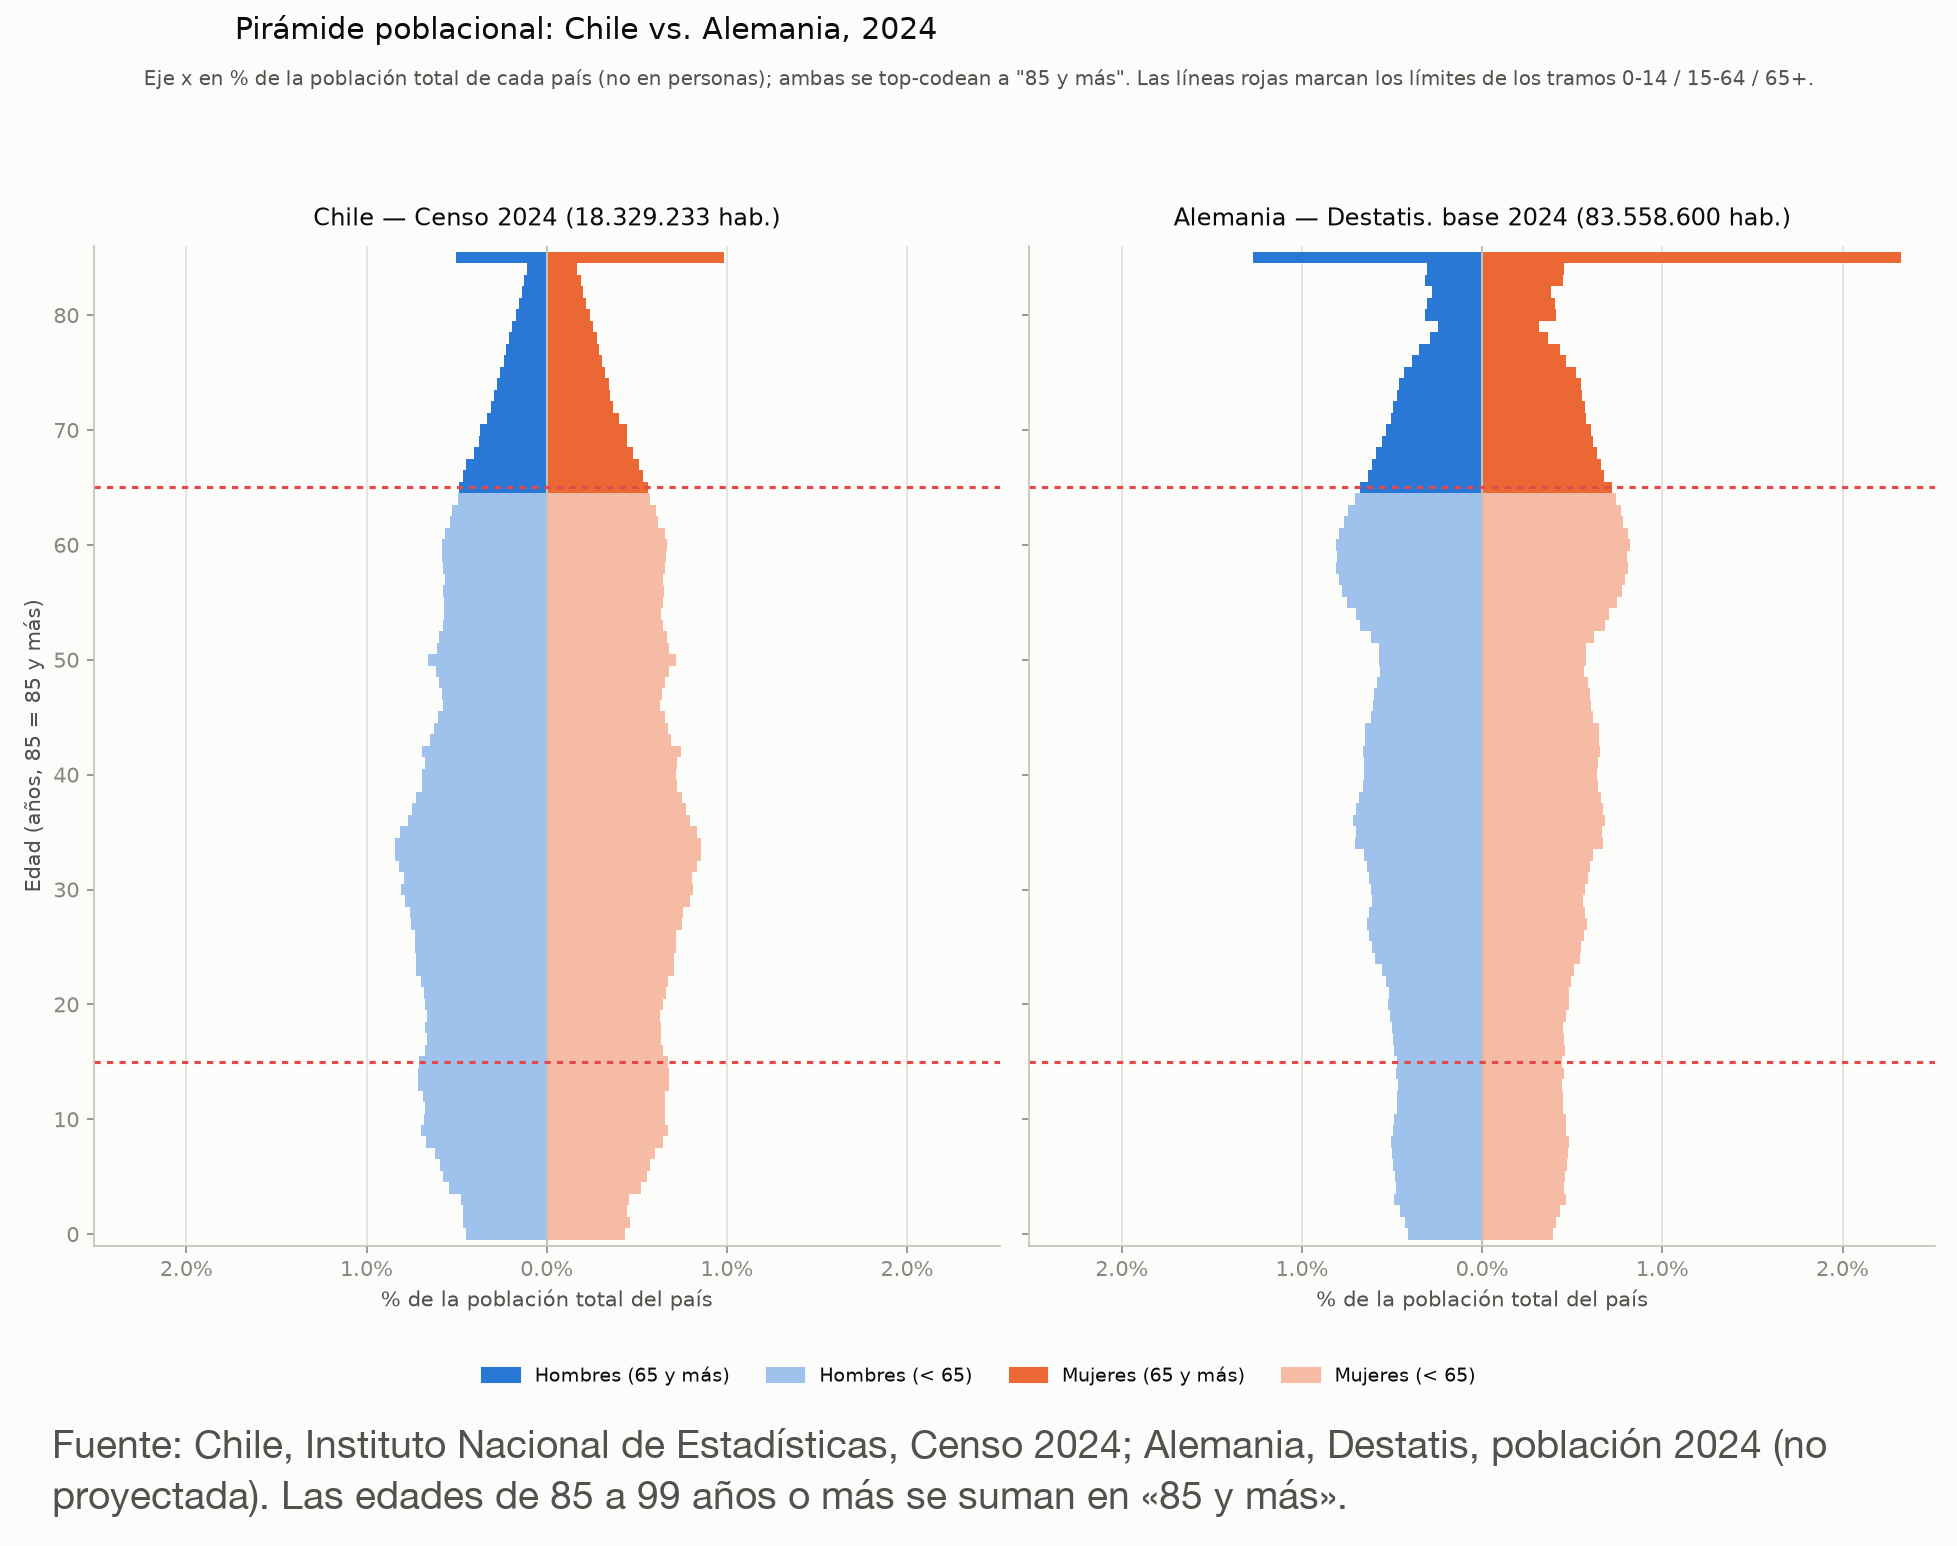

In [32]:
def piramide_chile_alemania():
    import io
    import sys
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mticker
    from pathlib import Path
    from PIL import Image


    DATA = ROOT / "Data processed"
    OUT_FIG = OUT
    OUT_FIG.mkdir(parents=True, exist_ok=True)

    # --- paleta de referencia (dataviz skill) -----------------------------------
    BLUE = "#2a78d6"
    ORANGE = "#eb6834"
    RED = "#e34948"
    INK_PRIMARY = "#0b0b0b"
    INK_SECONDARY = "#52514e"
    INK_MUTED = "#898781"
    GRIDLINE = "#e1e0d9"
    BASELINE = "#c3c2b7"
    SURFACE = "#fcfcfb"

    UMBRAL_VEJEZ = 65
    EDAD_TOPE = 85  # ambas piramides se top-codean a "85 y mas" para poder compararlas


    def lighten(hex_color: str, ratio: float = 0.55) -> str:
        hex_color = hex_color.lstrip("#")
        r, g, b = int(hex_color[0:2], 16), int(hex_color[2:4], 16), int(hex_color[4:6], 16)
        r2 = round(r + (255 - r) * ratio)
        g2 = round(g + (255 - g) * ratio)
        b2 = round(b + (255 - b) * ratio)
        return f"#{r2:02x}{g2:02x}{b2:02x}"


    BLUE_LIGHT = lighten(BLUE)
    ORANGE_LIGHT = lighten(ORANGE)

    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.size": 10,
        "text.color": INK_PRIMARY,
        "axes.edgecolor": BASELINE,
        "axes.labelcolor": INK_SECONDARY,
        "xtick.color": INK_MUTED,
        "ytick.color": INK_MUTED,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
    })


    def piramide_pct(h_edad: pd.Series, m_edad: pd.Series, tope: int = EDAD_TOPE):
        """Recibe series edad->poblacion (H y M) y devuelve (h_pct, m_pct) con
        edad top-codeada a `tope` y expresadas en % de la poblacion total del
        pais (H+M), para que ambos paneles sean comparables aunque Alemania
        tenga ~4,5 veces la poblacion de Chile."""
        h = h_edad.reindex(range(0, tope + 1), fill_value=0).copy()
        m = m_edad.reindex(range(0, tope + 1), fill_value=0).copy()
        if h_edad.index.max() > tope:
            h.loc[tope] += h_edad[h_edad.index > tope].sum()
        if m_edad.index.max() > tope:
            m.loc[tope] += m_edad[m_edad.index > tope].sum()
        total = h.sum() + m.sum()
        return h / total * 100, m / total * 100, int(total)


    # =============================================================================
    # Datos: Censo 2024 (Chile) vs Basisjahr 2024 Destatis (Alemania)
    # =============================================================================
    censo_pais = pd.read_csv(DATA / "censo_pais_edad_simple.csv")
    alemania = pd.read_csv(DATA / "alemania_piramide_edad_simple_2024.csv")

    h_cl_raw = censo_pais[censo_pais.sexo == 1].set_index("edad")["poblacion"]
    m_cl_raw = censo_pais[censo_pais.sexo == 2].set_index("edad")["poblacion"]
    h_cl, m_cl, total_cl = piramide_pct(h_cl_raw, m_cl_raw)

    h_de_raw = alemania[alemania.sexo == "H"].set_index("edad")["poblacion"]
    m_de_raw = alemania[alemania.sexo == "M"].set_index("edad")["poblacion"]
    h_de, m_de, total_de = piramide_pct(h_de_raw, m_de_raw)

    xmax = max(h_cl.max(), m_cl.max(), h_de.max(), m_de.max()) * 1.08

    # =============================================================================
    # Indicadores por tramo de edad (0-14 / 15-64 / 65+), para las dos piramides
    # =============================================================================
    UMBRAL_NINEZ = 15  # limite inferior del tramo 15-64 (frontera con 0-14)


    def indicadores_tramo(h_edad: pd.Series, m_edad: pd.Series):
        total = h_edad.sum() + m_edad.sum()
        pob = h_edad.add(m_edad, fill_value=0)
        pob_0_14 = pob[pob.index <= UMBRAL_NINEZ - 1].sum()
        pob_15_64 = pob[(pob.index >= UMBRAL_NINEZ) & (pob.index <= UMBRAL_VEJEZ - 1)].sum()
        pob_65_mas = pob[pob.index >= UMBRAL_VEJEZ].sum()
        return {
            "pct_0_14": 100 * pob_0_14 / total,
            "pct_15_64": 100 * pob_15_64 / total,
            "pct_65_mas": 100 * pob_65_mas / total,
        }


    ind_cl = indicadores_tramo(h_cl_raw, m_cl_raw)
    ind_de = indicadores_tramo(h_de_raw, m_de_raw)

    for nombre, ind in (("Chile", ind_cl), ("Alemania", ind_de)):
        print(f"{nombre}: 0-14 = {ind['pct_0_14']:.2f}% | 15-64 = {ind['pct_15_64']:.2f}% | "
              f"65+ = {ind['pct_65_mas']:.2f}%")


    # =============================================================================
    # Grafico: dos paneles lado a lado, mismo estilo, con las lineas de umbral
    # que se pidan (65 anios siempre; opcionalmente tambien 15 anios)
    # =============================================================================
    # Lienzo fijo de 1957 × 1546 px (el tamaño que tenía la imagen), con el fondo reservado para el pie de fuente. Se inserta a 5,5 pulgadas de
    # alto (como las demás figuras de la diapositiva): de ahí el tamaño de la letra del pie (≈ 10 pt, igual que la Fig. 1.2.4).
    W_PX, H_PX, DPI = 1957, 1546, 150
    CSS_W = pie_fuente.css_ancho(5.5 * W_PX / H_PX)
    FUENTE = ("Fuente: Chile, Instituto Nacional de Estadísticas, Censo 2024; Alemania, Destatis, población 2024 (no proyectada). "
              "Las edades de 85 a 99 años o más se suman en «85 y más».")


    def graficar(umbrales: list[int], out_name: str, nota_umbral: str):
        fig, axes = plt.subplots(1, 2, figsize=((W_PX + 0.5) / DPI, (H_PX + 0.5) / DPI), sharey=True)
        banda = pie_fuente.banda_px(W_PX, CSS_W) / H_PX  # fracción del alto reservada al pie de fuente

        paneles = [
            (axes[0], h_cl, m_cl, f"Chile — Censo 2024 ({total_cl:,} hab.)".replace(",", ".")),
            (axes[1], h_de, m_de, f"Alemania — Destatis, base 2024 ({total_de:,} hab.)".replace(",", ".")),
        ]

        for ax, h, m, titulo in paneles:
            ages = h.index
            h_colors = [BLUE_LIGHT if edad < UMBRAL_VEJEZ else BLUE for edad in ages]
            m_colors = [ORANGE_LIGHT if edad < UMBRAL_VEJEZ else ORANGE for edad in ages]
            ax.barh(ages, -h.values, height=1.0, color=h_colors, linewidth=0)
            ax.barh(ages, m.values, height=1.0, color=m_colors, linewidth=0)
            ax.axvline(0, color=BASELINE, linewidth=1)
            for y in umbrales:
                ax.axhline(y, color=RED, linewidth=1.5, linestyle=(0, (2, 2)))
            ax.set_xlim(-xmax, xmax)
            ax.set_ylim(-1, EDAD_TOPE + 1)
            ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{abs(x):.1f}%"))
            ax.set_title(titulo, fontsize=11.5, color=INK_PRIMARY, pad=10)
            ax.grid(axis="x", color=GRIDLINE, linewidth=0.8, zorder=0)
            ax.set_axisbelow(True)
            for spine in ("top", "right"):
                ax.spines[spine].set_visible(False)
            ax.spines["left"].set_color(BASELINE)
            ax.spines["bottom"].set_color(BASELINE)

        axes[0].set_ylabel("Edad (años, 85 = 85 y más)")
        axes[0].set_xlabel("% de la población total del país")
        axes[1].set_xlabel("% de la población total del país")

        handles = [
            plt.Rectangle((0, 0), 1, 1, color=BLUE, label="Hombres (65 y más)"),
            plt.Rectangle((0, 0), 1, 1, color=BLUE_LIGHT, label="Hombres (< 65)"),
            plt.Rectangle((0, 0), 1, 1, color=ORANGE, label="Mujeres (65 y más)"),
            plt.Rectangle((0, 0), 1, 1, color=ORANGE_LIGHT, label="Mujeres (< 65)"),
        ]
        fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, banda), fontsize=9)

        fig.suptitle("Pirámide poblacional: Chile vs. Alemania, 2024", fontsize=14.5, color=INK_PRIMARY,
                     x=0.12, y=0.99, ha="left")
        fig.text(
            0.5, 0.955,
            "Eje x en % de la población total de cada país (no en personas); ambas se top-codean a \"85 y más\". "
            + nota_umbral,
            fontsize=9.5, color=INK_SECONDARY, ha="center", va="top",
        )
        fig.tight_layout(rect=[0, banda + 0.045, 1, 0.915])
        out_path = OUT_FIG / out_name
        buf = io.BytesIO()
        fig.savefig(buf, dpi=DPI, format="png")
        plt.close(fig)
        img = Image.open(buf).convert("RGB")
        assert img.size == (W_PX, H_PX)
        n = pie_fuente.add_source_footer(img, FUENTE, css_width=CSS_W)
        assert n <= pie_fuente.MAX_LINEAS, f"el pie ocupa {n} líneas"
        img.save(out_path, dpi=(DPI, DPI))
        print("Grafico guardado en:", out_path)


    graficar([UMBRAL_VEJEZ], "05_piramide_chile_alemania_2024.png",
             "La línea roja marca el umbral de 65 años.")
    graficar([UMBRAL_NINEZ, UMBRAL_VEJEZ], "06_piramide_chile_alemania_2024_tramos_edad.png",
             "Las líneas rojas marcan los límites de los tramos 0-14 / 15-64 / 65+.")

    print(f"Chile: {total_cl:,} hab. | Alemania: {total_de:,} hab.".replace(",", "."))


piramide_chile_alemania()

def mostrar_imagen(ruta, ancho=1000):
    """Muestra en el cuaderno un PNG que una función de arriba guardó en disco."""
    try:
        from IPython.display import Image, display
        display(Image(filename=str(ruta), width=ancho))
    except ImportError:
        print("PNG guardado en", ruta)

mostrar_imagen(OUT / "06_piramide_chile_alemania_2024_tramos_edad.png")

### Diapositiva 7: % de personas de 65+ (1992-2070) y máximo de la población de 15 a 64 años en 2034

P.3      slide      → Outputs/figuras_notebook/P.3__envejecimiento__slide.png  (4680×4320 px)
P.4      slide      → Outputs/figuras_notebook/P.4__pico__slide.png  (4680×4320 px)


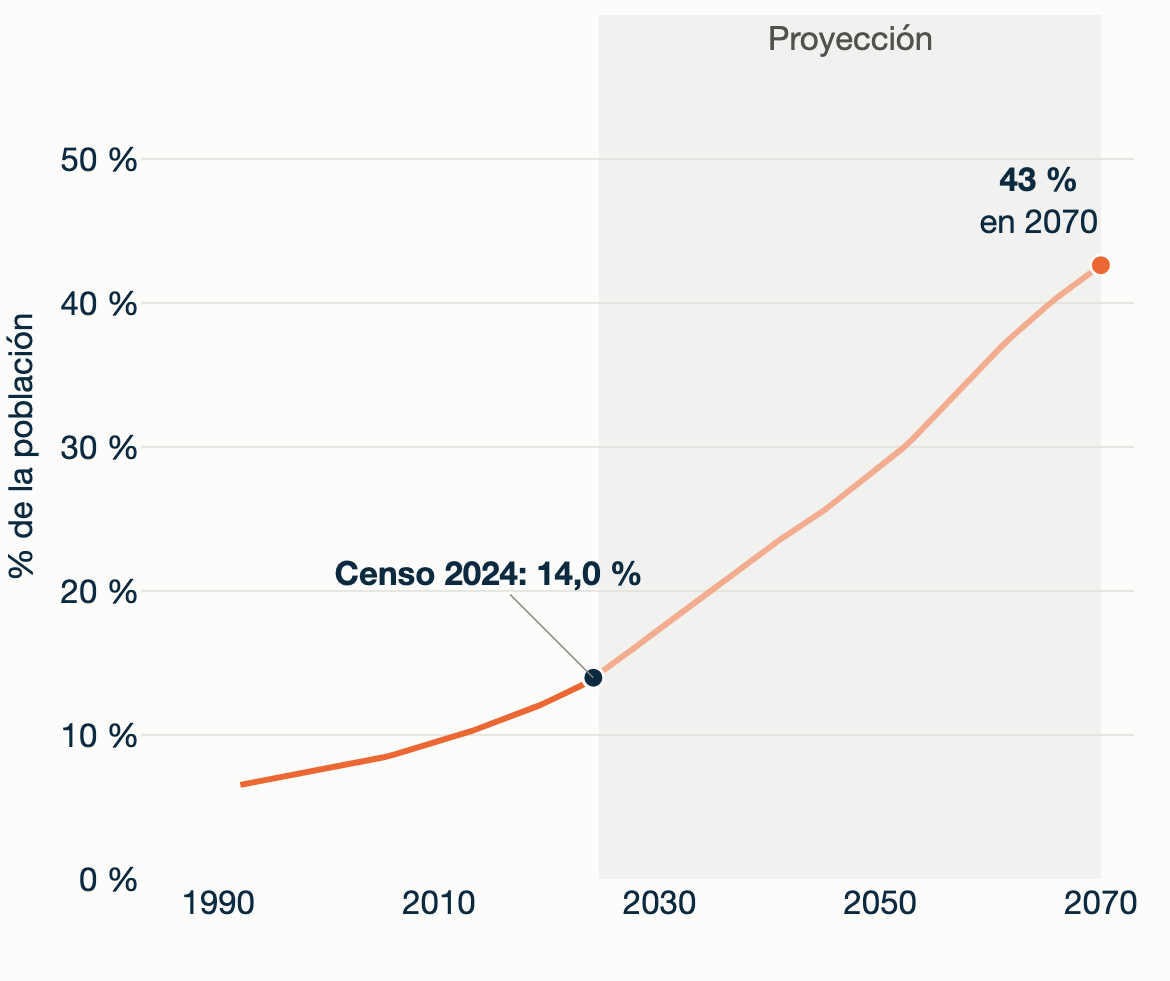

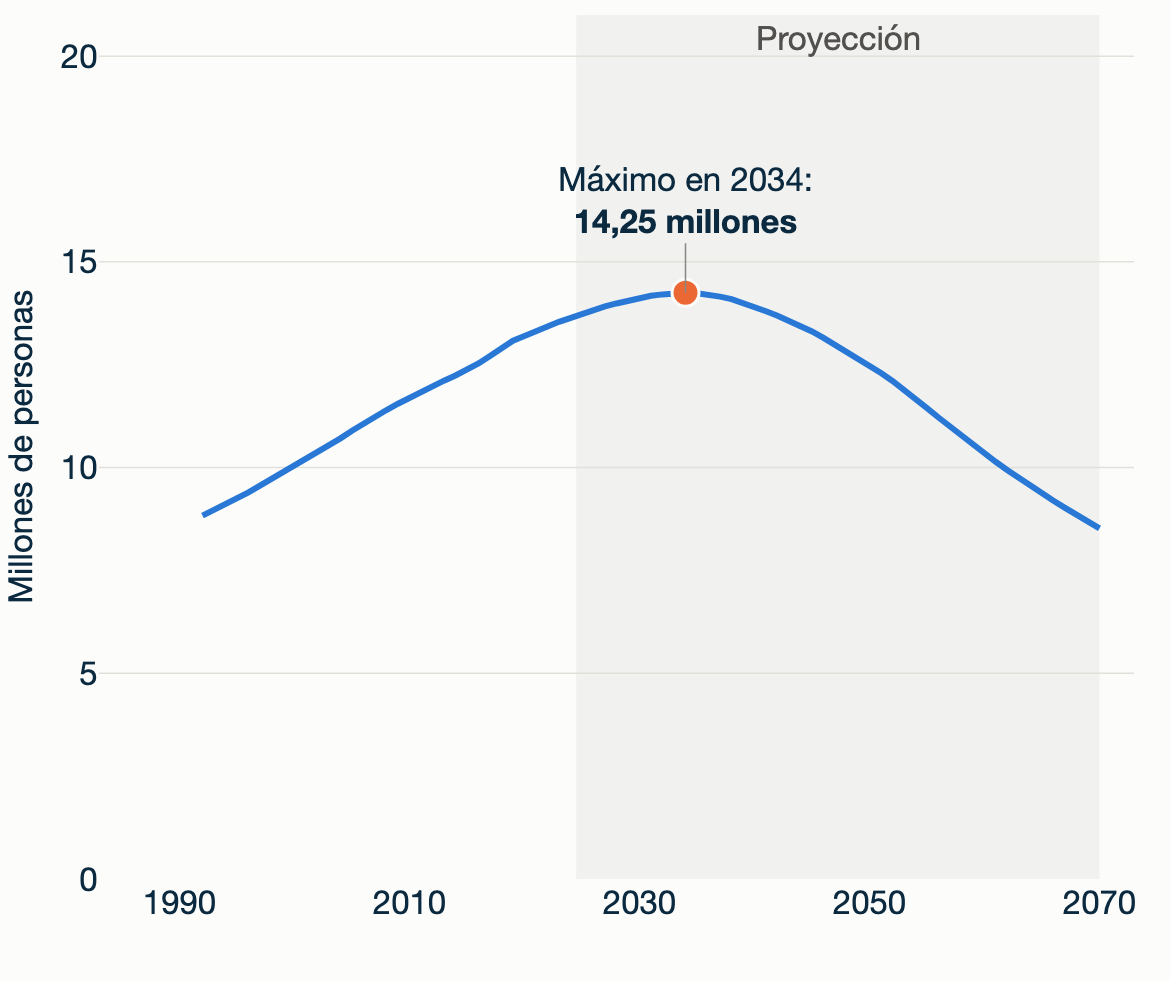

In [33]:
generar("P.3")
generar("P.4")

### Diapositiva 8: cotizantes por persona de 65+, 2010-2070

1.2.4    slide      → Outputs/figuras_notebook/1.2.4__cotizantes_por_persona_mayor__slide.png  (4800×2160 px)


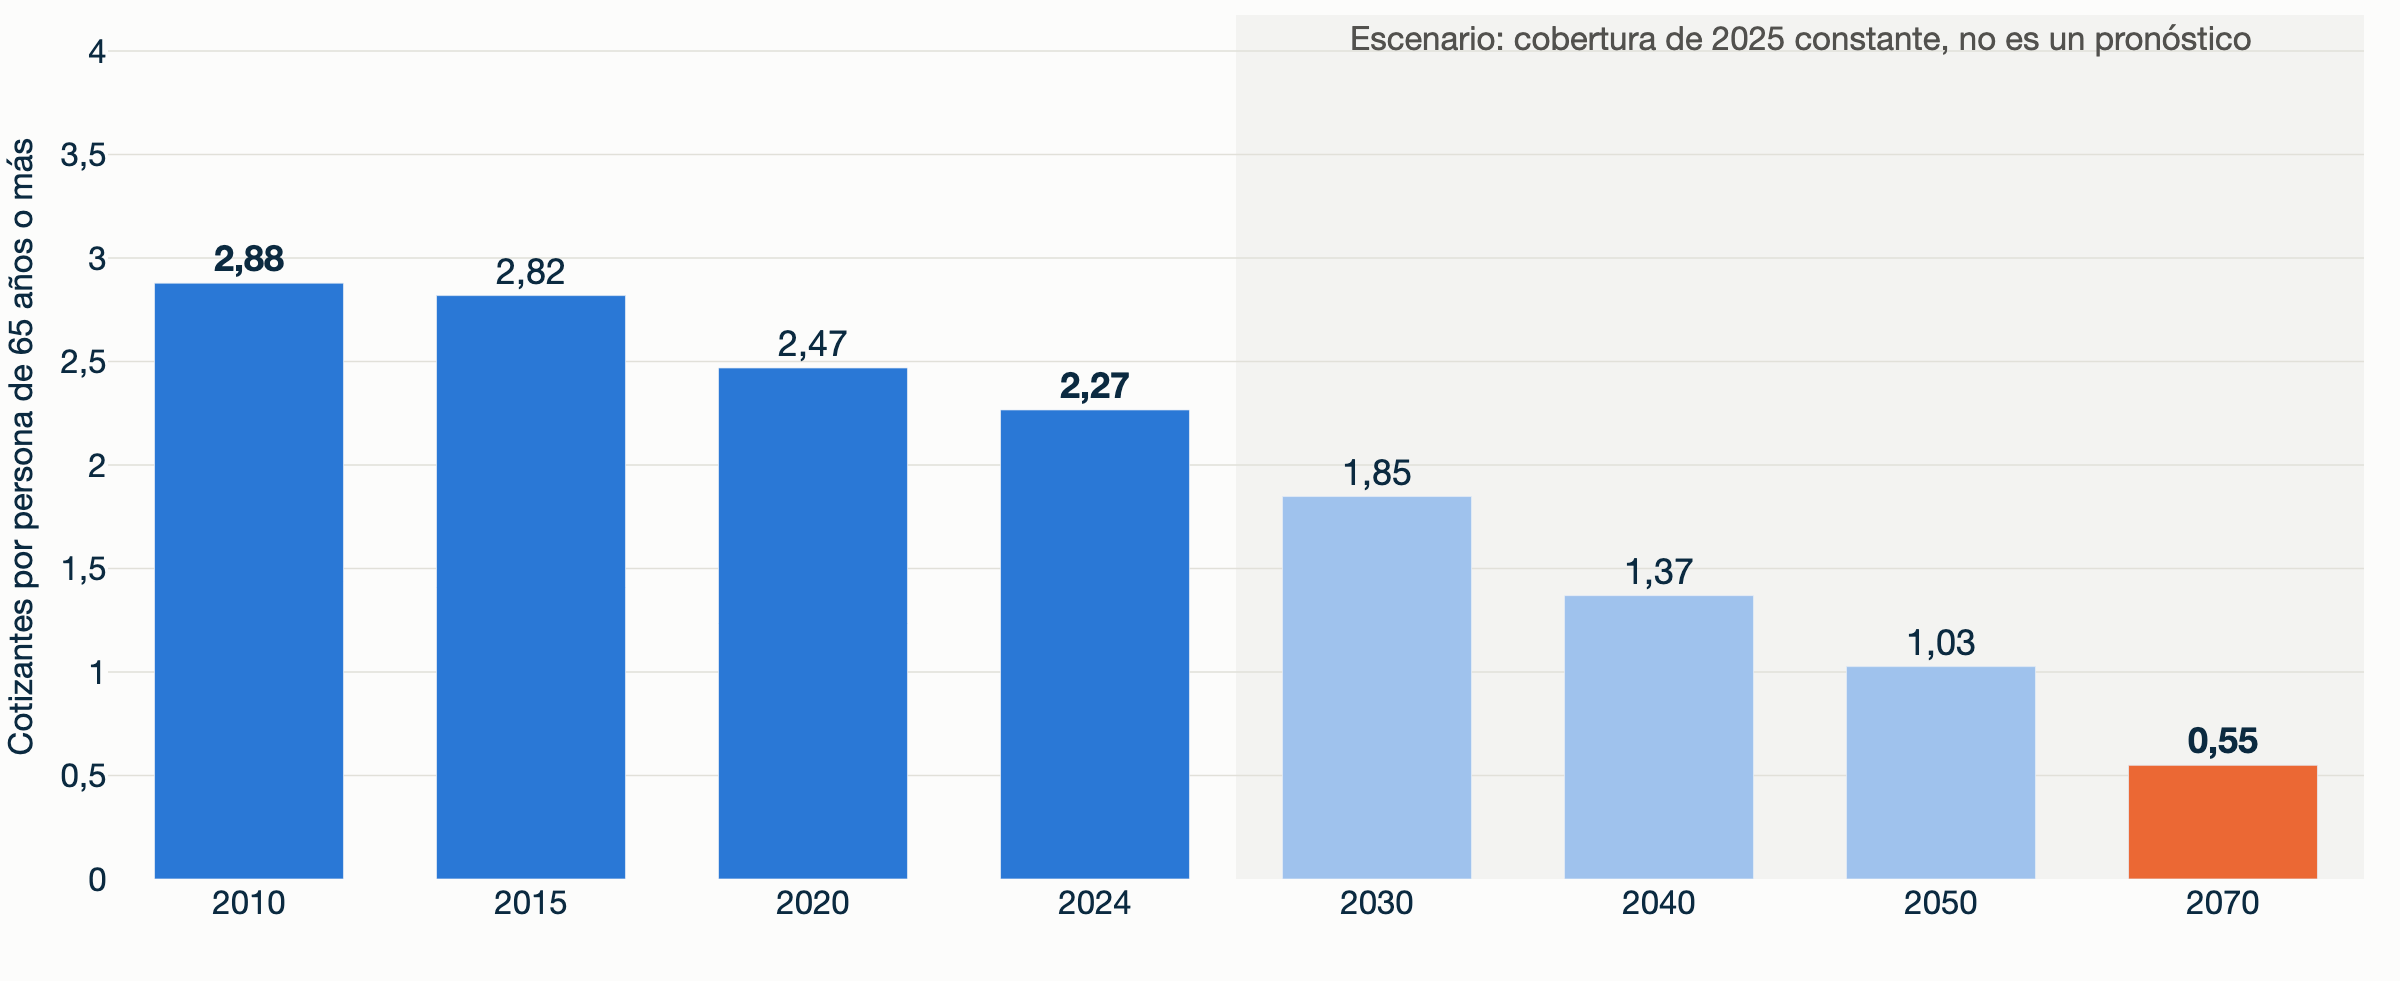

In [34]:
generar("1.2.4")

### Diapositiva 9: costo del Pilar Solidario frente a la capacidad (10 % del sueldo); punto crítico 2038

1.2.7    slide      → Outputs/figuras_notebook/1.2.7__punto_critico_dinero__slide.png  (4800×2160 px)


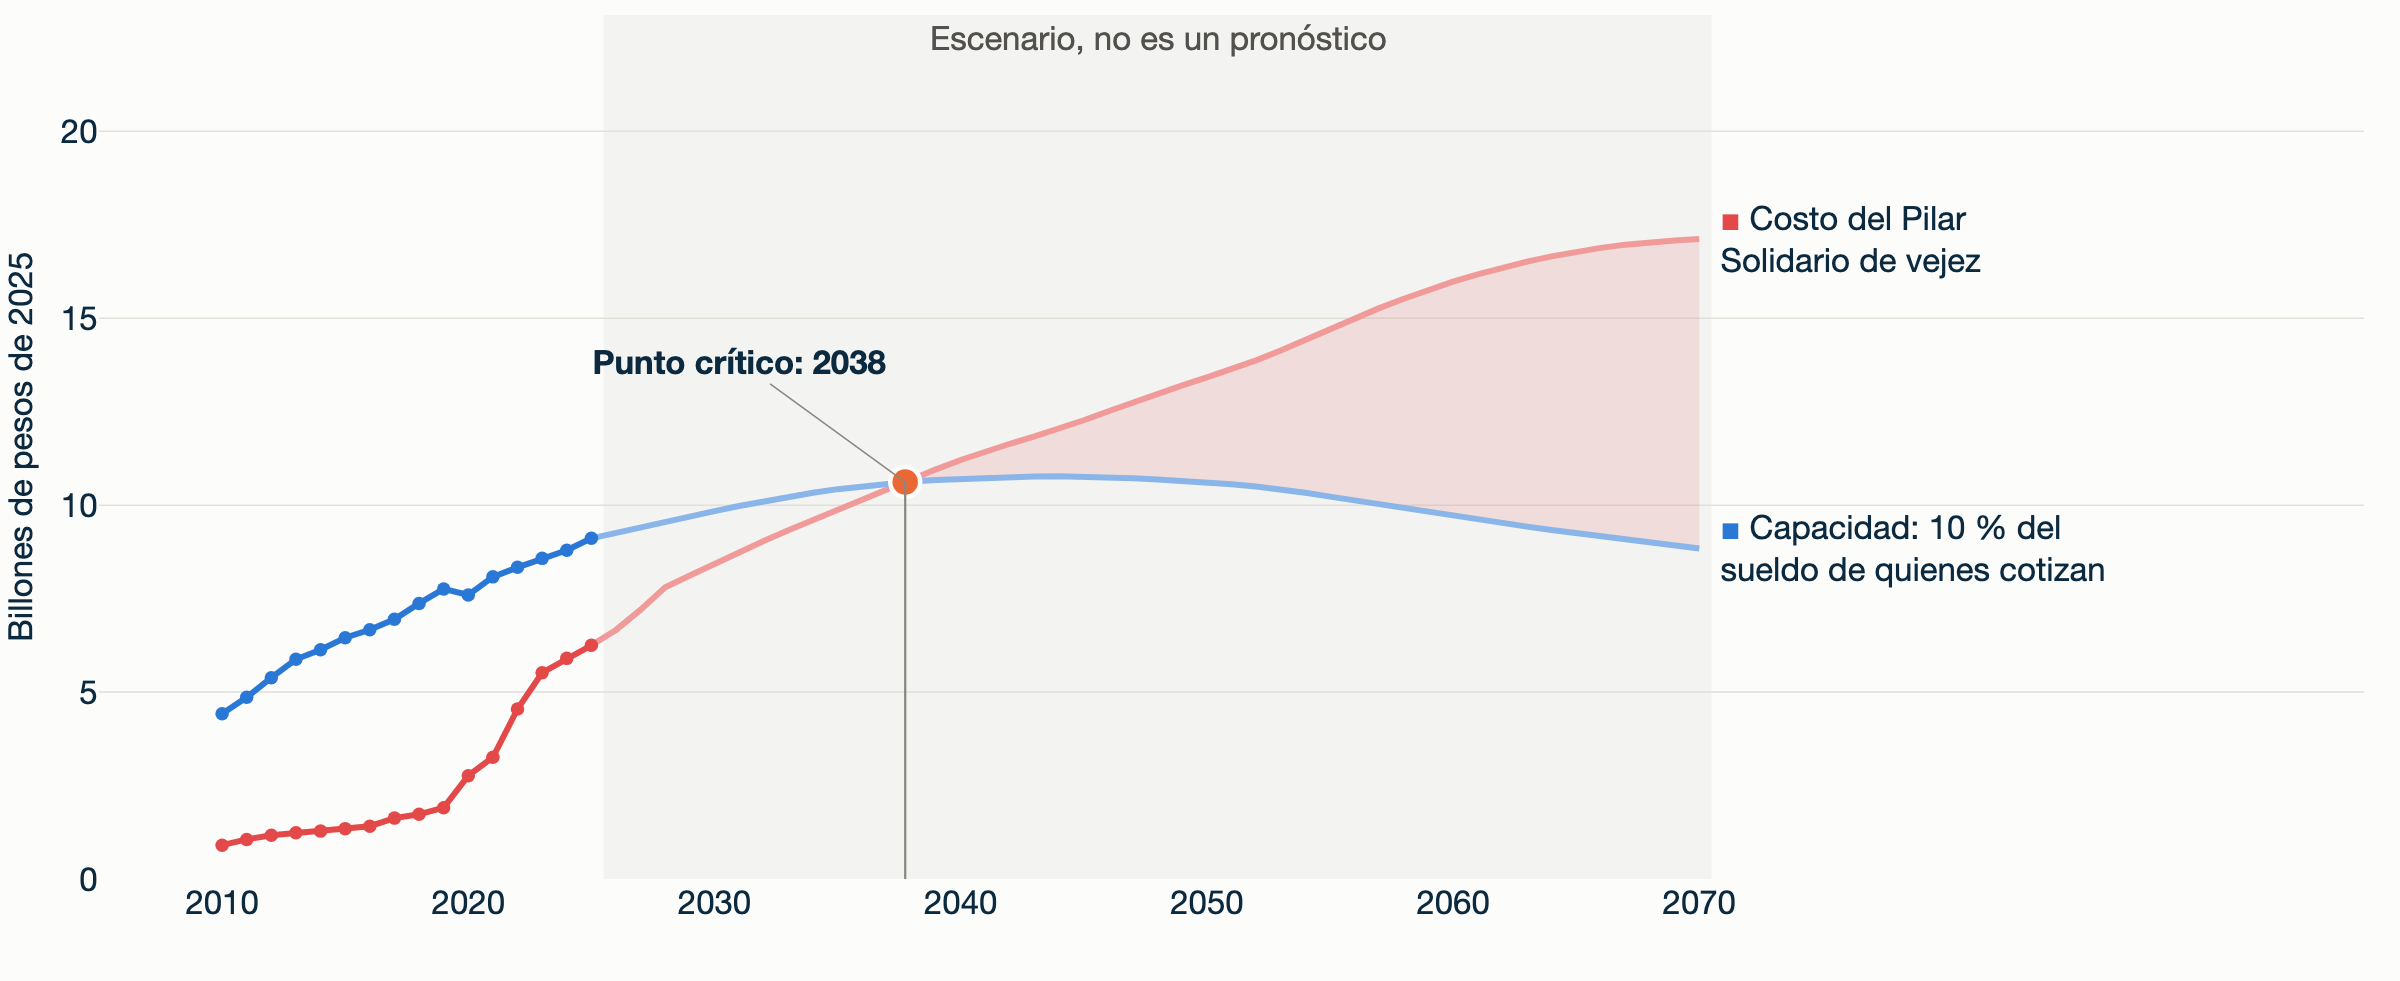

In [35]:
generar("1.2.7")

### Diapositiva 10: cobertura previsional por región, 2024 (mapa y ranking de las 16 regiones)

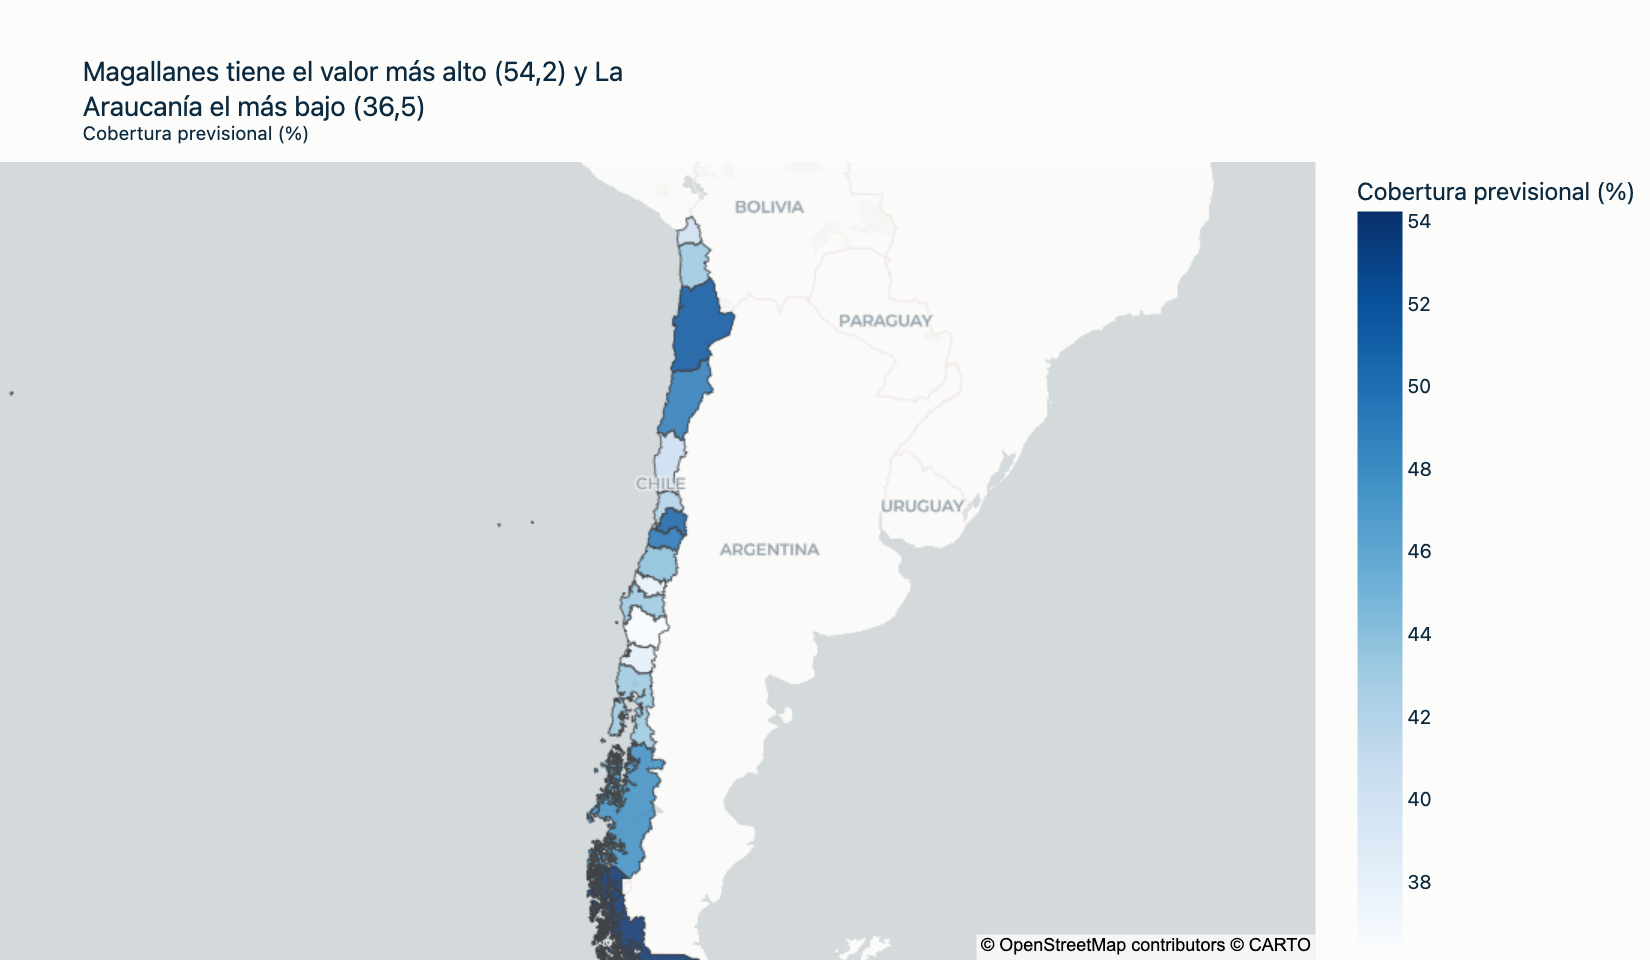

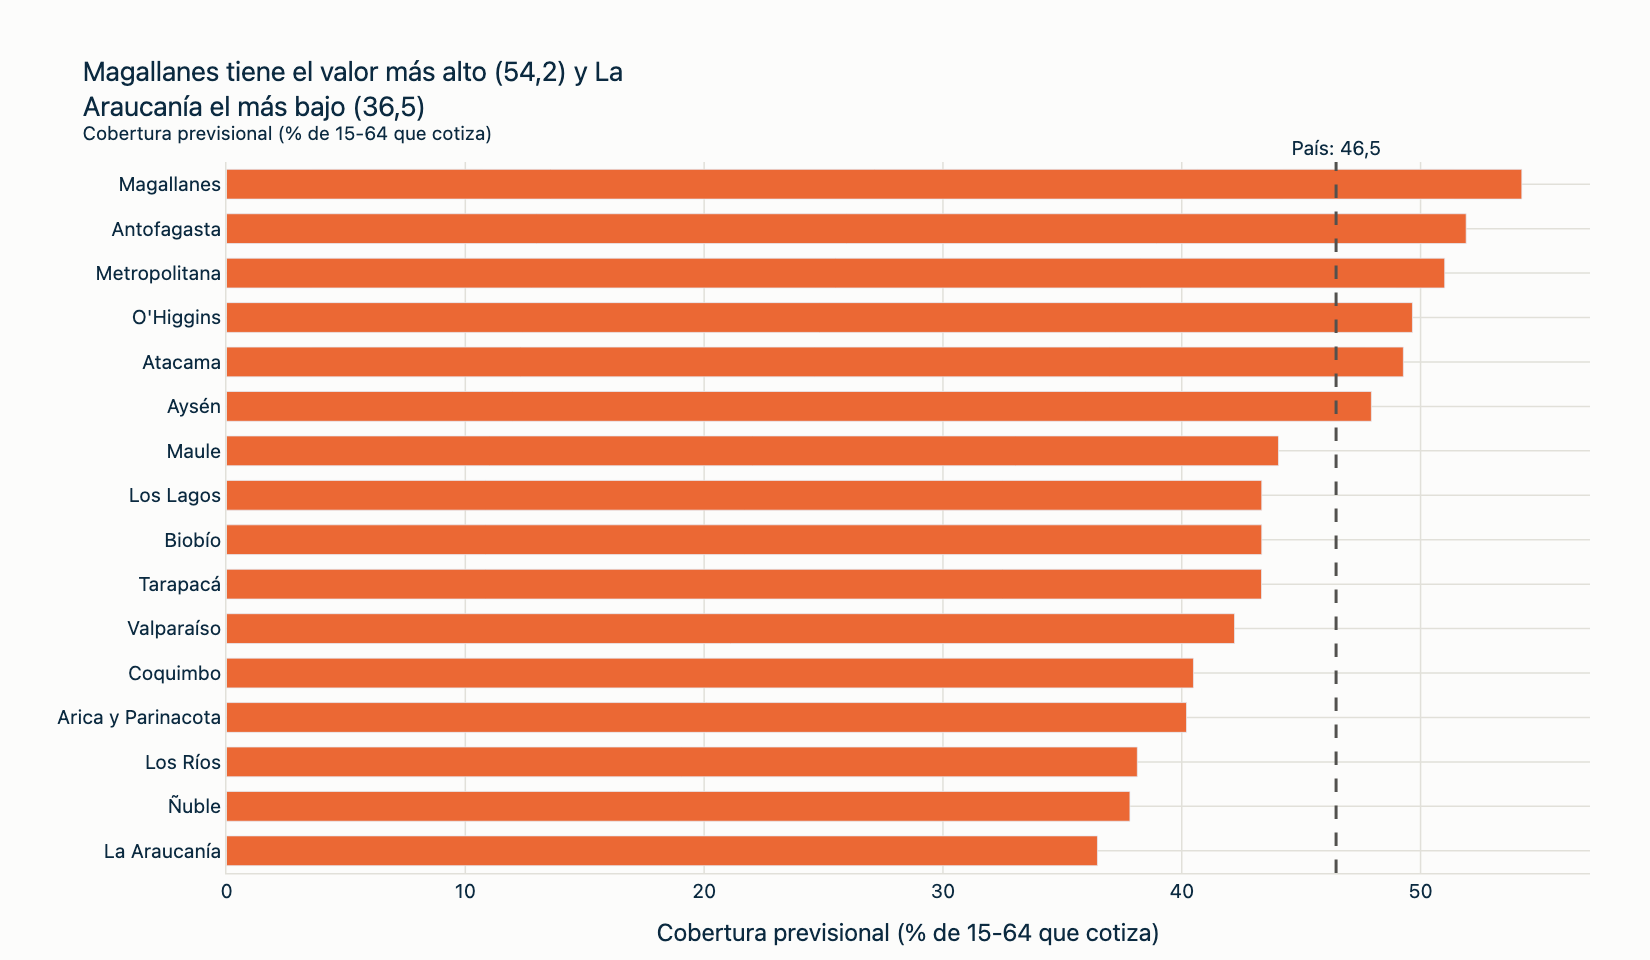

In [36]:
for clave in ("1.1/mapa", "1.1/barras_region"):
    fig_de(ctx, clave).show()

### Diapositiva 18: cobertura 2002-2024 de la región más alta, Chile y la más baja

1.1.16   slide      → Outputs/figuras_notebook/1.1.16__cobertura_2002_2024_tres_lineas__slide.png  (4800×2160 px)


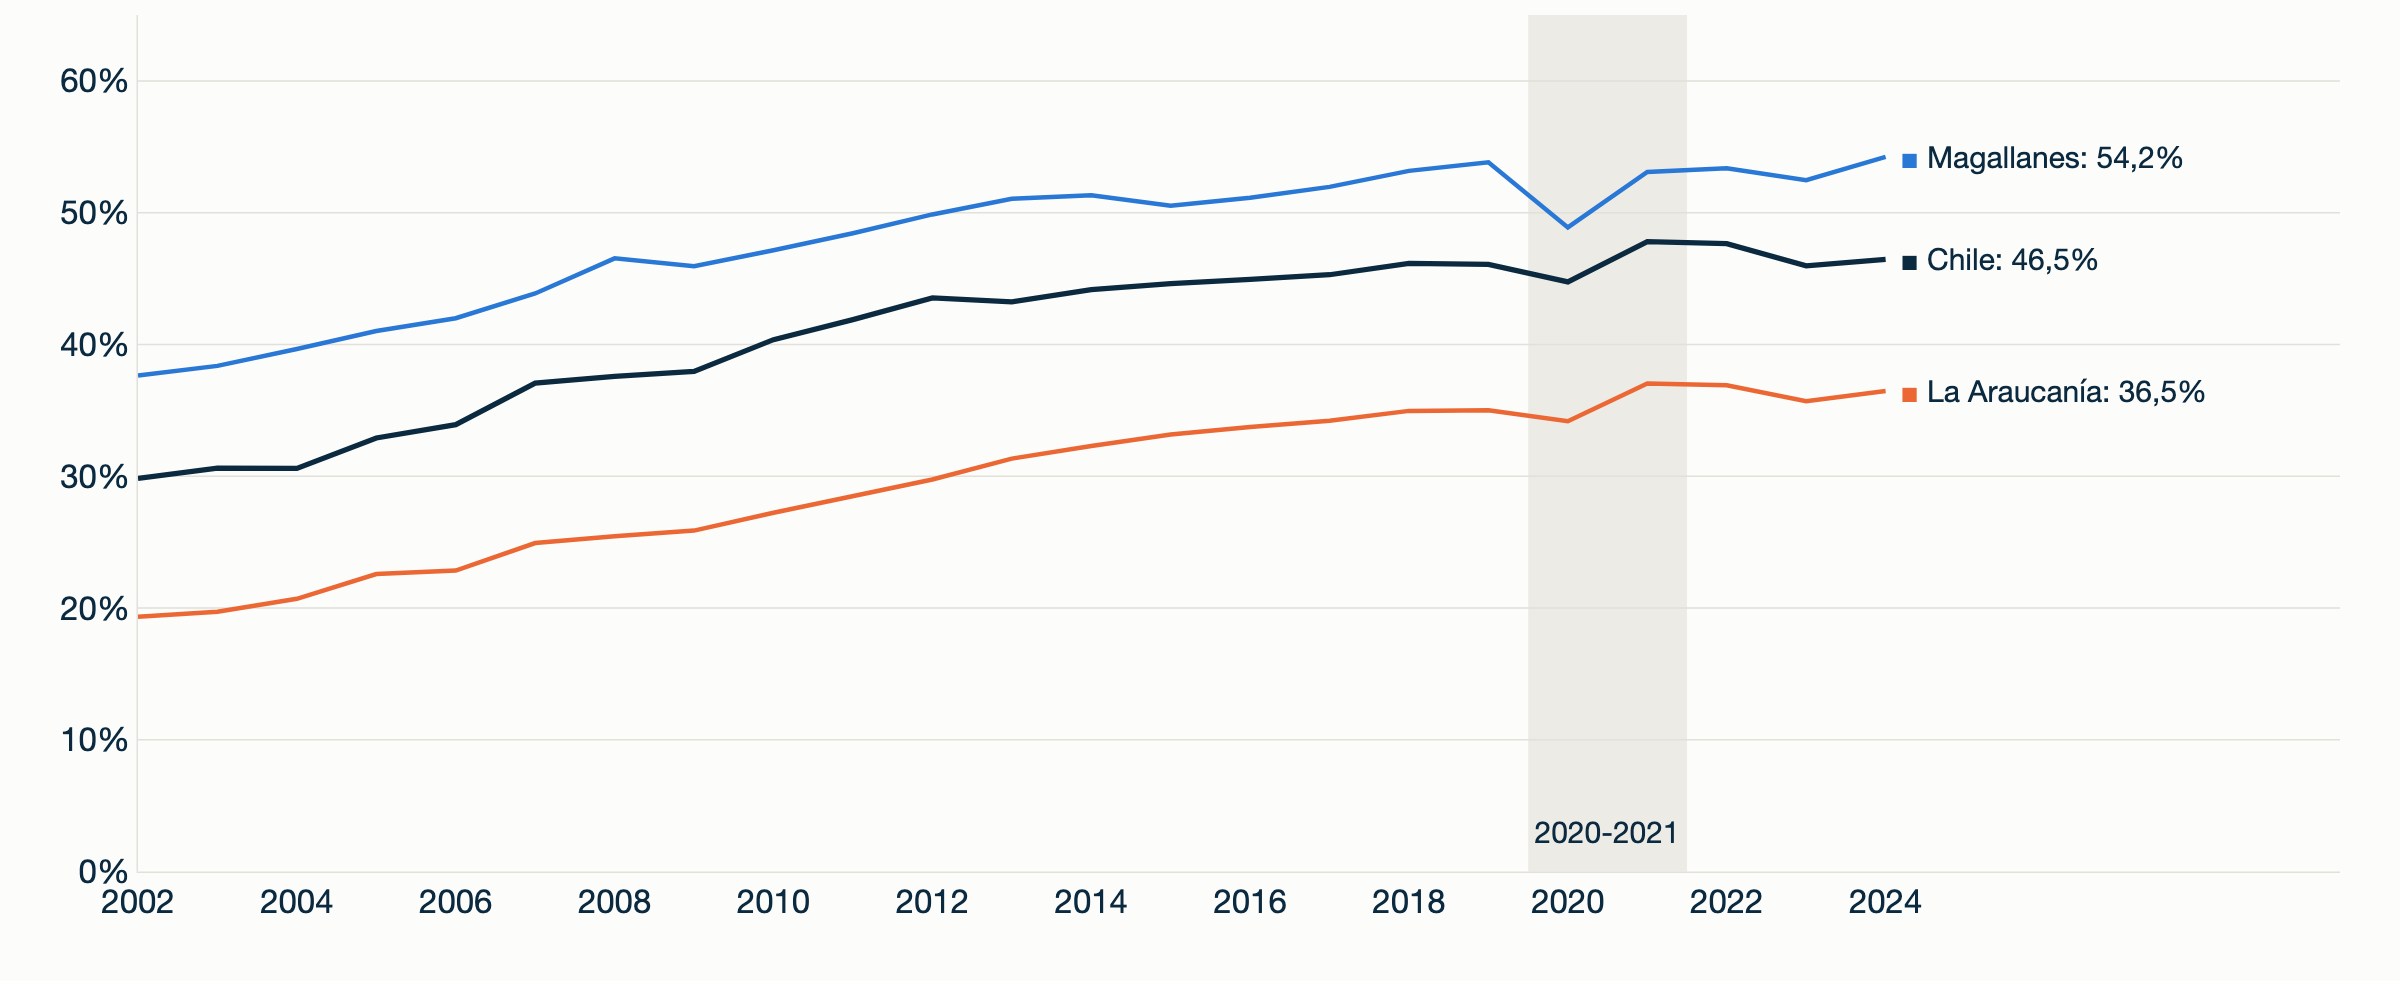

In [37]:
generar("1.1.16")

### Diapositiva 19: cobertura 2007-2024 de Chile y de las tres regiones que menos avanzaron

N.5b-v2  slide      → Outputs/figuras_notebook/N.5b-v2__cobertura_chile_v2__slide.png  (4800×2160 px)


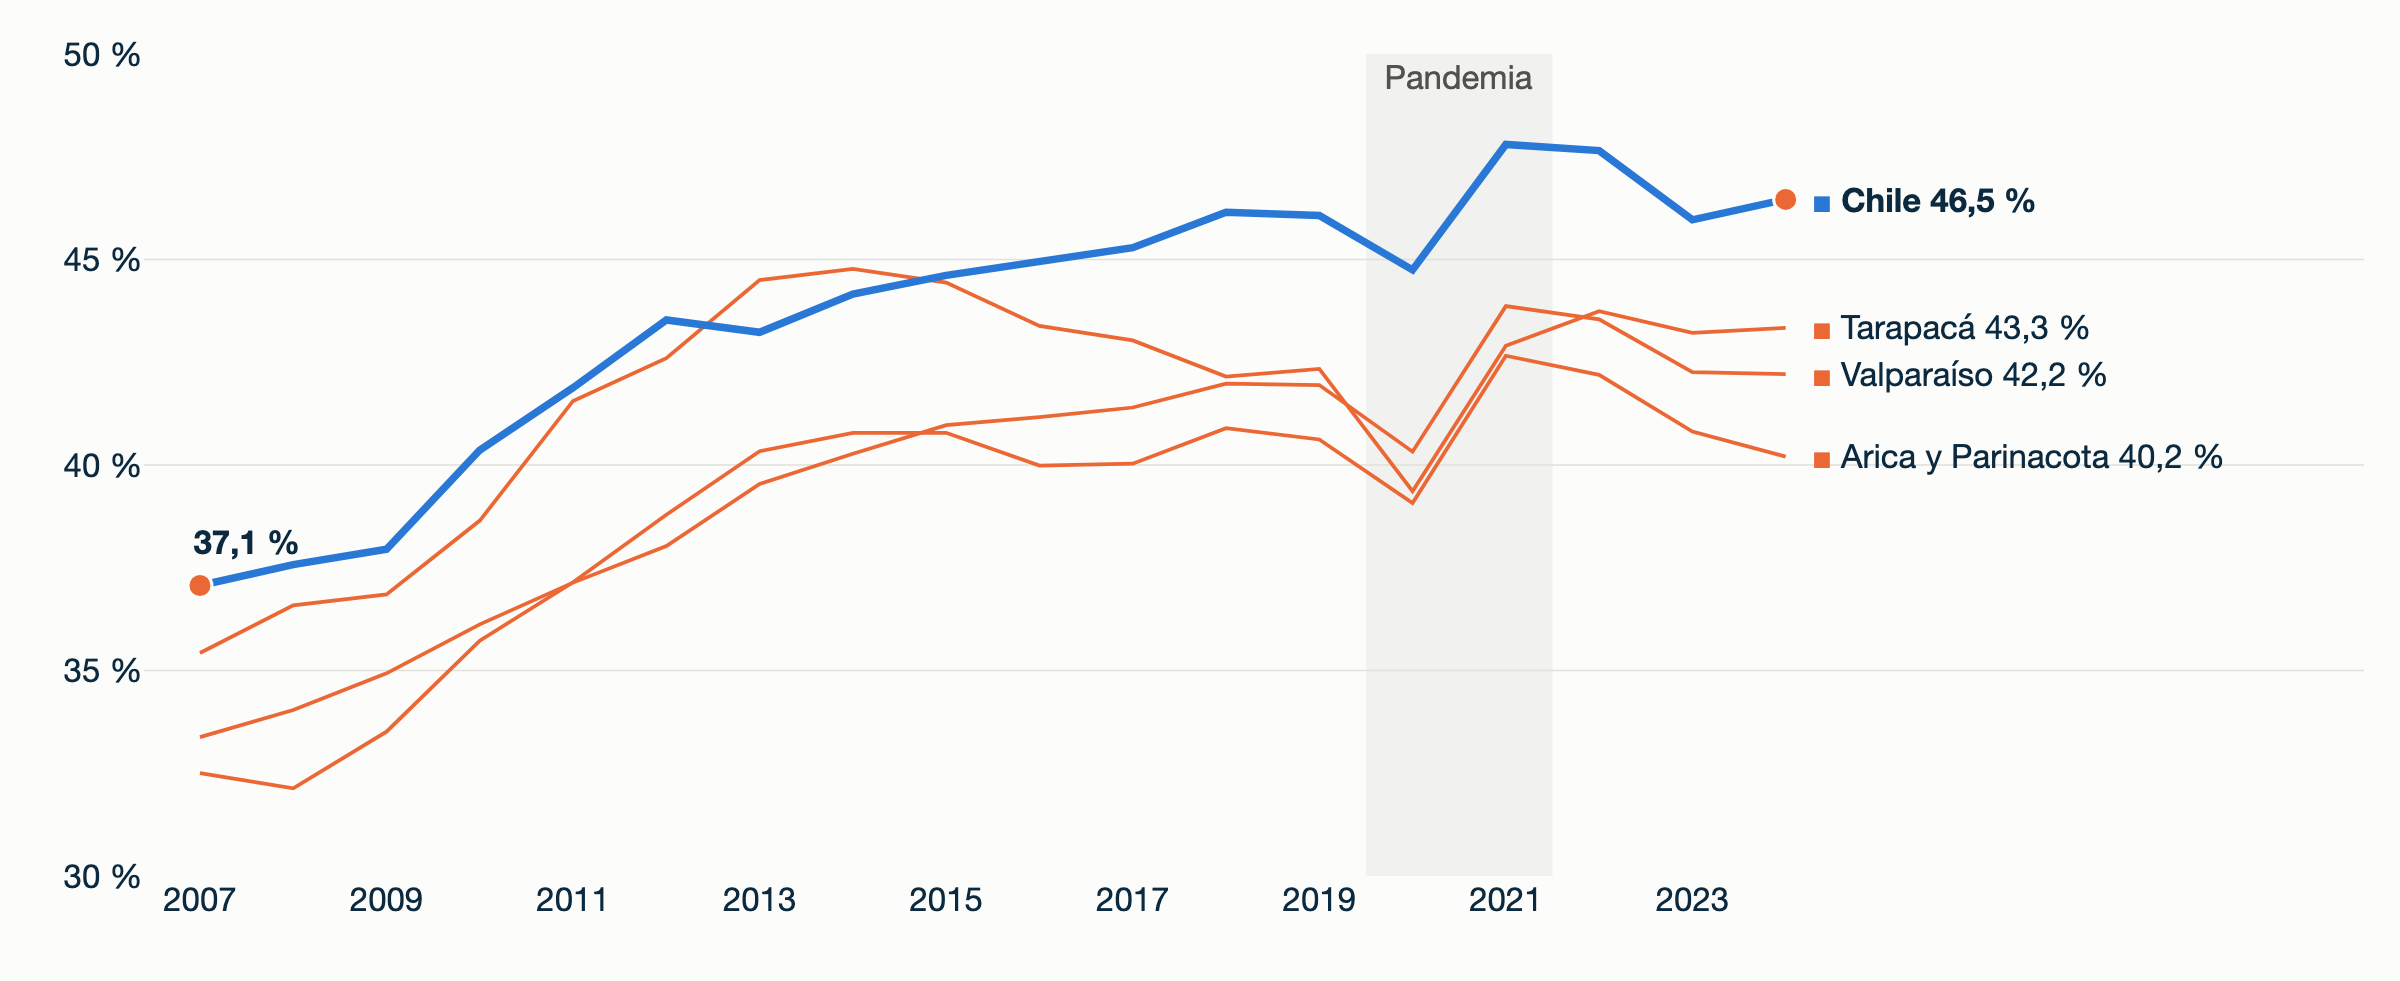

In [38]:
generar("N.5b-v2")

### Diapositivas 19 y 20: tabla de cambio 2007-2024 con cambio de puestos (`Scripts/36_tabla_cambio_regiones_calibri.py`; necesita la letra Calibri de Microsoft Office)

Outputs/figuras_notebook/N.5e-v2__tabla_16_regiones_calibri__slide.png  4680×5448 px


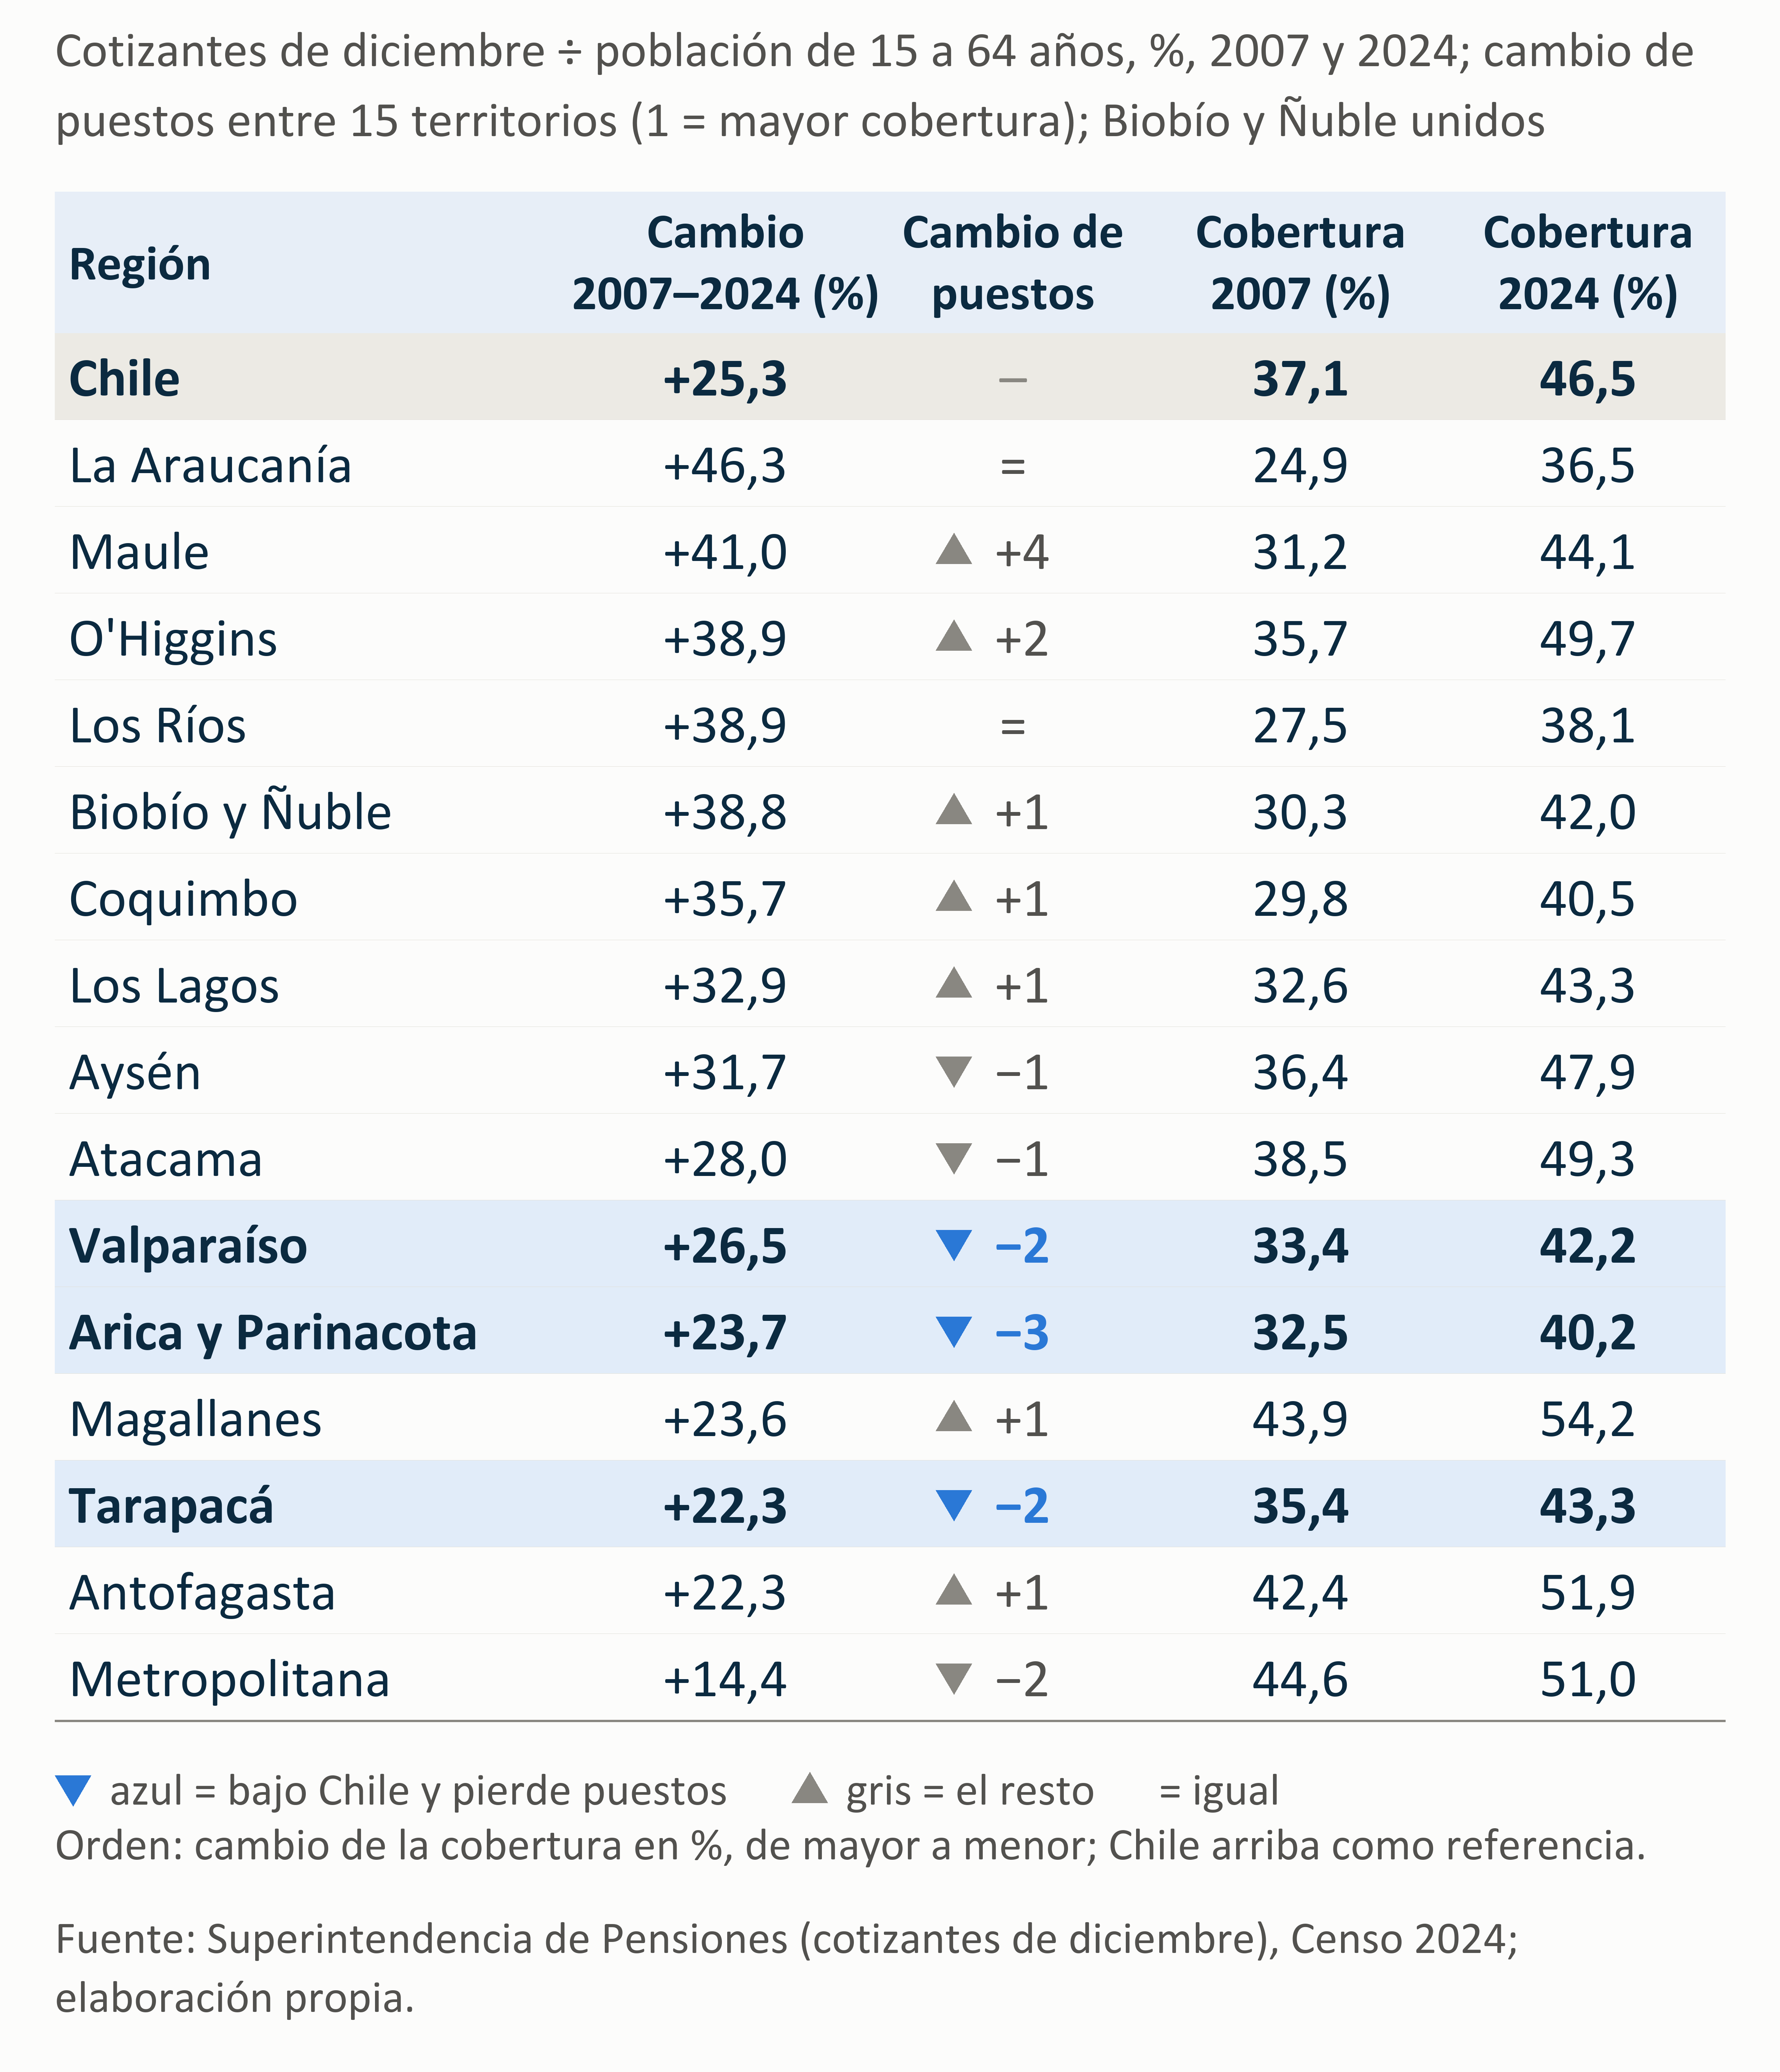

In [39]:
def tabla_cambio_regiones():
    import sys
    from pathlib import Path

    import pandas as pd
    from PIL import Image, ImageDraw, ImageFont

    DIRS_FUENTE = [Path("/Applications/Microsoft PowerPoint.app/Contents/Resources/DFonts"),
                   Path("/Applications/Microsoft OneNote.app/Contents/Resources/DFonts"),
                   Path("/Applications/Microsoft Word.app/Contents/Resources/DFonts")]
    SALIDA = OUT / "N.5e-v2__tabla_16_regiones_calibri__slide.png"
    S = 6                       # escala: 780 px × 6 = 4680 px de ancho
    W = 780                     # ancho de la diapositiva (px CSS)
    PAD = 24
    GRIS_CHILE = "#eceae4"


    def fuente(nombre: str, tam: float) -> ImageFont.FreeTypeFont:
        for d in DIRS_FUENTE:
            if (d / nombre).exists():
                return ImageFont.truetype(str(d / nombre), round(tam * S))
        raise FileNotFoundError(f"No se encontró {nombre} en {[str(d) for d in DIRS_FUENTE]}")


    def cl(v: float, d: int = 1, signo: bool = False) -> str:
        """Número con formato es-CL (coma decimal, signo menos tipográfico)."""
        s = f"{abs(v):.{d}f}".replace(".", ",")
        if v < 0 and float(s.replace(",", ".")) != 0:
            return "−" + s
        return ("+" + s) if signo and v > 0 else s


    def partir(texto: str, f, ancho: float) -> list:
        lineas, actual = [], ""
        for p in texto.split():
            prueba = (actual + " " + p).strip()
            if f.getlength(prueba) <= ancho * S:
                actual = prueba
            else:
                lineas.append(actual)
                actual = p
        return lineas + ([actual] if actual else [])


    def main() -> None:
        d = pd.read_csv(ROOT / "Data processed" / "kpi_seleccion_dos_preguntas.csv")
        ch = d[d.section == "chile"].iloc[0]
        rk = d[d.section == "ranking"].sort_values("change_pct", ascending=False).reset_index(drop=True)
        assert len(rk) == 15, "se esperaban 15 territorios (16 regiones, Biobío y Ñuble unidos)"
        pierden = set(rk[rk.below_chile.astype(bool) & rk.by_trend.astype(bool)]["name"])
        assert pierden == {"Valparaíso", "Tarapacá", "Arica y Parinacota"}, pierden

        f_txt, f_neg = fuente("Calibri.ttf", 24), fuente("Calibrib.ttf", 24)
        f_cab, f_sub, f_nota = fuente("Calibrib.ttf", 22), fuente("Calibri.ttf", 22), fuente("Calibri.ttf", 20)

        sub = ("Cotizantes de diciembre ÷ población de 15 a 64 años, %, 2007 y 2024; cambio de puestos entre 15 territorios "
               "(1 = mayor cobertura); Biobío y Ñuble unidos")
        lineas_sub = partir(sub, f_sub, W - 2 * PAD)
        fuente_txt = "Fuente: Superintendencia de Pensiones (cotizantes de diciembre), Censo 2024; elaboración propia."
        lineas_fte = partir(fuente_txt, f_nota, W - 2 * PAD)

        y_sub, lh_sub = 14, 28
        y_cab = y_sub + len(lineas_sub) * lh_sub + 14
        h_cab, fila = 62, 38
        y_ini = y_cab + h_cab
        n = len(rk) + 1
        y_fin = y_ini + n * fila
        y_leyenda = y_fin + 30
        y_fte = y_leyenda + 58
        alto = y_fte + len(lineas_fte) * 26 + 14

        img = Image.new("RGB", (W * S, int(alto * S)), SURFACE)
        g = ImageDraw.Draw(img)

        def t(x, y, texto, f, color=INK_PRIMARY, anchor="lm"):
            g.text((x * S, y * S), texto, font=f, fill=color, anchor=anchor)

        def triangulo(cx, cy, arriba, color, r=7.5):
            pts = [(cx, cy - r), (cx - r * 1.05, cy + r * 0.8), (cx + r * 1.05, cy + r * 0.8)] if arriba else \
                  [(cx, cy + r), (cx - r * 1.05, cy - r * 0.8), (cx + r * 1.05, cy - r * 0.8)]
            g.polygon([(px * S, py * S) for px, py in pts], fill=color)

        for k, l in enumerate(lineas_sub):
            g.text((PAD * S, (y_sub + k * lh_sub) * S), l, font=f_sub, fill=INK_SECONDARY, anchor="lt")

        # columnas: región a la izquierda; las demás, centradas
        X = dict(reg=PAD + 6, pct=318, pue=444, c07=570, c24=696)
        g.rectangle([PAD * S, y_cab * S, (W - PAD) * S, y_ini * S], fill="#e7eef7")
        t(X["reg"], y_cab + h_cab / 2, "Región", f_cab)
        for k, (a, b) in dict(pct=("Cambio", "2007–2024 (%)"), pue=("Cambio de", "puestos"), c07=("Cobertura", "2007 (%)"), c24=("Cobertura", "2024 (%)")).items():
            t(X[k], y_cab + h_cab / 2 - 14, a, f_cab, anchor="mm")
            t(X[k], y_cab + h_cab / 2 + 13, b, f_cab, anchor="mm")

        filas = [dict(nombre="Chile", chile=True, pct=ch.change_pct, c07=ch.cov_start, c24=ch.cov_end)]
        filas += [dict(nombre=r["name"], chile=False, pct=r.change_pct, c07=r.cov_start, c24=r.cov_end, gan=-int(r.places_lost), pierde=r["name"] in pierden)
                  for _, r in rk.iterrows()]
        y = y_ini
        for r in filas:
            yc = y + fila / 2
            destaca = r["chile"] or r.get("pierde", False)
            g.rectangle([PAD * S, y * S, (W - PAD) * S, (y + fila) * S],
                        fill=GRIS_CHILE if r["chile"] else (lighten(BLUE, 0.86) if r.get("pierde") else SURFACE))
            g.line([PAD * S, (y + fila) * S, (W - PAD) * S, (y + fila) * S], fill=GRIDLINE, width=max(1, S // 2))
            fb = f_neg if destaca else f_txt
            t(X["reg"], yc, r["nombre"], fb)
            t(X["pct"], yc, cl(r["pct"], 1, True), fb, anchor="mm")
            if r["chile"]:
                t(X["pue"], yc, "–", f_txt, INK_MUTED, "mm")
            elif r["gan"] == 0:
                t(X["pue"], yc, "=", f_txt, INK_SECONDARY, "mm")
            else:
                col = BLUE if r["pierde"] else INK_MUTED
                triangulo(X["pue"] - 26, yc, r["gan"] > 0, col)
                t(X["pue"] - 8, yc, cl(r["gan"], 0, True), f_neg if r["pierde"] else f_txt, col if r["pierde"] else INK_SECONDARY)
            t(X["c07"], yc, cl(r["c07"], 1), fb, anchor="mm")
            t(X["c24"], yc, cl(r["c24"], 1), fb, anchor="mm")
            y += fila
        g.line([PAD * S, y_fin * S, (W - PAD) * S, y_fin * S], fill=INK_MUTED, width=S)

        # leyenda
        x = PAD
        triangulo(x + 8, y_leyenda, False, BLUE)
        t(x + 24, y_leyenda, "azul = bajo Chile y pierde puestos", f_nota, INK_SECONDARY)
        x2 = x + 24 + f_nota.getlength("azul = bajo Chile y pierde puestos") / S + 28
        triangulo(x2 + 8, y_leyenda, True, INK_MUTED)
        t(x2 + 24, y_leyenda, "gris = el resto", f_nota, INK_SECONDARY)
        t(x2 + 24 + f_nota.getlength("gris = el resto") / S + 28, y_leyenda, "= igual", f_nota, INK_SECONDARY)
        t(PAD, y_leyenda + 24, "Orden: cambio de la cobertura en %, de mayor a menor; Chile arriba como referencia.", f_nota, INK_SECONDARY)

        for k, l in enumerate(lineas_fte):
            g.text((PAD * S, (y_fte + k * 26) * S), l, font=f_nota, fill=INK_SECONDARY, anchor="lt")

        SALIDA.parent.mkdir(parents=True, exist_ok=True)
        img.save(SALIDA, dpi=(380, 380), optimize=True)
        print(f"{SALIDA.relative_to(ROOT)}  {img.width}×{img.height} px")


    if True:
        main()


try:
    tabla_cambio_regiones()
    mostrar_imagen(OUT / "N.5e-v2__tabla_16_regiones_calibri__slide.png", 700)
except FileNotFoundError as e:
    print("Tabla no generada:", e)

### Diapositiva 20: puntos de cobertura ganados desde 2007 menos los que ganó Chile, con su rango

1.1.9    slide      → Outputs/figuras_notebook/1.1.9__factor_tendencia__slide.png  (4800×2640 px)


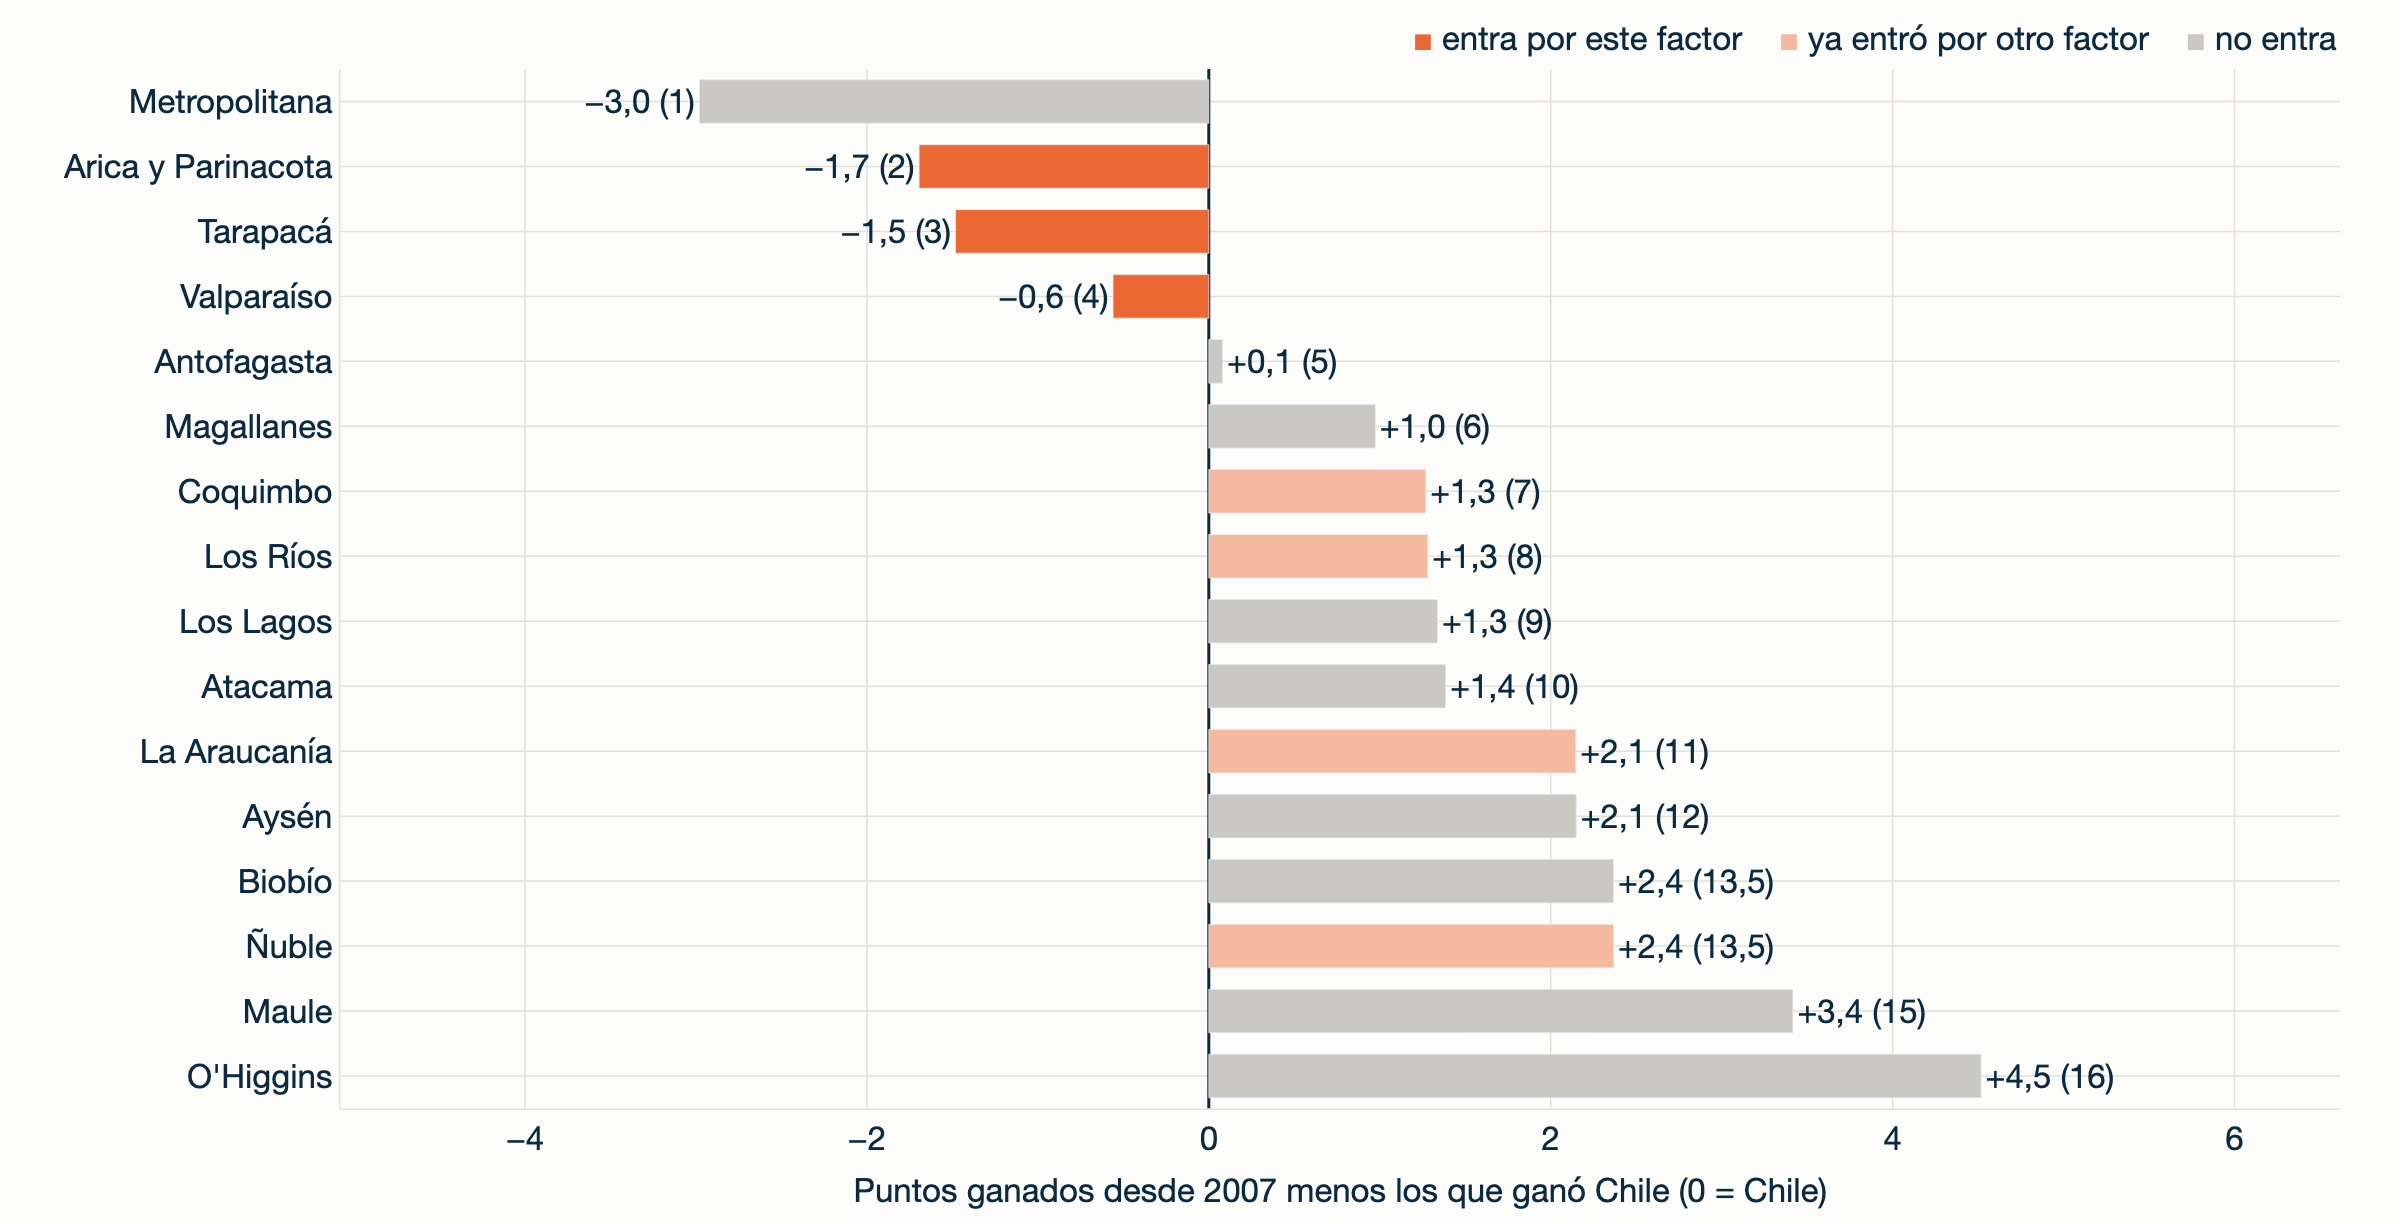

In [40]:
generar("1.1.9")

### Diapositiva 21: mapa de las 7 regiones críticas y qué falta en ellas (ocupados que no cotizan, fuera de la fuerza de trabajo, desocupados)

1.1.1    slide      → Outputs/figuras_notebook/1.1.1__mapa_cobertura__slide.png  (4800×2640 px)
N.5d     slide      → Outputs/figuras_notebook/N.5d__descomposicion_tres_etapas__slide.png  (4800×2640 px)


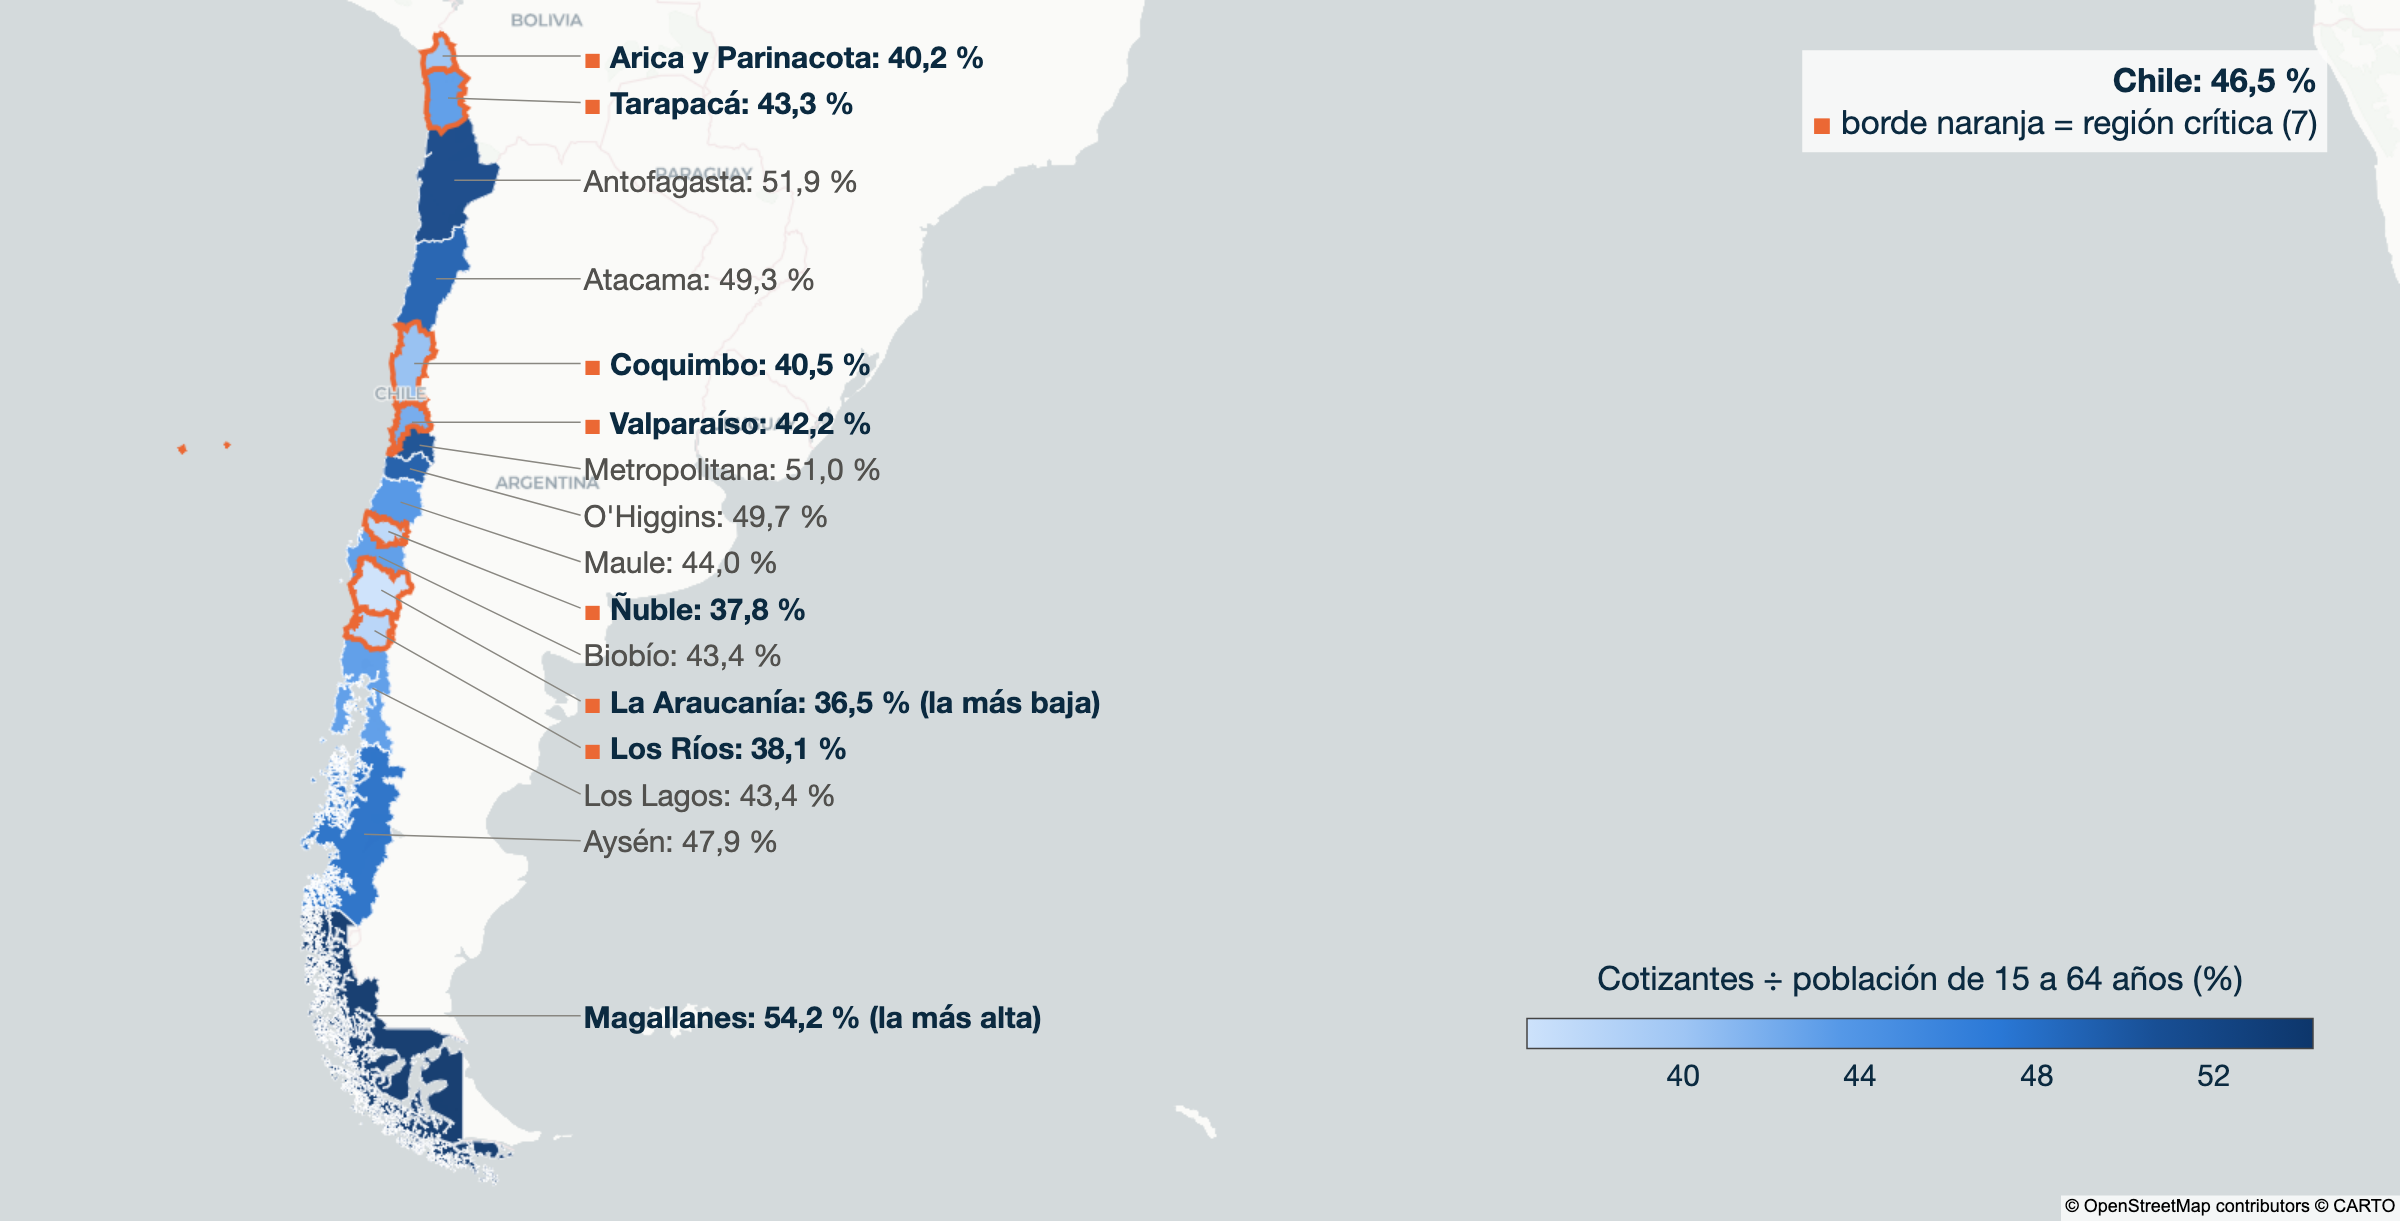

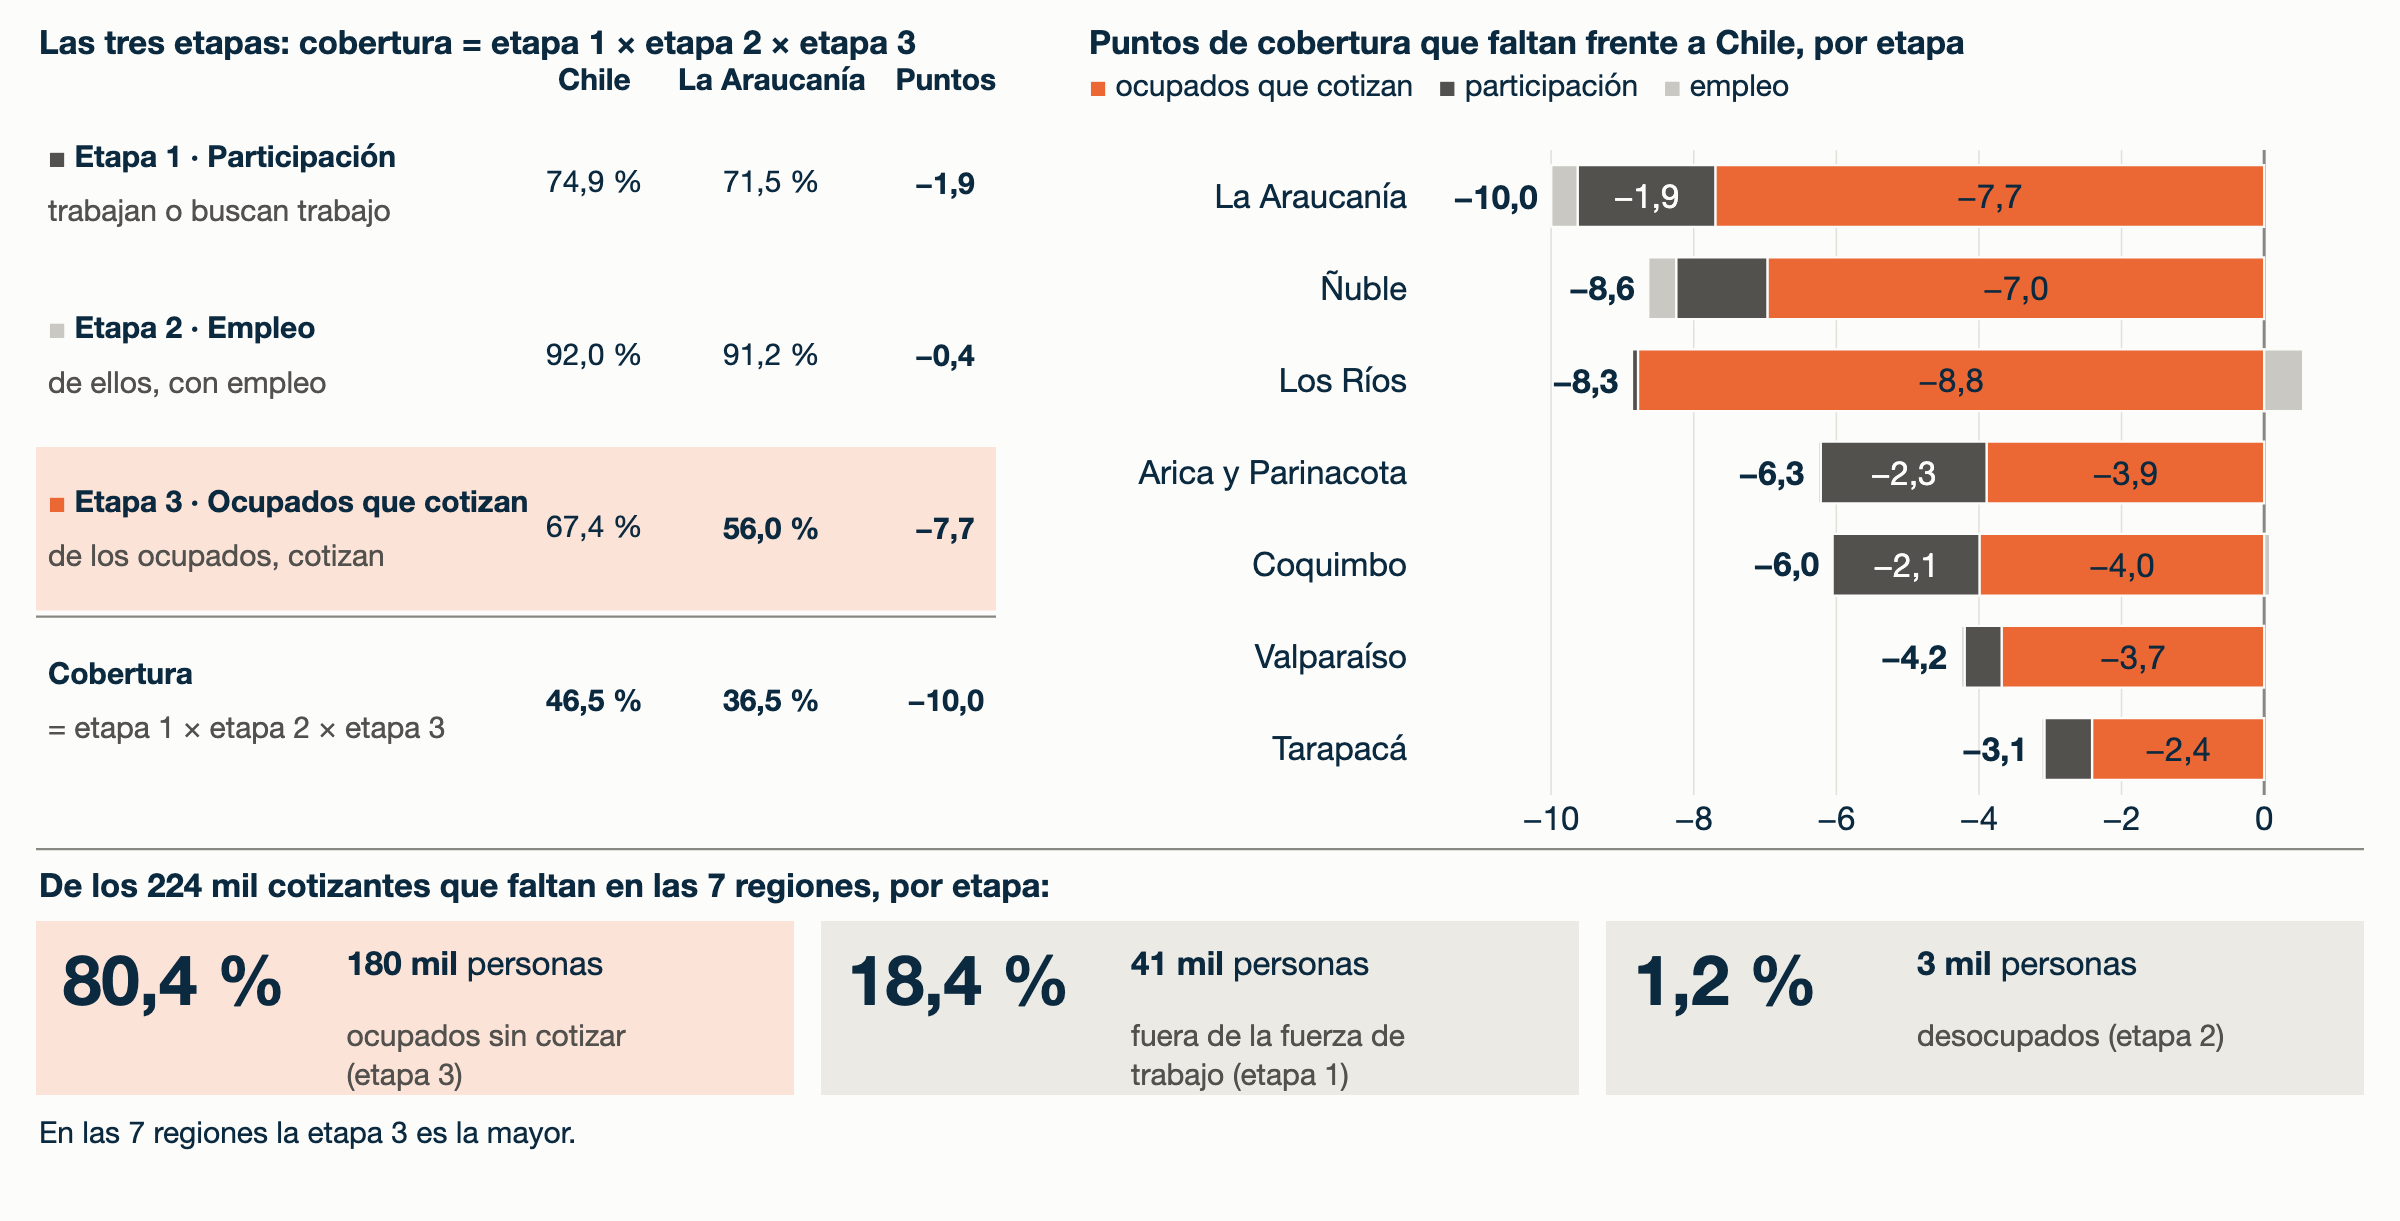

In [41]:
generar("1.1.1")
generar("N.5d")

### Diapositiva 22: de cada 100 personas de 15 a 64 años, cuántas cotizan y por qué el resto no

1.1.4    slide      → Outputs/figuras_notebook/1.1.4__composicion_chile__slide.png  (4800×2160 px)


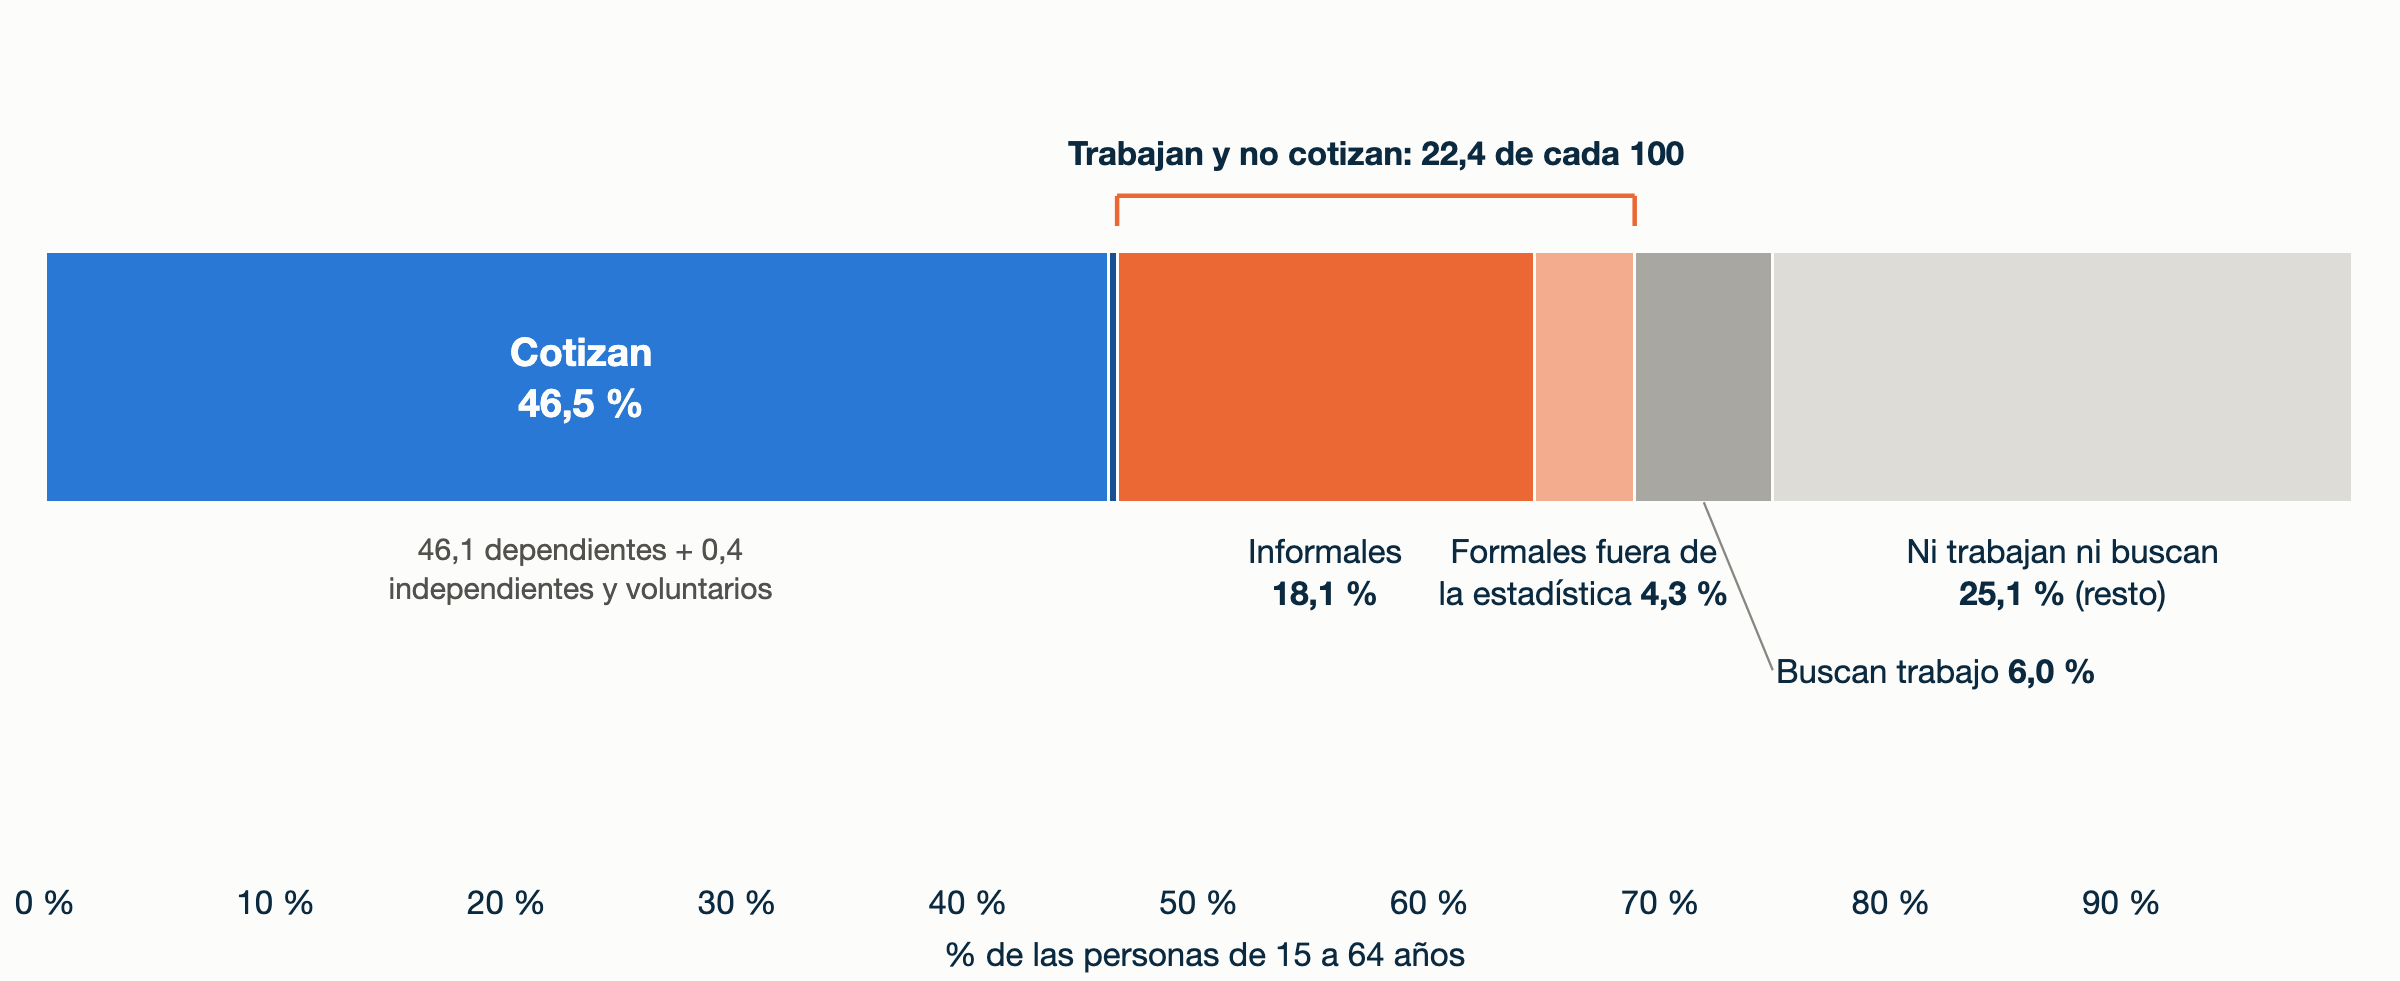

In [42]:
generar("1.1.4")

### Diapositiva 23: de dónde viene la diferencia con Chile en las 7 regiones (4 paneles)

1.1.25   slide      → Outputs/figuras_notebook/1.1.25__descomposicion_ocupados_que_cotizan__slide.png  (4800×2640 px)


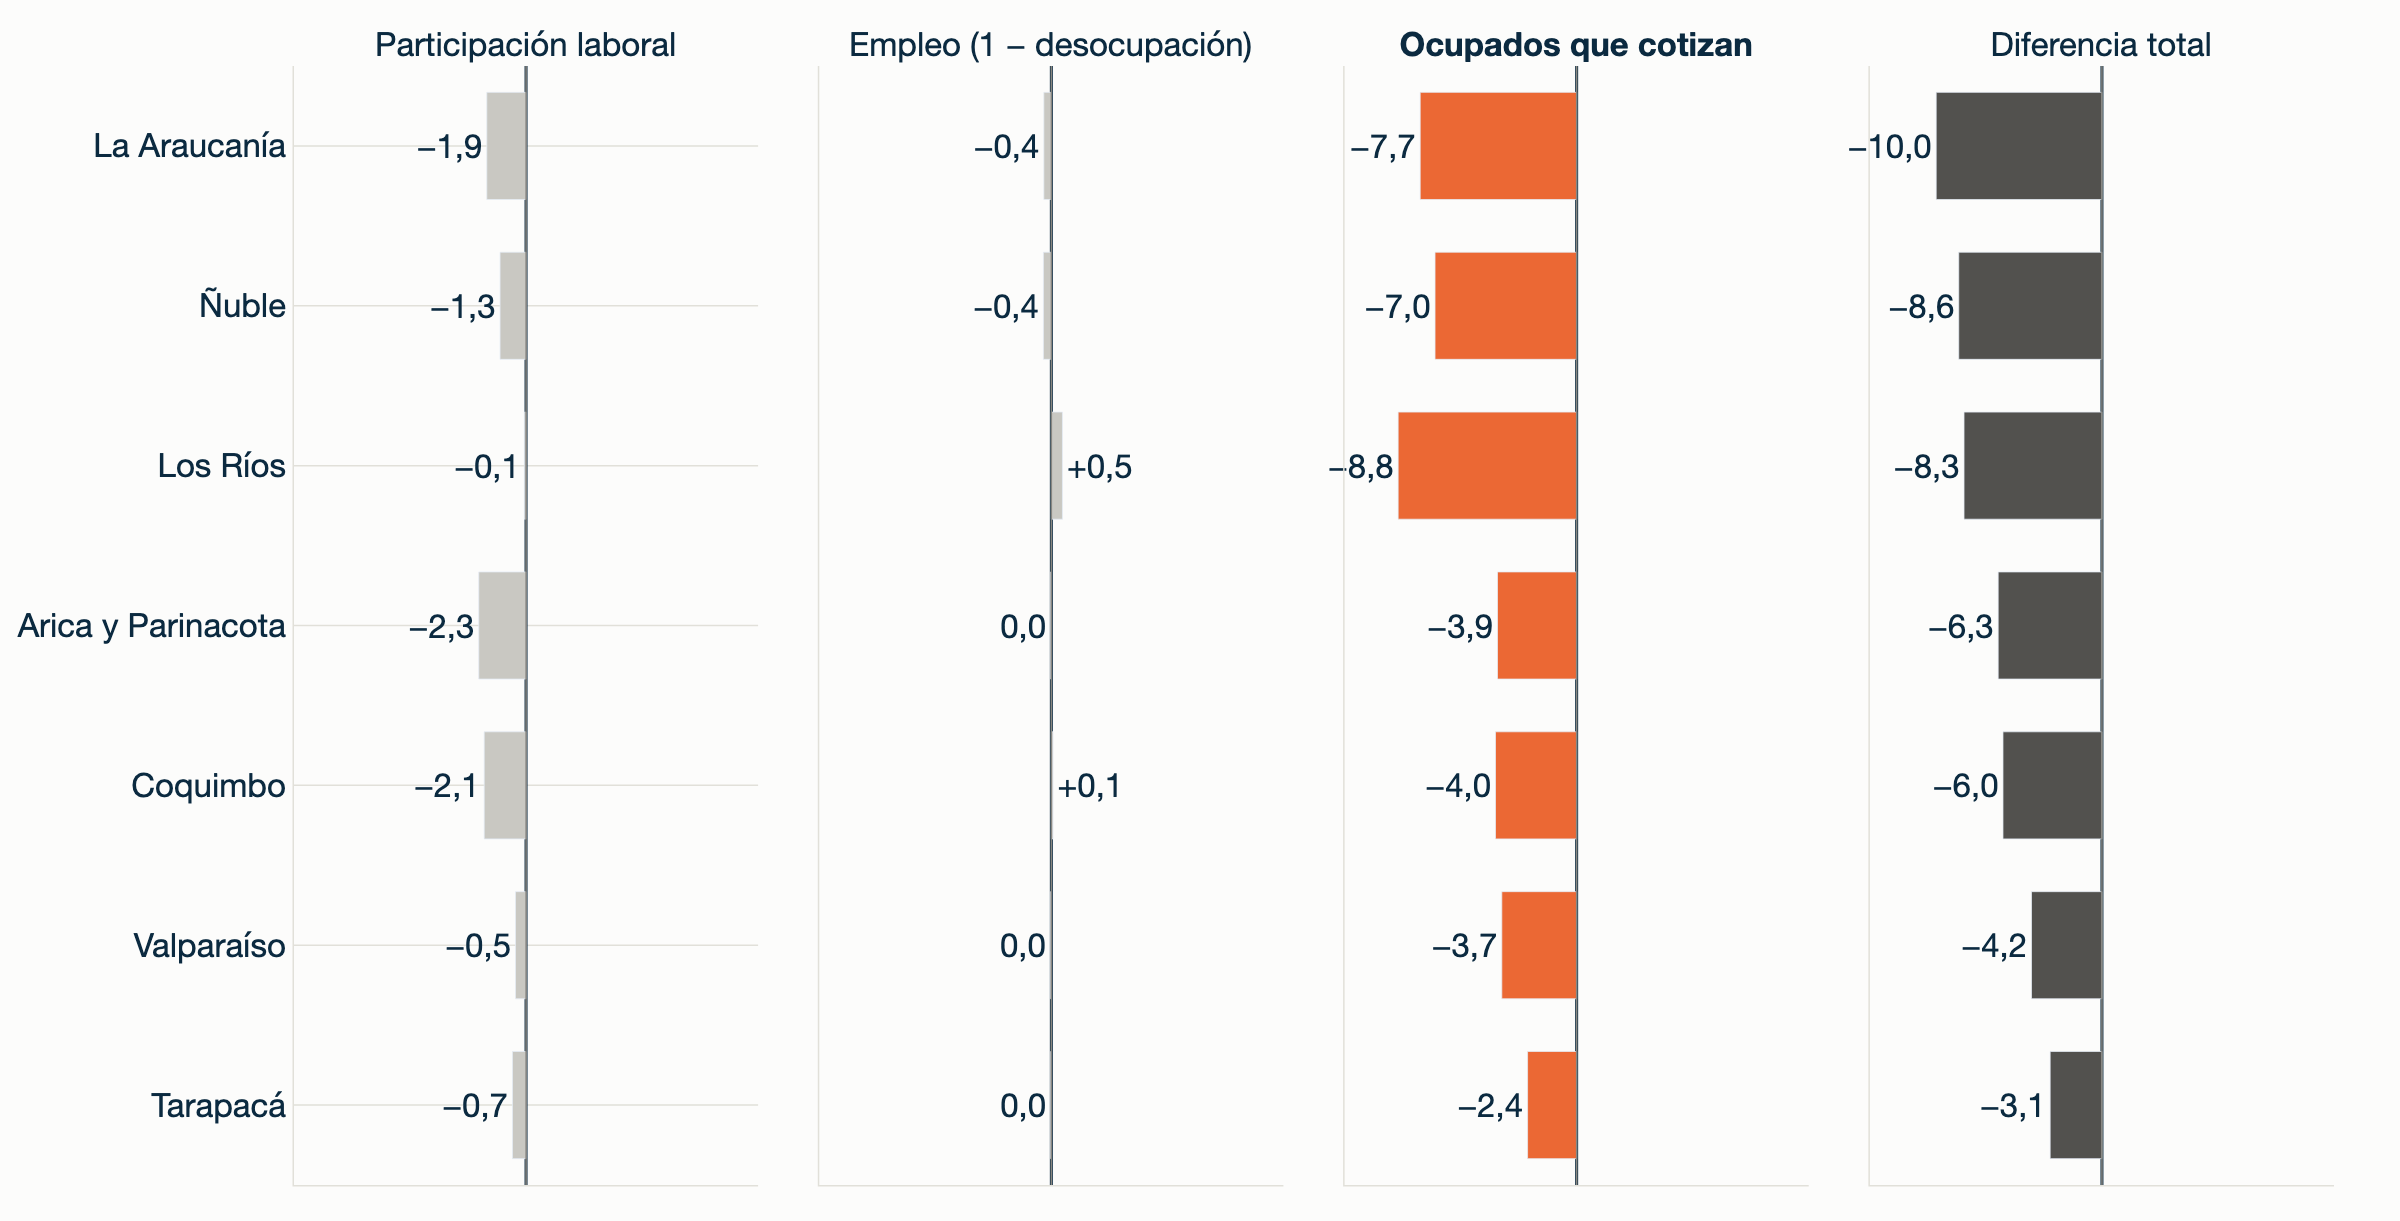

In [43]:
generar("1.1.25")

### Diapositiva 24: seis escenarios del punto crítico (tope 10, 11 y 12 %; cobertura que cae; mitad de los informales; todos)

1.2.10   slide      → Outputs/figuras_notebook/1.2.10__escenarios_seis_paneles__slide.png  (4800×2640 px)


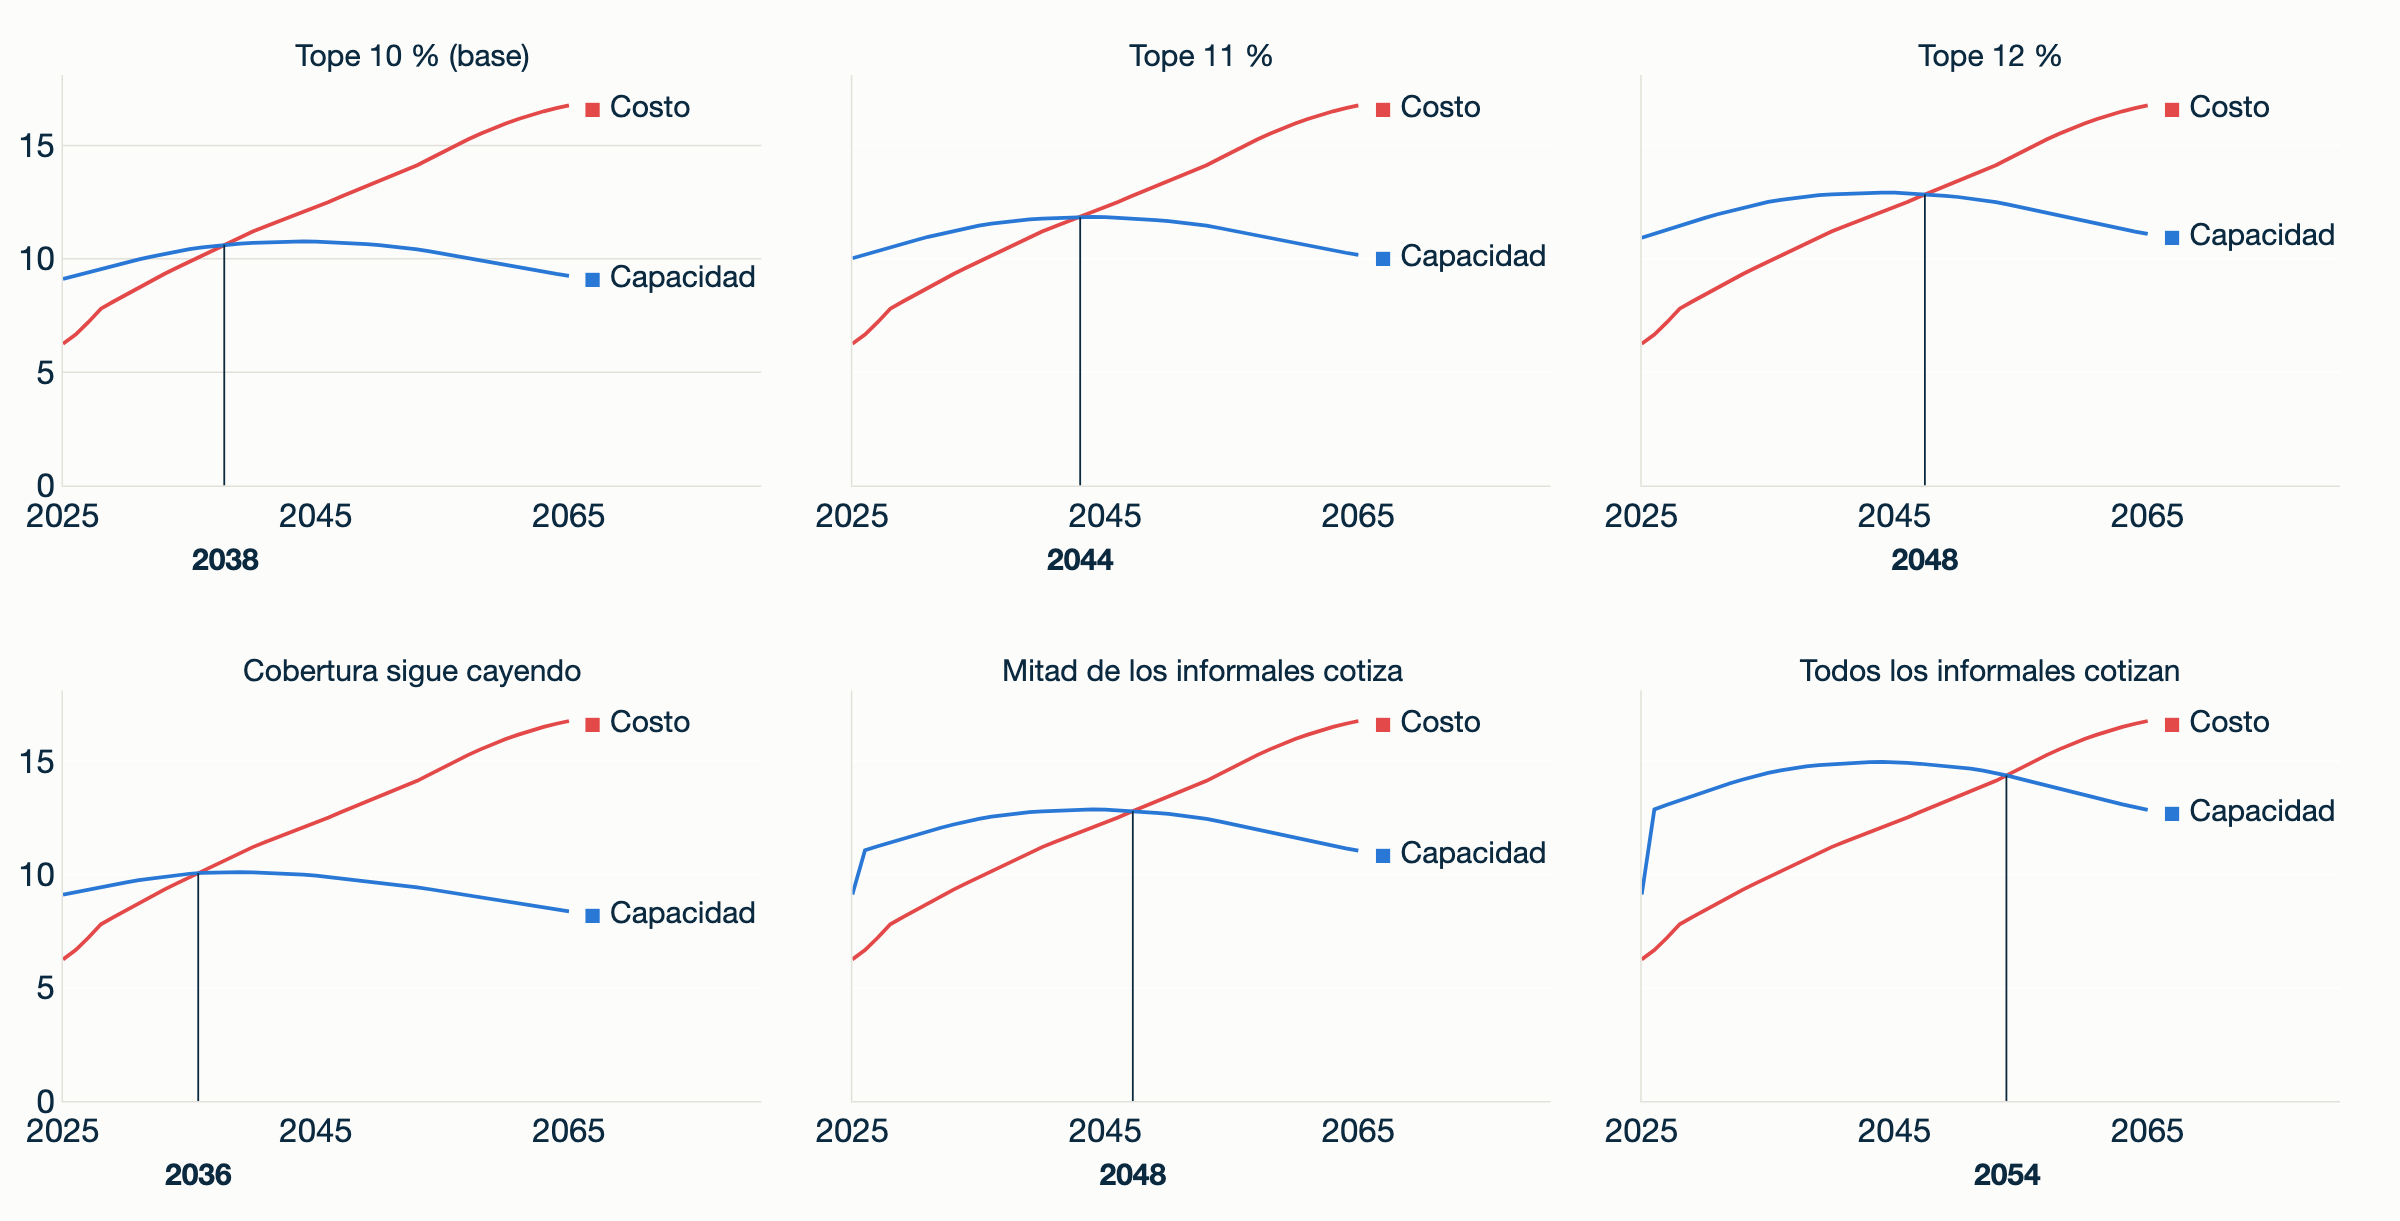

In [44]:
generar("1.2.10")

### Diapositiva 25: qué explica el alza de la carga entre 2024 y 2038 (cascada)

1.2.9    slide      → Outputs/figuras_notebook/1.2.9__carga_cascada__slide.png  (4800×2160 px)


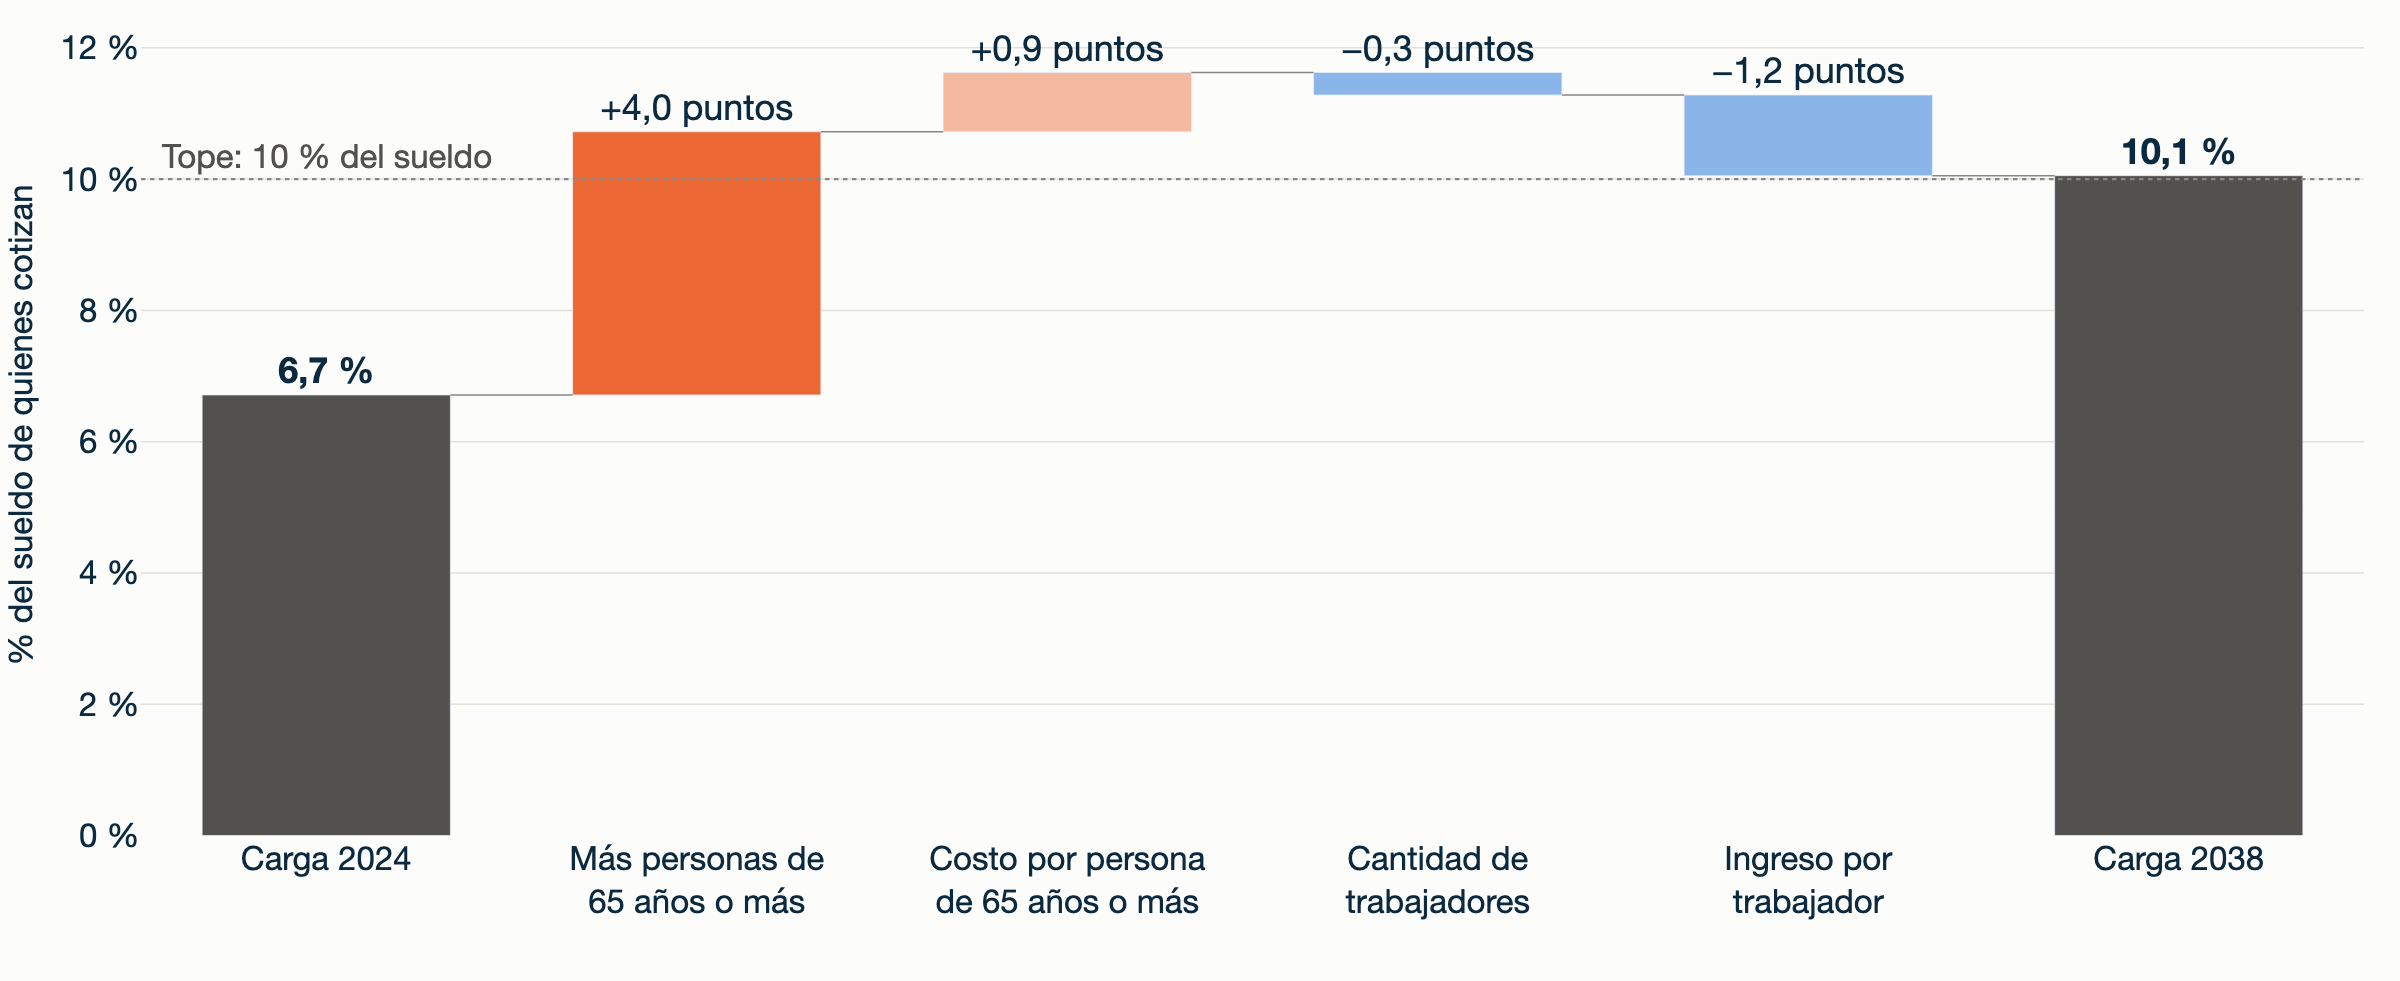

In [45]:
generar("1.2.9")

### Diapositiva 26: qué impulsa el costo del Pilar Solidario, 2016-2050

2.1.drivers slide      → Outputs/figuras_notebook/2.1.drivers__drivers_costo_pilar__slide.png  (4800×2160 px)


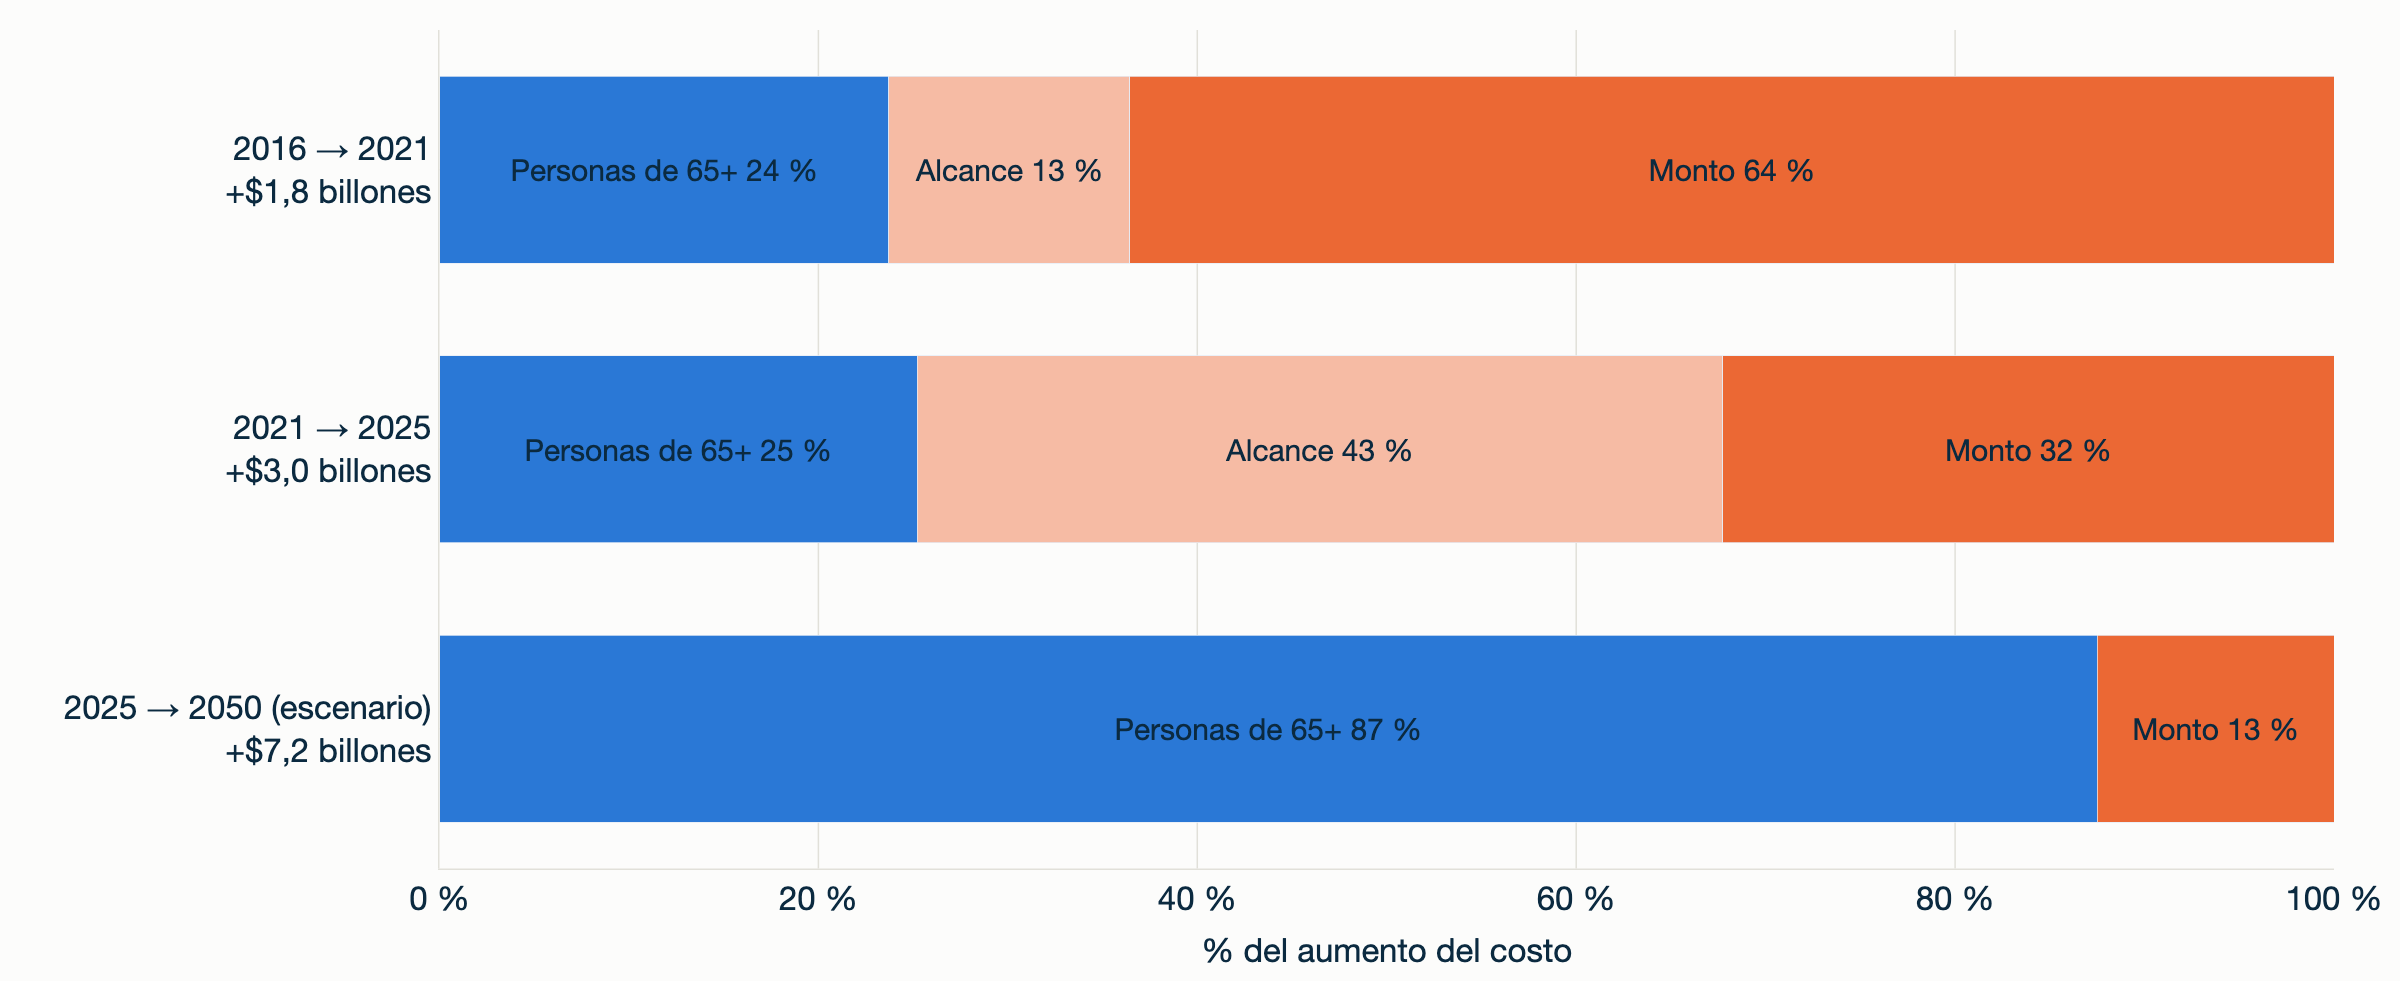

In [46]:
generar("2.1.drivers")

## 7. Verificación de las cifras de la presentación

In [47]:
def revisar(nombre, obtenido, esperado, tol=0.05):
    ok = abs(obtenido - esperado) <= tol
    print(("✓" if ok else "✗"), f"{nombre}: {obtenido:,.2f} (presentación: {esperado:,})")
    return ok


pico = proy.loc[proy.pob_15_64.idxmax()] if "pob_15_64" in proy else None
r = []
r.append(revisar("Punto crítico (año)", pc["anio"], 2038, 0))
r.append(revisar("Cobertura nacional 2024 (%)", nac_cobertura, 46.5, 0.05))
r.append(revisar("Cotizantes por persona de 65+ en 2024", float(d_pc[d_pc.anio == 2024].razon_soporte.iloc[0]), 2.27, 0.01))
r.append(revisar("Carga 2038 (%)", 100 * float(d_pc[d_pc.anio == 2038].carga_requerida.iloc[0]), 10.1, 0.1))
if pico is not None:
    r.append(revisar("Año del máximo de la población de 15 a 64", float(pico.anio), 2034, 0))
print("Todo coincide con la presentación." if all(r) else "Hay cifras que no coinciden: revisar los datos de «Data processed».")

✓ Punto crítico (año): 2,038.00 (presentación: 2,038)
✓ Cobertura nacional 2024 (%): 46.46 (presentación: 46.5)
✓ Cotizantes por persona de 65+ en 2024: 2.27 (presentación: 2.27)
✓ Carga 2038 (%): 10.05 (presentación: 10.1)
✓ Año del máximo de la población de 15 a 64: 2,034.00 (presentación: 2,034)
Todo coincide con la presentación.


## Anexo: de dónde sale cada archivo de «Data processed» que usan los gráficos
| Archivo | Paso de limpieza |
|---|---|
| `proyeccion_envejecimiento_pais.csv` | 02 |
| `censo_pais_edad_simple.csv`, `indicadores_region.csv` | 01 |
| `alemania_piramide_edad_simple_2024.csv` | 10 |
| `kpi_presion_previsional_region.csv` | 07 |
| `kpi_pc_nacional.csv`, `kpi_pc_parametros_reforma.csv` | 18 |
| `pgu_pbs_aps_nacional_anual.csv` | 12 |
| `gasto_proteccion_social.csv`, `macro_pib_anual.csv` | 13 |
| `kpi_cobertura_tendencia.csv`, `kpi_cobertura_regiones.csv` | 24 |
| `kpi_cobertura_descomposicion.csv`, `kpi_pc_escenarios_fijos.csv` | 25 |
| `kpi_cobertura_composicion.csv` | 29 |
| `kpi_seleccion_dos_preguntas.csv` | 35 |